# Setup

## Imports

In [1]:
print("hello")


hello


In [3]:
from pathlib import Path
import os
import pandas as pd
import sys
from matplotlib import pyplot as plt
import seaborn as sns
from adjustText import adjust_text
from matplotlib.patches import Patch
from matplotlib.ticker import LogLocator, NullFormatter
import numpy as np



import hatfield_funcs as hf

# project root = one level up from notebooks so maybe more here
project_root = Path("../..").resolve()
sys.path.insert(0, str(project_root / "src"))

from biofilm_spectra.processing.spectral_matrix import to_spectral_matrix

from biofilm_spectra.processing.micasense import *
from my_extra_to_hatfield_funcs.io_funcs import *

In [4]:
plt.style.use("default")
%config InlineBackend.figure_format = 'retina'

In [5]:
CONTAINER_NAME = "wesa-fup-restricted-027817p"

if os.getenv("GA_STORAGE_ACCOUNT_NAME") is not None:
    # this is what gets used when using Azure cloud storage (GeoAnalytics)
    hf.config.configure_azure()
    hf.config.configure_data_root_path(CONTAINER_NAME)
else:
    raise Exception(
        "This notebook is configured to run in the cloud. "
        "Please set up your Azure storage account and container name."
    )


## Parameters

In [6]:
SITES = ["brunswick", "westham"]
SITE_COLORS = {
    "brunswick": "#0455FE",
    "westham": "#56E00A",
}
SITE_LABELS = {
    "brunswick": "Impact Area",
    "westham": "Westham Control Area",
}
SITE_SHORTLABELS = {
    "brunswick": "IA",
    "westham": "WI",
}

PIGMENT_LIST = [
    "Peri",
    "Chlc2",
    "Fuco",
    "Ddx",
    "Allo",
    "Myxo",
    "Lut",
    "Zea",
    "Cant",
    "Chlb",
    "Chl_allo1",
    "Chl_allo2",
    "Chla",
    "DVCh-a",
    "Echi",
    "Phtb",
    "Phta",
    "Acar",
    "Beta",
]
FA_LIST = [
    "C6",
    "C8",
    "C10",
    "C11",
    "C12",
    "C13",
    "C14:0",  # Corrected from C14-0 to C14:0
    "C14:1",  # Corrected from C14-1 to C14:1
    "C15",
    "C15:1", # Corrected from C15-1 to C15:1
    "C16",
    "C16:1", # Corrected from C16-1 to C16:1
    "C17:0",
    "C17:1",
    "C18:0",
    "C18:1N9T",
    "C18:1N9C",
    "C18:2N6T",
    "C18:2N6C",
    "C20:0",
    "C18:3N6",
    "C20:1N9",
    "C18:3N3",
    "C21:0",
    "C20:2",
    "C22:0",
    "C20:3N6",
    "C22:1N9",
    "C20:3N3",
    "C23:0",
    "C20:4N6",
    "C22:2",
    "C24:0",
    "C20:5N3",
    "C24:1N9",
    "C22:6N3",
]

NORMALIZING_CHLA_COLUMN = "Chla + allomers"  #'Chla' #"Chla + DVCh-a + allomers" # Defined in the notebook to preprocess lab data

In [7]:
# Input paths
path_to_combined_dataset = Path("data/processed/full_dataset_combined_grouped.csv")


In [8]:
# Output path
path_output_dir = Path('./outputs/lab_data')
path_output_dir.mkdir(parents=True, exist_ok=True)

# Read data

In [9]:
df_combined_grouped = df_test = read_df_from_csv(
    path_to_combined_dataset,
    index_col=[0, 1, 2, 3],
    header=[0, 1, 2],
)

df_combined_grouped_R = df_combined_grouped.xs("R", level="sample_type")
df_combined_R = df_combined_grouped_R.copy()
df_combined_R.columns = df_combined_grouped_R.columns.get_level_values(2)

# Plot functions

In [10]:
"""Internal compound correlation heatmap with a cell-layout reference key."""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections.abc import Mapping, Sequence
from matplotlib import colors
from matplotlib.patches import Rectangle
from scipy import stats


def internal_correlation_heatmap(
    df,
    variable_labels=None,
    *,
    site_level="site",
    station_level="station_id",
    round_level="round",
    site_shortlabels=None,
    method="pearson",
    test="auto",
    pooled_inference="cluster_permutation",
    n_permutations=999,
    min_periods=10,
    p_adjust="fdr_bh",
    p_adjust_scope="global",
    alpha=0.05,
    triangle="upper",
    show_diagonal=False,
    annot="auto",
    annot_threshold=12,
    show_case_values=False,
    mini_height=0.28,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    figsize=None,
    title=None,
    show_reference_box=True,
    reference_box_title="Cell key",
    random_state=42,
):
    """
    Plot pooled and site-round correlations among selected dataframe columns.

    Each displayed cell contains a large pooled-correlation section and
    smaller sections for every observed site-round combination.

    `variable_labels` may be:
      * None;
      * a mapping from complete column keys or final-level names to labels;
      * a sequence matching dataframe column order.

    Returns
    -------
    fig, ax, correlation_df
        correlation_df contains one row per variable pair and analysis case.
    """

    # ------------------------------------------------------------------
    # Helpers
    # ------------------------------------------------------------------

    def bh_adjust(p_values):
        p = np.asarray(p_values, dtype=float)
        q = np.full(p.shape, np.nan)
        valid = np.isfinite(p)

        if not valid.any():
            return q

        values = p[valid]
        order = np.argsort(values)
        ranked = values[order]
        number_of_tests = len(ranked)

        adjusted = (
            ranked
            * number_of_tests
            / np.arange(1, number_of_tests + 1)
        )
        adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
        adjusted = np.clip(adjusted, 0, 1)

        restored = np.empty_like(adjusted)
        restored[order] = adjusted
        q[valid] = restored
        return q

    def correlation_statistic(x_values, y_values):
        x_values = np.asarray(x_values, dtype=float)
        y_values = np.asarray(y_values, dtype=float)

        valid = np.isfinite(x_values) & np.isfinite(y_values)
        x_values = x_values[valid]
        y_values = y_values[valid]

        if (
            len(x_values) < 2
            or np.ptp(x_values) == 0
            or np.ptp(y_values) == 0
        ):
            return np.nan

        if method == "pearson":
            return float(np.corrcoef(x_values, y_values)[0, 1])

        return float(
            np.corrcoef(
                stats.rankdata(x_values),
                stats.rankdata(y_values),
            )[0, 1]
        )

    def independent_test(x_values, y_values, requested_test):
        x_values = np.asarray(x_values, dtype=float)
        y_values = np.asarray(y_values, dtype=float)

        valid = np.isfinite(x_values) & np.isfinite(y_values)
        x_values = x_values[valid]
        y_values = y_values[valid]
        number_of_observations = len(x_values)

        if (
            number_of_observations < min_periods
            or np.ptp(x_values) == 0
            or np.ptp(y_values) == 0
        ):
            return np.nan, np.nan, number_of_observations

        if method == "pearson":
            coefficient, analytic_p_value = stats.pearsonr(
                x_values,
                y_values,
            )
        else:
            coefficient, analytic_p_value = stats.spearmanr(
                x_values,
                y_values,
            )

        coefficient = float(coefficient)

        use_permutation = (
            requested_test == "permutation"
            or (
                requested_test == "auto"
                and method == "spearman"
            )
        )

        if not use_permutation:
            return (
                coefficient,
                float(analytic_p_value),
                number_of_observations,
            )

        observed_absolute = abs(coefficient)
        exceedances = 0

        for _ in range(n_permutations):
            permuted_coefficient = correlation_statistic(
                x_values,
                rng.permutation(y_values),
            )

            if (
                np.isfinite(permuted_coefficient)
                and abs(permuted_coefficient) >= observed_absolute
            ):
                exceedances += 1

        p_value = (exceedances + 1) / (n_permutations + 1)

        return (
            coefficient,
            float(p_value),
            number_of_observations,
        )

    def cluster_permutation_test(pair_df):
        working = pair_df.copy()
        working.columns = ["_x", "_y"]
        working = working.reset_index()

        observed = working.dropna(subset=["_x", "_y"])
        number_of_observations = len(observed)

        if (
            number_of_observations < min_periods
            or observed["_x"].nunique() < 2
            or observed["_y"].nunique() < 2
        ):
            return np.nan, np.nan, number_of_observations

        coefficient = correlation_statistic(
            observed["_x"],
            observed["_y"],
        )

        y_lookup_frame = working.dropna(subset=["_y"])[
            [site_level, station_level, round_level, "_y"]
        ]

        key_columns = [site_level, station_level, round_level]

        if y_lookup_frame.duplicated(key_columns).any():
            raise ValueError(
                "Cluster permutation requires one row per "
                "site/station/round combination."
            )

        y_lookup = {
            (
                row[site_level],
                row[station_level],
                row[round_level],
            ): row["_y"]
            for _, row in y_lookup_frame.iterrows()
        }

        x_rows = working.dropna(subset=["_x"]).copy()

        site_to_stations = {
            site: np.asarray(
                pd.unique(site_frame[station_level]),
                dtype=object,
            )
            for site, site_frame in working.groupby(
                site_level,
                sort=False,
            )
        }

        observed_absolute = abs(coefficient)
        exceedances = 0
        valid_permutations = 0

        for _ in range(n_permutations):
            station_mappings = {}

            for site, stations in site_to_stations.items():
                if len(stations) < 2:
                    station_mappings[site] = dict(
                        zip(stations, stations)
                    )
                else:
                    station_mappings[site] = dict(
                        zip(stations, rng.permutation(stations))
                    )

            permuted_y = np.asarray(
                [
                    y_lookup.get(
                        (
                            row[site_level],
                            station_mappings[row[site_level]][
                                row[station_level]
                            ],
                            row[round_level],
                        ),
                        np.nan,
                    )
                    for _, row in x_rows.iterrows()
                ],
                dtype=float,
            )

            valid = np.isfinite(permuted_y)

            if valid.sum() < min_periods:
                continue

            permuted_coefficient = correlation_statistic(
                x_rows.loc[valid, "_x"],
                permuted_y[valid],
            )

            if np.isfinite(permuted_coefficient):
                valid_permutations += 1

                if abs(permuted_coefficient) >= observed_absolute:
                    exceedances += 1

        if valid_permutations == 0:
            return coefficient, np.nan, number_of_observations

        p_value = (
            (exceedances + 1)
            / (valid_permutations + 1)
        )

        return coefficient, float(p_value), number_of_observations

    def significance_symbol(q_value):
        if not np.isfinite(q_value):
            return ""
        if q_value < 0.001:
            return "***"
        if q_value < 0.01:
            return "**"
        if q_value < 0.05:
            return "*"
        return ""

    def resolve_labels(columns):
        """
        Preserve the original variable-label behavior:
          * None -> final column level;
          * mapping -> complete key, then exact final-level key;
          * sequence -> labels in dataframe column order.
        """
        columns = list(columns)

        if variable_labels is None:
            raw_labels = [
                column[-1] if isinstance(column, tuple) else column
                for column in columns
            ]

        elif isinstance(variable_labels, Mapping):
            raw_labels = []

            for column in columns:
                fallback = (
                    column[-1]
                    if isinstance(column, tuple)
                    else column
                )

                raw_labels.append(
                    variable_labels.get(
                        column,
                        variable_labels.get(fallback, fallback),
                    )
                )

        elif (
            isinstance(variable_labels, Sequence)
            and not isinstance(variable_labels, (str, bytes))
        ):
            if len(variable_labels) != len(columns):
                raise ValueError(
                    "variable_labels must have the same length "
                    "as df.columns."
                )

            raw_labels = list(variable_labels)

        else:
            raise TypeError(
                "variable_labels must be None, a mapping, "
                "or a sequence."
            )

        counts = {}
        unique_labels = []

        for raw_label in raw_labels:
            label = str(raw_label)
            counts[label] = counts.get(label, 0) + 1

            unique_labels.append(
                label
                if counts[label] == 1
                else f"{label} [{counts[label]}]"
            )

        return unique_labels

    # ------------------------------------------------------------------
    # Validation and preparation
    # ------------------------------------------------------------------

    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if not isinstance(df.index, pd.MultiIndex):
        raise TypeError("df.index must be a pandas MultiIndex.")

    required_levels = {
        site_level,
        station_level,
        round_level,
    }
    missing_levels = required_levels - set(df.index.names)

    if missing_levels:
        raise KeyError(
            f"Missing index levels: {sorted(missing_levels)}"
        )

    method = method.lower()

    if method not in {"pearson", "spearman"}:
        raise ValueError("method must be 'pearson' or 'spearman'.")

    if test not in {"auto", "analytic", "permutation"}:
        raise ValueError(
            "test must be 'auto', 'analytic', or 'permutation'."
        )

    if pooled_inference not in {
        "analytic",
        "cluster_permutation",
        "none",
    }:
        raise ValueError(
            "pooled_inference must be 'analytic', "
            "'cluster_permutation', or 'none'."
        )

    if p_adjust not in {"fdr_bh", "none"}:
        raise ValueError("p_adjust must be 'fdr_bh' or 'none'.")

    if p_adjust_scope not in {"global", "case"}:
        raise ValueError(
            "p_adjust_scope must be 'global' or 'case'."
        )

    triangle = triangle.lower()

    if triangle not in {"lower", "upper"}:
        raise ValueError("triangle must be 'lower' or 'upper'.")

    if not 0 < mini_height < 1:
        raise ValueError("mini_height must be between 0 and 1.")

    if site_shortlabels is None:
        site_shortlabels = globals().get(
            "SITE_SHORTLABELS",
            {
                "brunswick": "IA",
                "westham": "WI",
            },
        )
    else:
        site_shortlabels = dict(site_shortlabels)

    numeric_columns = [
        column
        for column in df.columns
        if pd.api.types.is_numeric_dtype(df[column])
    ]

    if len(numeric_columns) < 2:
        raise ValueError("At least two numeric columns are required.")

    selected = df.loc[:, numeric_columns].copy()
    original_columns = list(selected.columns)
    display_labels = resolve_labels(original_columns)

    column_to_label = dict(
        zip(original_columns, display_labels)
    )

    if isinstance(random_state, np.random.Generator):
        rng = random_state
    else:
        rng = np.random.default_rng(random_state)

    index_frame = selected.index.to_frame(index=False)

    cases_frame = index_frame[
        [site_level, round_level]
    ].drop_duplicates()

    case_order = [
        (row[site_level], row[round_level])
        for _, row in cases_frame.iterrows()
    ]

    case_short_labels = [
        (
            f"{site_shortlabels.get(site, str(site))}"
            f" - {round_value}"
        )
        for site, round_value in case_order
    ]

    # ------------------------------------------------------------------
    # Pairwise statistics
    # ------------------------------------------------------------------

    records = []
    number_of_variables = len(original_columns)

    for row_index in range(number_of_variables):
        for column_index in range(row_index):
            column_x = original_columns[row_index]
            column_y = original_columns[column_index]

            pair_df = selected.loc[
                :,
                [column_x, column_y],
            ].copy()

            if pooled_inference == "cluster_permutation":
                (
                    pooled_coefficient,
                    pooled_p_value,
                    pooled_n,
                ) = cluster_permutation_test(pair_df)

            elif pooled_inference == "analytic":
                (
                    pooled_coefficient,
                    pooled_p_value,
                    pooled_n,
                ) = independent_test(
                    pair_df.iloc[:, 0],
                    pair_df.iloc[:, 1],
                    "analytic",
                )

            else:
                (
                    pooled_coefficient,
                    _,
                    pooled_n,
                ) = independent_test(
                    pair_df.iloc[:, 0],
                    pair_df.iloc[:, 1],
                    "analytic",
                )
                pooled_p_value = np.nan

            records.append(
                {
                    "variable_x": column_to_label[column_x],
                    "variable_y": column_to_label[column_y],
                    "column_x": column_x,
                    "column_y": column_y,
                    "case": "pooled",
                    "site": None,
                    "round": None,
                    "method": method,
                    "coefficient": pooled_coefficient,
                    "n": pooled_n,
                    "p_value": pooled_p_value,
                }
            )

            for site, round_value in case_order:
                stratum = selected.xs(
                    (site, round_value),
                    level=(site_level, round_level),
                    drop_level=False,
                )

                (
                    coefficient,
                    p_value,
                    number_of_observations,
                ) = independent_test(
                    stratum[column_x],
                    stratum[column_y],
                    test,
                )

                records.append(
                    {
                        "variable_x": column_to_label[column_x],
                        "variable_y": column_to_label[column_y],
                        "column_x": column_x,
                        "column_y": column_y,
                        "case": f"{site} | round {round_value}",
                        "site": site,
                        "round": round_value,
                        "method": method,
                        "coefficient": coefficient,
                        "n": number_of_observations,
                        "p_value": p_value,
                    }
                )

    correlation_df = pd.DataFrame.from_records(records)

    # ------------------------------------------------------------------
    # Multiple-testing adjustment
    # ------------------------------------------------------------------

    if p_adjust == "none":
        correlation_df["q_value"] = correlation_df["p_value"]

    elif p_adjust_scope == "global":
        correlation_df["q_value"] = bh_adjust(
            correlation_df["p_value"]
        )

    else:
        correlation_df["q_value"] = np.nan

        for _, case_rows in correlation_df.groupby(
            "case",
            sort=False,
        ):
            correlation_df.loc[
                case_rows.index,
                "q_value",
            ] = bh_adjust(case_rows["p_value"])

    correlation_df["significance"] = (
        correlation_df["q_value"].map(significance_symbol)
    )

    correlation_df["significant"] = (
        correlation_df["q_value"].notna()
        & (correlation_df["q_value"] < alpha)
    )

    # ------------------------------------------------------------------
    # Internal matrices
    # ------------------------------------------------------------------

    case_keys = ["pooled"] + case_order
    matrices = {}

    for case_key in case_keys:
        coefficient_matrix = pd.DataFrame(
            np.eye(number_of_variables),
            index=display_labels,
            columns=display_labels,
        )

        q_matrix = pd.DataFrame(
            np.nan,
            index=display_labels,
            columns=display_labels,
        )

        if case_key == "pooled":
            case_rows = correlation_df[
                correlation_df["case"] == "pooled"
            ]
        else:
            site, round_value = case_key
            case_rows = correlation_df[
                (correlation_df["site"] == site)
                & (correlation_df["round"] == round_value)
            ]

        for _, row in case_rows.iterrows():
            x_label = row["variable_x"]
            y_label = row["variable_y"]

            coefficient_matrix.loc[x_label, y_label] = row[
                "coefficient"
            ]
            coefficient_matrix.loc[y_label, x_label] = row[
                "coefficient"
            ]
            q_matrix.loc[x_label, y_label] = row["q_value"]
            q_matrix.loc[y_label, x_label] = row["q_value"]

        matrices[case_key] = {
            "correlation": coefficient_matrix,
            "q_value": q_matrix,
        }

    # ------------------------------------------------------------------
    # Triangle layout
    # ------------------------------------------------------------------

    if show_diagonal:
        row_indices = list(range(number_of_variables))
        column_indices = list(range(number_of_variables))

    elif triangle == "lower":
        row_indices = list(range(1, number_of_variables))
        column_indices = list(range(number_of_variables - 1))

    else:
        row_indices = list(range(number_of_variables - 1))
        column_indices = list(range(1, number_of_variables))

    row_labels = [
        display_labels[index] for index in row_indices
    ]
    column_labels = [
        display_labels[index] for index in column_indices
    ]

    number_of_plot_rows = len(row_indices)
    number_of_plot_columns = len(column_indices)

    if figsize is None:
        figsize = (
            max(8, 0.78 * number_of_plot_columns) + 1.8,
            max(8, 0.78 * number_of_plot_rows),
        )

    # ------------------------------------------------------------------
    # Heatmap
    # ------------------------------------------------------------------

    fig, ax = plt.subplots(figsize=figsize)

    color_norm = colors.Normalize(vmin=vmin, vmax=vmax)
    color_map = plt.get_cmap(cmap)
    missing_color = "#E6E6E6"

    if annot == "auto":
        show_pooled_values = (
            number_of_variables <= annot_threshold
        )
    else:
        show_pooled_values = bool(annot)

    main_height = 1 - mini_height
    number_of_cases = len(case_order)

    for plot_row, original_row in enumerate(row_indices):
        for plot_column, original_column in enumerate(
            column_indices
        ):
            if triangle == "lower":
                valid_cell = (
                    original_column <= original_row
                    if show_diagonal
                    else original_column < original_row
                )
            else:
                valid_cell = (
                    original_column >= original_row
                    if show_diagonal
                    else original_column > original_row
                )

            if not valid_cell:
                continue

            y_label = display_labels[original_row]
            x_label = display_labels[original_column]

            pooled_value = matrices["pooled"][
                "correlation"
            ].loc[y_label, x_label]

            pooled_q_value = matrices["pooled"][
                "q_value"
            ].loc[y_label, x_label]

            pooled_color = (
                color_map(color_norm(pooled_value))
                if np.isfinite(pooled_value)
                else missing_color
            )

            ax.add_patch(
                Rectangle(
                    (plot_column, plot_row),
                    1,
                    main_height,
                    facecolor=pooled_color,
                    edgecolor="white",
                    linewidth=0.8,
                )
            )

            if (
                show_pooled_values
                and np.isfinite(pooled_value)
            ):
                pooled_text = f"{pooled_value:.2f}"

                if original_row != original_column:
                    pooled_text += significance_symbol(
                        pooled_q_value
                    )

                ax.text(
                    plot_column + 0.5,
                    plot_row + main_height / 2,
                    pooled_text,
                    ha="center",
                    va="center",
                    fontweight="bold",
                    fontsize=max(
                        6,
                        10 - 0.22 * number_of_variables,
                    ),
                    color=(
                        "white"
                        if abs(pooled_value) >= 0.55
                        else "black"
                    ),
                )

            if number_of_cases:
                mini_width = 1 / number_of_cases

                for case_index, case_key in enumerate(case_order):
                    case_value = matrices[case_key][
                        "correlation"
                    ].loc[y_label, x_label]

                    case_q_value = matrices[case_key][
                        "q_value"
                    ].loc[y_label, x_label]

                    case_color = (
                        color_map(color_norm(case_value))
                        if np.isfinite(case_value)
                        else missing_color
                    )

                    ax.add_patch(
                        Rectangle(
                            (
                                plot_column
                                + case_index * mini_width,
                                plot_row + main_height,
                            ),
                            mini_width,
                            mini_height,
                            facecolor=case_color,
                            edgecolor="white",
                            linewidth=0.55,
                        )
                    )

                    symbol = (
                        significance_symbol(case_q_value)
                        if original_row != original_column
                        else ""
                    )

                    if (
                        show_case_values
                        and np.isfinite(case_value)
                    ):
                        mini_text = f"{case_value:.2f}{symbol}"
                    else:
                        mini_text = symbol

                    if mini_text:
                        ax.text(
                            (
                                plot_column
                                + (case_index + 0.5)
                                * mini_width
                            ),
                            (
                                plot_row
                                + main_height
                                + mini_height / 2
                            ),
                            mini_text,
                            ha="center",
                            va="center",
                            fontsize=max(
                                4.5,
                                7.5
                                - 0.18
                                * number_of_variables,
                            ),
                            color=(
                                "white"
                                if abs(case_value) >= 0.55
                                else "black"
                            ),
                        )

            ax.add_patch(
                Rectangle(
                    (plot_column, plot_row),
                    1,
                    1,
                    fill=False,
                    edgecolor="white",
                    linewidth=0.9,
                    zorder=5,
                )
            )

    # ------------------------------------------------------------------
    # Axes and colorbar
    # ------------------------------------------------------------------

    ax.set_xlim(0, number_of_plot_columns)
    ax.set_ylim(number_of_plot_rows, 0)
    ax.set_aspect("equal")

    ax.set_xticks(
        np.arange(number_of_plot_columns) + 0.5
    )
    ax.set_yticks(
        np.arange(number_of_plot_rows) + 0.5
    )

    ax.set_xticklabels(
        column_labels,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
    )
    ax.set_yticklabels(row_labels)
    ax.tick_params(length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

    if title is None:
        title = (
            f"Internal {method.title()} correlation heatmap"
        )

    ax.set_title(
        title,
        pad=18,
        fontweight="bold",
    )

    scalar_mappable = plt.cm.ScalarMappable(
        norm=color_norm,
        cmap=color_map,
    )
    scalar_mappable.set_array([])

    colorbar = fig.colorbar(
        scalar_mappable,
        ax=ax,
        fraction=0.045,
        pad=0.035,
    )

    colorbar.set_label(
        "Pearson r"
        if method == "pearson"
        else "Spearman ρ"
    )

    # Reserve space for the reference key before adding its own axes.
    if show_reference_box:
        fig.tight_layout(rect=(0, 0.02, 0.80, 1))

        reference_ax = fig.add_axes(
            [0.82, 0.58, 0.16, 0.25]
        )
        reference_ax.set_xlim(0, 1)
        reference_ax.set_ylim(0, 1)
        reference_ax.axis("off")

        reference_ax.text(
            0.5,
            0.98,
            reference_box_title,
            ha="center",
            va="top",
            fontsize=10,
            fontweight="bold",
        )

        cell_x = 0.05
        cell_y = 0.16
        cell_width = 0.90
        cell_height = 0.64

        reference_mini_height = (
            cell_height * mini_height
        )
        reference_main_height = (
            cell_height - reference_mini_height
        )

        reference_ax.add_patch(
            Rectangle(
                (
                    cell_x,
                    cell_y + reference_mini_height,
                ),
                cell_width,
                reference_main_height,
                facecolor="#D9D9D9",
                edgecolor="black",
                linewidth=0.9,
            )
        )

        reference_ax.text(
            cell_x + cell_width / 2,
            (
                cell_y
                + reference_mini_height
                + reference_main_height / 2
            ),
            "Pooled",
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
        )

        if number_of_cases:
            reference_mini_width = (
                cell_width / number_of_cases
            )

            neutral_mini_colors = [
                "#F0F0F0",
                "#E3E3E3",
                "#D6D6D6",
                "#C9C9C9",
            ]

            for case_index, short_label in enumerate(
                case_short_labels
            ):
                mini_x = (
                    cell_x
                    + case_index * reference_mini_width
                )

                reference_ax.add_patch(
                    Rectangle(
                        (
                            mini_x,
                            cell_y,
                        ),
                        reference_mini_width,
                        reference_mini_height,
                        facecolor=neutral_mini_colors[
                            case_index
                            % len(neutral_mini_colors)
                        ],
                        edgecolor="black",
                        linewidth=0.7,
                    )
                )

                reference_ax.text(
                    mini_x + reference_mini_width / 2,
                    cell_y + reference_mini_height / 2,
                    short_label,
                    ha="center",
                    va="center",
                    fontsize=max(
                        5.5,
                        8 - 0.35 * number_of_cases,
                    ),
                )

        reference_ax.text(
            0.5,
            0.06,
            "Stars indicate FDR-adjusted significance",
            ha="center",
            va="bottom",
            fontsize=6.5,
            wrap=True,
        )

    else:
        fig.tight_layout(rect=(0, 0.02, 1, 1))

    # ------------------------------------------------------------------
    # Return table
    # ------------------------------------------------------------------

    correlation_df = correlation_df[
        [
            "variable_x",
            "variable_y",
            "column_x",
            "column_y",
            "case",
            "site",
            "round",
            "method",
            "coefficient",
            "n",
            "p_value",
            "q_value",
            "significance",
            "significant",
        ]
    ].reset_index(drop=True)

    return fig, ax, correlation_df


In [11]:
"""Site-by-round scatterplot grid with local and reference linear fits."""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from scipy import stats


def scatterplot_site_round_grid(
    df,
    x,
    y,
    *,
    site_level="site",
    round_level="round",
    site_order=("westham", "brunswick"),
    round_order=(1, 2),
    site_colors=None,
    site_labels=None,
    x_label=None,
    y_label=None,
    title=None,
    confidence_level=0.95,
    reference_fit="global",
    show_background_points=True,
    background_color="0.75",
    background_alpha=0.5,
    background_point_size=None,
    show_local_ci=True,
    show_reference_ci=True,
    show_statistics=True,
    min_periods=3,
    point_size=44,
    point_alpha=0.78,
    local_line_width=2,
    reference_line_width=1,
    local_ci_alpha=0.3,
    reference_ci_alpha=0.2,
    reference_color="black",
    extend_fits_to_xlim=True,
    xlim=None,
    ylim=None,
    x_padding_fraction=0.05,
    grid=True,
    figsize=(13, 10),
):
    """
    Plot a site-by-round grid of scatterplots and linear fits.

    Rows represent sites and columns represent rounds. By default, Westham
    is the top row, Brunswick is the bottom row, Round 1 is the left column,
    and Round 2 is the right column.

    Every panel contains:
      * all observations in the background in light gray;
      * highlighted observations for that site-round combination;
      * a local site-round linear fit and mean-response confidence band;
      * a reference fit and confidence band.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataframe containing x and y. Its index must include site and round.
    x, y : hashable
        Ordinary column names or complete MultiIndex column tuples.
    site_order, round_order : sequence
        Row and column ordering.
    site_colors, site_labels : mapping, optional
        Site colors and display labels.
    confidence_level : float
        Confidence level for mean-response confidence bands.
    reference_fit : {"global", "round"}
        "global" repeats one fit calculated from every observation.
        "round" uses a fit pooling sites within each panel's round.
    show_background_points : bool, default True
        Show all pairwise-complete observations in every panel.
    background_color : Matplotlib color
        Color used for the background observations.
    background_alpha : float
        Transparency of the background observations.
    background_point_size : float, optional
        Background point size. Defaults to 70% of ``point_size``.
    extend_fits_to_xlim : bool
        Extend local and reference fits over the common x-axis range.
    xlim, ylim : two-element sequence, optional
        Explicit common limits for every subplot.

    Returns
    -------
    fig : matplotlib.figure.Figure
    axes : numpy.ndarray
        Two-dimensional axes array indexed by site row and round column.
    fit_statistics : pandas.DataFrame
        Regression statistics for the reference and local fits.
    """

    def display_column_name(column):
        return str(column[-1]) if isinstance(column, tuple) else str(column)

    def format_p_text(value):
        if not np.isfinite(value):
            return "p=NA"
        if value < 0.001:
            return "p<0.001"
        return f"p={value:.3f}"

    def format_legend_label(base_label, result):
        if not show_statistics:
            return base_label
        if not np.isfinite(result["r_squared"]):
            return f"{base_label}\n(insufficient data, n={result['n']})"
        return (
            f"{base_label}\n"
            f"(R²={result['r_squared']:.3f}, "
            f"{format_p_text(result['p_value'])}, n={result['n']})"
        )

    def calculate_fit(
        data,
        *,
        scope,
        label,
        site=None,
        round_value=None,
        fit_xlim=None,
    ):
        pair = data.loc[:, [x, y]].copy()
        pair.columns = ["_x", "_y"]
        pair = pair.apply(pd.to_numeric, errors="coerce").dropna()
        n = len(pair)

        result = {
            "scope": scope,
            "site": site,
            "round": round_value,
            "label": label,
            "n": n,
            "slope": np.nan,
            "intercept": np.nan,
            "r": np.nan,
            "r_squared": np.nan,
            "p_value": np.nan,
            "slope_standard_error": np.nan,
            "residual_standard_error": np.nan,
            "confidence_level": confidence_level,
            "observed_x_min": np.nan,
            "observed_x_max": np.nan,
            "fit_x_min": np.nan,
            "fit_x_max": np.nan,
        }

        if (
            n < min_periods
            or pair["_x"].nunique() < 2
            or pair["_y"].nunique() < 2
        ):
            return result, None

        x_values = pair["_x"].to_numpy(dtype=float)
        y_values = pair["_y"].to_numpy(dtype=float)

        regression = stats.linregress(x_values, y_values)

        slope = float(regression.slope)
        intercept = float(regression.intercept)
        r_value = float(regression.rvalue)
        p_value = float(regression.pvalue)
        slope_standard_error = float(regression.stderr)

        fitted_observations = intercept + slope * x_values
        residuals = y_values - fitted_observations
        degrees_of_freedom = n - 2

        residual_standard_error = (
            float(np.sqrt(np.sum(residuals**2) / degrees_of_freedom))
            if degrees_of_freedom > 0
            else np.nan
        )

        observed_x_min = float(np.min(x_values))
        observed_x_max = float(np.max(x_values))

        if fit_xlim is None:
            fit_x_min = observed_x_min
            fit_x_max = observed_x_max
        else:
            fit_x_min, fit_x_max = map(float, fit_xlim)

        x_grid = np.linspace(fit_x_min, fit_x_max, 250)
        fitted_grid = intercept + slope * x_grid

        x_mean = np.mean(x_values)
        sxx = np.sum((x_values - x_mean) ** 2)

        if (
            degrees_of_freedom > 0
            and sxx > 0
            and np.isfinite(residual_standard_error)
        ):
            alpha = 1 - confidence_level
            t_critical = stats.t.ppf(
                1 - alpha / 2,
                degrees_of_freedom,
            )

            mean_fit_standard_error = (
                residual_standard_error
                * np.sqrt(
                    1 / n
                    + (x_grid - x_mean) ** 2 / sxx
                )
            )

            ci_lower = (
                fitted_grid
                - t_critical * mean_fit_standard_error
            )
            ci_upper = (
                fitted_grid
                + t_critical * mean_fit_standard_error
            )
        else:
            ci_lower = np.full_like(x_grid, np.nan)
            ci_upper = np.full_like(x_grid, np.nan)

        result.update(
            {
                "slope": slope,
                "intercept": intercept,
                "r": r_value,
                "r_squared": r_value**2,
                "p_value": p_value,
                "slope_standard_error": slope_standard_error,
                "residual_standard_error": residual_standard_error,
                "observed_x_min": observed_x_min,
                "observed_x_max": observed_x_max,
                "fit_x_min": fit_x_min,
                "fit_x_max": fit_x_max,
            }
        )

        plot_values = {
            "x_grid": x_grid,
            "fitted": fitted_grid,
            "ci_lower": ci_lower,
            "ci_upper": ci_upper,
        }

        return result, plot_values

    # --------------------------------------------------------------
    # Validate and prepare data
    # --------------------------------------------------------------
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")
    if x not in df.columns:
        raise KeyError(f"x variable {x!r} was not found in df.columns.")
    if y not in df.columns:
        raise KeyError(f"y variable {y!r} was not found in df.columns.")
    if not isinstance(df.index, pd.MultiIndex):
        raise TypeError("df.index must be a pandas MultiIndex.")

    required_levels = {site_level, round_level}
    missing_levels = required_levels - set(df.index.names)
    if missing_levels:
        raise KeyError(f"Missing index levels: {sorted(missing_levels)}")

    if reference_fit not in {"global", "round"}:
        raise ValueError("reference_fit must be 'global' or 'round'.")
    if not 0 < confidence_level < 1:
        raise ValueError("confidence_level must be between 0 and 1.")
    if x_padding_fraction < 0:
        raise ValueError("x_padding_fraction cannot be negative.")
    if not 0 <= background_alpha <= 1:
        raise ValueError("background_alpha must be between 0 and 1.")

    if background_point_size is None:
        background_point_size = 0.70 * point_size

    site_order = list(site_order)
    round_order = list(round_order)

    available_sites = set(df.index.get_level_values(site_level))
    available_rounds = set(df.index.get_level_values(round_level))

    missing_sites = [
        site for site in site_order if site not in available_sites
    ]
    missing_rounds = [
        round_value
        for round_value in round_order
        if round_value not in available_rounds
    ]

    if missing_sites:
        raise KeyError(f"Site(s) not found: {missing_sites}")
    if missing_rounds:
        raise KeyError(f"Round(s) not found: {missing_rounds}")

    working = df.loc[:, [x, y]].copy()
    working.columns = ["_x", "_y"]
    working = working.apply(pd.to_numeric, errors="coerce")

    metadata = df.index.to_frame(index=False)
    working = working.reset_index(drop=True)
    working[site_level] = metadata[site_level].to_numpy()
    working[round_level] = metadata[round_level].to_numpy()

    valid_overall = working.dropna(subset=["_x", "_y"])
    if valid_overall.empty:
        raise ValueError("No pairwise-complete observations were found.")

    # --------------------------------------------------------------
    # Common axis and fit range
    # --------------------------------------------------------------
    if xlim is not None:
        if len(xlim) != 2 or xlim[0] >= xlim[1]:
            raise ValueError("xlim must be an increasing two-element sequence.")
        display_xlim = tuple(map(float, xlim))
    else:
        overall_x_min = float(valid_overall["_x"].min())
        overall_x_max = float(valid_overall["_x"].max())
        x_range = overall_x_max - overall_x_min
        padding = (
            x_padding_fraction * x_range
            if x_range > 0
            else 1.0
        )
        display_xlim = (
            overall_x_min - padding,
            overall_x_max + padding,
        )

    fit_xlim = (
        display_xlim
        if extend_fits_to_xlim
        else None
    )

    if ylim is not None:
        if len(ylim) != 2 or ylim[0] >= ylim[1]:
            raise ValueError("ylim must be an increasing two-element sequence.")
        display_ylim = tuple(map(float, ylim))
    else:
        display_ylim = None

    # --------------------------------------------------------------
    # Site styles
    # --------------------------------------------------------------
    if site_colors is None:
        palette = plt.get_cmap("tab10")
        site_colors = {
            site: palette(index % 10)
            for index, site in enumerate(site_order)
        }
    else:
        site_colors = dict(site_colors)

    missing_site_colors = [
        site for site in site_order if site not in site_colors
    ]
    if missing_site_colors:
        raise KeyError(
            f"No color was provided for site(s): {missing_site_colors}"
        )

    if site_labels is None:
        site_labels = {
            site: str(site)
            for site in site_order
        }
    else:
        site_labels = {
            site: site_labels.get(site, str(site))
            for site in site_order
        }

    # --------------------------------------------------------------
    # Calculate reference fits
    # --------------------------------------------------------------
    fit_records = []
    reference_results = {}
    reference_plot_values = {}

    if reference_fit == "global":
        result, plot_values = calculate_fit(
            df.loc[:, [x, y]],
            scope="global-reference",
            label="Overall reference",
            fit_xlim=fit_xlim,
        )

        fit_records.append(result)

        for round_value in round_order:
            reference_results[round_value] = result
            reference_plot_values[round_value] = plot_values

    else:
        for round_value in round_order:
            round_mask = (
                df.index.get_level_values(round_level)
                == round_value
            )
            round_data = df.loc[round_mask, [x, y]]

            result, plot_values = calculate_fit(
                round_data,
                scope="round-reference",
                label=f"Overall, Round {round_value}",
                round_value=round_value,
                fit_xlim=fit_xlim,
            )

            fit_records.append(result)
            reference_results[round_value] = result
            reference_plot_values[round_value] = plot_values

    # --------------------------------------------------------------
    # Create site-by-round grid
    # --------------------------------------------------------------
    fig, axes = plt.subplots(
        nrows=len(site_order),
        ncols=len(round_order),
        figsize=figsize,
        sharex=True,
        sharey=True,
        squeeze=False,
    )

    for row_index, site in enumerate(site_order):
        for column_index, round_value in enumerate(round_order):
            axis = axes[row_index, column_index]

            panel_mask = (
                (
                    df.index.get_level_values(site_level)
                    == site
                )
                & (
                    df.index.get_level_values(round_level)
                    == round_value
                )
            )

            panel_data = df.loc[panel_mask, [x, y]]

            plot_data = panel_data.copy()
            plot_data.columns = ["_x", "_y"]
            plot_data = (
                plot_data
                .apply(pd.to_numeric, errors="coerce")
                .dropna()
            )

            local_result, local_plot_values = calculate_fit(
                panel_data,
                scope="site-round",
                label=f"{site_labels[site]}, Round {round_value}",
                site=site,
                round_value=round_value,
                fit_xlim=fit_xlim,
            )

            fit_records.append(local_result)

            color = site_colors[site]

            # Show the complete dataset as contextual background in every
            # site-round panel. The selected observations are then overlaid.
            if show_background_points:
                axis.scatter(
                    valid_overall["_x"],
                    valid_overall["_y"],
                    s=background_point_size,
                    alpha=background_alpha,
                    color=background_color,
                    marker="o",
                    edgecolor="none",
                    linewidth=0,
                    zorder=0,
                )

            axis.scatter(
                plot_data["_x"],
                plot_data["_y"],
                s=point_size,
                alpha=point_alpha,
                color=color,
                marker="o",
                edgecolor="white",
                linewidth=0.6,
                zorder=3,
            )

            if local_plot_values is not None:
                if show_local_ci:
                    axis.fill_between(
                        local_plot_values["x_grid"],
                        local_plot_values["ci_lower"],
                        local_plot_values["ci_upper"],
                        color=color,
                        alpha=local_ci_alpha,
                        linewidth=0,
                        zorder=1,
                    )

                axis.plot(
                    local_plot_values["x_grid"],
                    local_plot_values["fitted"],
                    color=color,
                    linestyle="-",
                    linewidth=local_line_width,
                    zorder=4,
                )

            reference_result = reference_results[round_value]
            reference_values = reference_plot_values[round_value]

            if reference_values is not None:
                if show_reference_ci:
                    axis.fill_between(
                        reference_values["x_grid"],
                        reference_values["ci_lower"],
                        reference_values["ci_upper"],
                        color=reference_color,
                        alpha=reference_ci_alpha,
                        linewidth=0,
                        zorder=2,
                    )

                axis.plot(
                    reference_values["x_grid"],
                    reference_values["fitted"],
                    color=reference_color,
                    linestyle="--",
                    linewidth=reference_line_width,
                    zorder=5,
                )

            local_legend_label = format_legend_label(
                site_labels[site],
                local_result,
            )

            reference_base_label = (
                "Overall reference"
                if reference_fit == "global"
                else f"Round {round_value} overall"
            )

            reference_legend_label = format_legend_label(
                reference_base_label,
                reference_result,
            )

            legend_handles = []

            if show_background_points:
                legend_handles.append(
                    Line2D(
                        [0],
                        [0],
                        color=background_color,
                        marker="o",
                        linestyle="None",
                        markersize=6,
                        markeredgecolor="none",
                        alpha=background_alpha,
                        label="All observations",
                    )
                )

            legend_handles.extend([
                Line2D(
                    [0],
                    [0],
                    color=color,
                    marker="o",
                    linestyle="-",
                    linewidth=local_line_width,
                    markersize=7,
                    markeredgecolor="white",
                    label=local_legend_label,
                ),
                Line2D(
                    [0],
                    [0],
                    color=reference_color,
                    linestyle="--",
                    linewidth=reference_line_width,
                    label=reference_legend_label,
                ),
            ])

            axis.legend(
                handles=legend_handles,
                loc="best",
                frameon=True,
                labelspacing=1.0,
            )

            axis.set_title(
                f"{site_labels[site]} — Round {round_value}",
                fontweight="bold",
                pad=10,
            )

            axis.set_xlim(display_xlim)
            if display_ylim is not None:
                axis.set_ylim(display_ylim)

            if grid:
                axis.grid(
                    visible=True,
                    axis="both",
                    linestyle="--",
                    linewidth=0.7,
                    color="0.75",
                    alpha=0.6,
                )
                axis.set_axisbelow(True)

    # --------------------------------------------------------------
    # Common labels and return table
    # --------------------------------------------------------------
    if x_label is None:
        x_label = display_column_name(x)
    if y_label is None:
        y_label = display_column_name(y)
    if title is None:
        title = f"{y_label} versus {x_label}, by site and round"

    fig.suptitle(
        title,
        fontweight="bold",
        fontsize=14,
        y=0.995,
    )
    fig.supxlabel(x_label)
    fig.supylabel(y_label)

    fig.tight_layout(
        rect=(0.035, 0.035, 1, 0.965)
    )

    fit_statistics = pd.DataFrame.from_records(fit_records)
    fit_statistics = fit_statistics[
        [
            "scope",
            "site",
            "round",
            "label",
            "n",
            "slope",
            "intercept",
            "r",
            "r_squared",
            "p_value",
            "slope_standard_error",
            "residual_standard_error",
            "confidence_level",
            "observed_x_min",
            "observed_x_max",
            "fit_x_min",
            "fit_x_max",
        ]
    ]

    return fig, axes, fit_statistics


In [12]:
"""External correlation heatmap between two lists of dataframe columns."""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections.abc import Mapping, Sequence
from matplotlib import colors
from matplotlib.patches import Rectangle
from scipy import stats


def external_correlation_heatmap(
    df,
    columns_1,
    columns_2,
    *,
    variable_labels_1=None,
    variable_labels_2=None,
    site_level="site",
    station_level="station_id",
    round_level="round",
    site_shortlabels=None,
    method="pearson",
    test="analytic",
    pooled_inference="analytic",
    n_permutations=999,
    min_periods=10,
    p_adjust="fdr_bh",
    p_adjust_scope="global",
    alpha=0.05,
    annot=False,
    show_case_values=False,
    mini_height=0.28,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    figsize=None,
    title=None,
    x_axis_label=None,
    y_axis_label=None,
    show_reference_box=True,
    reference_box_title="Cell key",
    random_state=42,
):
    """
    Plot correlations between every variable in two column lists.

    `columns_1` are displayed as rows on the y-axis.
    `columns_2` are displayed as columns on the x-axis.

    Every matrix cell contains:
      * a large section for the pooled correlation;
      * smaller sections for each site-round combination.

    Parameters
    ----------
    df : pandas.DataFrame
        Common dataframe containing both sets of variables.
    columns_1, columns_2 : sequence
        Exact dataframe column keys. Strings and complete MultiIndex tuples
        are supported.
    variable_labels_1, variable_labels_2 : mapping, sequence, or None
        Optional display labels for each list.
    method : {"pearson", "spearman"}
        Correlation coefficient.
    test : {"auto", "analytic", "permutation"}
        Significance test for each site-round subset.
    pooled_inference : {"analytic", "cluster_permutation", "none"}
        Significance method for pooled observations.
    p_adjust : {"fdr_bh", "none"}
        Multiple-testing adjustment.
    p_adjust_scope : {"global", "case"}
        Adjust over every displayed test or separately within each case.

    Returns
    -------
    fig : matplotlib.figure.Figure
    ax : matplotlib.axes.Axes
    correlation_df : pandas.DataFrame
        One row per cross-list pair and analysis case.
    """

    # ------------------------------------------------------------------
    # Helpers
    # ------------------------------------------------------------------

    def bh_adjust(p_values):
        p = np.asarray(p_values, dtype=float)
        q = np.full(p.shape, np.nan)
        valid = np.isfinite(p)

        if not valid.any():
            return q

        values = p[valid]
        order = np.argsort(values)
        ranked = values[order]
        number_of_tests = len(ranked)

        adjusted = ranked * number_of_tests / np.arange(1, number_of_tests + 1)
        adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
        adjusted = np.clip(adjusted, 0, 1)

        restored = np.empty_like(adjusted)
        restored[order] = adjusted
        q[valid] = restored
        return q

    def correlation_statistic(x_values, y_values):
        x_values = np.asarray(x_values, dtype=float)
        y_values = np.asarray(y_values, dtype=float)

        valid = np.isfinite(x_values) & np.isfinite(y_values)
        x_values = x_values[valid]
        y_values = y_values[valid]

        if len(x_values) < 2 or np.ptp(x_values) == 0 or np.ptp(y_values) == 0:
            return np.nan

        if method == "pearson":
            return float(np.corrcoef(x_values, y_values)[0, 1])

        return float(
            np.corrcoef(
                stats.rankdata(x_values),
                stats.rankdata(y_values),
            )[0, 1]
        )

    def independent_test(x_values, y_values, requested_test):
        x_values = np.asarray(x_values, dtype=float)
        y_values = np.asarray(y_values, dtype=float)

        valid = np.isfinite(x_values) & np.isfinite(y_values)
        x_values = x_values[valid]
        y_values = y_values[valid]
        number_of_observations = len(x_values)

        if (
            number_of_observations < min_periods
            or np.ptp(x_values) == 0
            or np.ptp(y_values) == 0
        ):
            return np.nan, np.nan, number_of_observations

        if method == "pearson":
            coefficient, analytic_p_value = stats.pearsonr(
                x_values,
                y_values,
            )
        else:
            coefficient, analytic_p_value = stats.spearmanr(
                x_values,
                y_values,
            )

        coefficient = float(coefficient)

        use_permutation = requested_test == "permutation" or (
            requested_test == "auto" and method == "spearman"
        )

        if not use_permutation:
            return (
                coefficient,
                float(analytic_p_value),
                number_of_observations,
            )

        observed_absolute = abs(coefficient)
        exceedances = 0

        for _ in range(n_permutations):
            permuted_coefficient = correlation_statistic(
                x_values,
                rng.permutation(y_values),
            )

            if (
                np.isfinite(permuted_coefficient)
                and abs(permuted_coefficient) >= observed_absolute
            ):
                exceedances += 1

        p_value = (exceedances + 1) / (n_permutations + 1)

        return (
            coefficient,
            float(p_value),
            number_of_observations,
        )

    def cluster_permutation_test(pair_df):
        working = pair_df.copy()
        working.columns = ["_x", "_y"]
        working = working.reset_index()

        observed = working.dropna(subset=["_x", "_y"])
        number_of_observations = len(observed)

        if (
            number_of_observations < min_periods
            or observed["_x"].nunique() < 2
            or observed["_y"].nunique() < 2
        ):
            return np.nan, np.nan, number_of_observations

        coefficient = correlation_statistic(
            observed["_x"],
            observed["_y"],
        )

        y_lookup_frame = working.dropna(subset=["_y"])[
            [site_level, station_level, round_level, "_y"]
        ]

        key_columns = [site_level, station_level, round_level]

        if y_lookup_frame.duplicated(key_columns).any():
            raise ValueError(
                "Cluster permutation requires one row per "
                "site/station/round combination."
            )

        y_lookup = {
            (
                row[site_level],
                row[station_level],
                row[round_level],
            ): row["_y"]
            for _, row in y_lookup_frame.iterrows()
        }

        x_rows = working.dropna(subset=["_x"]).copy()

        site_to_stations = {
            site: np.asarray(
                pd.unique(site_frame[station_level]),
                dtype=object,
            )
            for site, site_frame in working.groupby(
                site_level,
                sort=False,
            )
        }

        observed_absolute = abs(coefficient)
        exceedances = 0
        valid_permutations = 0

        for _ in range(n_permutations):
            station_mappings = {}

            for site, stations in site_to_stations.items():
                if len(stations) < 2:
                    station_mappings[site] = dict(zip(stations, stations))
                else:
                    station_mappings[site] = dict(
                        zip(stations, rng.permutation(stations))
                    )

            permuted_y = np.asarray(
                [
                    y_lookup.get(
                        (
                            row[site_level],
                            station_mappings[row[site_level]][row[station_level]],
                            row[round_level],
                        ),
                        np.nan,
                    )
                    for _, row in x_rows.iterrows()
                ],
                dtype=float,
            )

            valid = np.isfinite(permuted_y)

            if valid.sum() < min_periods:
                continue

            permuted_coefficient = correlation_statistic(
                x_rows.loc[valid, "_x"],
                permuted_y[valid],
            )

            if np.isfinite(permuted_coefficient):
                valid_permutations += 1

                if abs(permuted_coefficient) >= observed_absolute:
                    exceedances += 1

        if valid_permutations == 0:
            return coefficient, np.nan, number_of_observations

        p_value = (exceedances + 1) / (valid_permutations + 1)

        return coefficient, float(p_value), number_of_observations

    def significance_symbol(q_value):
        if not np.isfinite(q_value):
            return ""
        if q_value < 0.001:
            return "***"
        if q_value < 0.01:
            return "**"
        if q_value < 0.05:
            return "*"
        return ""

    def resolve_labels(columns, supplied_labels, argument_name):
        columns = list(columns)

        if supplied_labels is None:
            raw_labels = [
                column[-1] if isinstance(column, tuple) else column
                for column in columns
            ]

        elif isinstance(supplied_labels, Mapping):
            raw_labels = []

            for column in columns:
                fallback = column[-1] if isinstance(column, tuple) else column

                raw_labels.append(
                    supplied_labels.get(
                        column,
                        supplied_labels.get(fallback, fallback),
                    )
                )

        elif isinstance(supplied_labels, Sequence) and not isinstance(
            supplied_labels, (str, bytes)
        ):
            if len(supplied_labels) != len(columns):
                raise ValueError(
                    f"{argument_name} must have the same length "
                    "as its corresponding column list."
                )

            raw_labels = list(supplied_labels)

        else:
            raise TypeError(f"{argument_name} must be None, a mapping, or a sequence.")

        counts = {}
        unique_labels = []

        for raw_label in raw_labels:
            label = str(raw_label)
            counts[label] = counts.get(label, 0) + 1

            unique_labels.append(
                label if counts[label] == 1 else f"{label} [{counts[label]}]"
            )

        return unique_labels

    # ------------------------------------------------------------------
    # Validate and prepare inputs
    # ------------------------------------------------------------------

    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if not isinstance(df.index, pd.MultiIndex):
        raise TypeError("df.index must be a pandas MultiIndex.")

    required_levels = {
        site_level,
        station_level,
        round_level,
    }
    missing_levels = required_levels - set(df.index.names)

    if missing_levels:
        raise KeyError(f"Missing index levels: {sorted(missing_levels)}")

    columns_1 = list(columns_1)
    columns_2 = list(columns_2)

    if not columns_1:
        raise ValueError("columns_1 cannot be empty.")
    if not columns_2:
        raise ValueError("columns_2 cannot be empty.")

    missing_columns_1 = [column for column in columns_1 if column not in df.columns]
    missing_columns_2 = [column for column in columns_2 if column not in df.columns]

    if missing_columns_1:
        raise KeyError(f"columns_1 contains missing columns: {missing_columns_1}")
    if missing_columns_2:
        raise KeyError(f"columns_2 contains missing columns: {missing_columns_2}")

    nonnumeric_columns = [
        column
        for column in columns_1 + columns_2
        if not pd.api.types.is_numeric_dtype(df[column])
    ]

    if nonnumeric_columns:
        raise TypeError(
            "All selected columns must be numeric. "
            f"Nonnumeric columns: {nonnumeric_columns}"
        )

    method = method.lower()

    if method not in {"pearson", "spearman"}:
        raise ValueError("method must be 'pearson' or 'spearman'.")

    if test not in {"auto", "analytic", "permutation"}:
        raise ValueError("test must be 'auto', 'analytic', or 'permutation'.")

    if pooled_inference not in {
        "analytic",
        "cluster_permutation",
        "none",
    }:
        raise ValueError(
            "pooled_inference must be 'analytic', 'cluster_permutation', or 'none'."
        )

    if p_adjust not in {"fdr_bh", "none"}:
        raise ValueError("p_adjust must be 'fdr_bh' or 'none'.")

    if p_adjust_scope not in {"global", "case"}:
        raise ValueError("p_adjust_scope must be 'global' or 'case'.")

    if not 0 < mini_height < 1:
        raise ValueError("mini_height must be between 0 and 1.")

    if site_shortlabels is None:
        site_shortlabels = globals().get(
            "SITE_SHORTLABELS",
            {
                "brunswick": "IA",
                "westham": "WI",
            },
        )
    else:
        site_shortlabels = dict(site_shortlabels)

    labels_1 = resolve_labels(
        columns_1,
        variable_labels_1,
        "variable_labels_1",
    )
    labels_2 = resolve_labels(
        columns_2,
        variable_labels_2,
        "variable_labels_2",
    )

    column_1_to_label = dict(zip(columns_1, labels_1))
    column_2_to_label = dict(zip(columns_2, labels_2))

    if isinstance(random_state, np.random.Generator):
        rng = random_state
    else:
        rng = np.random.default_rng(random_state)

    index_frame = df.index.to_frame(index=False)

    cases_frame = index_frame[[site_level, round_level]].drop_duplicates()

    case_order = [
        (row[site_level], row[round_level]) for _, row in cases_frame.iterrows()
    ]

    case_short_labels = [
        (f"{site_shortlabels.get(site, str(site))} - {round_value}")
        for site, round_value in case_order
    ]

    # ------------------------------------------------------------------
    # Calculate cross-list statistics
    # ------------------------------------------------------------------

    records = []

    for column_1 in columns_1:
        for column_2 in columns_2:
            label_1 = column_1_to_label[column_1]
            label_2 = column_2_to_label[column_2]

            if column_1 == column_2:
                pooled_n = int(df[column_1].notna().sum())
                pooled_coefficient = 1.0 if pooled_n >= min_periods else np.nan
                pooled_p_value = np.nan
            else:
                pair_df = df.loc[:, [column_1, column_2]].copy()

                if pooled_inference == "cluster_permutation":
                    (
                        pooled_coefficient,
                        pooled_p_value,
                        pooled_n,
                    ) = cluster_permutation_test(pair_df)

                elif pooled_inference == "analytic":
                    (
                        pooled_coefficient,
                        pooled_p_value,
                        pooled_n,
                    ) = independent_test(
                        pair_df.iloc[:, 0],
                        pair_df.iloc[:, 1],
                        "analytic",
                    )

                else:
                    (
                        pooled_coefficient,
                        _,
                        pooled_n,
                    ) = independent_test(
                        pair_df.iloc[:, 0],
                        pair_df.iloc[:, 1],
                        "analytic",
                    )
                    pooled_p_value = np.nan

            records.append(
                {
                    "variable_1": label_1,
                    "variable_2": label_2,
                    "column_1": column_1,
                    "column_2": column_2,
                    "case": "pooled",
                    "site": None,
                    "round": None,
                    "method": method,
                    "coefficient": pooled_coefficient,
                    "n": pooled_n,
                    "p_value": pooled_p_value,
                }
            )

            for site, round_value in case_order:
                stratum = df.xs(
                    (site, round_value),
                    level=(site_level, round_level),
                    drop_level=False,
                )

                if column_1 == column_2:
                    number_of_observations = int(stratum[column_1].notna().sum())
                    coefficient = (
                        1.0 if number_of_observations >= min_periods else np.nan
                    )
                    p_value = np.nan
                else:
                    (
                        coefficient,
                        p_value,
                        number_of_observations,
                    ) = independent_test(
                        stratum[column_1],
                        stratum[column_2],
                        test,
                    )

                records.append(
                    {
                        "variable_1": label_1,
                        "variable_2": label_2,
                        "column_1": column_1,
                        "column_2": column_2,
                        "case": f"{site} | round {round_value}",
                        "site": site,
                        "round": round_value,
                        "method": method,
                        "coefficient": coefficient,
                        "n": number_of_observations,
                        "p_value": p_value,
                    }
                )

    correlation_df = pd.DataFrame.from_records(records)

    # ------------------------------------------------------------------
    # Multiple-testing adjustment
    # ------------------------------------------------------------------

    if p_adjust == "none":
        correlation_df["q_value"] = correlation_df["p_value"]

    elif p_adjust_scope == "global":
        correlation_df["q_value"] = bh_adjust(correlation_df["p_value"])

    else:
        correlation_df["q_value"] = np.nan

        for _, case_rows in correlation_df.groupby(
            "case",
            sort=False,
        ):
            correlation_df.loc[
                case_rows.index,
                "q_value",
            ] = bh_adjust(case_rows["p_value"])

    correlation_df["significance"] = correlation_df["q_value"].map(significance_symbol)

    correlation_df["significant"] = correlation_df["q_value"].notna() & (
        correlation_df["q_value"] < alpha
    )

    # ------------------------------------------------------------------
    # Build internal plot matrices
    # ------------------------------------------------------------------

    case_keys = ["pooled"] + case_order
    matrices = {}

    for case_key in case_keys:
        coefficient_matrix = pd.DataFrame(
            np.nan,
            index=labels_1,
            columns=labels_2,
        )
        q_matrix = pd.DataFrame(
            np.nan,
            index=labels_1,
            columns=labels_2,
        )

        if case_key == "pooled":
            case_rows = correlation_df[correlation_df["case"] == "pooled"]
        else:
            site, round_value = case_key
            case_rows = correlation_df[
                (correlation_df["site"] == site)
                & (correlation_df["round"] == round_value)
            ]

        for _, row in case_rows.iterrows():
            coefficient_matrix.loc[
                row["variable_1"],
                row["variable_2"],
            ] = row["coefficient"]

            q_matrix.loc[
                row["variable_1"],
                row["variable_2"],
            ] = row["q_value"]

        matrices[case_key] = {
            "correlation": coefficient_matrix,
            "q_value": q_matrix,
        }

    # ------------------------------------------------------------------
    # Draw rectangular compound heatmap
    # ------------------------------------------------------------------

    number_of_rows = len(labels_1)
    number_of_columns = len(labels_2)

    if figsize is None:
        figsize = (
            max(8, 0.82 * number_of_columns) + 2.0,
            max(6, 0.72 * number_of_rows),
        )

    fig, ax = plt.subplots(figsize=figsize)

    color_norm = colors.Normalize(vmin=vmin, vmax=vmax)
    color_map = plt.get_cmap(cmap)
    missing_color = "#E6E6E6"

    pooled_matrix = matrices["pooled"]
    main_height = 1 - mini_height
    number_of_cases = len(case_order)

    if annot == "auto":
        show_pooled_values = max(number_of_rows, number_of_columns) <= 12
    else:
        show_pooled_values = bool(annot)

    for row_index, row_label in enumerate(labels_1):
        for column_index, column_label in enumerate(labels_2):
            pooled_value = pooled_matrix["correlation"].loc[
                row_label,
                column_label,
            ]
            pooled_q_value = pooled_matrix["q_value"].loc[
                row_label,
                column_label,
            ]

            pooled_color = (
                color_map(color_norm(pooled_value))
                if np.isfinite(pooled_value)
                else missing_color
            )

            ax.add_patch(
                Rectangle(
                    (column_index, row_index),
                    1,
                    main_height,
                    facecolor=pooled_color,
                    edgecolor="white",
                    linewidth=0.8,
                )
            )

            if show_pooled_values and np.isfinite(pooled_value):
                pooled_text = f"{pooled_value:.2f}"
                pooled_text += significance_symbol(pooled_q_value)

                ax.text(
                    column_index + 0.5,
                    row_index + main_height / 2,
                    pooled_text,
                    ha="center",
                    va="center",
                    fontweight="bold",
                    fontsize=max(
                        6,
                        10
                        - 0.18
                        * max(
                            number_of_rows,
                            number_of_columns,
                        ),
                    ),
                    color=("white" if abs(pooled_value) >= 0.55 else "black"),
                )

            if number_of_cases:
                mini_width = 1 / number_of_cases

                for case_index, case_key in enumerate(case_order):
                    case_value = matrices[case_key]["correlation"].loc[
                        row_label, column_label
                    ]

                    case_q_value = matrices[case_key]["q_value"].loc[
                        row_label, column_label
                    ]

                    case_color = (
                        color_map(color_norm(case_value))
                        if np.isfinite(case_value)
                        else missing_color
                    )

                    ax.add_patch(
                        Rectangle(
                            (
                                column_index + case_index * mini_width,
                                row_index + main_height,
                            ),
                            mini_width,
                            mini_height,
                            facecolor=case_color,
                            edgecolor="white",
                            linewidth=0.55,
                        )
                    )

                    symbol = significance_symbol(case_q_value)

                    if show_case_values and np.isfinite(case_value):
                        mini_text = f"{case_value:.2f}{symbol}"
                    else:
                        mini_text = symbol

                    if mini_text:
                        ax.text(
                            (column_index + (case_index + 0.5) * mini_width),
                            (row_index + main_height + mini_height / 2),
                            mini_text,
                            ha="center",
                            va="center",
                            fontsize=max(
                                4.5,
                                7.5
                                - 0.12
                                * max(
                                    number_of_rows,
                                    number_of_columns,
                                ),
                            ),
                            color=("white" if abs(case_value) >= 0.55 else "black"),
                        )

            ax.add_patch(
                Rectangle(
                    (column_index, row_index),
                    1,
                    1,
                    fill=False,
                    edgecolor="white",
                    linewidth=0.9,
                    zorder=5,
                )
            )

    # ------------------------------------------------------------------
    # Axes and colorbar
    # ------------------------------------------------------------------

    ax.set_xlim(0, number_of_columns)
    ax.set_ylim(number_of_rows, 0)
    ax.set_aspect("equal")

    ax.set_xticks(np.arange(number_of_columns) + 0.5)
    ax.set_yticks(np.arange(number_of_rows) + 0.5)

    ax.set_xticklabels(
        labels_2,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
    )
    ax.set_yticklabels(labels_1)
    ax.tick_params(length=0)

    if x_axis_label is not None:
        ax.set_xlabel(x_axis_label)

    if y_axis_label is not None:
        ax.set_ylabel(y_axis_label)

    for spine in ax.spines.values():
        spine.set_visible(False)

    if title is None:
        title = f"External {method.title()} correlation heatmap"

    ax.set_title(
        title,
        pad=18,
        fontweight="bold",
    )

    scalar_mappable = plt.cm.ScalarMappable(
        norm=color_norm,
        cmap=color_map,
    )
    scalar_mappable.set_array([])

    colorbar = fig.colorbar(
        scalar_mappable,
        ax=ax,
        fraction=0.045,
        pad=0.035,
    )

    colorbar.set_label("Pearson r" if method == "pearson" else "Spearman ρ")

    # ------------------------------------------------------------------
    # Compound-cell reference key
    # ------------------------------------------------------------------

    if show_reference_box:
        fig.tight_layout(rect=(0, 0.02, 0.80, 1))

        reference_ax = fig.add_axes([0.82, 0.58, 0.16, 0.25])
        reference_ax.set_xlim(0, 1)
        reference_ax.set_ylim(0, 1)
        reference_ax.axis("off")

        reference_ax.text(
            0.5,
            0.98,
            reference_box_title,
            ha="center",
            va="top",
            fontsize=10,
            fontweight="bold",
        )

        cell_x = 0.05
        cell_y = 0.16
        cell_width = 0.90
        cell_height = 0.64

        reference_mini_height = cell_height * mini_height
        reference_main_height = cell_height - reference_mini_height

        reference_ax.add_patch(
            Rectangle(
                (
                    cell_x,
                    cell_y + reference_mini_height,
                ),
                cell_width,
                reference_main_height,
                facecolor="#D9D9D9",
                edgecolor="black",
                linewidth=0.9,
            )
        )

        reference_ax.text(
            cell_x + cell_width / 2,
            (cell_y + reference_mini_height + reference_main_height / 2),
            "Pooled",
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
        )

        if number_of_cases:
            reference_mini_width = cell_width / number_of_cases

            neutral_mini_colors = [
                "#F0F0F0",
                "#E3E3E3",
                "#D6D6D6",
                "#C9C9C9",
            ]

            for case_index, short_label in enumerate(case_short_labels):
                mini_x = cell_x + case_index * reference_mini_width

                reference_ax.add_patch(
                    Rectangle(
                        (mini_x, cell_y),
                        reference_mini_width,
                        reference_mini_height,
                        facecolor=neutral_mini_colors[
                            case_index % len(neutral_mini_colors)
                        ],
                        edgecolor="black",
                        linewidth=0.7,
                    )
                )

                reference_ax.text(
                    mini_x + reference_mini_width / 2,
                    cell_y + reference_mini_height / 2,
                    short_label,
                    ha="center",
                    va="center",
                    fontsize=max(
                        5.5,
                        8 - 0.35 * number_of_cases,
                    ),
                )

        reference_ax.text(
            0.5,
            0.06,
            "Stars indicate FDR-adjusted significance",
            ha="center",
            va="bottom",
            fontsize=6.5,
            wrap=True,
        )

    else:
        fig.tight_layout(rect=(0, 0.02, 1, 1))

    # ------------------------------------------------------------------
    # Return table
    # ------------------------------------------------------------------

    correlation_df = correlation_df[
        [
            "variable_1",
            "variable_2",
            "column_1",
            "column_2",
            "case",
            "site",
            "round",
            "method",
            "coefficient",
            "n",
            "p_value",
            "q_value",
            "significance",
            "significant",
        ]
    ].reset_index(drop=True)

    return fig, ax, correlation_df


## Call

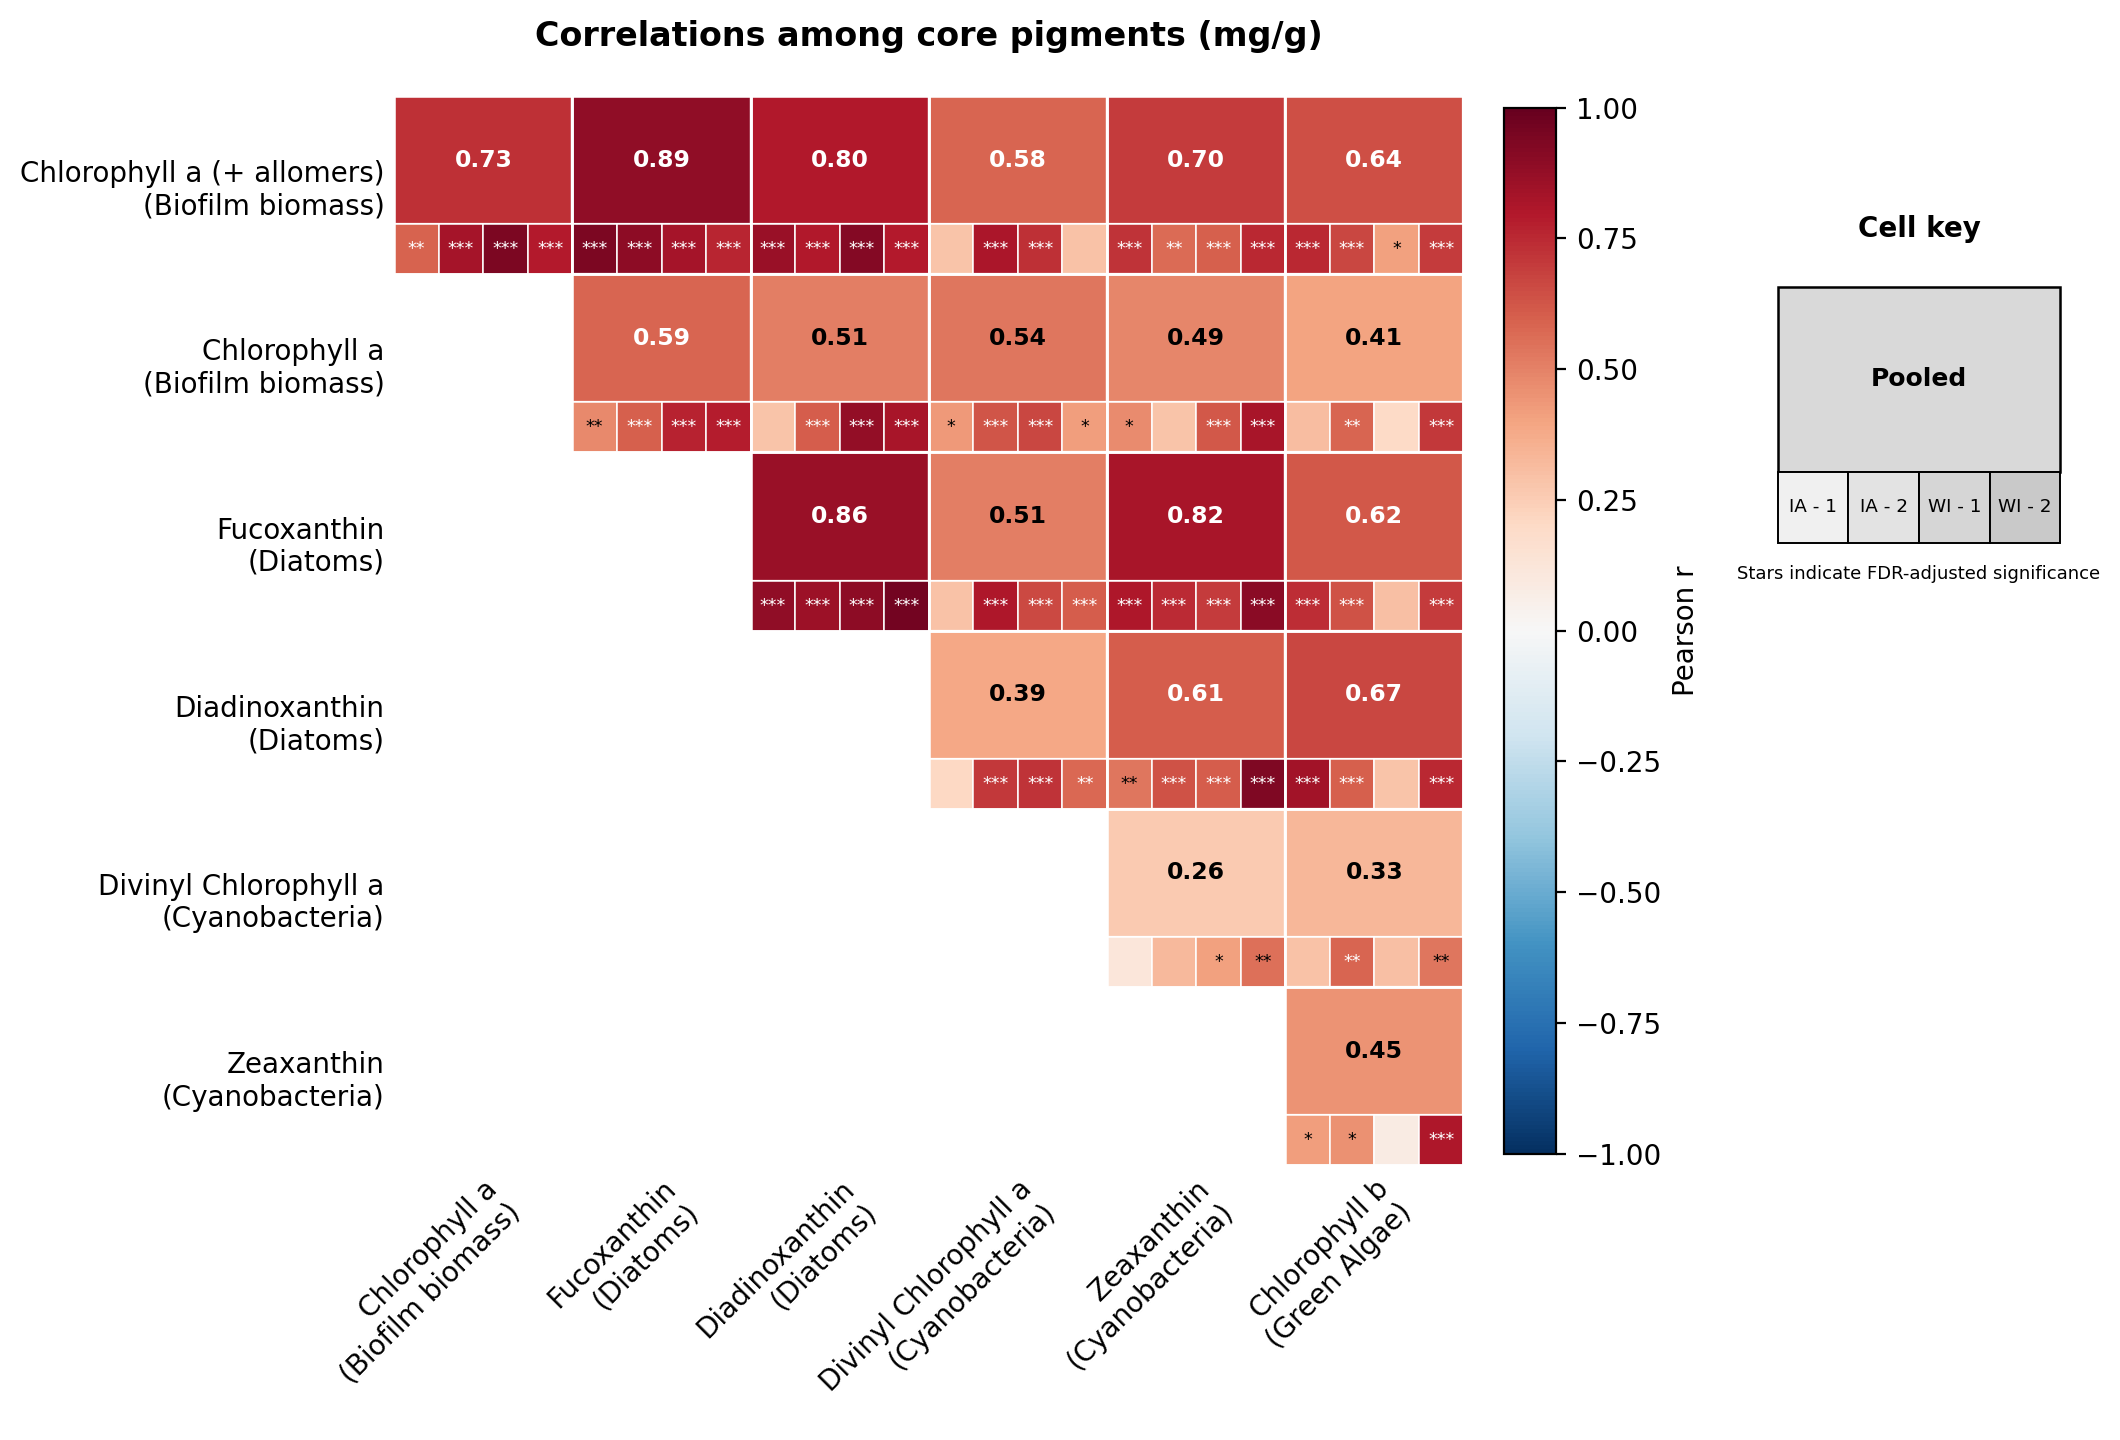

In [13]:
core_pigments = [
    "Chla + allomers",
    "Chla",
    "Fuco",
    "Ddx",
    "DVCh-a",
    "Zea",
    "Chlb",
]
core_pigment_communities = {  # See TT2025 "A suite of 17 marker pigments..."
    "Chla + allomers": "Biofilm biomass",
    "Chla": "Biofilm biomass",
    "Fuco": "Diatoms",
    "Ddx": "Diatoms",
    "DVCh-a": "Cyanobacteria",
    "Zea": "Cyanobacteria",
    "Chlb": "Green Algae",
}
core_pigment_full_names = {
    "Chla + allomers": "Chlorophyll a (+ allomers)",
    "Chla": "Chlorophyll a",
    "Fuco": "Fucoxanthin",
    "Ddx": "Diadinoxanthin",
    "DVCh-a": "Divinyl Chlorophyll a",
    "Zea": "Zeaxanthin",
    "Chlb": "Chlorophyll b",
}


core_pigment_unit = 'mg/g'
core_pigment_columns = [f'{pig} ({core_pigment_unit})'  for pig in core_pigments]

core_pigment_full_labels = {}
for pigment, community in core_pigment_communities.items():
    core_pigment_full_labels[f"{pigment} ({core_pigment_unit})"] = f"{core_pigment_full_names[pigment]}\n({community})"


fig, ax, correlation_df = internal_correlation_heatmap(
    df_combined_R.filter(
        items=core_pigment_columns,
    ),
    pooled_inference="none",
    # n_permutations=99,
    triangle="upper",
    show_diagonal=False,
    annot=True,
    show_case_values=False,
    title=f'Correlations among core pigments ({core_pigment_unit})',
    variable_labels=core_pigment_full_labels,
)


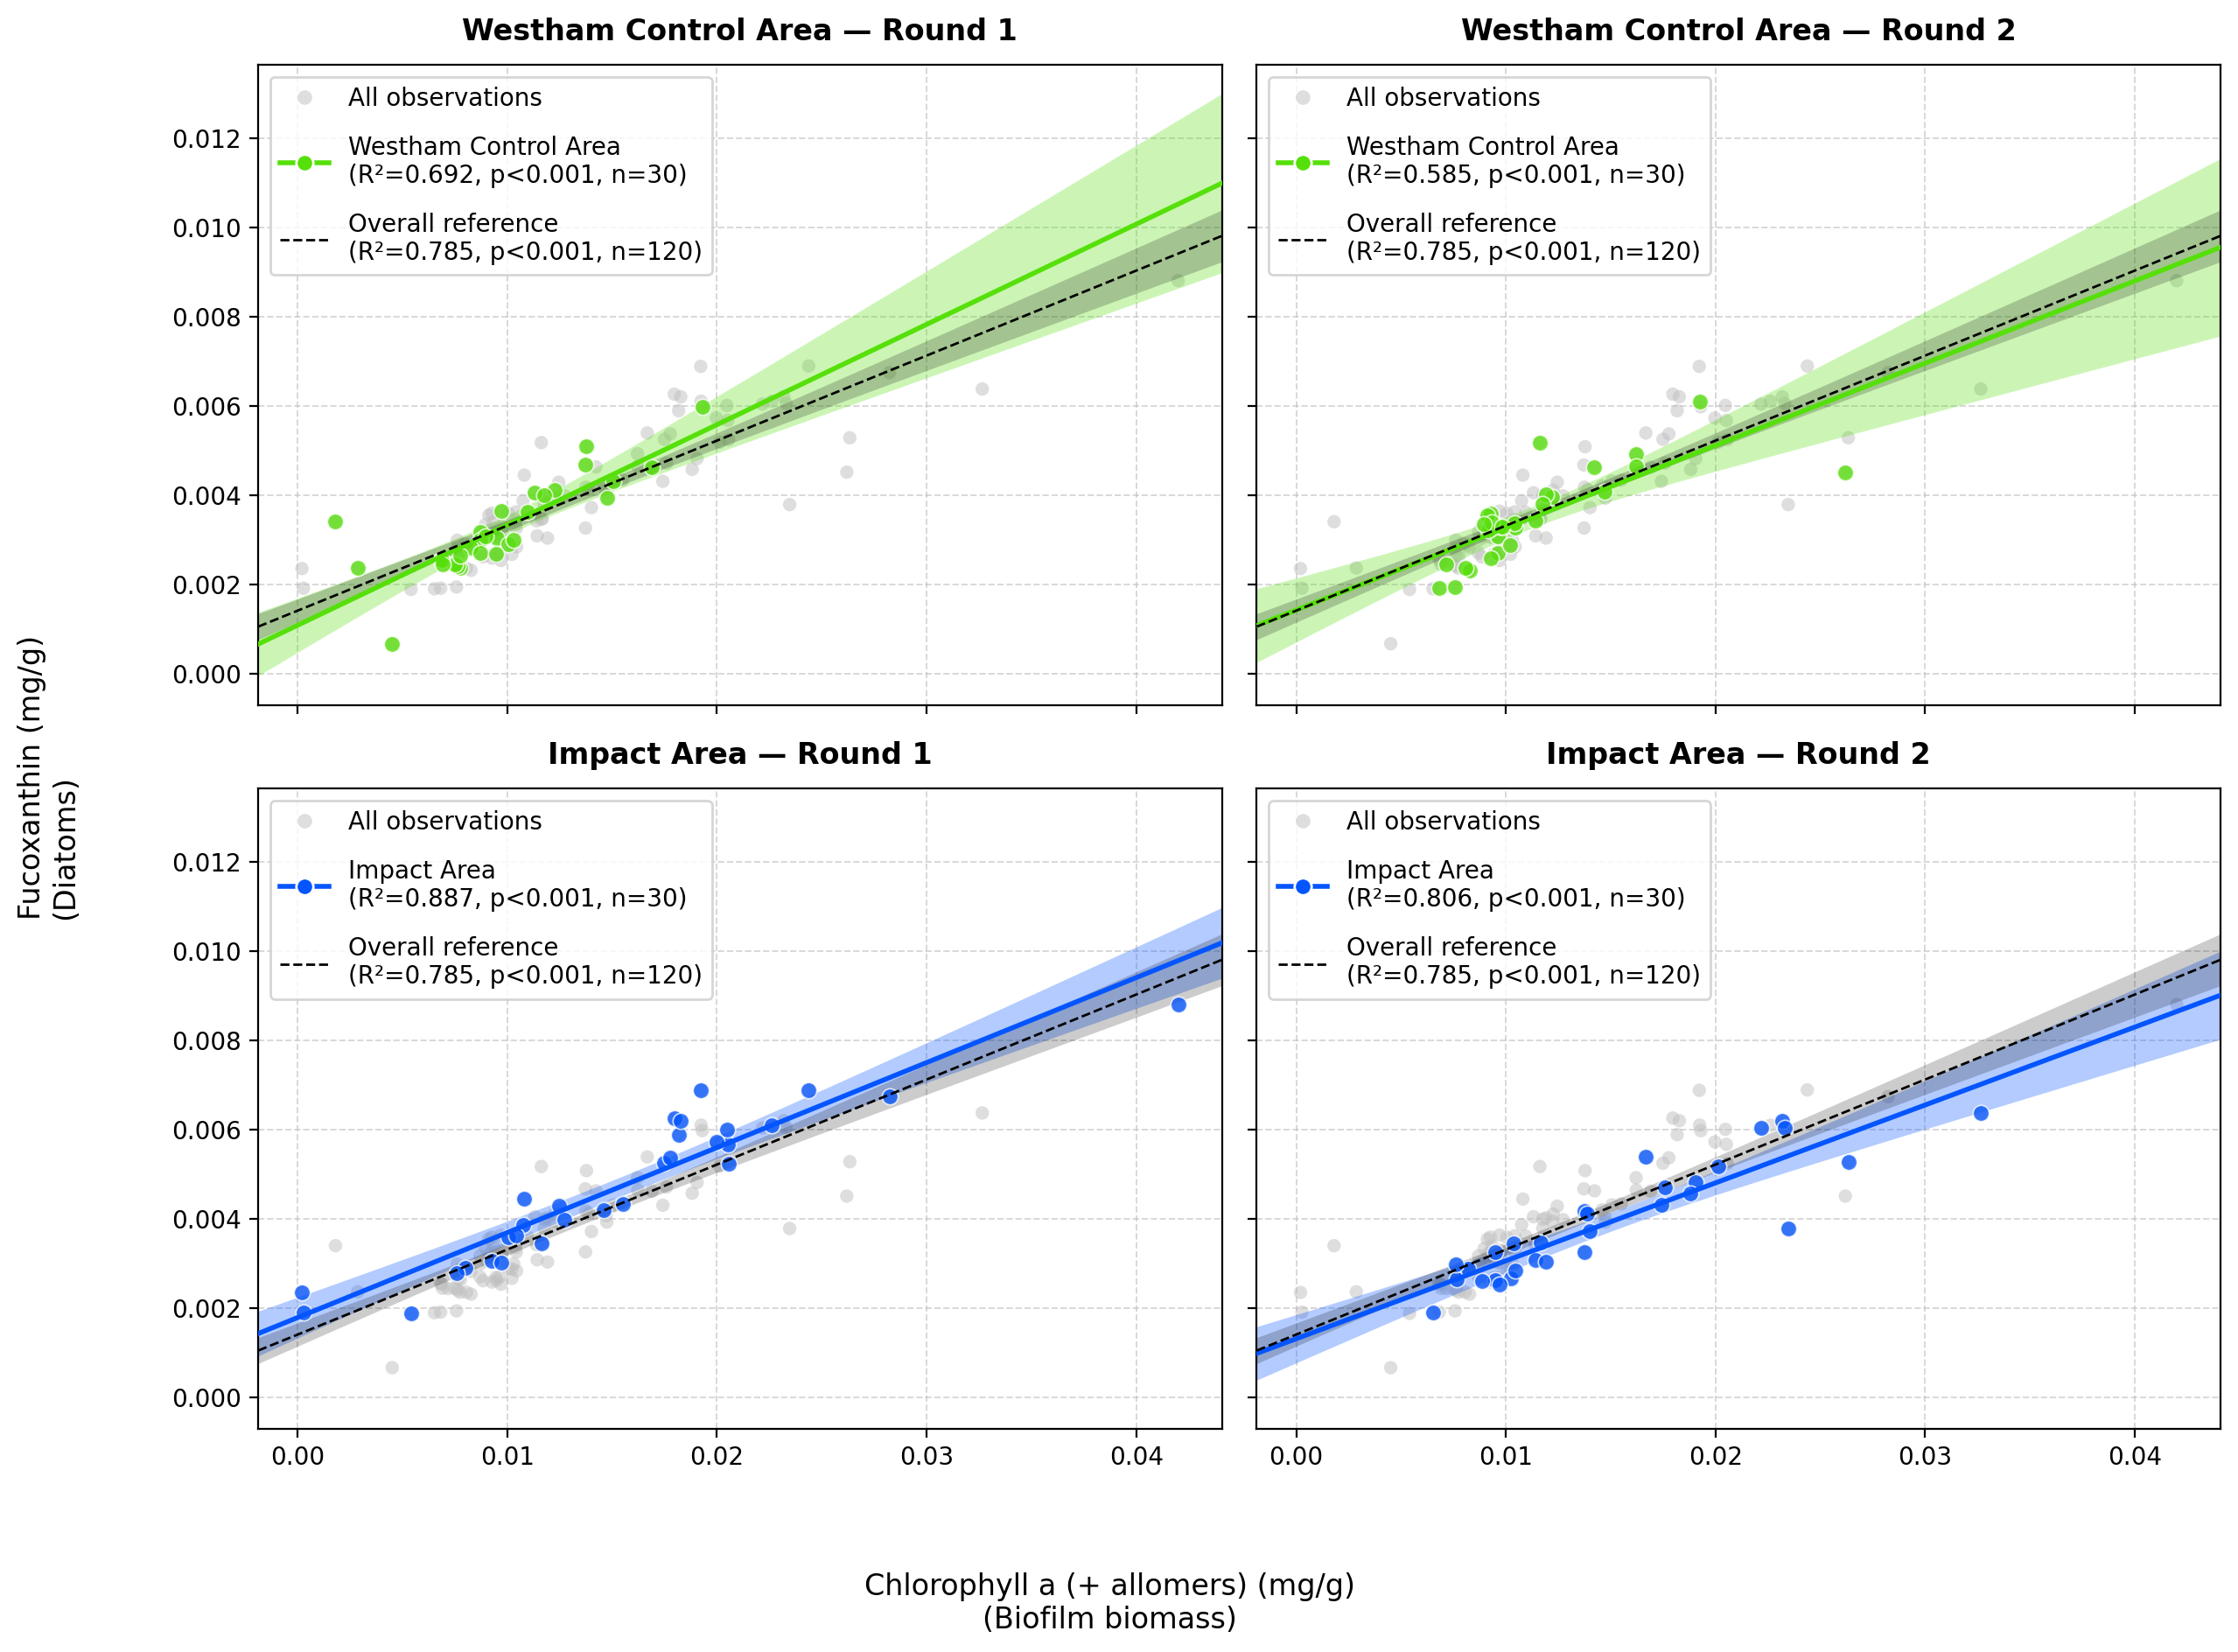

In [14]:
fig, ax, fit_statistics = scatterplot_site_round_grid(
    df_combined_R,
    x=f"Chla + allomers ({core_pigment_unit})",
    y=f"Fuco ({core_pigment_unit})",
    site_colors=SITE_COLORS,
    site_labels=SITE_LABELS,
    # figsize=(15, 10),
    title='',
    x_label=f"Chlorophyll a (+ allomers) ({core_pigment_unit})\n(Biofilm biomass)",
    y_label=f'Fucoxanthin ({core_pigment_unit})\n(Diatoms)',
)

plt.show()

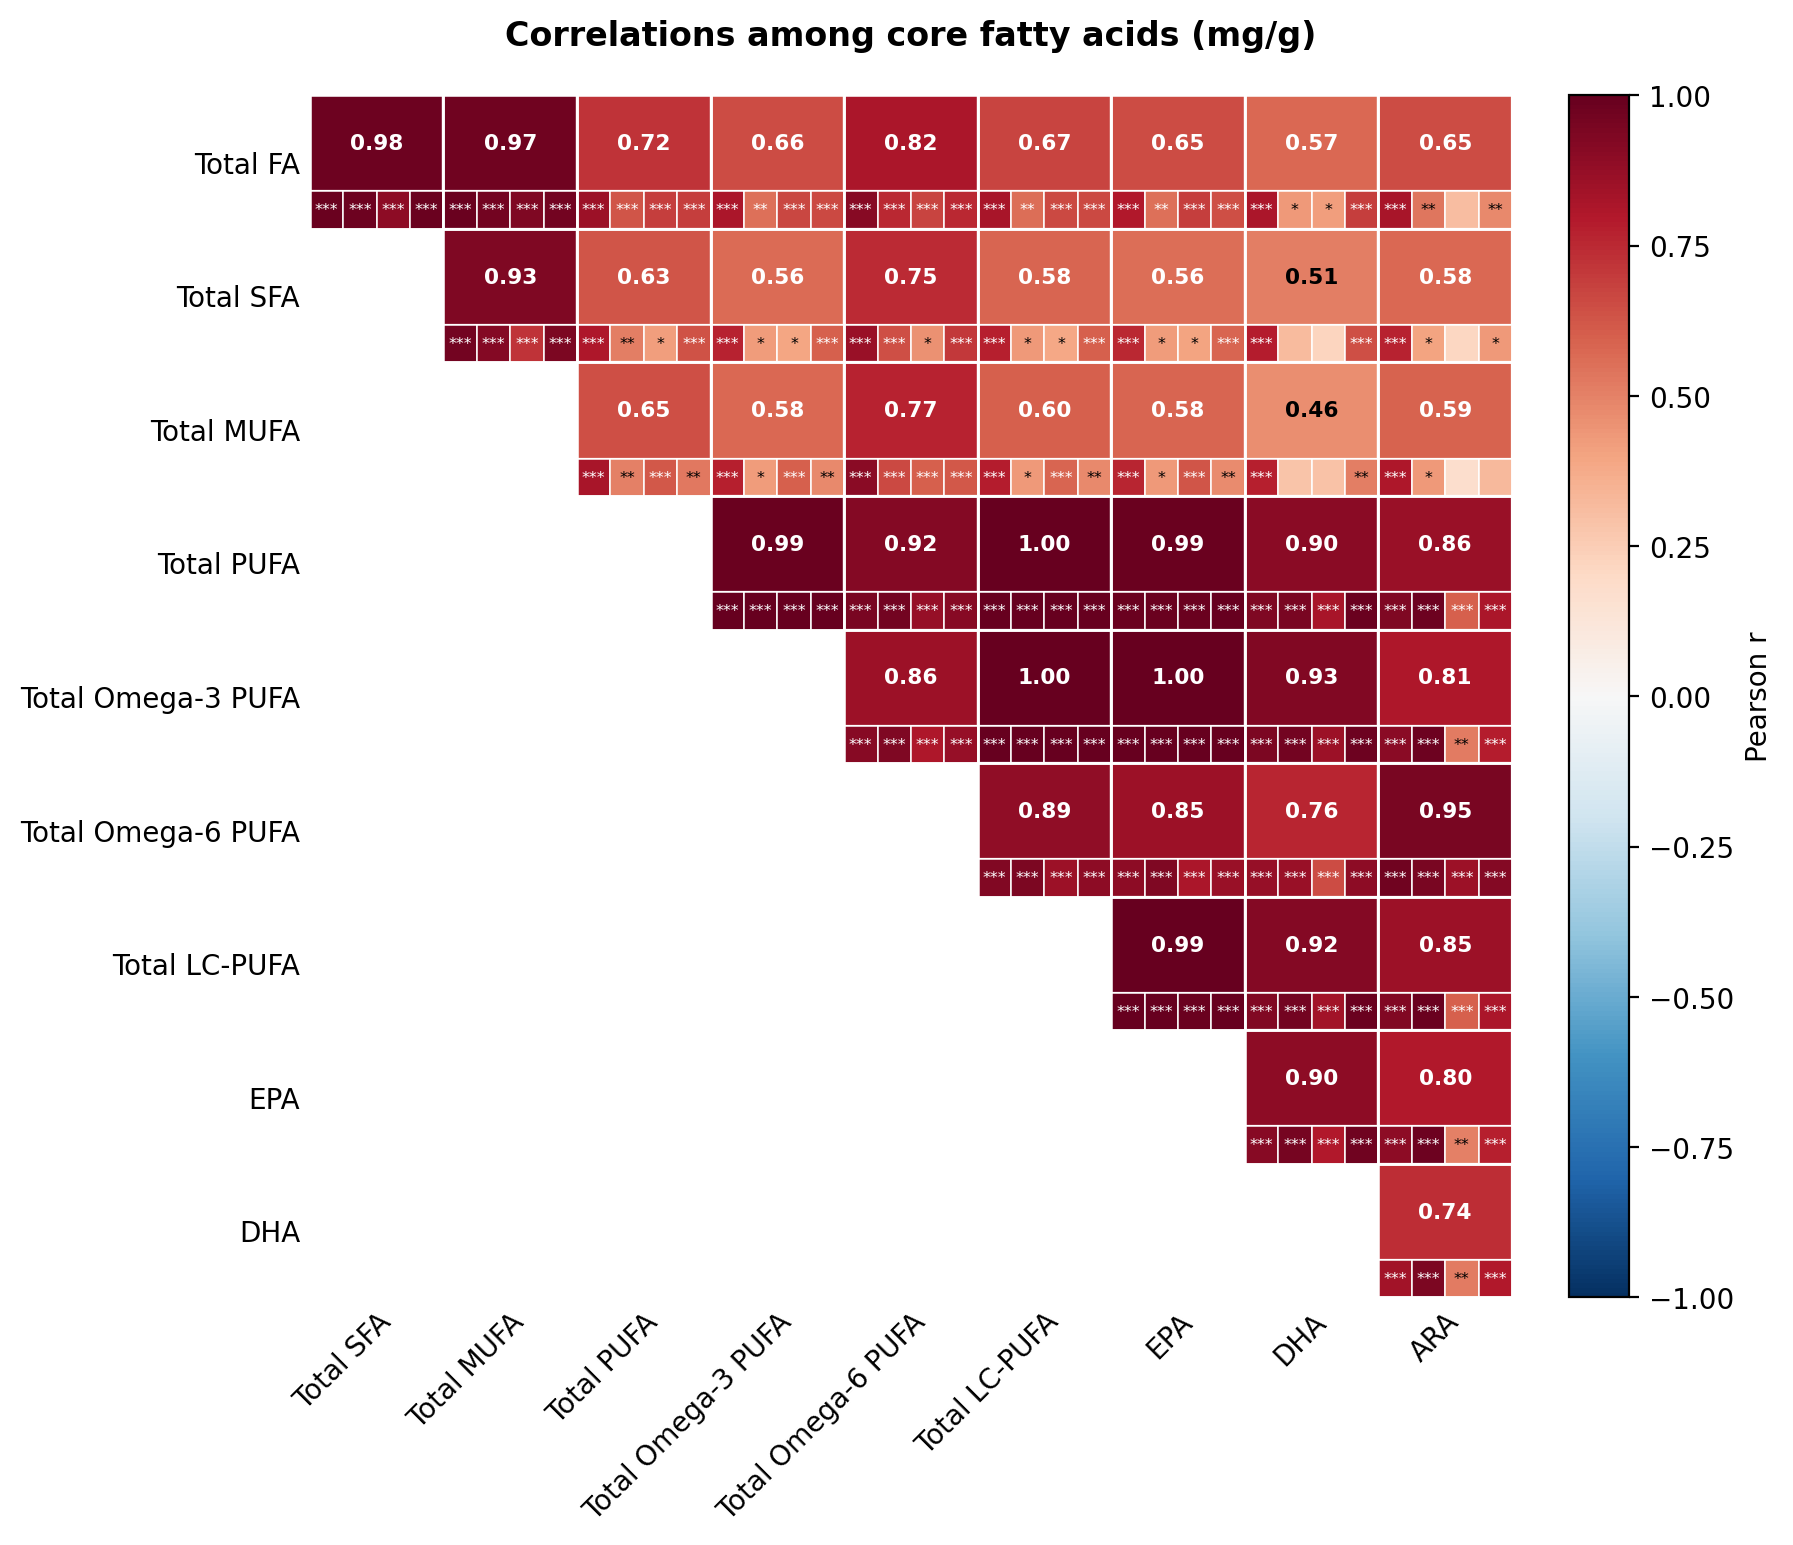

In [15]:
core_fa_unit = 'mg/g' # or 'mg/m2'

core_fa = [
    'Total FA',
    'Total SFA',
    'Total MUFA',
    'Total PUFA',
    'Total Omega-3 PUFA',
    'Total Omega-6 PUFA',
    'Total LC-PUFA',
    'C20:5N3', # EPA
    'C22:6N3', # DHA
    'C20:4N6', # ARA
]

core_fa_labels = [
    'Total FA',
    'Total SFA',
    'Total MUFA',
    'Total PUFA',
    'Total Omega-3 PUFA',
    'Total Omega-6 PUFA',
    'Total LC-PUFA',
    'EPA',
    'DHA',
    'ARA',
]

core_fa_columns = [f'{fa} ({core_fa_unit})' for fa in core_fa]


fig, ax, correlation_df = internal_correlation_heatmap(
    df_combined_R.filter(
        items=core_fa_columns,
    ),
    pooled_inference="none",
    # n_permutations=99,
    triangle="upper",
    show_diagonal=False,
    annot=True,
    show_case_values=False,
    title=f'Correlations among core fatty acids ({core_fa_unit})',
    variable_labels=core_fa_labels,
    show_reference_box=False,
)

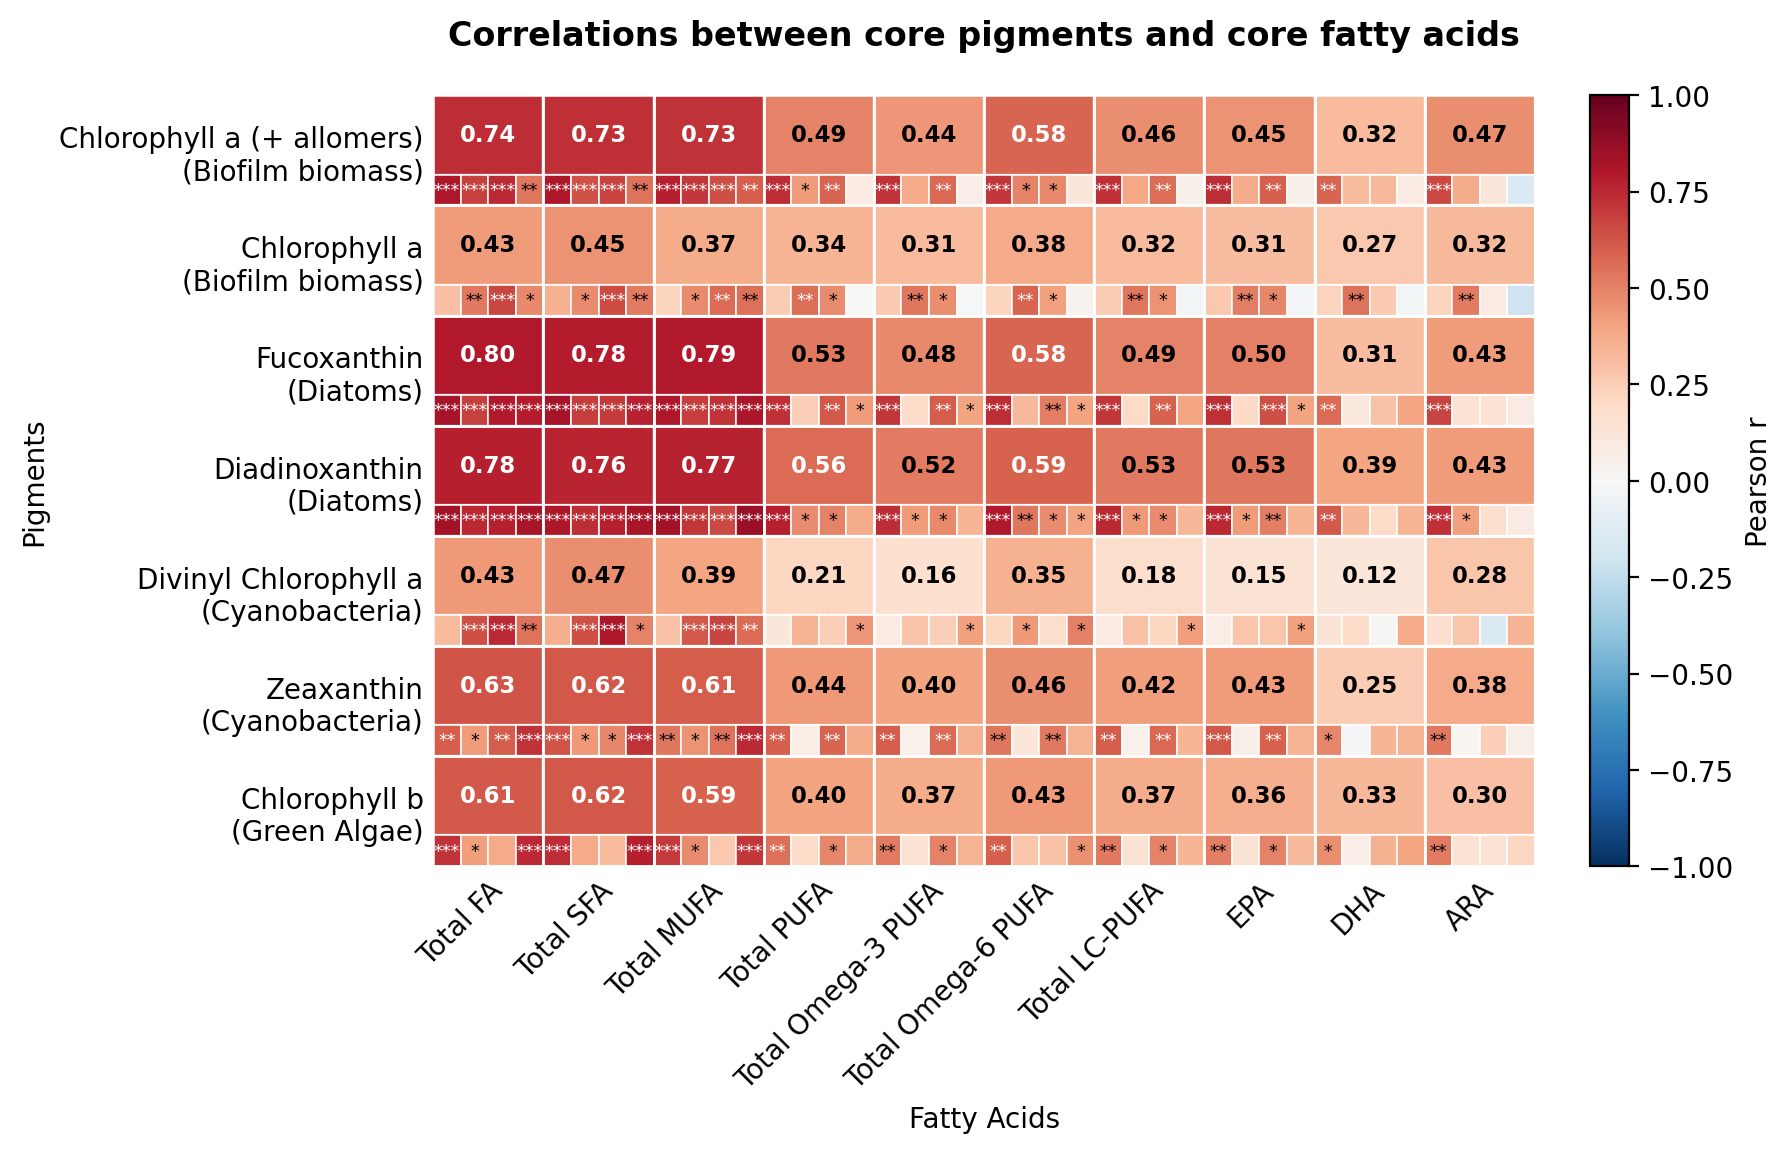

In [16]:
fig, ax, external_correlation_df = external_correlation_heatmap(
    df_combined_R,
    columns_1=core_pigment_columns,
    columns_2=core_fa_columns,
    variable_labels_1=core_pigment_full_labels,
    variable_labels_2=core_fa_labels,
    annot=True,
    show_case_values=False,
    title="Correlations between core pigments and core fatty acids",
    x_axis_label="Fatty Acids",
    y_axis_label="Pigments",
    show_reference_box=False,
    pooled_inference='none',
)

plt.show()


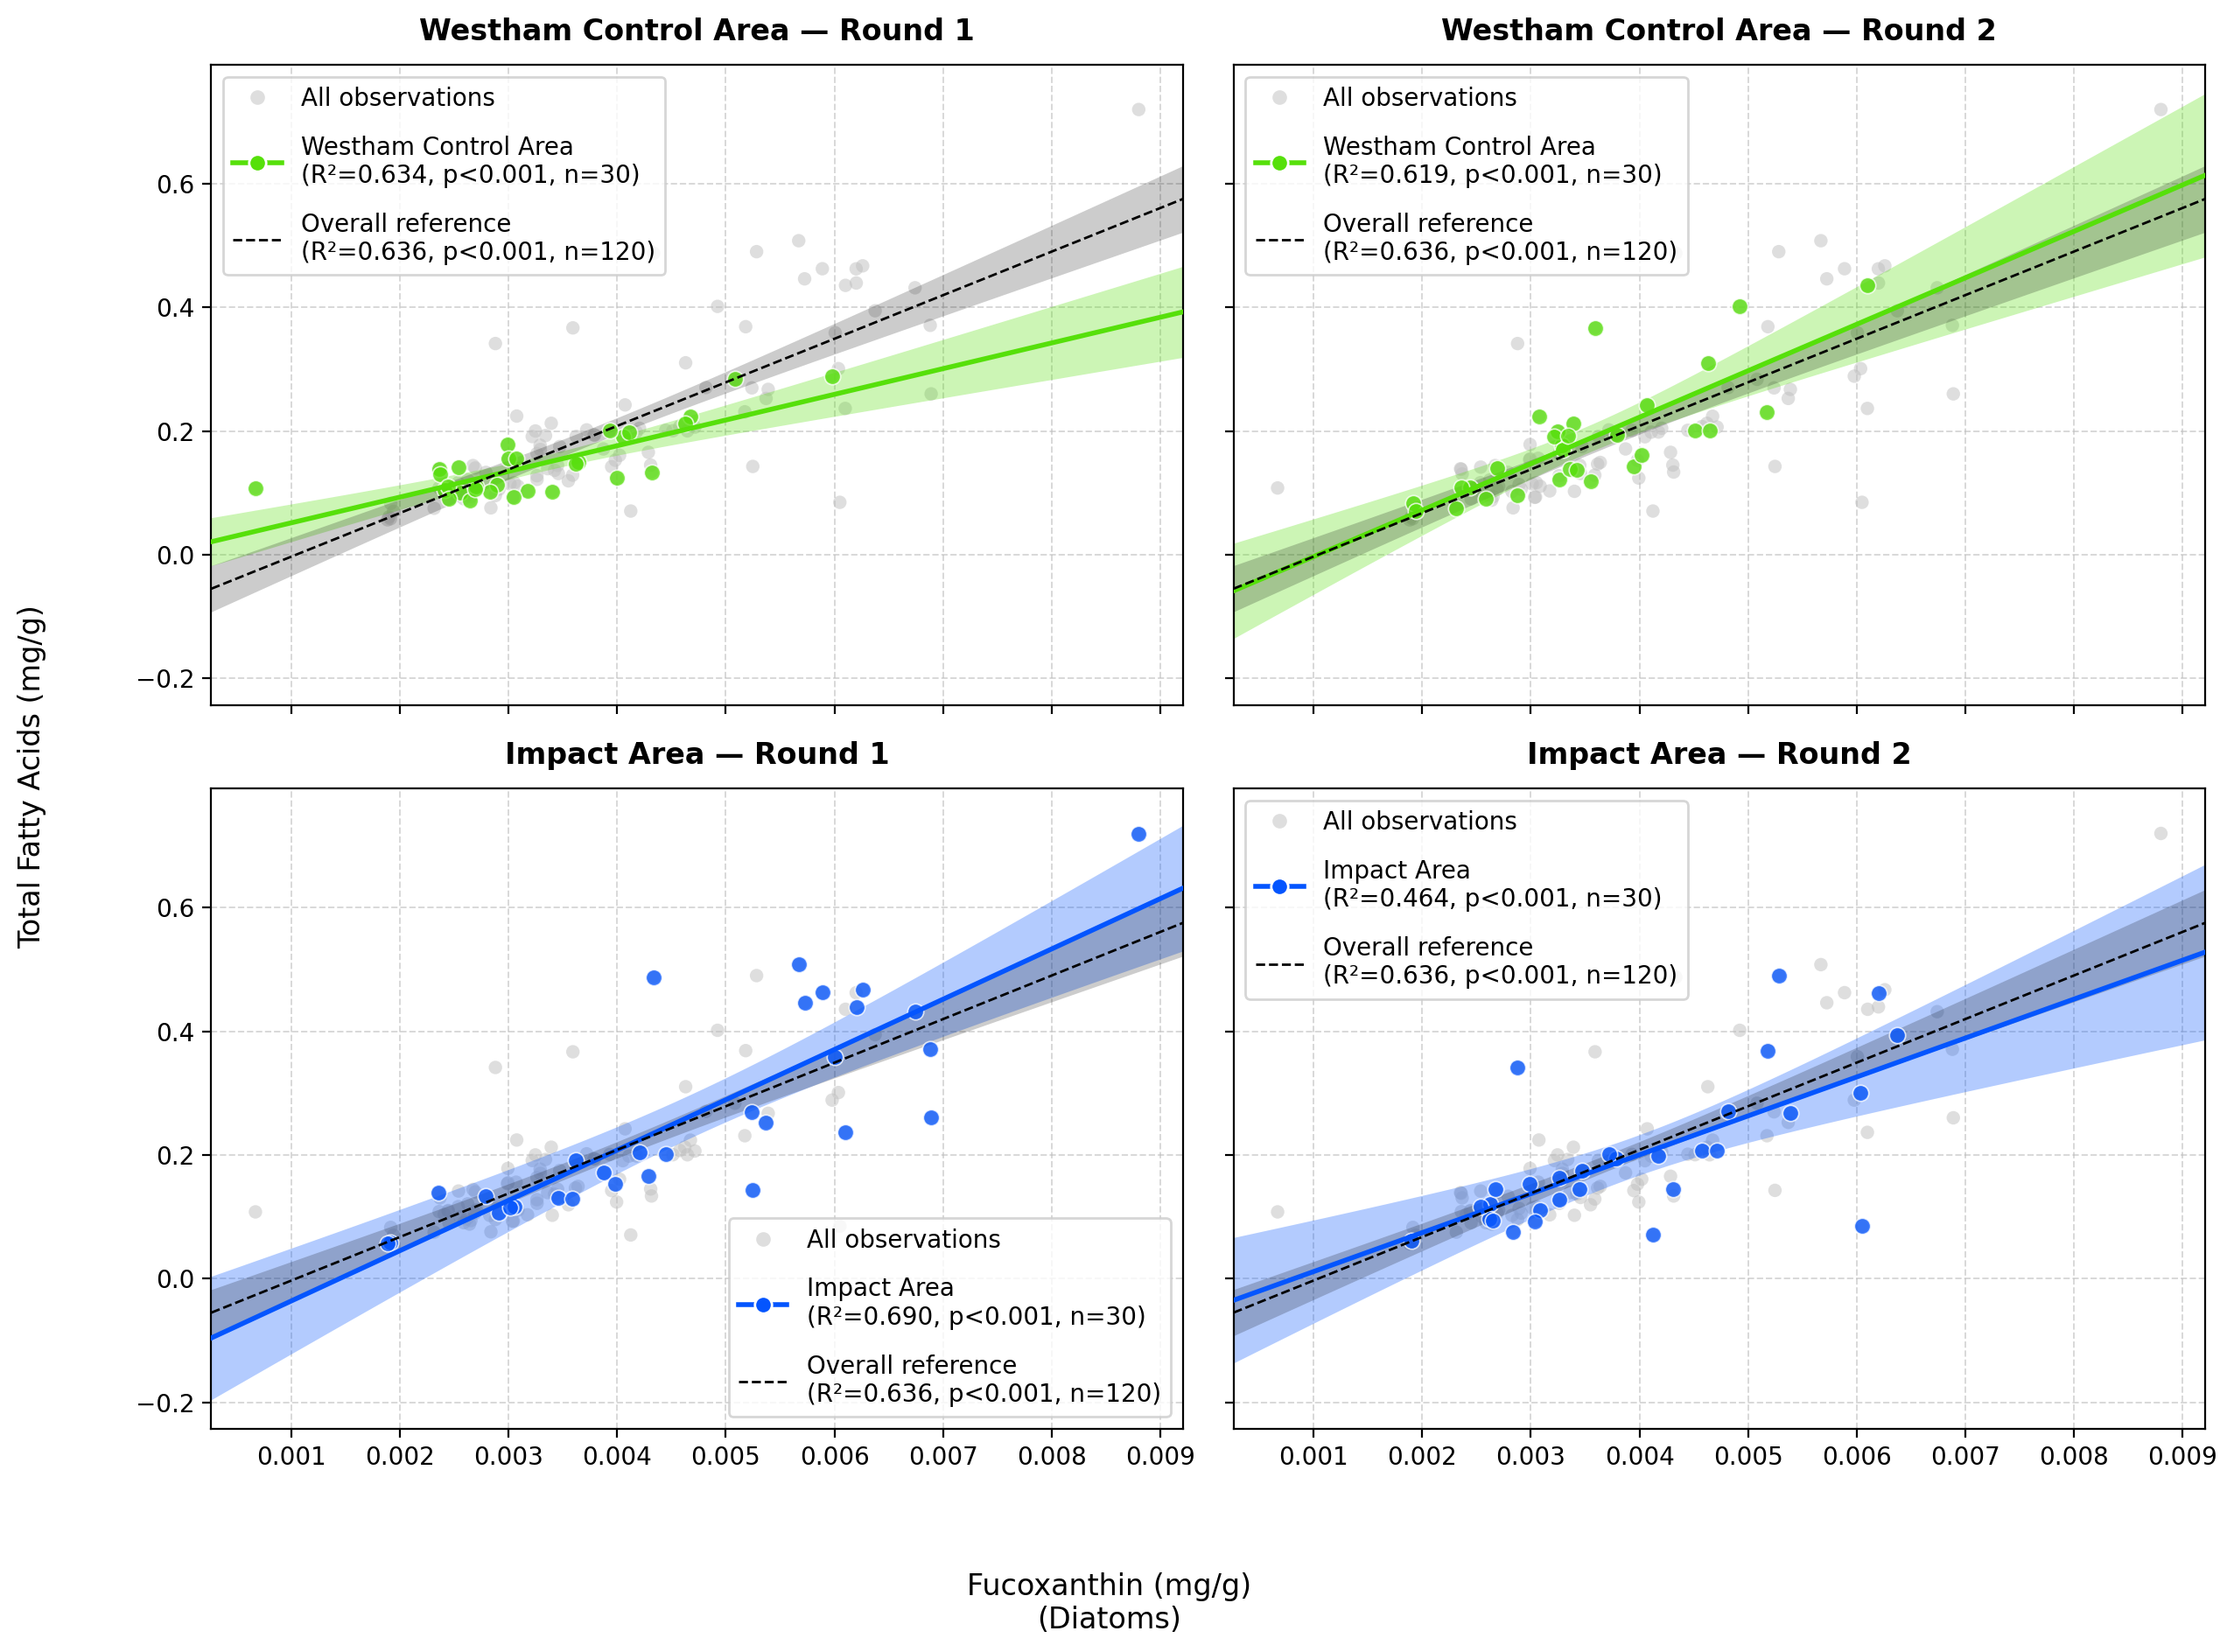

In [17]:
fig, ax, fit_statistics = scatterplot_site_round_grid(
    df_combined_R,
    x=f"Fuco ({core_pigment_unit})",
    y=f"Total FA ({core_fa_unit})",
    site_colors=SITE_COLORS,
    site_labels=SITE_LABELS,
    # figsize=(15, 10),
    title="",
    x_label=f"Fucoxanthin ({core_pigment_unit})\n(Diatoms)",
    y_label=f"Total Fatty Acids ({core_fa_unit})",
)

plt.show()

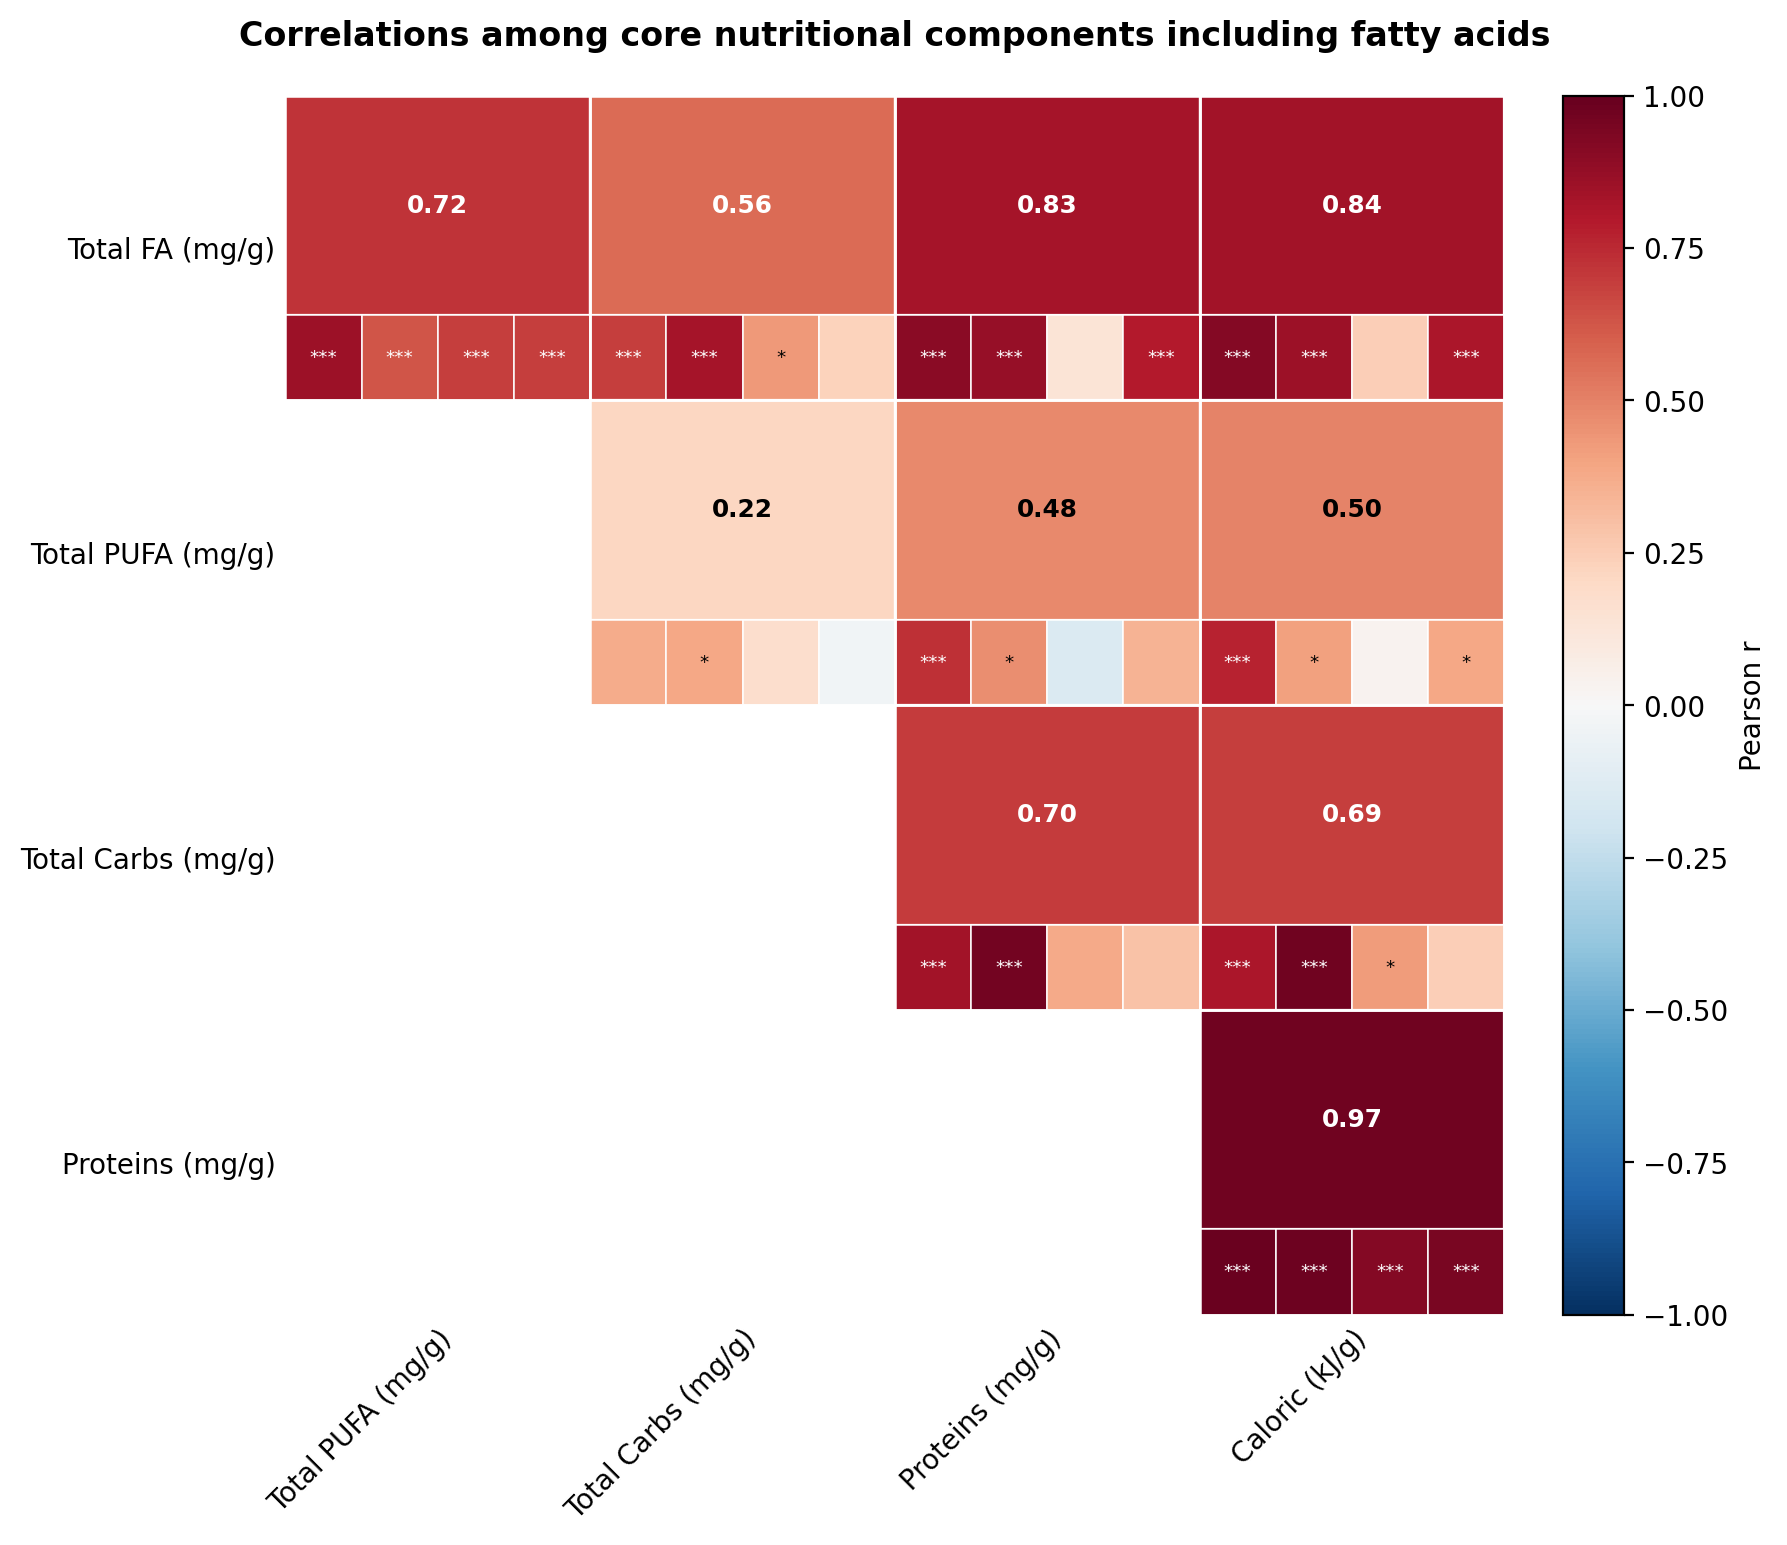

In [18]:
core_nutritional_including_fa = [
    'Total FA',
    # 'Total SFA',
    # 'Total MUFA',
    'Total PUFA',
    'Total Carbs',
    'Proteins',
    'Caloric'
]
caloric_unit = 'kJ/g'

core_nutritional_with_fa_columns = [
    f'Total FA ({core_fa_unit})',
    # f'Total SFA ({core_fa_unit})',
    # f'Total MUFA ({core_fa_unit})',
    f'Total PUFA ({core_fa_unit})',
    f'Total Carbs ({core_fa_unit})',
    f'Proteins ({core_fa_unit})',
    f'Caloric ({caloric_unit})',
]


fig, ax, correlation_df = internal_correlation_heatmap(
    df_combined_R.filter(
        items=core_nutritional_with_fa_columns,
    ),
    pooled_inference="none",
    # n_permutations=99,
    triangle="upper",
    show_diagonal=False,
    annot=True,
    show_case_values=False,
    title=f'Correlations among core nutritional components including fatty acids',
    # variable_labels=core_fa_labels,
    show_reference_box=False,
)

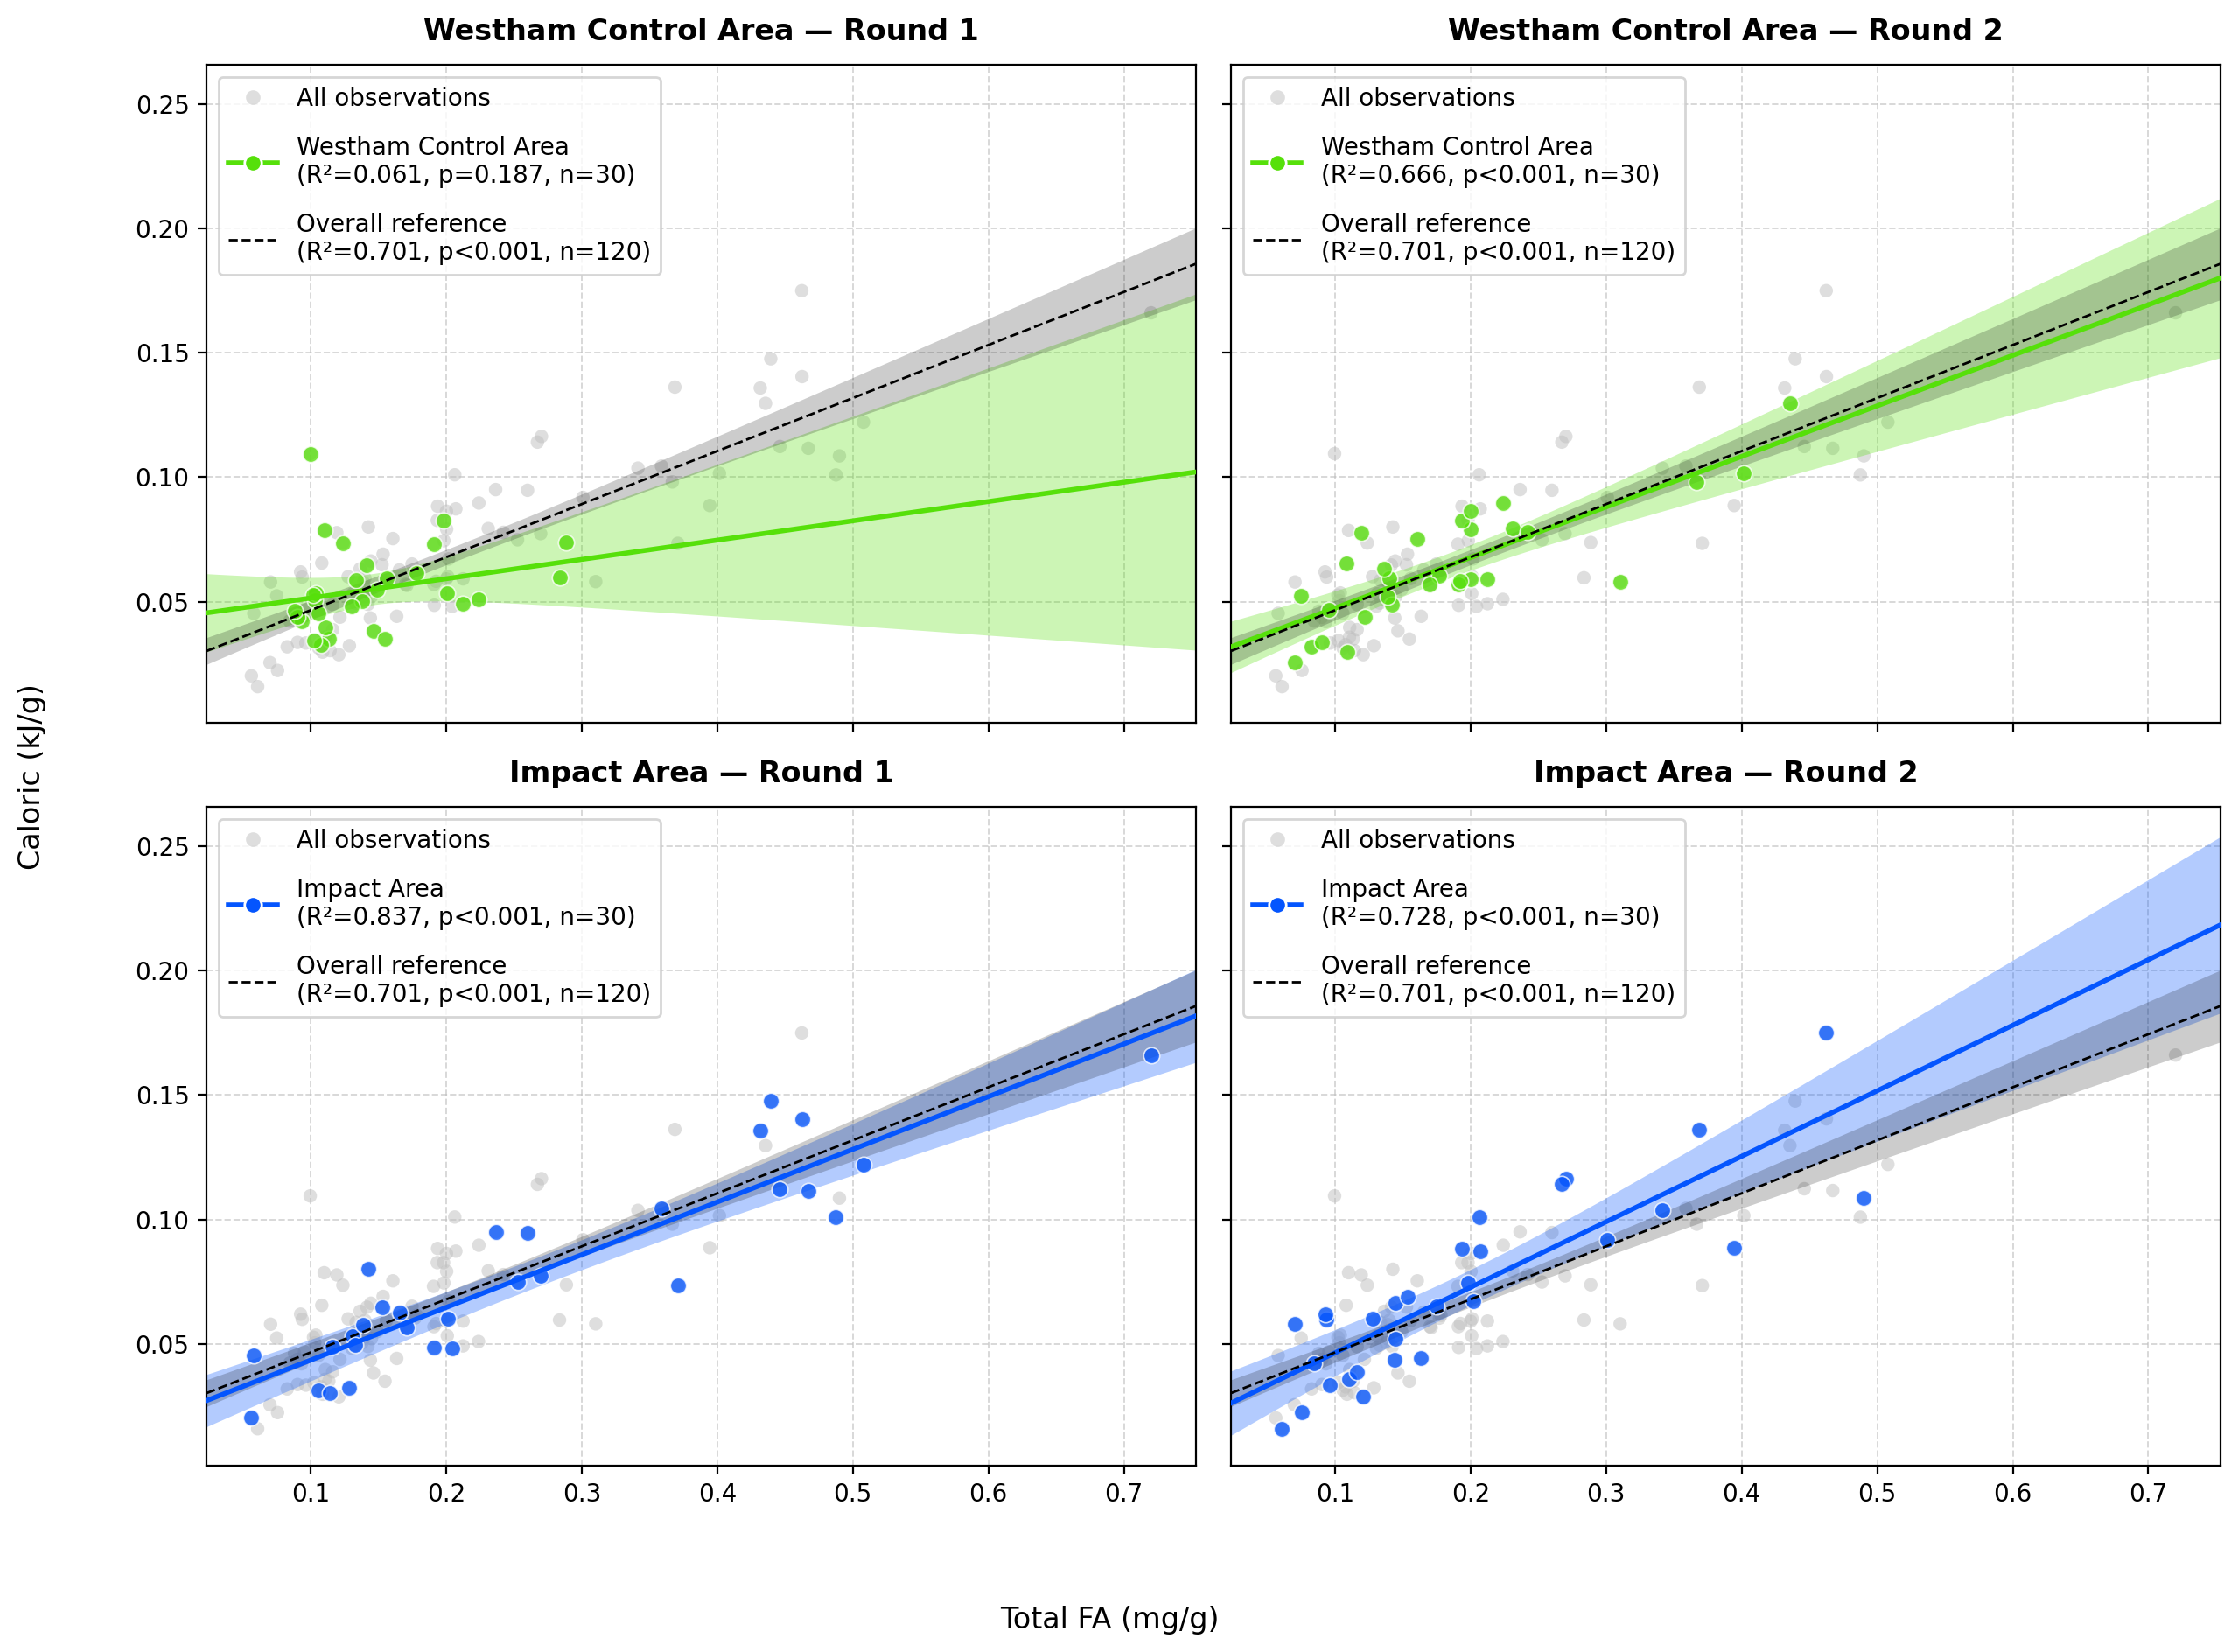

In [19]:
fig, ax, fit_statistics = scatterplot_site_round_grid(
    df_combined_R,
    x=f"Total FA ({core_fa_unit})",
    y=f"Caloric ({caloric_unit})",
    site_colors=SITE_COLORS,
    site_labels=SITE_LABELS,
    # figsize=(15, 10),
    title="",
    x_label=f"Total FA ({core_fa_unit})",
    y_label=f"Caloric ({caloric_unit})",
)

plt.show()


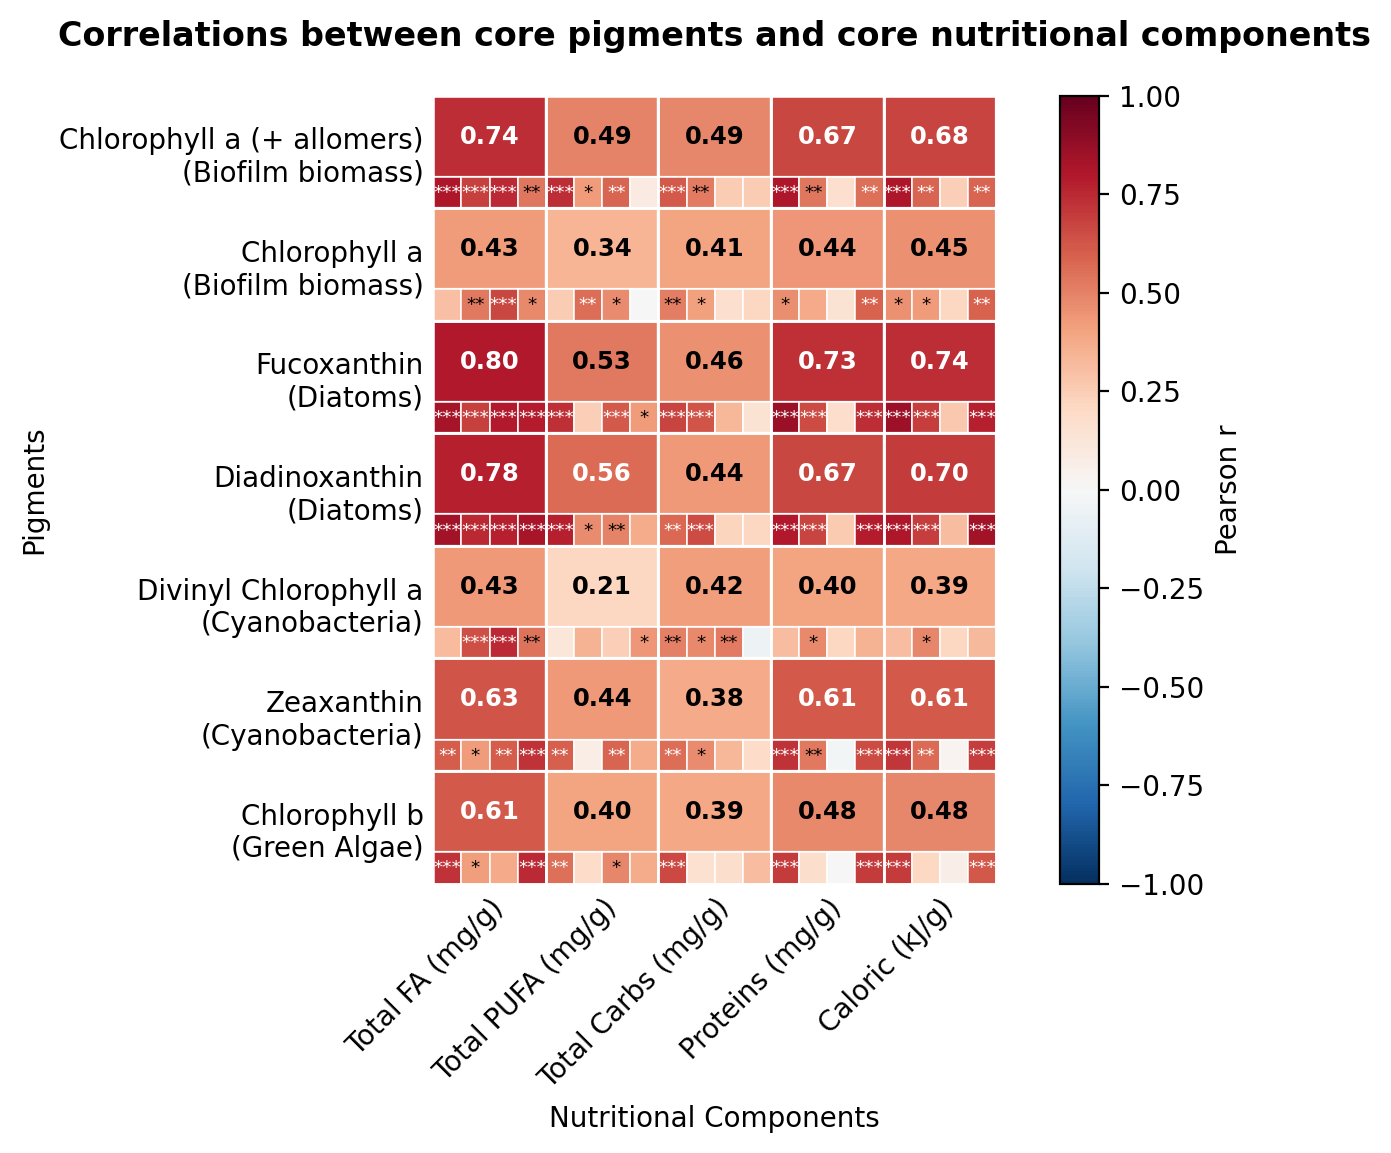

In [20]:
fig, ax, external_correlation_df = external_correlation_heatmap(
    df_combined_R,
    columns_1=core_pigment_columns,
    columns_2=core_nutritional_with_fa_columns,
    variable_labels_1=core_pigment_full_labels,
    # variable_labels_2=core_nutritional_with_fa_columns,
    annot=True,
    show_case_values=False,
    title="Correlations between core pigments and core nutritional components",
    x_axis_label="Nutritional Components",
    y_axis_label="Pigments",
    show_reference_box=False,
    pooled_inference="none",
)

plt.show()


In [21]:
# df_combined_grouped_R.xs(('Nutritional', 'Lab Concentrations (/g)'), level=(0,1), axis=1).

In [22]:
correlation_df


,variable_x,variable_y,column_x,column_y,case,site,round,method,coefficient,n,p_value,q_value,significance,significant
0,Total PUFA (mg/g),Total FA (mg/g),Total PUFA (mg/g),Total FA (mg/g),pooled,None,NaN,pearson,0.719149,120,NaN,NaN,,False
1,Total PUFA (mg/g),Total FA (mg/g),Total PUFA (mg/g),Total FA (mg/g),brunswick | round 1,brunswick,1.0,pearson,0.852046,30,2.331312e-09,8.477498e-09,***,True
2,Total PUFA (mg/g),Total FA (mg/g),Total PUFA (mg/g),Total FA (mg/g),brunswick | round 2,brunswick,2.0,pearson,0.627068,30,2.087045e-04,3.794627e-04,***,True
3,Total PUFA (mg/g),Total FA (mg/g),Total PUFA (mg/g),Total FA (mg/g),westham | round 1,westham,1.0,pearson,0.691647,30,2.306642e-05,4.393605e-05,***,True
4,Total PUFA (mg/g),Total FA (mg/g),Total PUFA (mg/g),Total FA (mg/g),westham | round 2,westham,2.0,pearson,0.693355,30,2.159765e-05,4.393605e-05,***,True
5,Total Carbs (mg/g),Total FA (mg/g),Total Carbs (mg/g),Total FA (mg/g),pooled,None,NaN,pearson,0.564425,120,NaN,NaN,,False
6,Total Carbs (mg/g),Total FA (mg/g),Total Carbs (mg/g),Total FA (mg/g),brunswick | round 1,brunswick,1.0,pearson,0.691923,30,2.282305e-05,4.393605e-05,***,True
7,Total Carbs (mg/g),Total FA (mg/g),Total Carbs (mg/g),Total FA (mg/g),brunswick | round 2,brunswick,2.0,pearson,0.830564,30,1.352361e-08,4.161112e-08,***,True
8,Total Carbs (mg/g),Total FA (mg/g),Total Carbs (mg/g),Total FA (mg/g),westham | round 1,westham,1.0,pearson,0.431306,30,1.732752e-02,2.887920e-02,*,True
9,Total Carbs (mg/g),Total FA (mg/g),Total Carbs (mg/g),Total FA (mg/g),westham | round 2,westham,2.0,pearson,0.233739,30,2.138124e-01,2.443571e-01,,False


In [23]:
df_combined_R.columns

Index(['Sample Total Dry Mass (g)', 'Extraction Dry Mass (mg)',
       'Area Sampled (m2)', '/g to /m2 Conversion Factor (g/m2)',
       'Moisture (%)', 'Percent Sand (%)', 'Percent Silt (%)',
       'Percent Clay (%)', 'Sample Date', 'Time of Emergence (decimal)',
       ...
       'NDCI3_mean', 'NDCI2_mean', 'NDVI740_max', 'NDVI842_max', 'NDCI3_max',
       'NDCI2_max', 'NDVI740_std', 'NDVI842_std', 'NDCI3_std', 'NDCI2_std'],
      dtype='object', length=254)

In [24]:
# # Get first level of columns
# column_groups = df_combined_grouped_R.columns.get_level_values(0).unique()
# for column_group in column_groups:
#     column_subgroups = df_combined_grouped_R.xs(column_group, level=0, axis=1).columns.get_level_values(0).unique()
#     print(column_group)
#     for column_subgroup in column_subgroups:
#         print('\t', column_subgroup)

# Chlorophyll a + allomers vs. NDVI

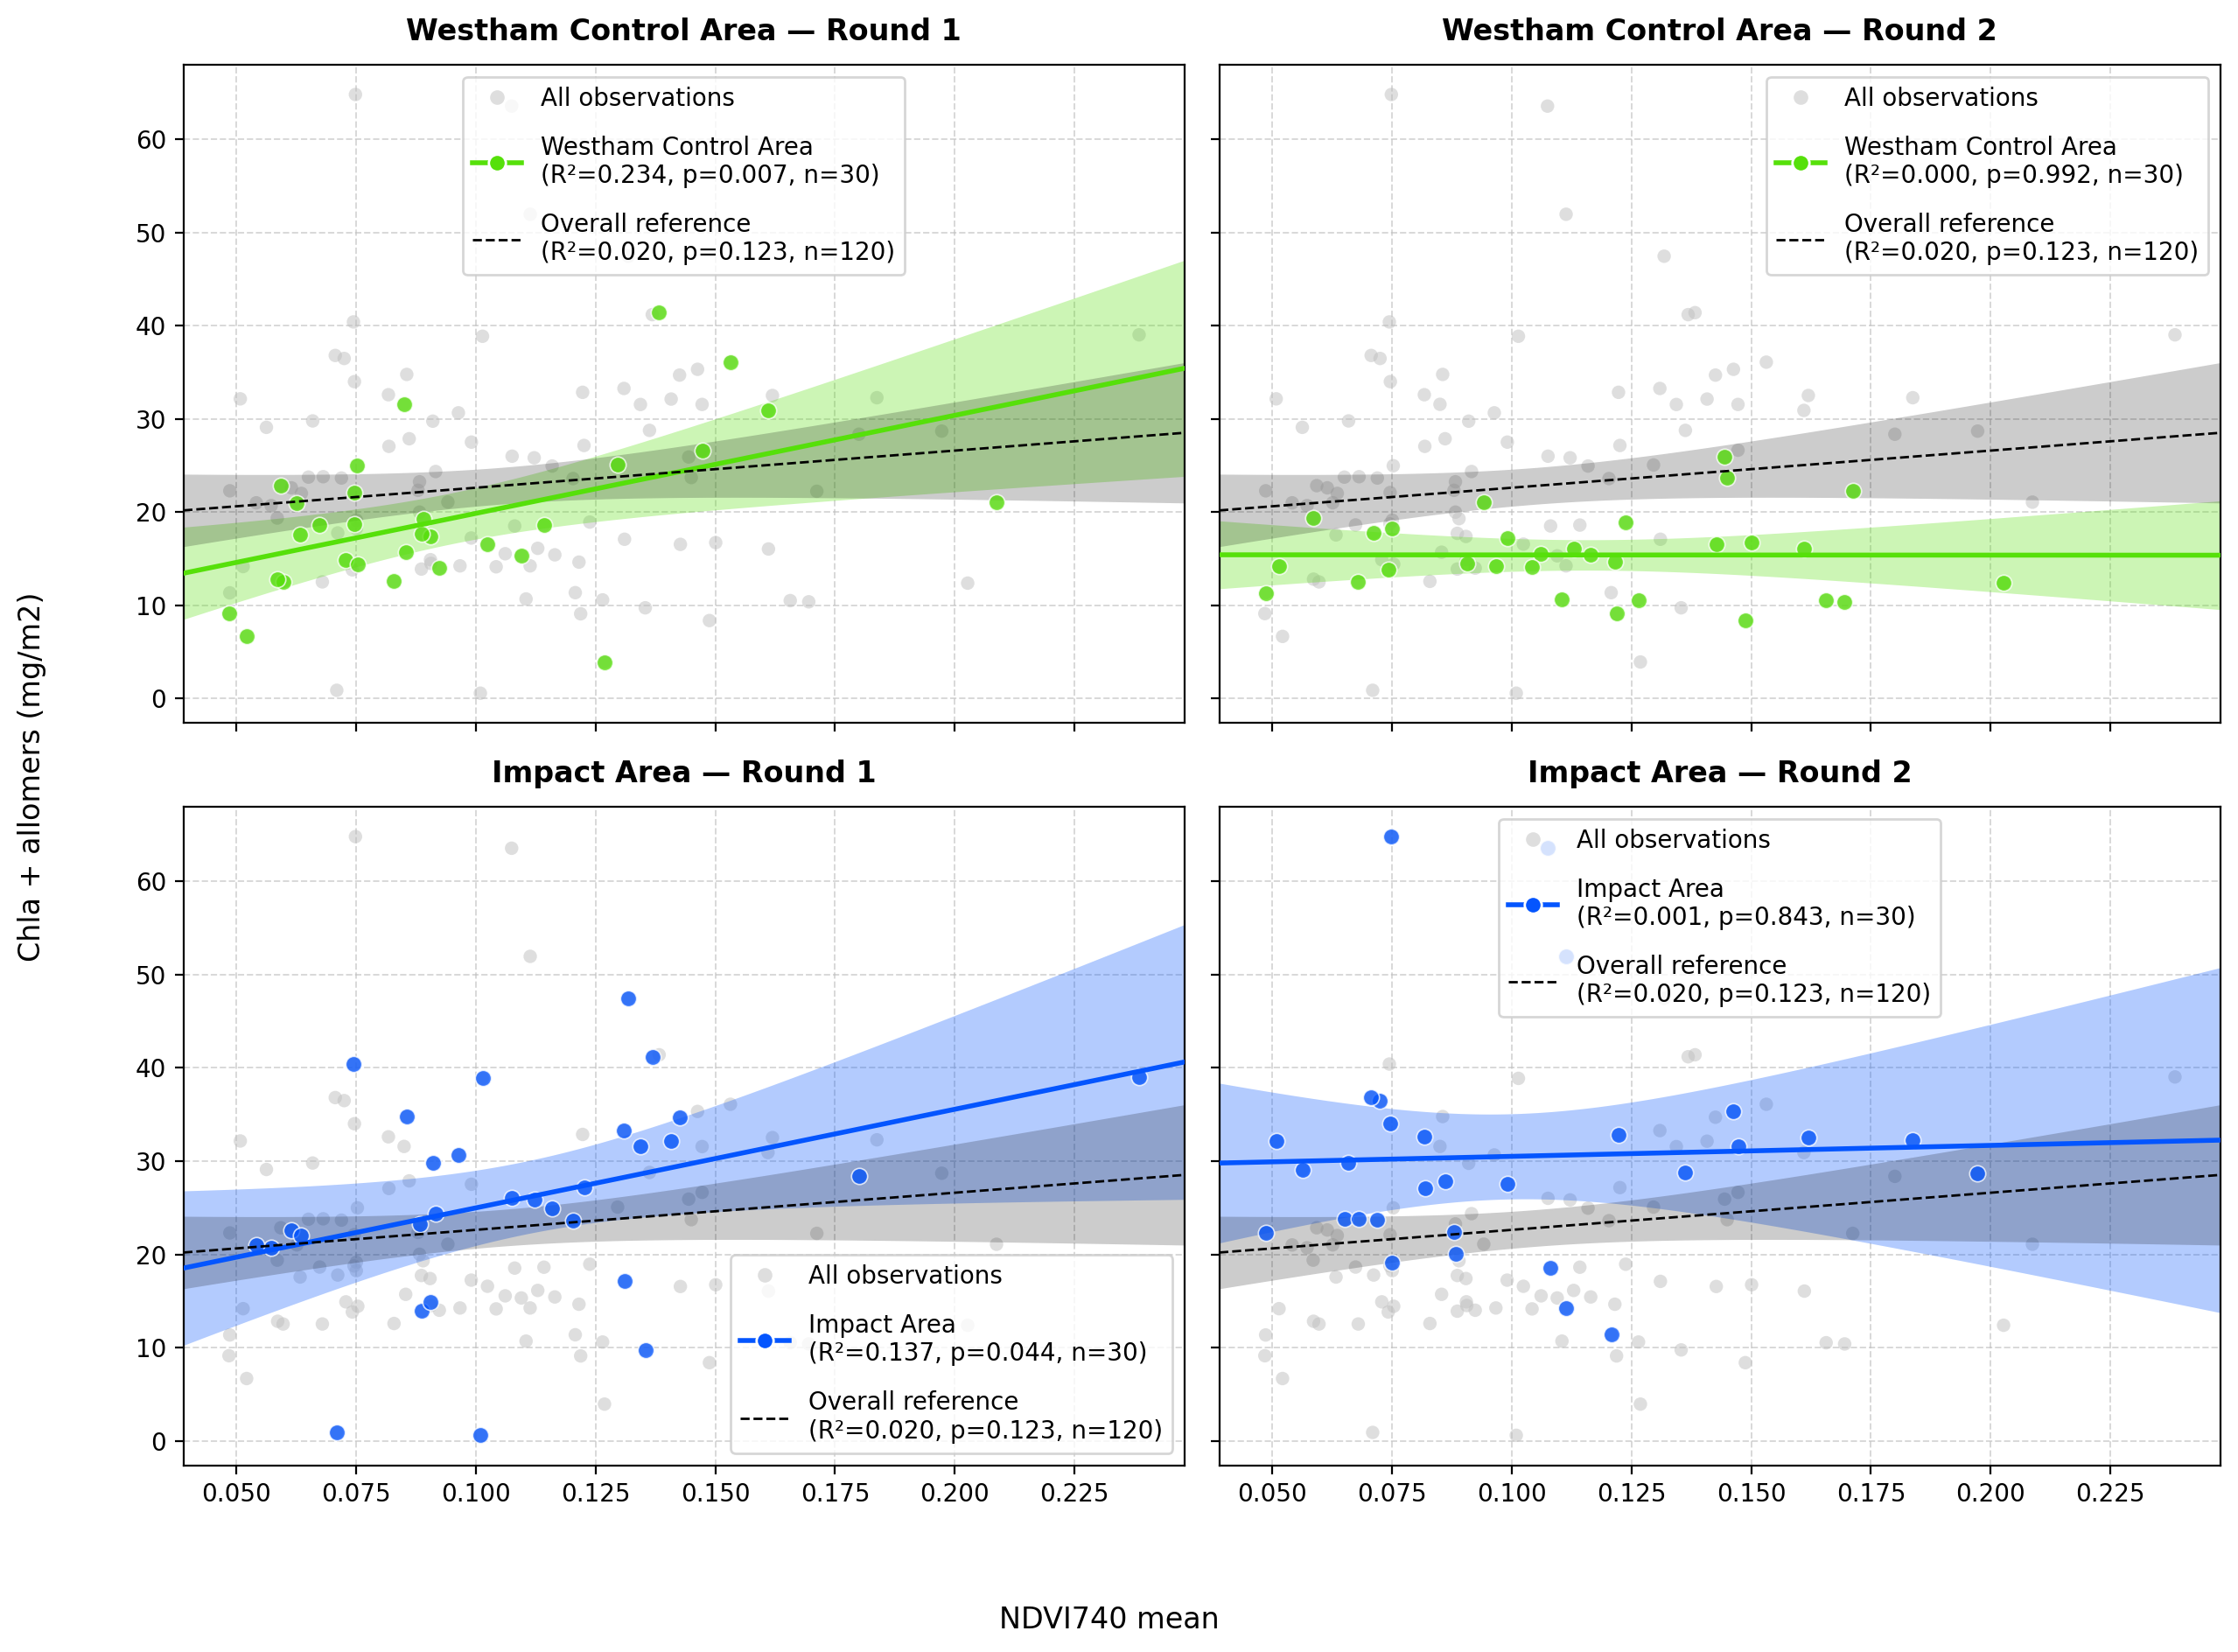

In [25]:
fig, ax, fit_statistics = scatterplot_site_round_grid(
    df_combined_R,
    x="NDVI740_mean",
    y=f"Chla + allomers (mg/m2)",
    site_colors=SITE_COLORS,
    site_labels=SITE_LABELS,
    # figsize=(15, 10),
    title="",
    x_label="NDVI740 mean",
    y_label=f"Chla + allomers (mg/m2)",
)

plt.show()


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


def grouped_linear_fits(
    df,
    x,
    y,
    x_value,
    *,
    site_level="site",
    round_level="round",
    site_order=None,
    round_order=None,
    confidence_level=0.95,
    min_n=3,
    x_label=None,
    y_label=None,
    title=None,
    site_colors=None,
    round_colors=None,
    point_size=42,
    point_alpha=0.75,
    line_width=2,
    ci_alpha=0.22,
    show_x_value=True,
    extend_fit_to_x_value=False,
    sharex=True,
    sharey=True,
    ncols=3,
    figsize=(15, 13),
    grid=True,
):
    """
    Fit and plot linear relationships for all site/round groupings.

    With two sites and two rounds, fits are calculated for:

        1. Each site-round combination                 4 fits
        2. Each round, pooling sites                   2 fits
        3. Each site, pooling rounds                   2 fits
        4. All observations pooled                     1 fit

        Total                                           9 fits

    The confidence intervals represent uncertainty in the estimated
    mean response, not prediction intervals for individual observations.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataframe containing x and y. Its index must be a MultiIndex
        containing site_level and round_level.

    x, y : hashable
        Column names. Complete tuples can be used for MultiIndex columns.

    x_value : float
        X value at which the corresponding mean y and confidence interval
        will be estimated.

    site_level, round_level : str
        Names of the site and round index levels.

    site_order, round_order : sequence, optional
        Site and round values to include and their ordering. By default,
        all values are included in their order of appearance.

    confidence_level : float, default 0.95
        Confidence level for coefficient intervals, confidence bands,
        and estimated mean y at x_value.

    min_n : int, default 3
        Minimum number of pairwise-complete observations required for
        a regression.

    extend_fit_to_x_value : bool, default False
        If True and x_value is outside a group's observed x range, extend
        that group's regression line and confidence band to x_value.
        The result is still flagged as extrapolation.

    sharex, sharey : bool
        Whether subplot axes should use common x and y scales.

    ncols : int, default 3
        Number of subplot columns.

    Returns
    -------
    fig : matplotlib.figure.Figure

    axes : numpy.ndarray
        Array of subplot axes.

    fit_results : pandas.DataFrame
        One row per regression, including coefficient statistics and the
        estimated mean y at x_value.

    Notes
    -----
    The mean-response confidence interval at x0 is:

        y_hat(x0) ± t * s * sqrt(
            1/n + (x0 - x_bar)^2 / Sxx
        )

    This interval quantifies uncertainty in the fitted mean. It is narrower
    than a prediction interval for a new individual observation.
    """

    # ------------------------------------------------------------------
    # Validation
    # ------------------------------------------------------------------
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if not isinstance(df.index, pd.MultiIndex):
        raise TypeError("df.index must be a pandas MultiIndex.")

    missing_levels = {
        site_level,
        round_level,
    } - set(df.index.names)

    if missing_levels:
        raise KeyError(f"Missing index level(s): {sorted(missing_levels)}")

    if x not in df.columns:
        raise KeyError(f"x column {x!r} was not found.")

    if y not in df.columns:
        raise KeyError(f"y column {y!r} was not found.")

    if x == y:
        raise ValueError("x and y must refer to different columns.")

    if not np.isscalar(x_value):
        raise TypeError("x_value must be a scalar numeric value.")

    try:
        x_value = float(x_value)
    except (TypeError, ValueError) as error:
        raise TypeError("x_value must be numeric.") from error

    if not np.isfinite(x_value):
        raise ValueError("x_value must be finite.")

    if not 0 < confidence_level < 1:
        raise ValueError("confidence_level must be between zero and one.")

    if min_n < 3:
        raise ValueError(
            "min_n must be at least 3 because linear-fit confidence "
            "intervals require residual degrees of freedom."
        )

    if ncols < 1:
        raise ValueError("ncols must be at least 1.")

    # ------------------------------------------------------------------
    # Prepare a simple working dataframe
    # ------------------------------------------------------------------
    x_series = df.loc[:, x]
    y_series = df.loc[:, y]

    if not isinstance(x_series, pd.Series):
        raise ValueError(
            f"Selecting x={x!r} did not produce a single Series. "
            "Check for duplicate or partially specified columns."
        )

    if not isinstance(y_series, pd.Series):
        raise ValueError(
            f"Selecting y={y!r} did not produce a single Series. "
            "Check for duplicate or partially specified columns."
        )

    index_metadata = df.index.to_frame(index=False)

    working = pd.DataFrame(
        {
            "_x": pd.to_numeric(
                x_series,
                errors="coerce",
            ).to_numpy(),
            "_y": pd.to_numeric(
                y_series,
                errors="coerce",
            ).to_numpy(),
            site_level: index_metadata[site_level].to_numpy(),
            round_level: index_metadata[round_level].to_numpy(),
        }
    )

    # Pairwise-complete observations only
    working = working.dropna(subset=["_x", "_y", site_level, round_level]).reset_index(
        drop=True
    )

    if working.empty:
        raise ValueError("No pairwise-complete observations were found.")

    available_sites = list(pd.unique(working[site_level]))
    available_rounds = list(pd.unique(working[round_level]))

    if site_order is None:
        site_order = available_sites
    else:
        site_order = list(site_order)

    if round_order is None:
        round_order = available_rounds
    else:
        round_order = list(round_order)

    missing_sites = [value for value in site_order if value not in available_sites]

    missing_rounds = [value for value in round_order if value not in available_rounds]

    if missing_sites:
        raise KeyError(f"Site value(s) not found: {missing_sites}")

    if missing_rounds:
        raise KeyError(f"Round value(s) not found: {missing_rounds}")

    # Restrict the analysis to the requested sites and rounds.
    working = working.loc[
        working[site_level].isin(site_order) & working[round_level].isin(round_order)
    ].copy()

    # ------------------------------------------------------------------
    # Colors
    # ------------------------------------------------------------------
    if site_colors is None:
        site_palette = plt.get_cmap("tab10")
        site_colors = {site: site_palette(i % 10) for i, site in enumerate(site_order)}
    else:
        site_colors = dict(site_colors)

    if round_colors is None:
        round_palette = plt.get_cmap("Set2")
        round_colors = {
            round_value: round_palette(i % 8)
            for i, round_value in enumerate(round_order)
        }
    else:
        round_colors = dict(round_colors)

    missing_site_colors = [site for site in site_order if site not in site_colors]

    missing_round_colors = [
        round_value for round_value in round_order if round_value not in round_colors
    ]

    if missing_site_colors:
        raise KeyError(f"No site color was supplied for: {missing_site_colors}")

    if missing_round_colors:
        raise KeyError(f"No round color was supplied for: {missing_round_colors}")

    # ------------------------------------------------------------------
    # Define all requested data groupings
    # ------------------------------------------------------------------
    groups = []

    # 1. Individual site-round combinations
    for site in site_order:
        for round_value in round_order:
            mask = working[site_level].eq(site) & working[round_level].eq(round_value)

            groups.append(
                {
                    "scope": "site-round",
                    "site": site,
                    "round": round_value,
                    "label": (f"{site}, Round {round_value}"),
                    "data": working.loc[mask].copy(),
                    "color": site_colors[site],
                }
            )

    # 2. Each round, pooling sites
    for round_value in round_order:
        mask = working[round_level].eq(round_value)

        groups.append(
            {
                "scope": "round",
                "site": None,
                "round": round_value,
                "label": (f"Round {round_value}, both sites"),
                "data": working.loc[mask].copy(),
                "color": round_colors[round_value],
            }
        )

    # 3. Each site, pooling rounds
    for site in site_order:
        mask = working[site_level].eq(site)

        groups.append(
            {
                "scope": "site",
                "site": site,
                "round": None,
                "label": f"{site}, both rounds",
                "data": working.loc[mask].copy(),
                "color": site_colors[site],
            }
        )

    # 4. Everything pooled
    groups.append(
        {
            "scope": "global",
            "site": None,
            "round": None,
            "label": "All sites and rounds",
            "data": working.copy(),
            "color": "black",
        }
    )

    # ------------------------------------------------------------------
    # Internal fitting function
    # ------------------------------------------------------------------
    def calculate_fit(group):
        data = group["data"].loc[:, ["_x", "_y"]].dropna()

        x_values = data["_x"].to_numpy(dtype=float)
        y_values = data["_y"].to_numpy(dtype=float)

        n = len(data)
        degrees_of_freedom = n - 2

        result = {
            "scope": group["scope"],
            "site": group["site"],
            "round": group["round"],
            "label": group["label"],
            "n": n,
            "degrees_of_freedom": max(degrees_of_freedom, 0),
            "slope": np.nan,
            "slope_ci_lower": np.nan,
            "slope_ci_upper": np.nan,
            "intercept": np.nan,
            "intercept_ci_lower": np.nan,
            "intercept_ci_upper": np.nan,
            "r": np.nan,
            "r_squared": np.nan,
            "p_value": np.nan,
            "residual_standard_error": np.nan,
            "confidence_level": confidence_level,
            "observed_x_min": np.nan,
            "observed_x_max": np.nan,
            "x_value": x_value,
            "mean_y_at_x": np.nan,
            "mean_y_ci_lower": np.nan,
            "mean_y_ci_upper": np.nan,
            "mean_y_ci_half_width": np.nan,
            "is_extrapolation": np.nan,
            "fit_status": "not fitted",
        }

        # At least three observations and at least two distinct x values
        # are needed for this calculation.
        if n < min_n:
            result["fit_status"] = f"insufficient observations: n={n}"
            return result, None

        if np.unique(x_values).size < 2:
            result["fit_status"] = "insufficient variation in x"
            return result, None

        x_mean = float(np.mean(x_values))
        y_mean = float(np.mean(y_values))

        centered_x = x_values - x_mean
        centered_y = y_values - y_mean

        sxx = float(np.sum(centered_x**2))
        sxy = float(np.sum(centered_x * centered_y))

        if not np.isfinite(sxx) or sxx <= 0:
            result["fit_status"] = "insufficient variation in x"
            return result, None

        slope = sxy / sxx
        intercept = y_mean - slope * x_mean

        fitted_observations = intercept + slope * x_values
        residuals = y_values - fitted_observations

        residual_sum_squares = float(np.sum(residuals**2))

        residual_variance = residual_sum_squares / degrees_of_freedom

        residual_standard_error = float(np.sqrt(residual_variance))

        alpha = 1 - confidence_level
        t_critical = float(
            stats.t.ppf(
                1 - alpha / 2,
                degrees_of_freedom,
            )
        )

        # Coefficient standard errors
        slope_standard_error = np.sqrt(residual_variance / sxx)

        intercept_standard_error = np.sqrt(
            residual_variance * (1 / n + x_mean**2 / sxx)
        )

        slope_ci_lower = slope - t_critical * slope_standard_error
        slope_ci_upper = slope + t_critical * slope_standard_error

        intercept_ci_lower = intercept - t_critical * intercept_standard_error
        intercept_ci_upper = intercept + t_critical * intercept_standard_error

        # Test of slope = 0
        if slope_standard_error > 0:
            slope_t_statistic = slope / slope_standard_error

            p_value = float(
                2
                * stats.t.sf(
                    np.abs(slope_t_statistic),
                    degrees_of_freedom,
                )
            )
        elif slope == 0:
            p_value = 1.0
        else:
            p_value = 0.0

        # R and R-squared
        total_sum_squares = float(np.sum((y_values - y_mean) ** 2))

        if total_sum_squares > 0:
            r_squared = float(1 - residual_sum_squares / total_sum_squares)

            r_squared = max(0.0, min(1.0, r_squared))

            r_value = float(np.sign(slope) * np.sqrt(r_squared))
        else:
            r_squared = np.nan
            r_value = np.nan

        observed_x_min = float(np.min(x_values))
        observed_x_max = float(np.max(x_values))

        is_extrapolation = bool(x_value < observed_x_min or x_value > observed_x_max)

        # Estimate mean y at the requested x value
        mean_y_at_x = float(intercept + slope * x_value)

        mean_y_standard_error = residual_standard_error * np.sqrt(
            1 / n + (x_value - x_mean) ** 2 / sxx
        )

        mean_y_ci_half_width = float(t_critical * mean_y_standard_error)

        mean_y_ci_lower = mean_y_at_x - mean_y_ci_half_width

        mean_y_ci_upper = mean_y_at_x + mean_y_ci_half_width

        # Regression line and mean-response confidence band
        grid_min = observed_x_min
        grid_max = observed_x_max

        if extend_fit_to_x_value:
            grid_min = min(grid_min, x_value)
            grid_max = max(grid_max, x_value)

        if grid_min == grid_max:
            x_grid = np.array([grid_min])
        else:
            x_grid = np.linspace(
                grid_min,
                grid_max,
                250,
            )

        fitted_grid = intercept + slope * x_grid

        mean_grid_standard_error = residual_standard_error * np.sqrt(
            1 / n + (x_grid - x_mean) ** 2 / sxx
        )

        grid_ci_half_width = t_critical * mean_grid_standard_error

        ci_lower = fitted_grid - grid_ci_half_width

        ci_upper = fitted_grid + grid_ci_half_width

        result.update(
            {
                "slope": float(slope),
                "slope_ci_lower": float(slope_ci_lower),
                "slope_ci_upper": float(slope_ci_upper),
                "intercept": float(intercept),
                "intercept_ci_lower": float(intercept_ci_lower),
                "intercept_ci_upper": float(intercept_ci_upper),
                "r": r_value,
                "r_squared": r_squared,
                "p_value": p_value,
                "residual_standard_error": (residual_standard_error),
                "observed_x_min": observed_x_min,
                "observed_x_max": observed_x_max,
                "mean_y_at_x": mean_y_at_x,
                "mean_y_ci_lower": float(mean_y_ci_lower),
                "mean_y_ci_upper": float(mean_y_ci_upper),
                "mean_y_ci_half_width": (mean_y_ci_half_width),
                "is_extrapolation": is_extrapolation,
                "fit_status": "fitted",
            }
        )

        plot_values = {
            "x_grid": x_grid,
            "fitted": fitted_grid,
            "ci_lower": ci_lower,
            "ci_upper": ci_upper,
        }

        return result, plot_values

    # ------------------------------------------------------------------
    # Calculate all fits
    # ------------------------------------------------------------------
    fit_records = []
    plot_records = []

    for group in groups:
        result, plot_values = calculate_fit(group)

        fit_records.append(result)
        plot_records.append(plot_values)

    fit_results = pd.DataFrame.from_records(fit_records)

    # ------------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------------
    number_of_panels = len(groups)
    nrows = int(np.ceil(number_of_panels / ncols))

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=figsize,
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )

    flat_axes = axes.ravel()

    for index, (
        axis,
        group,
        result,
        plot_values,
    ) in enumerate(
        zip(
            flat_axes,
            groups,
            fit_records,
            plot_records,
        )
    ):
        data = group["data"]
        color = group["color"]

        axis.scatter(
            data["_x"],
            data["_y"],
            s=point_size,
            alpha=point_alpha,
            color=color,
            marker="o",
            edgecolor="white",
            linewidth=0.6,
            zorder=3,
            label="Observations",
        )

        if plot_values is not None:
            axis.fill_between(
                plot_values["x_grid"],
                plot_values["ci_lower"],
                plot_values["ci_upper"],
                color=color,
                alpha=ci_alpha,
                linewidth=0,
                zorder=1,
                label=(f"{confidence_level:.0%} mean CI"),
            )

            axis.plot(
                plot_values["x_grid"],
                plot_values["fitted"],
                color=color,
                linewidth=line_width,
                zorder=4,
                label="Linear fit",
            )

            if show_x_value:
                axis.axvline(
                    x_value,
                    color="0.25",
                    linestyle=":",
                    linewidth=1.2,
                    zorder=2,
                )

                lower_error = result["mean_y_at_x"] - result["mean_y_ci_lower"]

                upper_error = result["mean_y_ci_upper"] - result["mean_y_at_x"]

                axis.errorbar(
                    x_value,
                    result["mean_y_at_x"],
                    yerr=np.array([[lower_error], [upper_error]]),
                    fmt="D",
                    markersize=6,
                    color="black",
                    markerfacecolor="white",
                    markeredgewidth=1.3,
                    capsize=4,
                    linewidth=1.3,
                    zorder=6,
                    label="Estimated mean at x value",
                )

            r_squared_text = (
                f"{result['r_squared']:.3f}"
                if np.isfinite(result["r_squared"])
                else "NA"
            )

            p_value = result["p_value"]

            if not np.isfinite(p_value):
                p_text = "NA"
            elif p_value < 0.001:
                p_text = "<0.001"
            else:
                p_text = f"{p_value:.3f}"

            extrapolation_text = "\nExtrapolation" if result["is_extrapolation"] else ""

            statistics_text = (
                f"n = {result['n']}\n"
                f"R² = {r_squared_text}\n"
                f"p = {p_text}\n"
                f"ŷ({x_value:g}) = "
                f"{result['mean_y_at_x']:.3g}\n"
                f"{confidence_level:.0%} CI: "
                f"[{result['mean_y_ci_lower']:.3g}, "
                f"{result['mean_y_ci_upper']:.3g}]"
                f"{extrapolation_text}"
            )

        else:
            statistics_text = f"n = {result['n']}\n{result['fit_status']}"

        axis.text(
            0.03,
            0.97,
            statistics_text,
            transform=axis.transAxes,
            ha="left",
            va="top",
            fontsize=8.5,
            bbox={
                "boxstyle": "round,pad=0.35",
                "facecolor": "white",
                "edgecolor": "0.75",
                "alpha": 0.88,
            },
            zorder=10,
        )

        axis.set_title(
            group["label"],
            fontweight="bold",
            fontsize=10.5,
        )

        if grid:
            axis.grid(
                visible=True,
                linestyle="--",
                linewidth=0.6,
                color="0.8",
                alpha=0.7,
            )
            axis.set_axisbelow(True)

    # Remove unused subplot axes.
    for axis in flat_axes[number_of_panels:]:
        fig.delaxes(axis)

    def display_column_name(column):
        if isinstance(column, tuple):
            return str(column[-1])
        return str(column)

    if x_label is None:
        x_label = display_column_name(x)

    if y_label is None:
        y_label = display_column_name(y)

    if title is None:
        title = f"{y_label} versus {x_label}: site, round, and pooled linear fits"

    fig.suptitle(
        title,
        fontsize=15,
        fontweight="bold",
        y=0.995,
    )

    fig.supxlabel(x_label)
    fig.supylabel(y_label)

    # Use a legend from the first successfully fitted panel.
    legend_axis = None

    for axis, plot_values in zip(
        flat_axes[:number_of_panels],
        plot_records,
    ):
        if plot_values is not None:
            legend_axis = axis
            break

    if legend_axis is not None:
        handles, labels = legend_axis.get_legend_handles_labels()

        fig.legend(
            handles,
            labels,
            loc="lower center",
            bbox_to_anchor=(0.5, 0.005),
            ncol=4,
            frameon=True,
        )

    fig.tight_layout(rect=(0.025, 0.05, 1, 0.965))

    # Put the most useful identifying and prediction columns first.
    output_columns = [
        "scope",
        "site",
        "round",
        "label",
        "n",
        "degrees_of_freedom",
        "slope",
        "slope_ci_lower",
        "slope_ci_upper",
        "intercept",
        "intercept_ci_lower",
        "intercept_ci_upper",
        "r",
        "r_squared",
        "p_value",
        "residual_standard_error",
        "confidence_level",
        "observed_x_min",
        "observed_x_max",
        "x_value",
        "mean_y_at_x",
        "mean_y_ci_lower",
        "mean_y_ci_upper",
        "mean_y_ci_half_width",
        "is_extrapolation",
        "fit_status",
    ]

    fit_results = fit_results.loc[
        :,
        output_columns,
    ]

    return fig, axes, fit_results


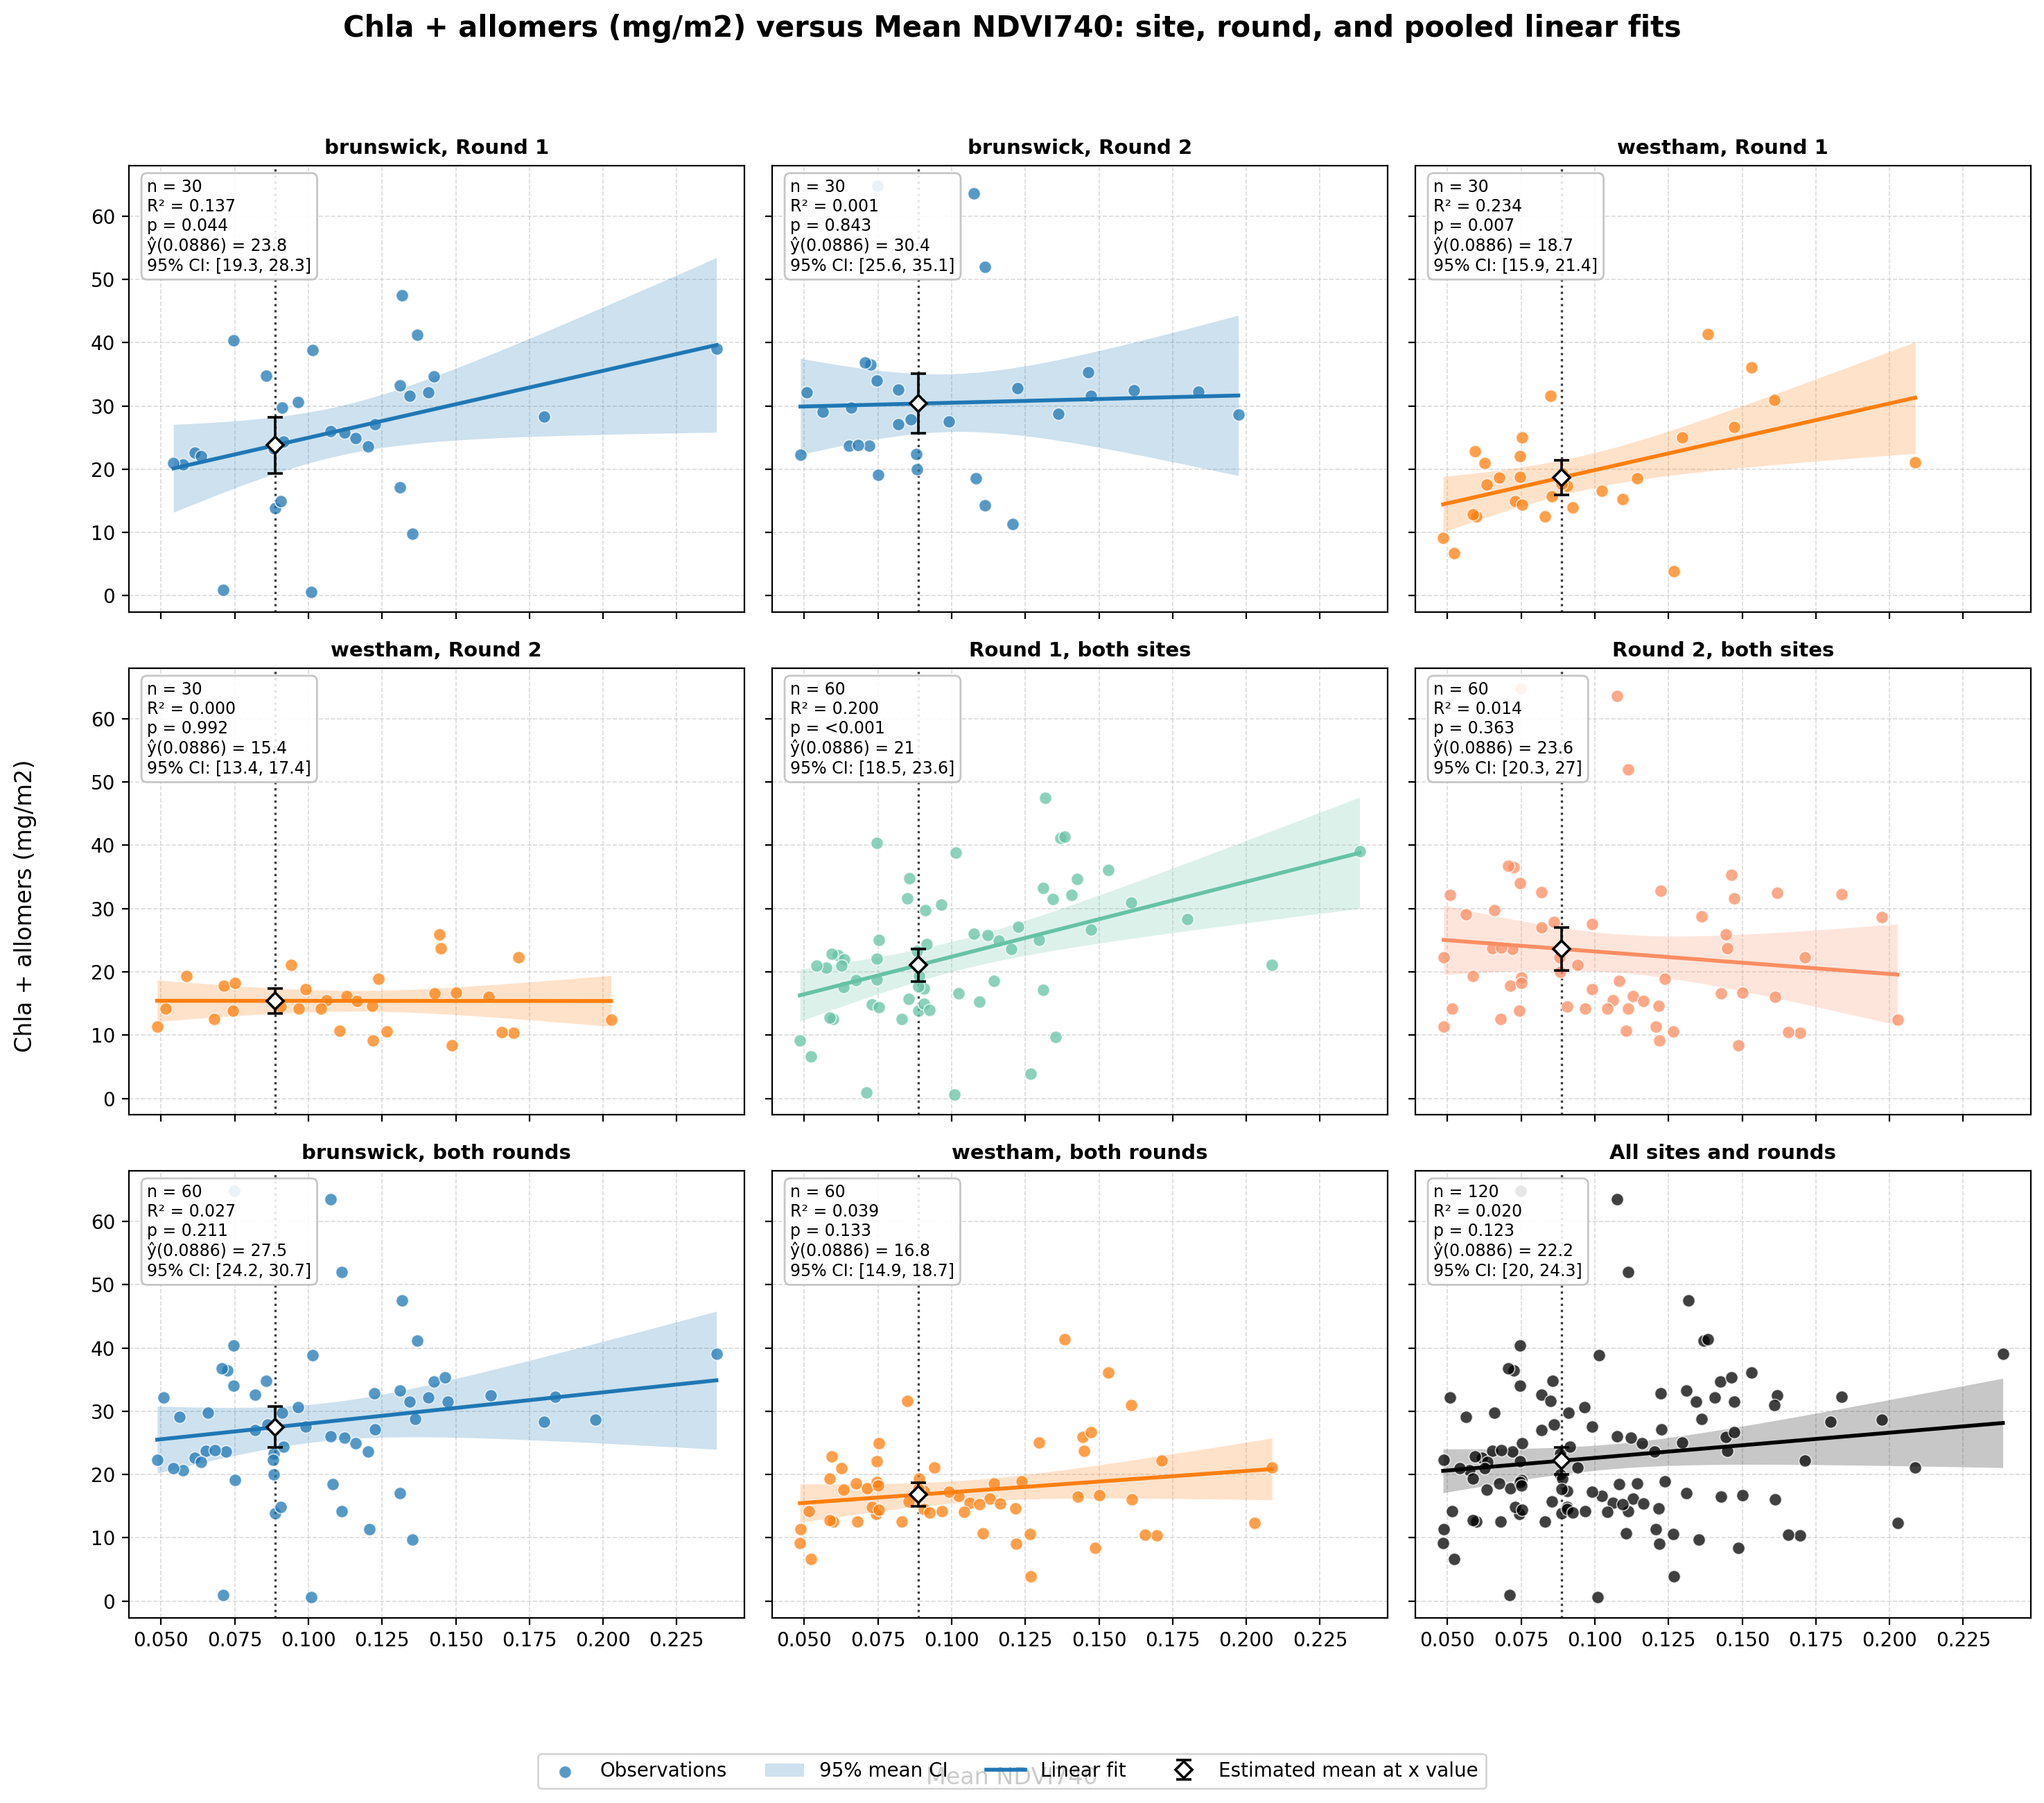

,scope,site,round,n,x_value,mean_y_at_x,mean_y_ci_lower,mean_y_ci_upper,is_extrapolation
0,site-round,brunswick,1.0,30,0.0886,23.773729,19.291739,28.255718,False
1,site-round,brunswick,2.0,30,0.0886,30.376592,25.634803,35.118381,False
2,site-round,westham,1.0,30,0.0886,18.672464,15.898981,21.445946,False
3,site-round,westham,2.0,30,0.0886,15.421946,13.423395,17.420496,False
4,round,None,1.0,60,0.0886,21.044556,18.511028,23.578084,False
5,round,None,2.0,60,0.0886,23.629807,20.257089,27.002524,False
6,site,brunswick,NaN,60,0.0886,27.477333,24.229887,30.724780,False
7,site,westham,NaN,60,0.0886,16.815308,14.928394,18.702221,False
8,global,None,NaN,120,0.0886,22.171365,20.033413,24.309318,False


In [27]:
fig, axes, fit_results = grouped_linear_fits(
    df_combined_R,
    x="NDVI740_mean",
    y="Chla + allomers (mg/m2)",
    x_value=0.0886,
    site_order=["brunswick", "westham"],
    round_order=[1, 2],
    confidence_level=0.95,
    x_label="Mean NDVI740",
    y_label="Chla + allomers (mg/m2)",
)

plt.show()

prediction_results = fit_results[
    [
        "scope",
        "site",
        "round",
        "n",
        "x_value",
        "mean_y_at_x",
        "mean_y_ci_lower",
        "mean_y_ci_upper",
        "is_extrapolation",
    ]
]

prediction_results

# Mass Distribution

<Axes: >

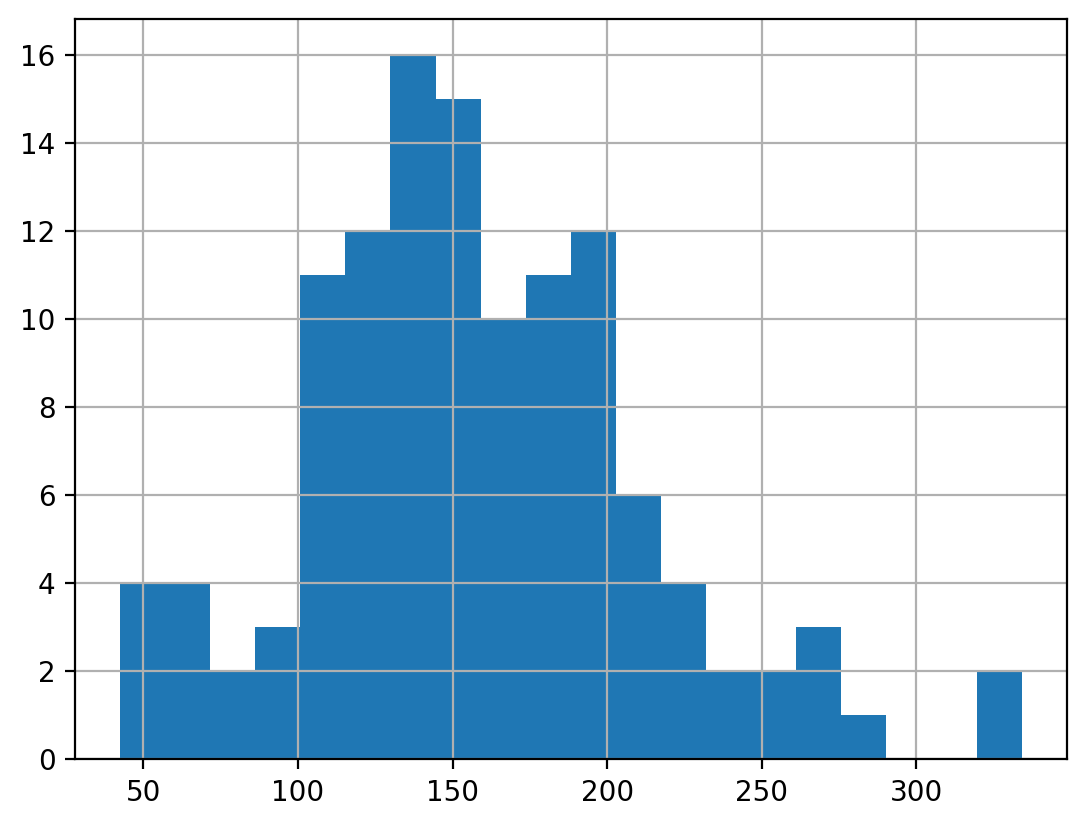

In [28]:
df_combined_R['Sample Total Dry Mass (g)'].hist(bins=20)

# OLD

In [29]:
def compute_correlations(df, columns=None, method="pearson"):
    """
    Compute correlations among selected numeric columns.

    Parameters
    ----------
    df : pandas.DataFrame
        Input data.

    columns : list[str] or None, default=None
        Columns to consider. If None, all columns are considered.
        Only numeric columns are included in the result.

    method : {"pearson", "spearman", "kendall"} or callable
        Correlation method.

    Returns
    -------
    pandas.DataFrame
        Correlation matrix.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if columns is not None:
        missing_columns = [col for col in columns if col not in df.columns]

        if missing_columns:
            raise ValueError(
                f"Columns not found in the DataFrame: {missing_columns}"
            )

        data = df.loc[:, columns]
    else:
        data = df

    numeric_data = data.select_dtypes(include=np.number)

    if numeric_data.shape[1] < 2:
        raise ValueError(
            "At least two numeric columns are required "
            "to compute correlations."
        )

    return numeric_data.corr(method=method)

def get_strongest_relationships(correlation_matrix, n=10):
    """
    Return the n strongest unique relationships from a correlation matrix.

    Relationships are ranked by absolute correlation, while preserving the
    original signed correlation value.

    Parameters
    ----------
    correlation_matrix : pandas.DataFrame
        Square correlation matrix.

    n : int, default=10
        Number of relationships to return.

    Returns
    -------
    pandas.DataFrame
        Columns:
        - column_1
        - column_2
        - correlation
        - absolute_correlation
    """
    if not isinstance(correlation_matrix, pd.DataFrame):
        raise TypeError("correlation_matrix must be a pandas DataFrame.")

    if correlation_matrix.shape[0] != correlation_matrix.shape[1]:
        raise ValueError("correlation_matrix must be square.")

    if list(correlation_matrix.index) != list(correlation_matrix.columns):
        raise ValueError("The correlation matrix index and columns must match.")

    if not isinstance(n, int) or n < 1:
        raise ValueError("n must be a positive integer.")

    # Select only the upper triangle to exclude self-correlations
    # and duplicate pairs.
    upper_triangle = np.triu(
        np.ones(correlation_matrix.shape, dtype=bool),
        k=1,
    )

    relationships = (
        correlation_matrix.where(upper_triangle)
        .stack()
        .rename("correlation")
        .reset_index()
        .rename(
            columns={
                "level_0": "column_1",
                "level_1": "column_2",
            }
        )
    )

    relationships["absolute_correlation"] = relationships["correlation"].abs()

    return (
        relationships.sort_values("absolute_correlation", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )


In [30]:
# pigment_columns = [f'{col} : Chla + allomers' for col in PIGMENT_LIST]
# pigment_columns

# # Compute the correlation matrix
# correlations = compute_correlations(
#     df_combined,
#     columns=pigment_columns,
#     # method="spearman",
# )

# # Get the 5 strongest unique relationships
# strongest = get_strongest_relationships(correlations, n=5)
# print(strongest)

# Analysis (sample_type == R only)


In [31]:
df_lab_r = df_combined_R #df_lab.xs("R", level="sample_type") -> To match new case
df_lab_r

Sample Total Dry Mass (g)  \
site      station_id round                              
brunswick B1         1                     124.920787   
                     2                     102.318373   
          B10        1                     113.372704   
                     2                     135.840106   
          B11        1                      68.488373   
...                                               ...   
westham   W7         2                     161.405260   
          W8         1                     198.150482   
                     2                     176.165261   
          W9         1                     216.772129   
                     2                     129.403085   

                            Extraction Dry Mass (mg)  Area Sampled (m2)  \
site      station_id round                                                
brunswick B1         1                         554.2              0.082   
                     2                         512.4              0.082   
          B10        1                         460.8              0.082   
                     2                         582.7              0.082   
          B11        1                         480.4              0.082   
...                                              ...                ...   
westham   W7         2                         578.8              0.082   
          W8         1                         418.1              0.082   
                     2                         502.5              0.082   
          W9         1                         450.8              0.082   
                     2                         419.4              0.082   

                            /g to /m2 Conversion Factor (g/m2)  Moisture (%)  \
site      station_id round                                                     
brunswick B1         1                             1523.424232     55.812630   
                     2                             1247.785032     46.904693   
          B10        1                             1382.593955     53.288243   
                     2                             1656.586662     45.619801   
          B11        1                              835.224056     60.344183   
...                                                        ...           ...   
westham   W7         2                             1968.356830     40.595840   
          W8         1                             2416.469294     38.021225   
                     2                             2148.356839     40.425739   
          W9         1                             2643.562546     34.253101   
                     2                             1578.086407     47.334392   

                            Percent Sand (%)  Percent Silt (%)  \
site      station_id round                                       
brunswick B1         1             91.182365          7.815631   
                     2             73.170732         26.829268   
          B10        1             73.684211         25.263158   
                     2             86.597938         11.340206   
          B11        1             71.232877         27.397260   
...                                      ...               ...   
westham   W7         2             80.459770         13.793103   
          W8         1             85.393258         12.359551   
                     2             69.019608         29.607843   
          W9         1             57.009346         41.121495   
                     2             63.157895         31.578947   

                            Percent Clay (%) Sample Date  \
site      station_id round                                 
brunswick B1         1              1.002004  2026-05-03   
                     2              0.000000  2026-05-16   
          B10        1              1.052632  2026-05-01   
                     2              2.061856  2026-05-17   
          B11        1              1.369863  2026

## Boxplots

In [32]:
df_lab_r['Chla + allomers (mg/m2)'].groupby(['round']).agg(['mean', 'std'])

,mean,std
round,,
1,22.688494,10.219064
2,22.958465,11.738901


In [33]:
def draw_boxplots(
    df,
    variables,
    round_number,
    title=None,
    figsize=(12, 8),
    sites=SITES,
    site_colors=SITE_COLORS,
    site_labels=SITE_LABELS,
    y_scale="linear",
    show_y_grid=True,
    annotate_outliers=True,
    outlier_fontsize=8,
    variable_labels=None,
    y_label=None,
    share_y=True,
    y_min=None,
    y_max=None,
):
    """
    Draw grouped boxplots for one or more survey rounds.

    When multiple rounds are supplied, the plots are stacked vertically.
    They share the x-axis, and x-axis labels are displayed only on the
    bottom panel.

    Parameters
    ----------
    df : pandas.DataFrame
        Input DataFrame. Its index must contain "round" and "station_id".
    variables : list of str
        Variables to plot.
    round_number : int or sequence of int
        One round, such as 1, or multiple rounds, such as [1, 2].
    title : str, optional
        Overall figure title.
    figsize : tuple, default (12, 8)
        Size of the complete figure.
    sites : sequence
        Site identifiers in the desired plotting order.
    site_colors : dict or sequence
        Colors associated with the sites.
    site_labels : dict or sequence, optional
        Display labels associated with the sites.
    y_scale : {"linear", "log", "symlog"}, default "linear"
        Y-axis scale.
    show_y_grid : bool, default True
        Whether to display horizontal grid lines.
    annotate_outliers : bool, default True
        Whether to annotate outliers with station IDs.
    outlier_fontsize : float, default 8
        Font size for outlier annotations.
    variable_labels : list of str, optional
        Labels to display along the x-axis.
    y_label : str, optional
        Common y-axis label.
    share_y : bool, default True
        Whether all round panels use the same y-axis limits.
    """

    # ------------------------------------------------------------------
    # Normalize round_number to a list
    # ------------------------------------------------------------------
    if isinstance(round_number, (list, tuple)):
        round_numbers = list(round_number)
    else:
        round_numbers = [round_number]

    if not round_numbers:
        raise ValueError("At least one round number must be provided.")

    if len(set(round_numbers)) != len(round_numbers):
        raise ValueError("Duplicate round numbers were provided.")

    # ------------------------------------------------------------------
    # Validate inputs
    # ------------------------------------------------------------------
    if not variables:
        raise ValueError("At least one variable must be provided.")

    valid_scales = {
        "linear",
        "log",
        "symlog",
    }

    if y_scale not in valid_scales:
        raise ValueError(
            f"y_scale must be one of {valid_scales}; received {y_scale!r}."
        )

    if variable_labels is not None:
        if len(variable_labels) != len(variables):
            raise ValueError(
                "The length of variable_labels must match the length "
                f"of variables. Received {len(variable_labels)} labels "
                f"for {len(variables)} variables."
            )

    if sites is None:
        if isinstance(site_colors, dict):
            sites = list(site_colors)
        else:
            raise ValueError(
                "Provide 'sites', or provide 'site_colors' as a "
                "dictionary whose keys are the site identifiers."
            )

    sites = list(sites)

    if site_colors is None:
        raise ValueError("'site_colors' must be provided.")

    missing_variables = [
        variable for variable in variables if variable not in df.columns
    ]

    if missing_variables:
        raise KeyError(
            "The following variables were not found in the DataFrame: "
            f"{missing_variables}"
        )

    required_index_levels = {
        "round",
        "station_id",
    }

    available_index_levels = set(df.index.names)

    missing_index_levels = required_index_levels - available_index_levels

    if missing_index_levels:
        raise KeyError(
            "The DataFrame index is missing the following required "
            f"level(s): {sorted(missing_index_levels)}"
        )

    # ------------------------------------------------------------------
    # Create color and label dictionaries
    # ------------------------------------------------------------------
    if isinstance(site_colors, dict):
        color_map = site_colors.copy()
    else:
        color_map = dict(zip(sites, site_colors))

    if site_labels is None:
        label_map = {site: str(site) for site in sites}
    elif isinstance(site_labels, dict):
        label_map = site_labels.copy()
    else:
        label_map = dict(zip(sites, site_labels))

    color_map.setdefault(
        "Unknown",
        "lightgray",
    )

    label_map.setdefault(
        "Unknown",
        "Unknown",
    )

    # ------------------------------------------------------------------
    # Prepare the data for every round
    # ------------------------------------------------------------------
    round_data = []
    all_observed_sites = set()

    for current_round in round_numbers:
        try:
            df_filtered = df.xs(
                current_round,
                level="round",
            )
        except KeyError as error:
            raise KeyError(
                f"Round {current_round!r} was not found in the DataFrame."
            ) from error

        df_plot = df_filtered[variables].copy()

        # Preserve station IDs for annotations
        df_plot["station_id"] = df_plot.index.get_level_values("station_id").astype(str)

        # Assign each station to a site
        df_plot["site"] = df_plot["station_id"].map(
            lambda station_id: next(
                (site for site in sites if station_id.startswith(str(site)[0].upper())),
                "Unknown",
            )
        )

        all_observed_sites.update(df_plot["site"].dropna())

        # Reshape from wide to long
        df_long = df_plot.melt(
            id_vars=[
                "station_id",
                "site",
            ],
            value_vars=variables,
            var_name="variable",
            value_name="value",
        ).dropna(subset=["value"])

        if df_long.empty:
            raise ValueError(
                f"No non-missing observations were found for round {current_round}."
            )

        # Calculate outliers within each variable-site group
        grouped_values = df_long.groupby(
            [
                "variable",
                "site",
            ],
            observed=True,
        )["value"]

        q1 = grouped_values.transform(lambda values: values.quantile(0.25))

        q3 = grouped_values.transform(lambda values: values.quantile(0.75))

        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        outlier_mask = (df_long["value"] < lower_limit) | (
            df_long["value"] > upper_limit
        )

        df_outliers = df_long.loc[outlier_mask].copy()

        round_data.append(
            {
                "round": current_round,
                "data": df_long,
                "outliers": df_outliers,
            }
        )

    # ------------------------------------------------------------------
    # Determine the common site order
    # ------------------------------------------------------------------
    site_order = [site for site in sites if site in all_observed_sites]

    if "Unknown" in all_observed_sites:
        site_order.append("Unknown")

    if not site_order:
        raise ValueError("No site data were found for the selected rounds.")

    missing_colors = [site for site in site_order if site not in color_map]

    if missing_colors:
        raise KeyError(
            f"No colors were provided for the following sites: {missing_colors}"
        )

    # ------------------------------------------------------------------
    # Validate values for the selected y-axis scale
    # ------------------------------------------------------------------
    zero_count = sum(int((item["data"]["value"] == 0).sum()) for item in round_data)

    negative_count = sum(int((item["data"]["value"] < 0).sum()) for item in round_data)

    # if y_scale == "log" and (zero_count or negative_count):
    #     raise ValueError(
    #         "A true logarithmic scale cannot display zero or "
    #         f"negative values. Found {zero_count} zero value(s) and "
    #         f"{negative_count} negative value(s). Use "
    #         "y_scale='symlog' to retain zero values."
    #     )

    if y_scale == "symlog" and negative_count:
        raise ValueError(
            f"Found {negative_count} negative value(s). Although "
            "symlog can display negative values, negative pigment "
            "measurements should be reviewed before plotting."
        )

    # Determine a common symlog threshold when y-axes are shared
    positive_minimum = None

    if y_scale == "symlog":
        positive_minimums = []

        for item in round_data:
            positive_values = item["data"].loc[
                item["data"]["value"] > 0,
                "value",
            ]

            if not positive_values.empty:
                positive_minimums.append(positive_values.min())

        if positive_minimums:
            positive_minimum = min(positive_minimums)

    # ------------------------------------------------------------------
    # Prepare x-axis labels
    # ------------------------------------------------------------------
    if variable_labels is None:
        displayed_variable_labels = [
            (variable.rsplit(" (", 1)[0] if " (" in variable else variable)
            for variable in variables
        ]
    else:
        displayed_variable_labels = list(variable_labels)

    # Determine the y-axis label
    if y_label is not None:
        displayed_y_label = y_label
    else:
        first_variable = variables[0]

        if "(" in first_variable:
            displayed_y_label = first_variable.rsplit("(", 1)[-1].rstrip(")")
        else:
            displayed_y_label = "Value"

    # ------------------------------------------------------------------
    # Create vertically stacked axes
    # ------------------------------------------------------------------
    number_of_rounds = len(round_numbers)

    fig, axes = plt.subplots(
        nrows=number_of_rounds,
        ncols=1,
        figsize=figsize,
        sharex=True,
        sharey=share_y,
        squeeze=False,
    )

    axes = axes[:, 0]

    box_width = 0.8
    minor_subs = (
        2,
        3,
        4,
        5,
        6,
        7,
        8,
        9,
    )

    # Save annotation information for each axis
    annotation_groups = []

    # ------------------------------------------------------------------
    # Draw each round
    # ------------------------------------------------------------------
    for panel_index, (
        ax,
        item,
    ) in enumerate(zip(axes, round_data)):
        current_round = item["round"]
        df_long = item["data"]
        df_outliers = item["outliers"]

        # Draw boxplots without default outlier markers
        sns.boxplot(
            data=df_long,
            x="variable",
            y="value",
            hue="site",
            order=variables,
            hue_order=site_order,
            palette=color_map,
            width=box_width,
            dodge=True,
            showfliers=False,
            legend=False,
            ax=ax,
        )

        # Draw filled, site-colored outlier points
        if not df_outliers.empty:
            sns.stripplot(
                data=df_outliers,
                x="variable",
                y="value",
                hue="site",
                order=variables,
                hue_order=site_order,
                palette=color_map,
                dodge=True,
                jitter=False,
                marker="o",
                size=5.5,
                edgecolor="black",
                linewidth=0.7,
                alpha=0.9,
                legend=False,
                ax=ax,
                zorder=4,
            )

        # --------------------------------------------------------------
        # Configure the y-axis scale
        # --------------------------------------------------------------
        actual_y_scale = y_scale

        if y_scale == "linear":
            ax.set_yscale("linear")

        elif y_scale == "log":
            ax.set_yscale(
                "log",
                base=10,
            )

            ax.yaxis.set_minor_locator(
                LogLocator(
                    base=10,
                    subs=minor_subs,
                    numticks=100,
                )
            )

            ax.yaxis.set_minor_formatter(NullFormatter())

        elif y_scale == "symlog":
            if share_y:
                linthresh = positive_minimum
            else:
                positive_values = df_long.loc[
                    df_long["value"] > 0,
                    "value",
                ]

                if positive_values.empty:
                    linthresh = None
                else:
                    linthresh = positive_values.min()

            if linthresh is None:
                ax.set_yscale("linear")

                actual_y_scale = "linear"

            else:
                ax.set_yscale(
                    "symlog",
                    base=10,
                    linthresh=linthresh,
                    subs=minor_subs,
                )

                ax.yaxis.get_minor_locator().set_params(subs=minor_subs)

                ax.yaxis.set_minor_formatter(NullFormatter())

        # Add vertical room for annotations
        ax.margins(y=0.1)

        # Prevent nonnegative linear/symlog plots extending below zero
        if y_min is not None:
            ax.set_ylim(bottom=y_min)
        if y_max is not None:
            ax.set_ylim(top=y_max)
        elif actual_y_scale != "log" and (df_long["value"] >= 0).all():
            ax.set_ylim(bottom=0)

        # --------------------------------------------------------------
        # Configure grid lines
        # --------------------------------------------------------------
        ax.set_axisbelow(True)

        if show_y_grid:
            ax.grid(
                visible=True,
                axis="y",
                which="major",
                linestyle="--",
                linewidth=0.8,
                color="gray",
                alpha=0.5,
            )

            if actual_y_scale in {
                "log",
                "symlog",
            }:
                ax.grid(
                    visible=True,
                    axis="y",
                    which="minor",
                    linestyle=":",
                    linewidth=0.6,
                    color="gray",
                    alpha=0.4,
                )
        else:
            ax.grid(
                visible=False,
                axis="y",
                which="both",
            )

        # --------------------------------------------------------------
        # Round label
        # --------------------------------------------------------------
        if number_of_rounds > 1:
            ax.set_title(
                f"Round {current_round}",
                loc="left",
                fontsize=10,
                fontweight="bold",
            )
        elif title is None:
            ax.set_title(f"Round {current_round}")

        ax.set_xlabel("")

        # Use one common y-axis label for multiple panels
        if number_of_rounds == 1:
            ax.set_ylabel(displayed_y_label)
        else:
            ax.set_ylabel("")

        # --------------------------------------------------------------
        # Create outlier annotation text
        # --------------------------------------------------------------
        outlier_texts = []
        outlier_x_positions = []
        outlier_y_positions = []

        if annotate_outliers and not df_outliers.empty:
            number_of_sites = len(site_order)

            site_offsets = {
                site: ((site_index + 0.5) * box_width / number_of_sites - box_width / 2)
                for site_index, site in enumerate(site_order)
            }

            variable_positions = {
                variable: index for index, variable in enumerate(variables)
            }

            for _, row in df_outliers.iterrows():
                x_position = (
                    variable_positions[row["variable"]] + site_offsets[row["site"]]
                )

                y_position = row["value"]

                outlier_x_positions.append(x_position)

                outlier_y_positions.append(y_position)

                text = ax.text(
                    x_position,
                    y_position,
                    str(row["station_id"]),
                    ha="center",
                    va="bottom",
                    fontsize=outlier_fontsize,
                    color="black",
                    zorder=5,
                )

                outlier_texts.append(text)

        annotation_groups.append(
            {
                "ax": ax,
                "texts": outlier_texts,
                "x": outlier_x_positions,
                "y": outlier_y_positions,
            }
        )

        # Hide x-axis labels on every panel except the bottom one
        is_bottom_panel = panel_index == number_of_rounds - 1

        ax.tick_params(
            axis="x",
            labelbottom=is_bottom_panel,
        )

    # ------------------------------------------------------------------
    # Configure the shared x-axis on the bottom panel only
    # ------------------------------------------------------------------
    bottom_ax = axes[-1]

    bottom_ax.set_xticks(range(len(variables)))

    bottom_ax.set_xticklabels(displayed_variable_labels)

    if len(variables) > 4:
        plt.setp(
            bottom_ax.get_xticklabels(),
            rotation=45,
            ha="right",
            rotation_mode="anchor",
        )

    # Common y-axis label for multiple panels
    if number_of_rounds > 1:
        fig.supylabel(displayed_y_label)

    # ------------------------------------------------------------------
    # Create the common site legend
    # ------------------------------------------------------------------
    legend_handles = [
        Patch(
            facecolor=color_map[site],
            edgecolor="black",
            label=label_map.get(
                site,
                site,
            ),
        )
        for site in site_order
    ]

    fig.legend(
        handles=legend_handles,
        title="Survey Area",
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            0.01,
        ),
        ncol=max(
            1,
            len(legend_handles),
        ),
        frameon=False,
    )

    # Overall title for multiple rounds
    if title:
        if number_of_rounds > 1:
            fig.suptitle(
                title,
                y=0.98
            )

        else:
            axes[0].set_title(title)

    # Finalize layout before adjusting annotations
    top_position = (
        1
        if title and number_of_rounds > 1
        else 1
    )

    fig.tight_layout(
        rect=(
            0.02,
            0.05,
            1,
            top_position,
        )
    )

    fig.canvas.draw()

    # ------------------------------------------------------------------
    # Automatically adjust annotations independently on each panel
    # ------------------------------------------------------------------
    for annotation_group in annotation_groups:
        texts = annotation_group["texts"]

        if not texts:
            continue

        adjust_text(
            texts,
            x=annotation_group["x"],
            y=annotation_group["y"],
            target_x=annotation_group["x"],
            target_y=annotation_group["y"],
            ax=annotation_group["ax"],
            expand=(1.2, 1.4),
            force_text=(0.2, 0.3),
            force_static=(0.1, 0.2),
            force_pull=(0.01, 0.02),
            force_explode=(0.1, 0.4),
            max_move=(8, 20),
            ensure_inside_axes=True,
            prevent_crossings=True,
            min_arrow_len=4,
            arrowprops={
                "arrowstyle": "-",
                "color": "0.35",
                "linewidth": 0.7,
                "alpha": 0.8,
            },
        )

    # plt.show()

    if number_of_rounds == 1:
        return fig, axes[0]

    return fig, axes


In [34]:
def draw_boxplots_2(
    df,
    variables,
    round_number,
    title=None,
    figsize=(12, 8),
    sites=SITES,
    site_colors=SITE_COLORS,
    site_labels=SITE_LABELS,
    y_scale="linear",
    show_y_grid=True,
    annotate_outliers=True,
    outlier_fontsize=8,
    variable_labels=None,
    y_label=None,
    share_y=True,
    round_layout="vertical",
    round_separator=True,
    round_separator_kwargs=None,
    show_x_tick_labels=True,
    y_min=None,
):
    """
    Draw grouped boxplots for one or more survey rounds.

    Parameters
    ----------
    round_layout : {"vertical", "horizontal"}, default "vertical"
        - "vertical": existing behavior (one row per round).
        - "horizontal": one axis where rounds are separated across x positions.
    round_separator : bool, default True
        Whether to draw vertical separators between rounds in horizontal layout.
    round_separator_kwargs : dict, optional
        Styling kwargs passed to matplotlib Axes.axvline for round separators.
    show_x_tick_labels : bool, default True
        Whether to display x-axis tick labels in horizontal layout.
    """

    # ------------------------------------------------------------------
    # Normalize round_number and validate the layout option
    # ------------------------------------------------------------------
    if isinstance(round_number, (list, tuple)):
        round_numbers = list(round_number)
    else:
        round_numbers = [round_number]

    if not round_numbers:
        raise ValueError("At least one round number must be provided.")

    if len(set(round_numbers)) != len(round_numbers):
        raise ValueError("Duplicate round numbers were provided.")

    valid_layouts = {"vertical", "horizontal"}
    if round_layout not in valid_layouts:
        raise ValueError(
            f"round_layout must be one of {valid_layouts}; received {round_layout!r}."
        )

    # ------------------------------------------------------------------
    # Keep existing behavior for vertical layout (or single round)
    # ------------------------------------------------------------------
    if round_layout == "vertical" or len(round_numbers) == 1:
        return draw_boxplots(
            df=df,
            variables=variables,
            round_number=round_number,
            title=title,
            figsize=figsize,
            sites=sites,
            site_colors=site_colors,
            site_labels=site_labels,
            y_scale=y_scale,
            show_y_grid=show_y_grid,
            annotate_outliers=annotate_outliers,
            outlier_fontsize=outlier_fontsize,
            variable_labels=variable_labels,
            y_label=y_label,
            share_y=share_y
        )

    # ------------------------------------------------------------------
    # Validate inputs for horizontal layout
    # ------------------------------------------------------------------
    if not variables:
        raise ValueError("At least one variable must be provided.")

    valid_scales = {"linear", "log", "symlog"}
    if y_scale not in valid_scales:
        raise ValueError(
            f"y_scale must be one of {valid_scales}; received {y_scale!r}."
        )

    if variable_labels is not None and len(variable_labels) != len(variables):
        raise ValueError(
            "The length of variable_labels must match the length "
            f"of variables. Received {len(variable_labels)} labels "
            f"for {len(variables)} variables."
        )

    if sites is None:
        if isinstance(site_colors, dict):
            sites = list(site_colors)
        else:
            raise ValueError(
                "Provide 'sites', or provide 'site_colors' as a "
                "dictionary whose keys are the site identifiers."
            )

    sites = list(sites)

    if site_colors is None:
        raise ValueError("'site_colors' must be provided.")

    missing_variables = [variable for variable in variables if variable not in df.columns]
    if missing_variables:
        raise KeyError(
            "The following variables were not found in the DataFrame: "
            f"{missing_variables}"
        )

    required_index_levels = {"round", "station_id"}
    available_index_levels = set(df.index.names)
    missing_index_levels = required_index_levels - available_index_levels
    if missing_index_levels:
        raise KeyError(
            "The DataFrame index is missing the following required "
            f"level(s): {sorted(missing_index_levels)}"
        )

    # ------------------------------------------------------------------
    # Create color and label dictionaries
    # ------------------------------------------------------------------
    if isinstance(site_colors, dict):
        color_map = site_colors.copy()
    else:
        color_map = dict(zip(sites, site_colors))

    if site_labels is None:
        label_map = {site: str(site) for site in sites}
    elif isinstance(site_labels, dict):
        label_map = site_labels.copy()
    else:
        label_map = dict(zip(sites, site_labels))

    color_map.setdefault("Unknown", "lightgray")
    label_map.setdefault("Unknown", "Unknown")

    # ------------------------------------------------------------------
    # Prepare x labels
    # ------------------------------------------------------------------
    if variable_labels is None:
        displayed_variable_labels = [
            (variable.rsplit(" (", 1)[0] if " (" in variable else variable)
            for variable in variables
        ]
    else:
        displayed_variable_labels = list(variable_labels)

    if y_label is not None:
        displayed_y_label = y_label
    else:
        first_variable = variables[0]
        if "(" in first_variable:
            displayed_y_label = first_variable.rsplit("(", 1)[-1].rstrip(")")
        else:
            displayed_y_label = "Value"

    # ------------------------------------------------------------------
    # Build per-round long data and outlier tables
    # ------------------------------------------------------------------
    all_observed_sites = set()
    all_round_long = []
    all_round_outliers = []

    for current_round in round_numbers:
        try:
            df_filtered = df.xs(current_round, level="round")
        except KeyError as error:
            raise KeyError(
                f"Round {current_round!r} was not found in the DataFrame."
            ) from error

        df_plot = df_filtered[variables].copy()
        df_plot["station_id"] = df_plot.index.get_level_values("station_id").astype(str)

        df_plot["site"] = df_plot["station_id"].map(
            lambda station_id: next(
                (site for site in sites if station_id.startswith(str(site)[0].upper())),
                "Unknown",
            )
        )

        all_observed_sites.update(df_plot["site"].dropna())

        df_long = df_plot.melt(
            id_vars=["station_id", "site"],
            value_vars=variables,
            var_name="variable",
            value_name="value",
        ).dropna(subset=["value"])

        if df_long.empty:
            raise ValueError(
                f"No non-missing observations were found for round {current_round}."
            )

        df_long["round"] = current_round
        df_long["round_variable"] = df_long["variable"].map(
            lambda variable: f"round_{current_round}__{variable}"
        )

        grouped_values = df_long.groupby(["variable", "site"], observed=True)["value"]
        q1 = grouped_values.transform(lambda values: values.quantile(0.25))
        q3 = grouped_values.transform(lambda values: values.quantile(0.75))
        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr
        outlier_mask = (df_long["value"] < lower_limit) | (df_long["value"] > upper_limit)

        df_outliers = df_long.loc[outlier_mask].copy()

        all_round_long.append(df_long)
        all_round_outliers.append(df_outliers)

    site_order = [site for site in sites if site in all_observed_sites]
    if "Unknown" in all_observed_sites:
        site_order.append("Unknown")

    if not site_order:
        raise ValueError("No site data were found for the selected rounds.")

    missing_colors = [site for site in site_order if site not in color_map]
    if missing_colors:
        raise KeyError(
            f"No colors were provided for the following sites: {missing_colors}"
        )

    df_long_all = pd.concat(all_round_long, ignore_index=True)
    df_outliers_all = pd.concat(all_round_outliers, ignore_index=True)

    zero_count = int((df_long_all["value"] == 0).sum())
    negative_count = int((df_long_all["value"] < 0).sum())

    if y_scale == "log" and (zero_count or negative_count):
        raise ValueError(
            "A true logarithmic scale cannot display zero or "
            f"negative values. Found {zero_count} zero value(s) and "
            f"{negative_count} negative value(s). Use "
            "y_scale='symlog' to retain zero values."
        )

    if y_scale == "symlog" and negative_count:
        raise ValueError(
            f"Found {negative_count} negative value(s). Although "
            "symlog can display negative values, negative pigment "
            "measurements should be reviewed before plotting."
        )

    positive_minimum = None
    if y_scale == "symlog":
        positive_values = df_long_all.loc[df_long_all["value"] > 0, "value"]
        if not positive_values.empty:
            positive_minimum = positive_values.min()

    # ------------------------------------------------------------------
    # Build x order as round blocks laid out left-to-right
    # ------------------------------------------------------------------
    x_order = []
    x_ticklabels = []

    for current_round in round_numbers:
        for variable, variable_label in zip(variables, displayed_variable_labels):
            x_order.append(f"round_{current_round}__{variable}")
            x_ticklabels.append(variable_label)

    fig, ax = plt.subplots(figsize=figsize)

    box_width = 0.8
    minor_subs = (2, 3, 4, 5, 6, 7, 8, 9)

    sns.boxplot(
        data=df_long_all,
        x="round_variable",
        y="value",
        hue="site",
        order=x_order,
        hue_order=site_order,
        palette=color_map,
        width=box_width,
        dodge=True,
        showfliers=False,
        legend=False,
        ax=ax,
    )

    if not df_outliers_all.empty:
        sns.stripplot(
            data=df_outliers_all,
            x="round_variable",
            y="value",
            hue="site",
            order=x_order,
            hue_order=site_order,
            palette=color_map,
            dodge=True,
            jitter=False,
            marker="o",
            size=5.5,
            edgecolor="black",
            linewidth=0.7,
            alpha=0.9,
            legend=False,
            ax=ax,
            zorder=4,
        )

    # ------------------------------------------------------------------
    # Configure y scale
    # ------------------------------------------------------------------
    actual_y_scale = y_scale

    if y_scale == "linear":
        ax.set_yscale("linear")

    elif y_scale == "log":
        ax.set_yscale("log", base=10)
        ax.yaxis.set_minor_locator(LogLocator(base=10, subs=minor_subs, numticks=100))
        ax.yaxis.set_minor_formatter(NullFormatter())

    elif y_scale == "symlog":
        if positive_minimum is None:
            ax.set_yscale("linear")
            actual_y_scale = "linear"
        else:
            ax.set_yscale("symlog", base=10, linthresh=positive_minimum, subs=minor_subs)
            ax.yaxis.get_minor_locator().set_params(subs=minor_subs)
            ax.yaxis.set_minor_formatter(NullFormatter())

    ax.margins(y=0.12)
    if actual_y_scale != "log" and (df_long_all["value"] >= 0).all():
        ax.set_ylim(bottom=0)

    # ------------------------------------------------------------------
    # Configure grid lines
    # ------------------------------------------------------------------
    ax.set_axisbelow(True)

    if show_y_grid:
        ax.grid(
            visible=True,
            axis="y",
            which="major",
            linestyle="--",
            linewidth=0.8,
            color="gray",
            alpha=0.5,
        )

        if actual_y_scale in {"log", "symlog"}:
            ax.grid(
                visible=True,
                axis="y",
                which="minor",
                linestyle=":",
                linewidth=0.6,
                color="gray",
                alpha=0.4,
            )
    else:
        ax.grid(visible=False, axis="y", which="both")

    # ------------------------------------------------------------------
    # X-axis labels and round separators / headers
    # ------------------------------------------------------------------
    ax.set_xticks(range(len(x_order)))

    if show_x_tick_labels:
        ax.set_xticklabels(x_ticklabels)

        if len(x_order) > 4:
            plt.setp(
                ax.get_xticklabels(),
                rotation=45,
                ha="right",
                rotation_mode="anchor",
            )
    else:
        ax.set_xticklabels(["" for _ in x_order])
        ax.tick_params(axis="x", length=0)

    # Draw separators between round blocks and place round labels above each block
    number_of_variables = len(variables)

    default_separator_kwargs = {
        "color": "0.35",
        "linestyle": "--",
        "linewidth": 1.0,
        "alpha": 0.9,
    }

    if round_separator_kwargs is not None:
        default_separator_kwargs.update(round_separator_kwargs)

    if round_separator:
        for split_index in range(1, len(round_numbers)):
            boundary_x = split_index * number_of_variables - 0.5
            ax.axvline(boundary_x, **default_separator_kwargs)

    y_round_label = 1.01
    for i, current_round in enumerate(round_numbers):
        start_x = i * number_of_variables
        end_x = (i + 1) * number_of_variables - 1
        center_x = (start_x + end_x) / 2

        ax.text(
            center_x,
            y_round_label,
            f"Round {current_round}",
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
        )

    ax.set_xlabel("")
    ax.set_ylabel(displayed_y_label)

    # ------------------------------------------------------------------
    # Outlier labels in horizontal round layout
    # ------------------------------------------------------------------
    outlier_texts = []
    outlier_x_positions = []
    outlier_y_positions = []

    if annotate_outliers and not df_outliers_all.empty:
        number_of_sites = len(site_order)

        site_offsets = {
            site: ((site_index + 0.5) * box_width / number_of_sites - box_width / 2)
            for site_index, site in enumerate(site_order)
        }

        round_variable_positions = {
            round_variable: index for index, round_variable in enumerate(x_order)
        }

        for _, row in df_outliers_all.iterrows():
            x_position = round_variable_positions[row["round_variable"]] + site_offsets[row["site"]]
            y_position = row["value"]

            outlier_x_positions.append(x_position)
            outlier_y_positions.append(y_position)

            text = ax.annotate(
                str(row["station_id"]),
                xy=(x_position, y_position),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=outlier_fontsize,
                color="black",
                zorder=6,
                clip_on=False,
            )
            outlier_texts.append(text)

    # ------------------------------------------------------------------
    # Legend and title
    # ------------------------------------------------------------------
    legend_handles = [
        Patch(
            facecolor=color_map[site],
            edgecolor="black",
            label=label_map.get(site, site),
        )
        for site in site_order
    ]

    fig.legend(
        handles=legend_handles,
        title="Survey Area",
        loc="lower center",
        bbox_to_anchor=(0.5, 0.01),
        ncol=max(1, len(legend_handles)),
        frameon=False,
    )

    if title:
        ax.set_title(title, pad=24)

    fig.tight_layout(rect=(0.02, 0.05, 1, 1))
    fig.canvas.draw()


    return fig, ax


### Pigments

In [35]:
CORE_PIGMENTS = [
    "Chla + allomers",
    # "Chla",
    "Chlb",
    "Fuco",
    "Ddx",
    "DVCh-a",
    "Zea",
]
CORE_PIGMENT_COMMUNITIES = {  # See TT2025 "A suite of 17 marker pigments..."
    "Chla + allomers": "Biofilm biomass",
    # "Chla": "Biofilm biomass",
    "Chlb": "Green Algae",
    "Fuco": "Diatoms",
    "Ddx": "Diatoms",
    "DVCh-a": "Cyanobacteria",
    "Zea": "Cyanobacteria",
}
CORE_PIGMENT_FULL_NAMES = {
    "Chla + allomers": "Chlorophyll a (+ allomers)",
    # "Chla": "Chlorophyll a",
    "Chlb": "Chlorophyll b",
    "Fuco": "Fucoxanthin",
    "Ddx": "Diadinoxanthin",
    "DVCh-a": "Divinyl Chlorophyll a",
    "Zea": "Zeaxanthin",
}

CORE_PIGMENT_FULL_LABELS = {}
for pigment, community in CORE_PIGMENT_COMMUNITIES.items():
    CORE_PIGMENT_FULL_LABELS[pigment] = f"{CORE_PIGMENT_FULL_NAMES[pigment]}\n({community})"


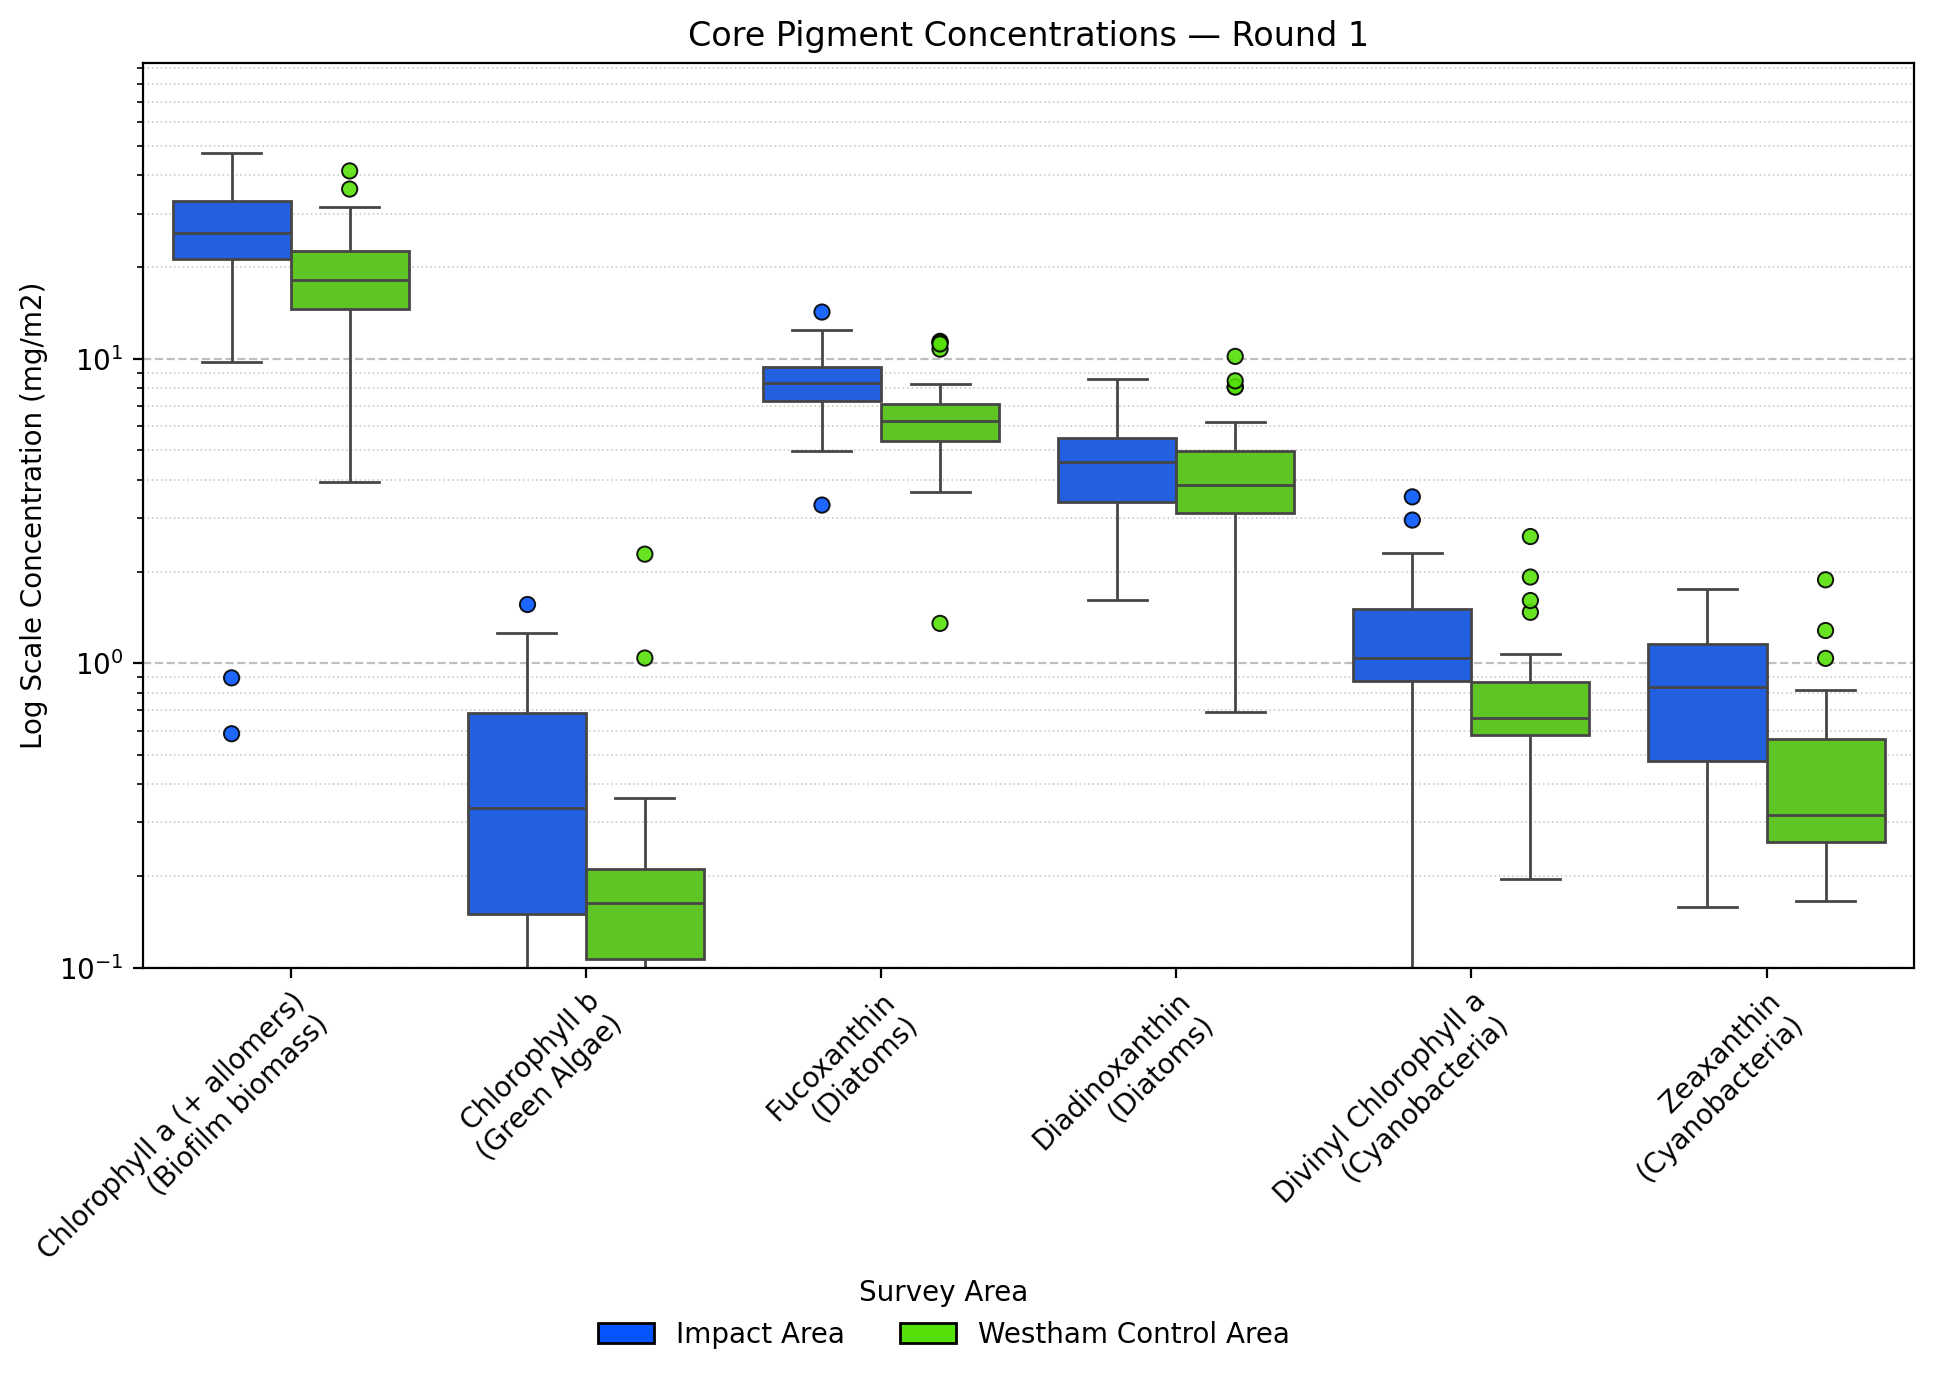

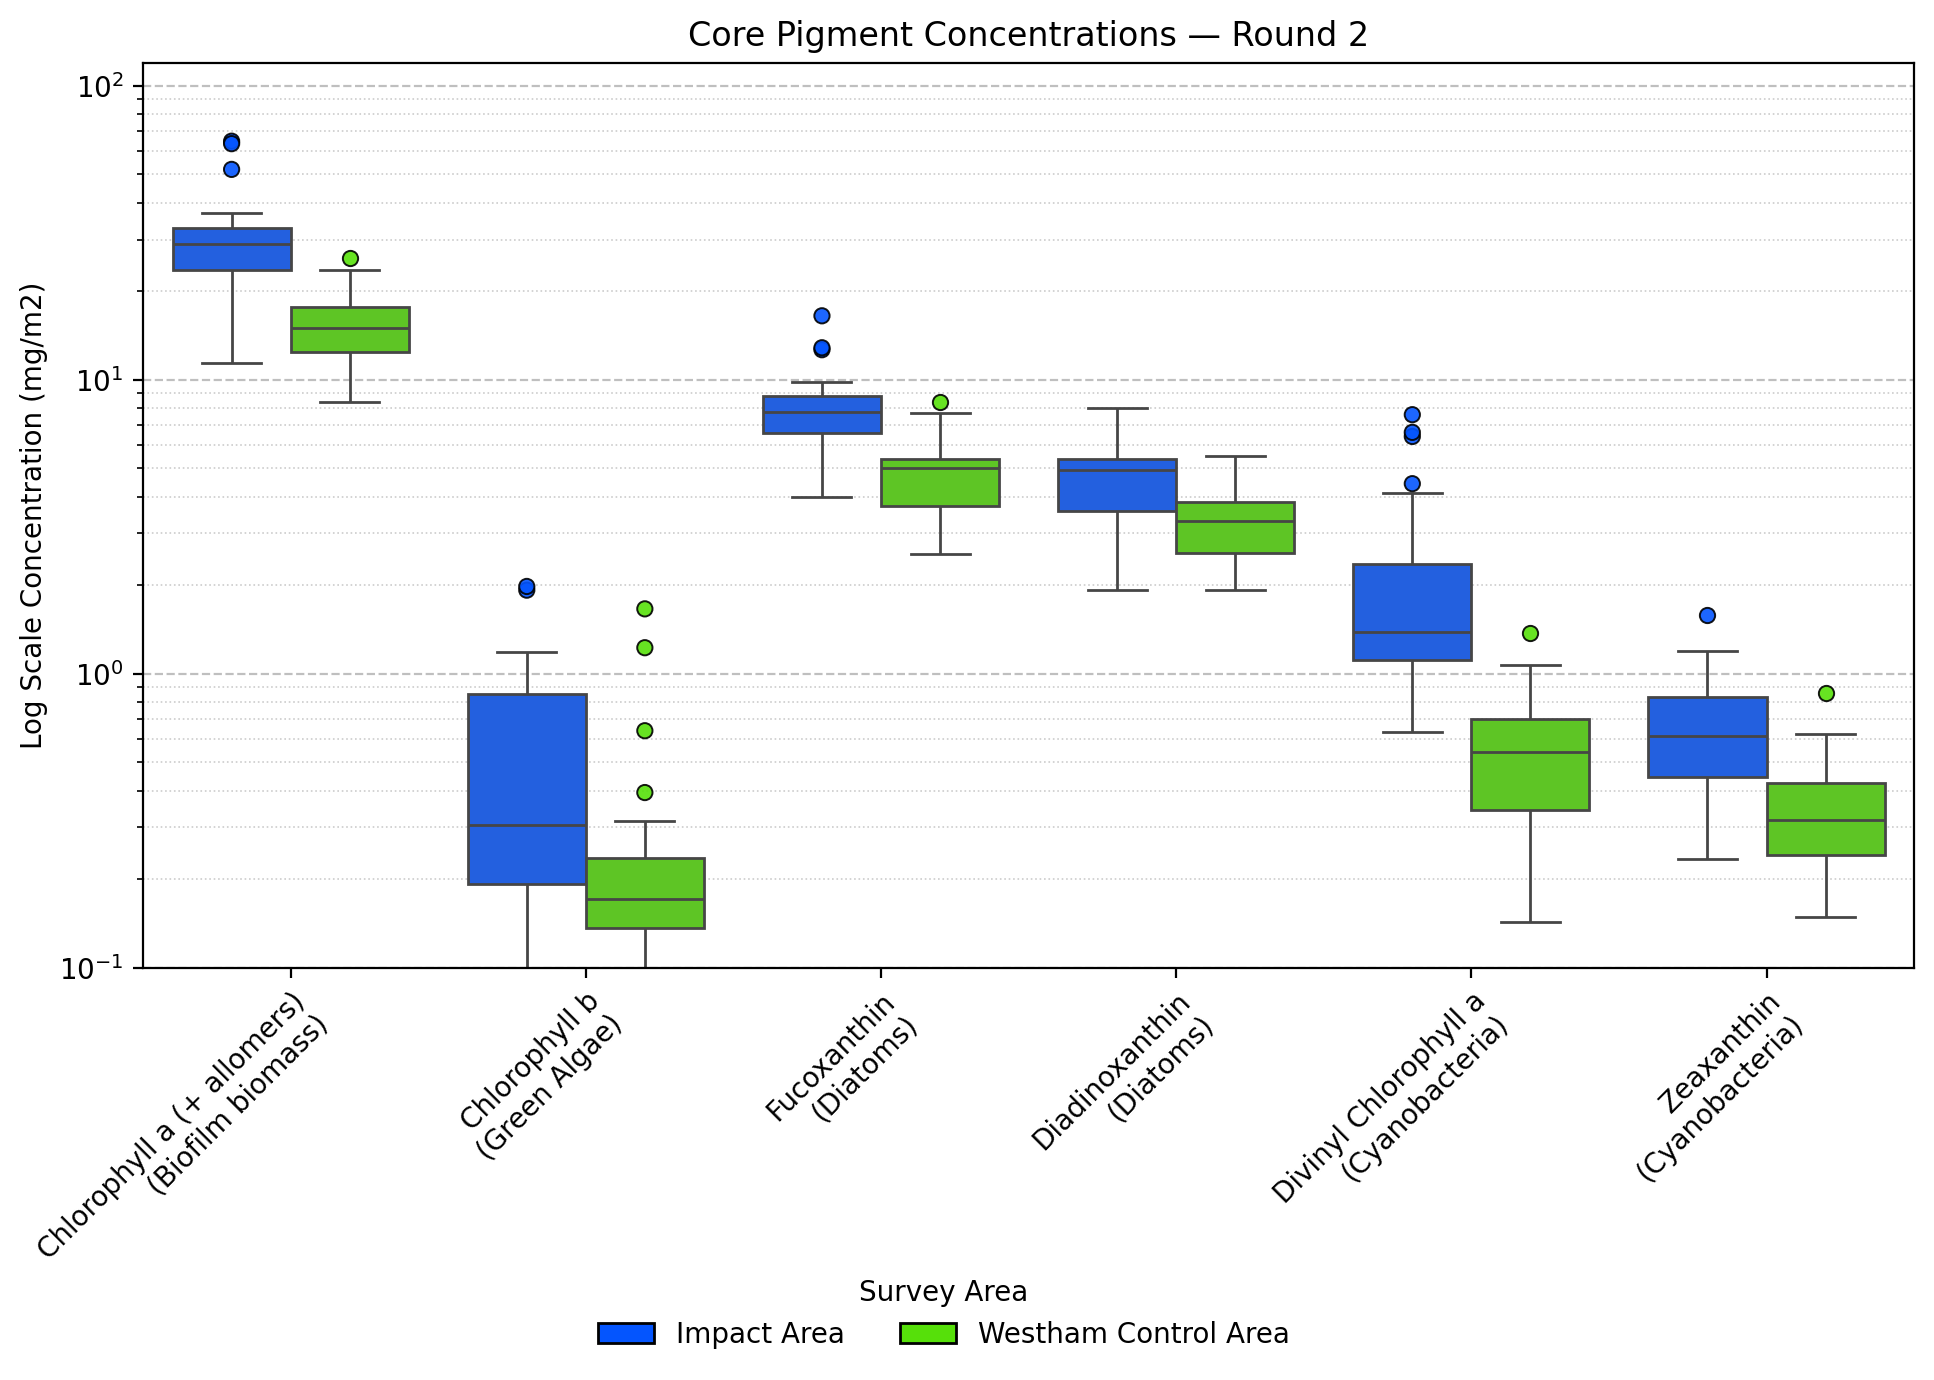

In [36]:
pigment_unit = 'mg/m2' #'mg/g' or 'mg/m2'
core_pigment_columns = [
    pigment + f" ({pigment_unit})" for pigment in CORE_PIGMENT_COMMUNITIES.keys()
]

for round_number in [1, 2]:
    fig, ax = draw_boxplots(
        df_lab_r,
        core_pigment_columns,
        round_number=round_number,
        title=f"Core Pigment Concentrations \u2014 Round {round_number}",
        y_scale="log",
        y_min=0.1,
        annotate_outliers=False,
        variable_labels=CORE_PIGMENT_FULL_LABELS.values(),
        y_label=f"Log Scale Concentration ({pigment_unit})",
        figsize=(10,7),
    )
    path = path_output_dir / f"boxplots_core_pigments_round_{round_number}.png"
    # ax.set_ylim(bottom = 0)
    fig.savefig(path, dpi=300, bbox_inches="tight")

# fig, ax = draw_boxplots(
#     df_lab_r,
#     core_pigment_columns,
#     round_number=[1, 2],
#     title="Pigment Concentrations by Survey Round",
#     figsize=(12, 10),
#     y_scale="symlog",
#     y_label=f"Concentration ({pigment_unit})",
#     variable_labels=CORE_PIGMENT_FULL_LABELS.values(),
#     show_y_grid=True,
#     annotate_outliers=True,
# )
# path = path_output_dir / "boxplots_core_pigments_rounds_1_and_2.png"
# fig.savefig(path, dpi=300, bbox_inches="tight")

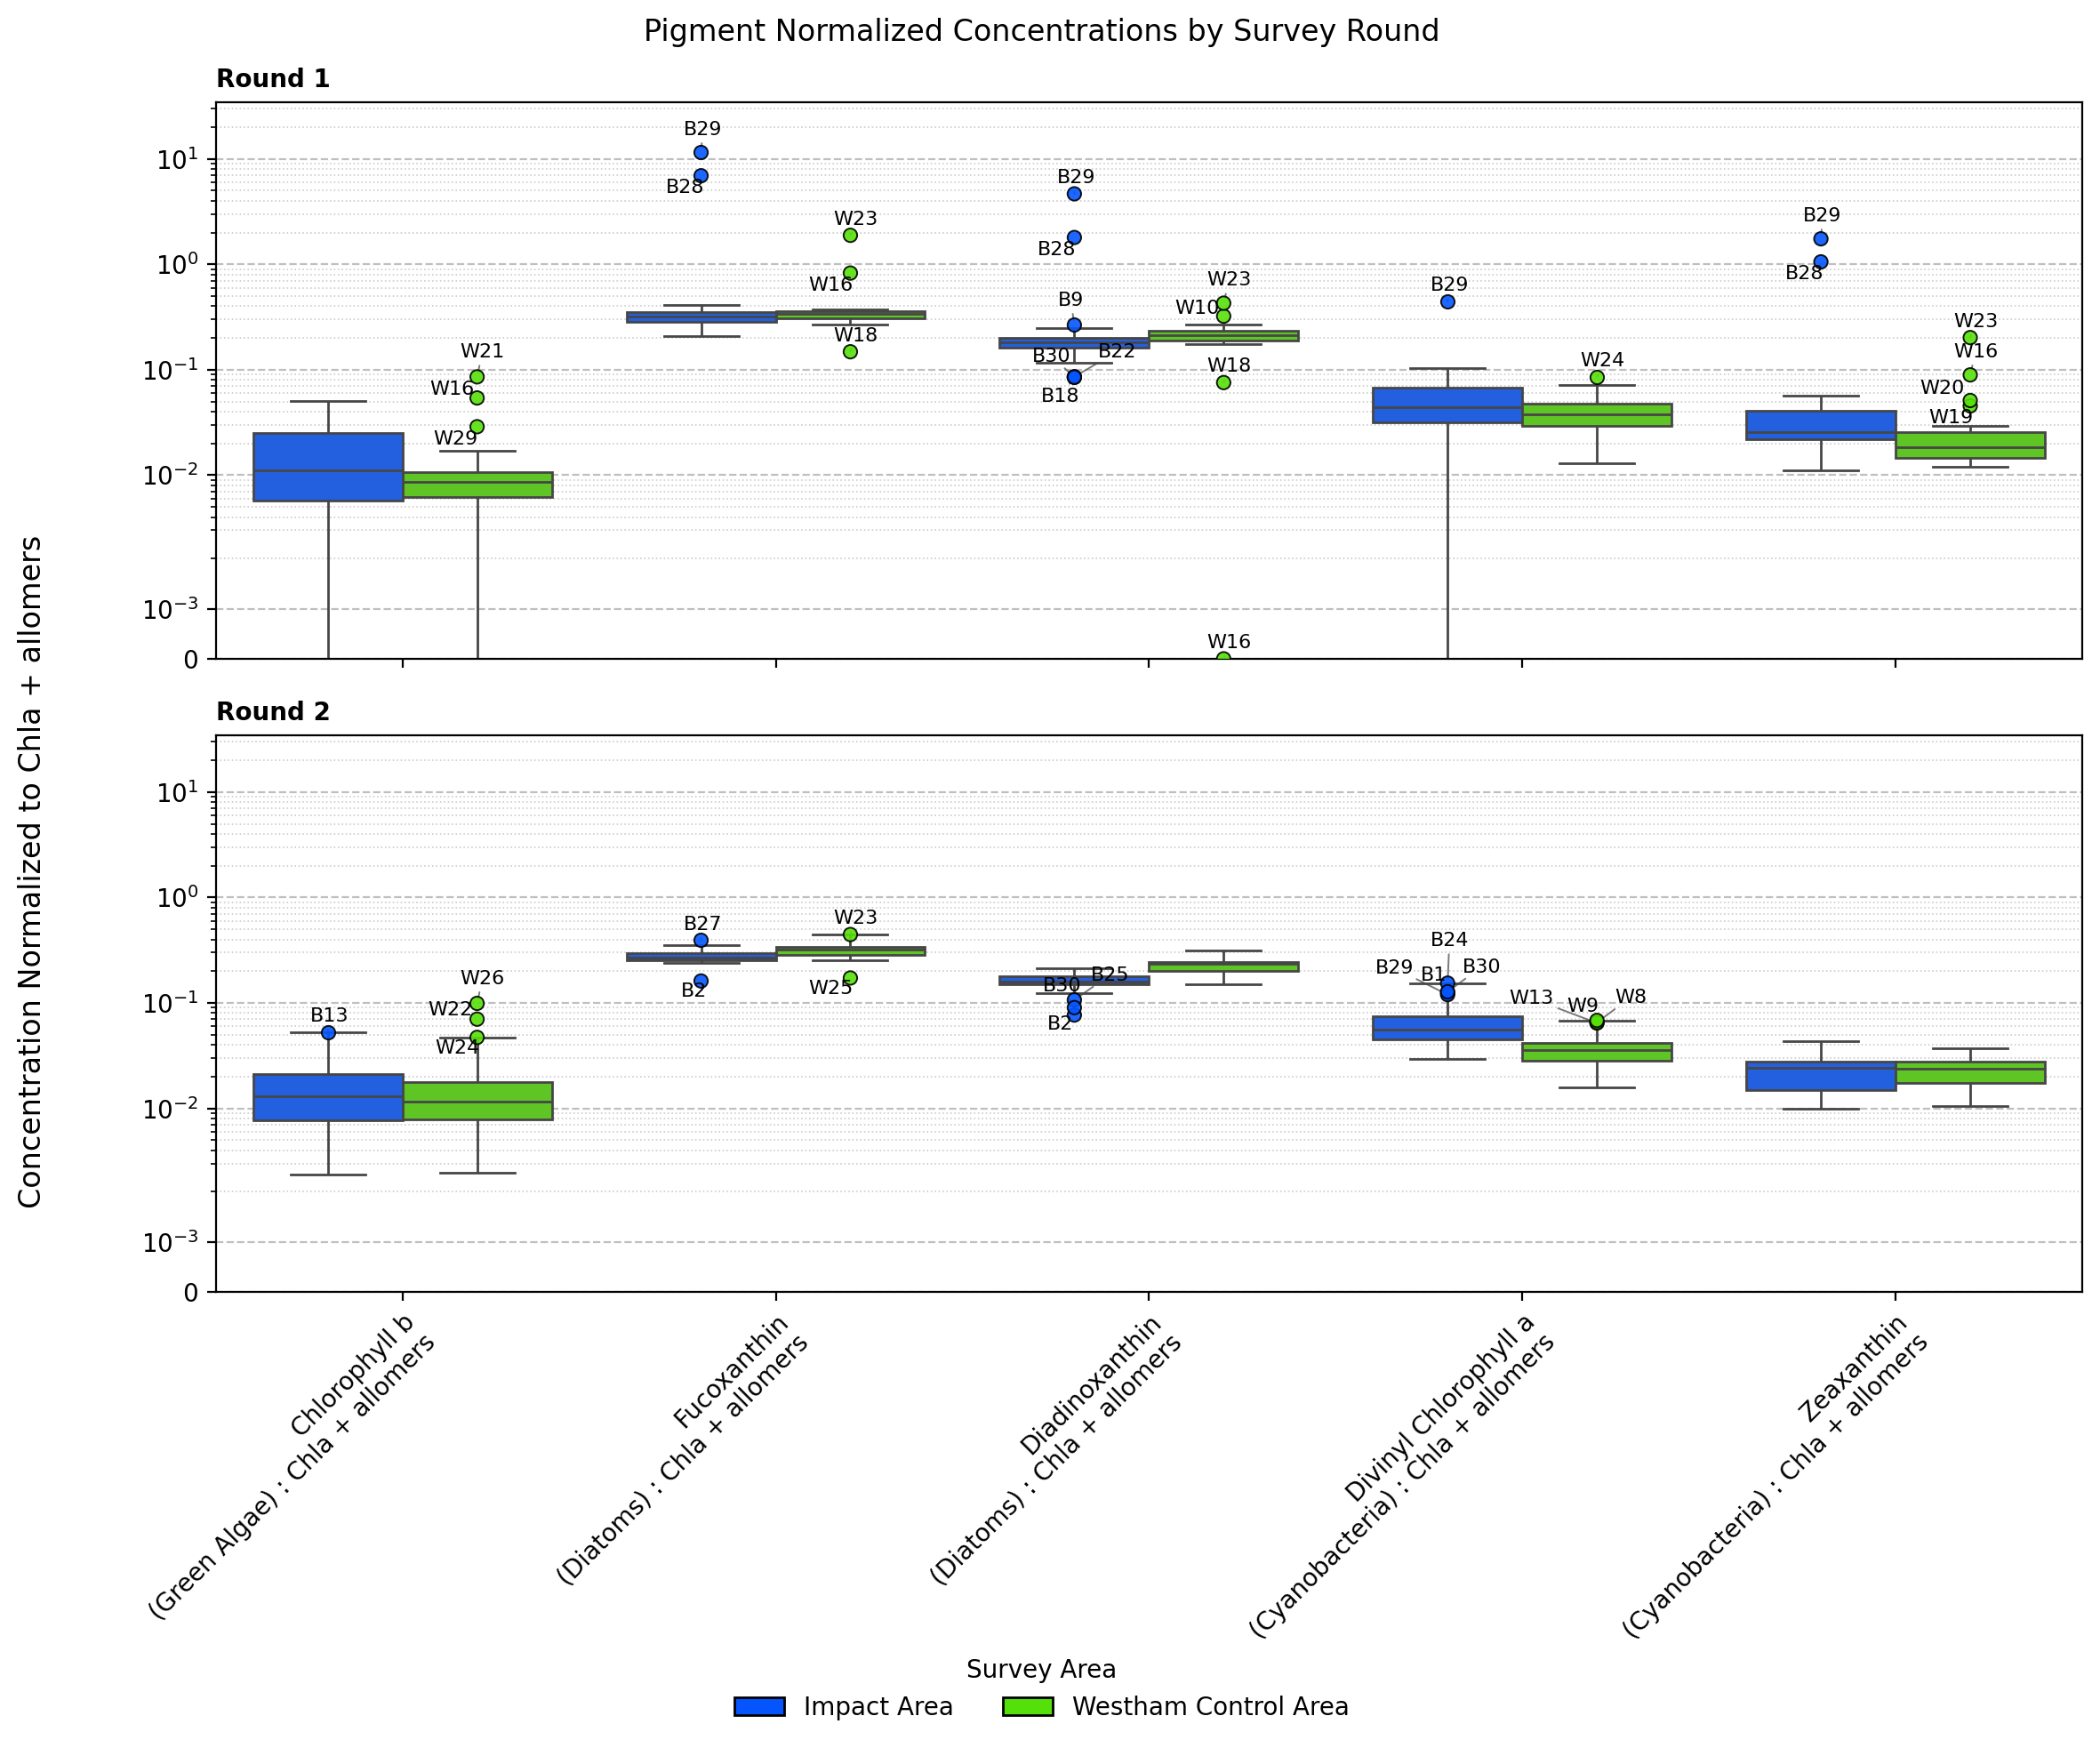

In [37]:
core_pigment_columns_norm = [
    f"{pigment} : {NORMALIZING_CHLA_COLUMN}" for pigment in CORE_PIGMENTS if pigment != NORMALIZING_CHLA_COLUMN
]
core_pigment_labels_norm = [
    f"{label} : {NORMALIZING_CHLA_COLUMN}"
    for label in CORE_PIGMENT_FULL_LABELS.values()
    if label != CORE_PIGMENT_FULL_LABELS.get(NORMALIZING_CHLA_COLUMN, '')
]

fig, ax = draw_boxplots(
    df_lab_r,
    core_pigment_columns_norm,
    round_number=[1, 2],
    title="Pigment Normalized Concentrations by Survey Round",
    figsize=(12, 10),
    y_scale="symlog",
    y_label=f"Concentration Normalized to {NORMALIZING_CHLA_COLUMN}",
    variable_labels=core_pigment_labels_norm,
    show_y_grid=True,
    annotate_outliers=True,
)
path = path_output_dir / "boxplots_core_pigments_normalized_rounds_1_and_2.png"
fig.savefig(path, dpi=300, bbox_inches="tight")


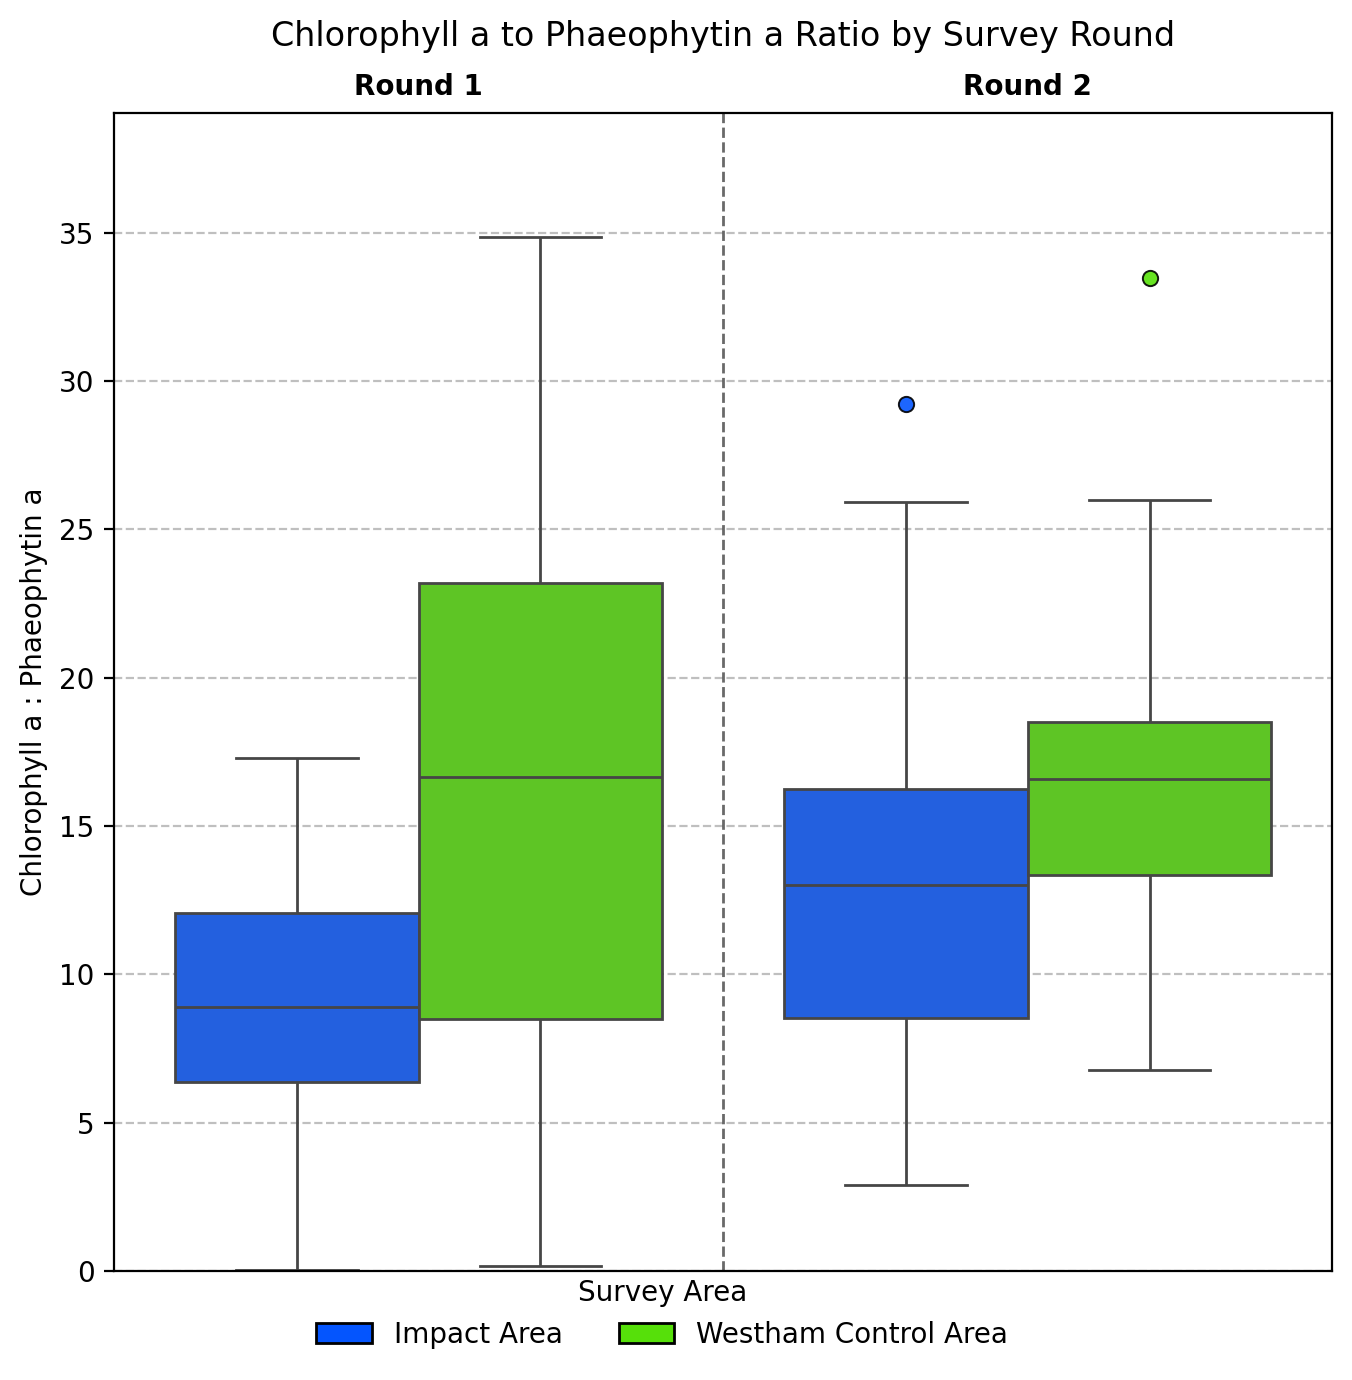

In [38]:
# Chla : Phta ratio

fig, ax = draw_boxplots_2(
    df_lab_r,
    ["Chla : Phta"],
    round_number=[1, 2],
    round_layout="horizontal",
    round_separator=True,
    title="Chlorophyll a to Phaeophytin a Ratio by Survey Round",
    y_scale="linear",
    y_label="Chlorophyll a : Phaeophytin a",
    show_y_grid=True,
    annotate_outliers=False,
    show_x_tick_labels=False,
    figsize=(7, 7)
)


### Fatty acids

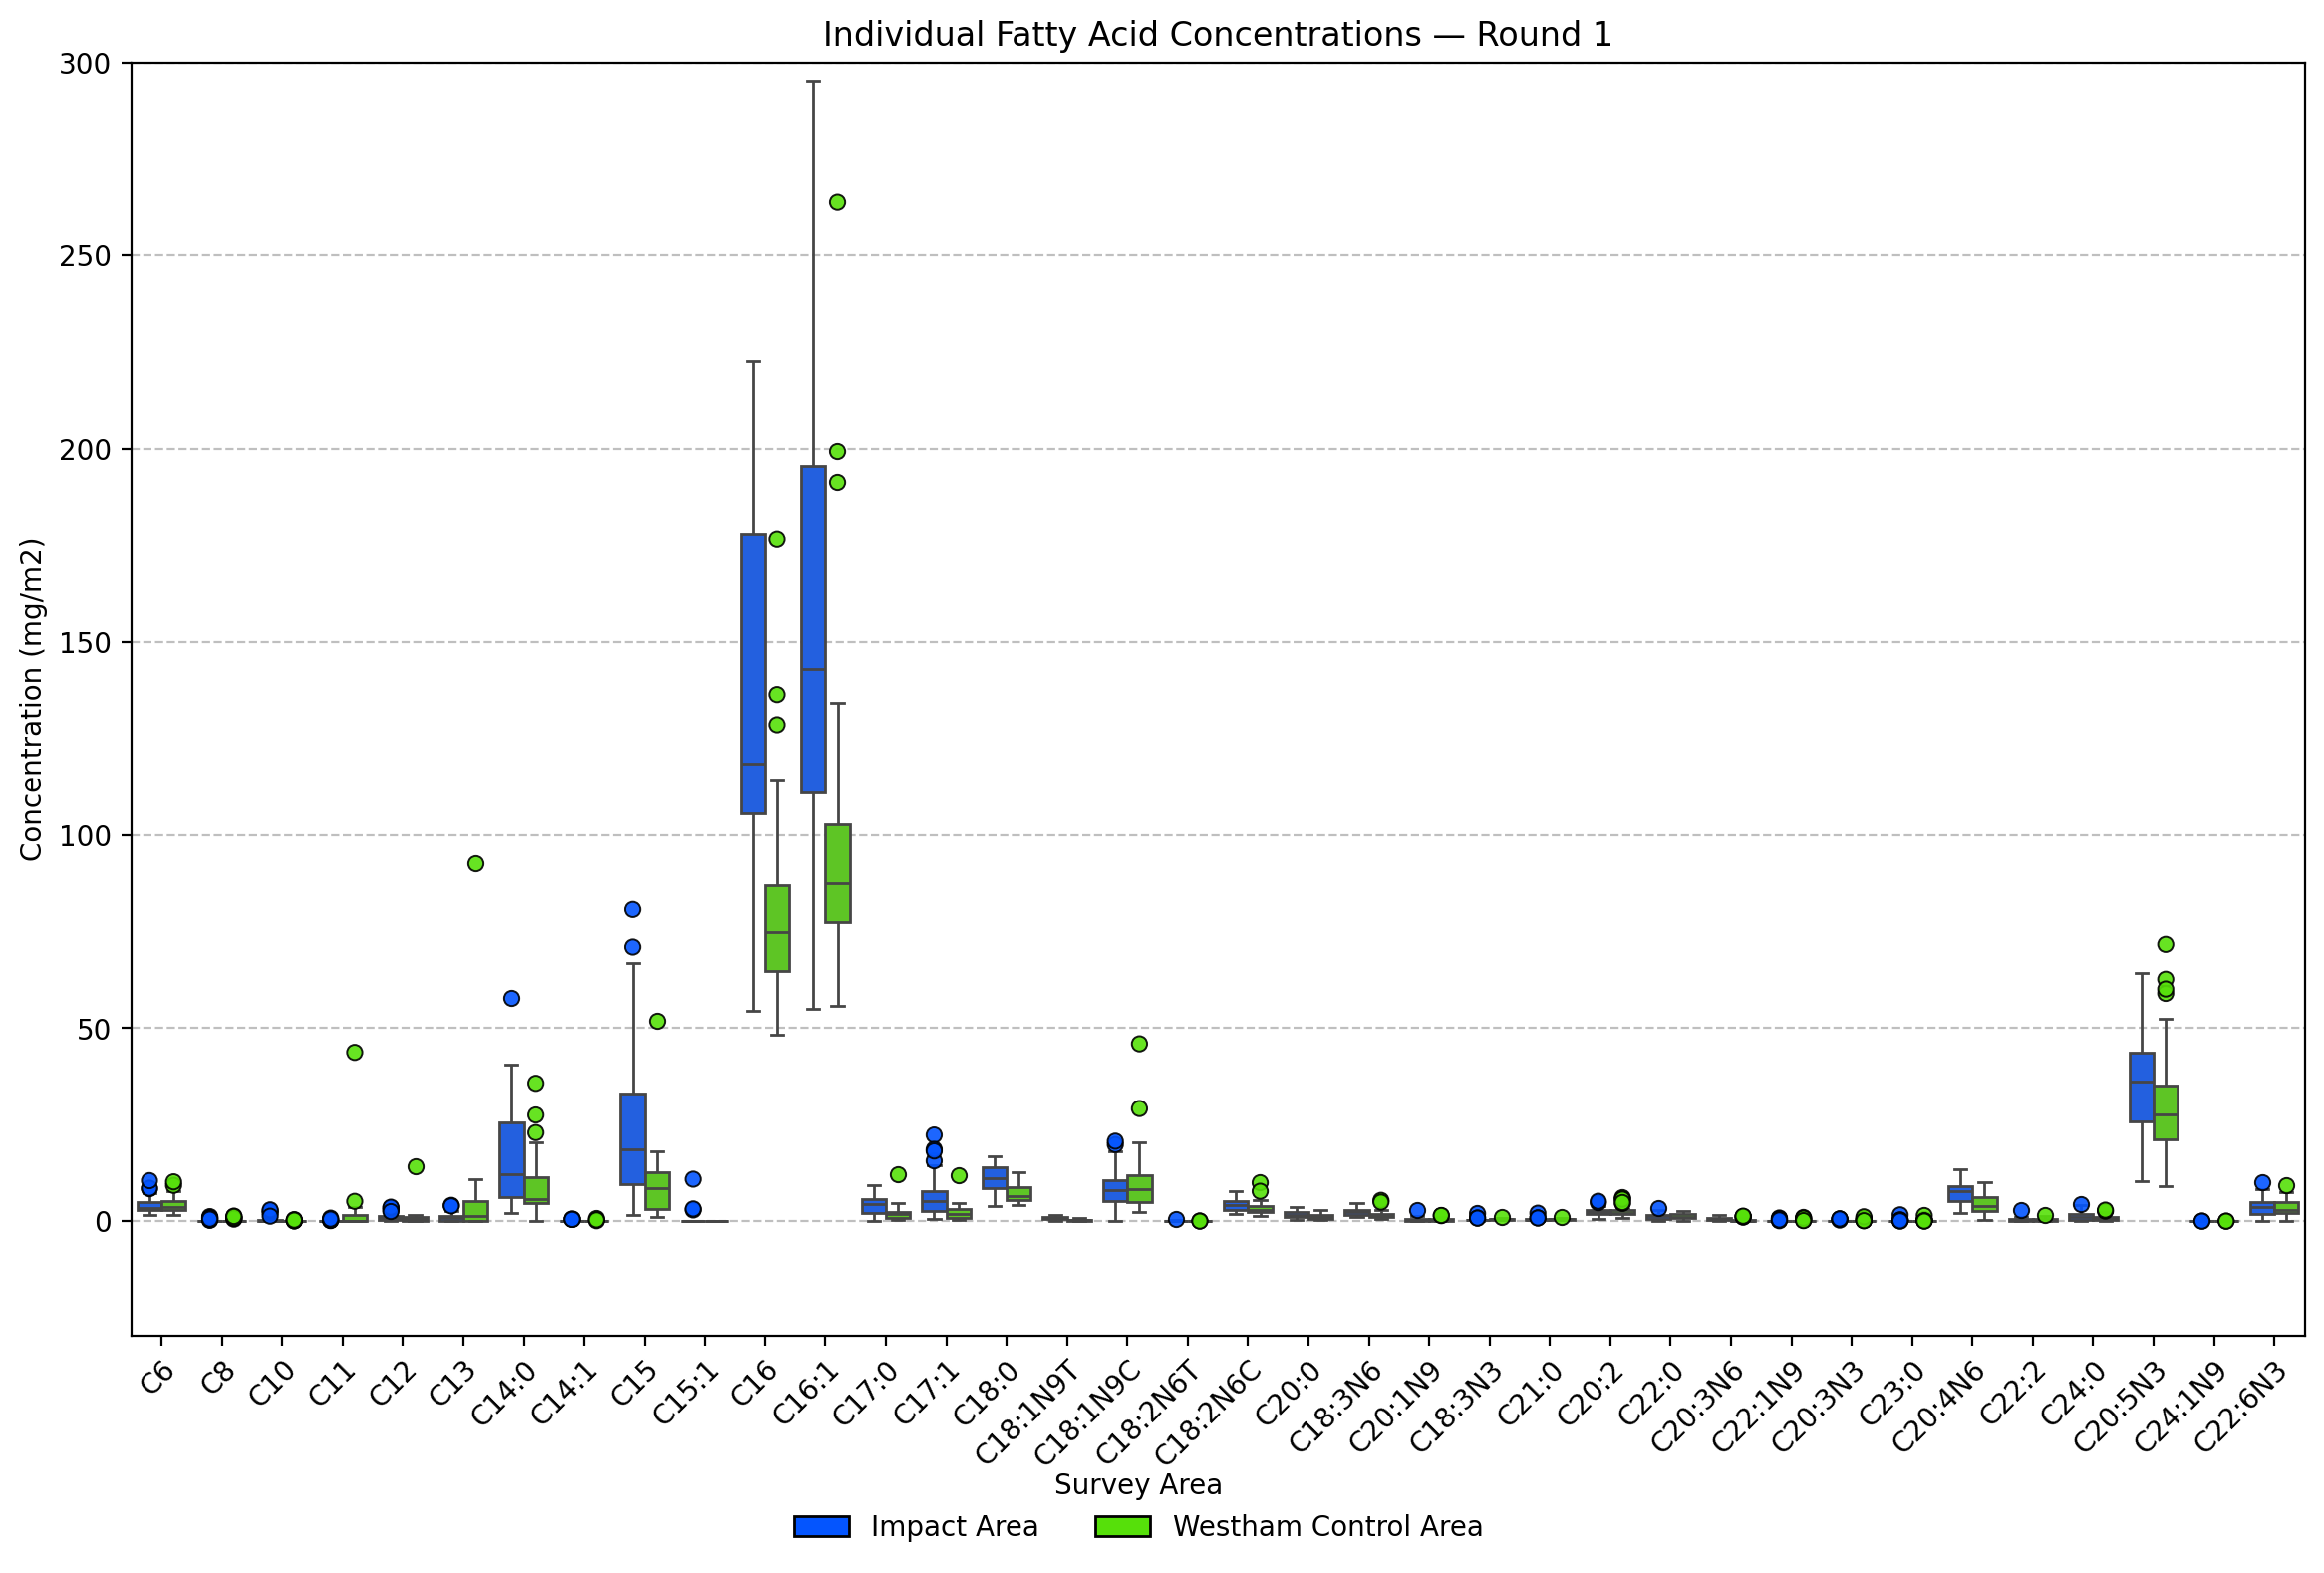

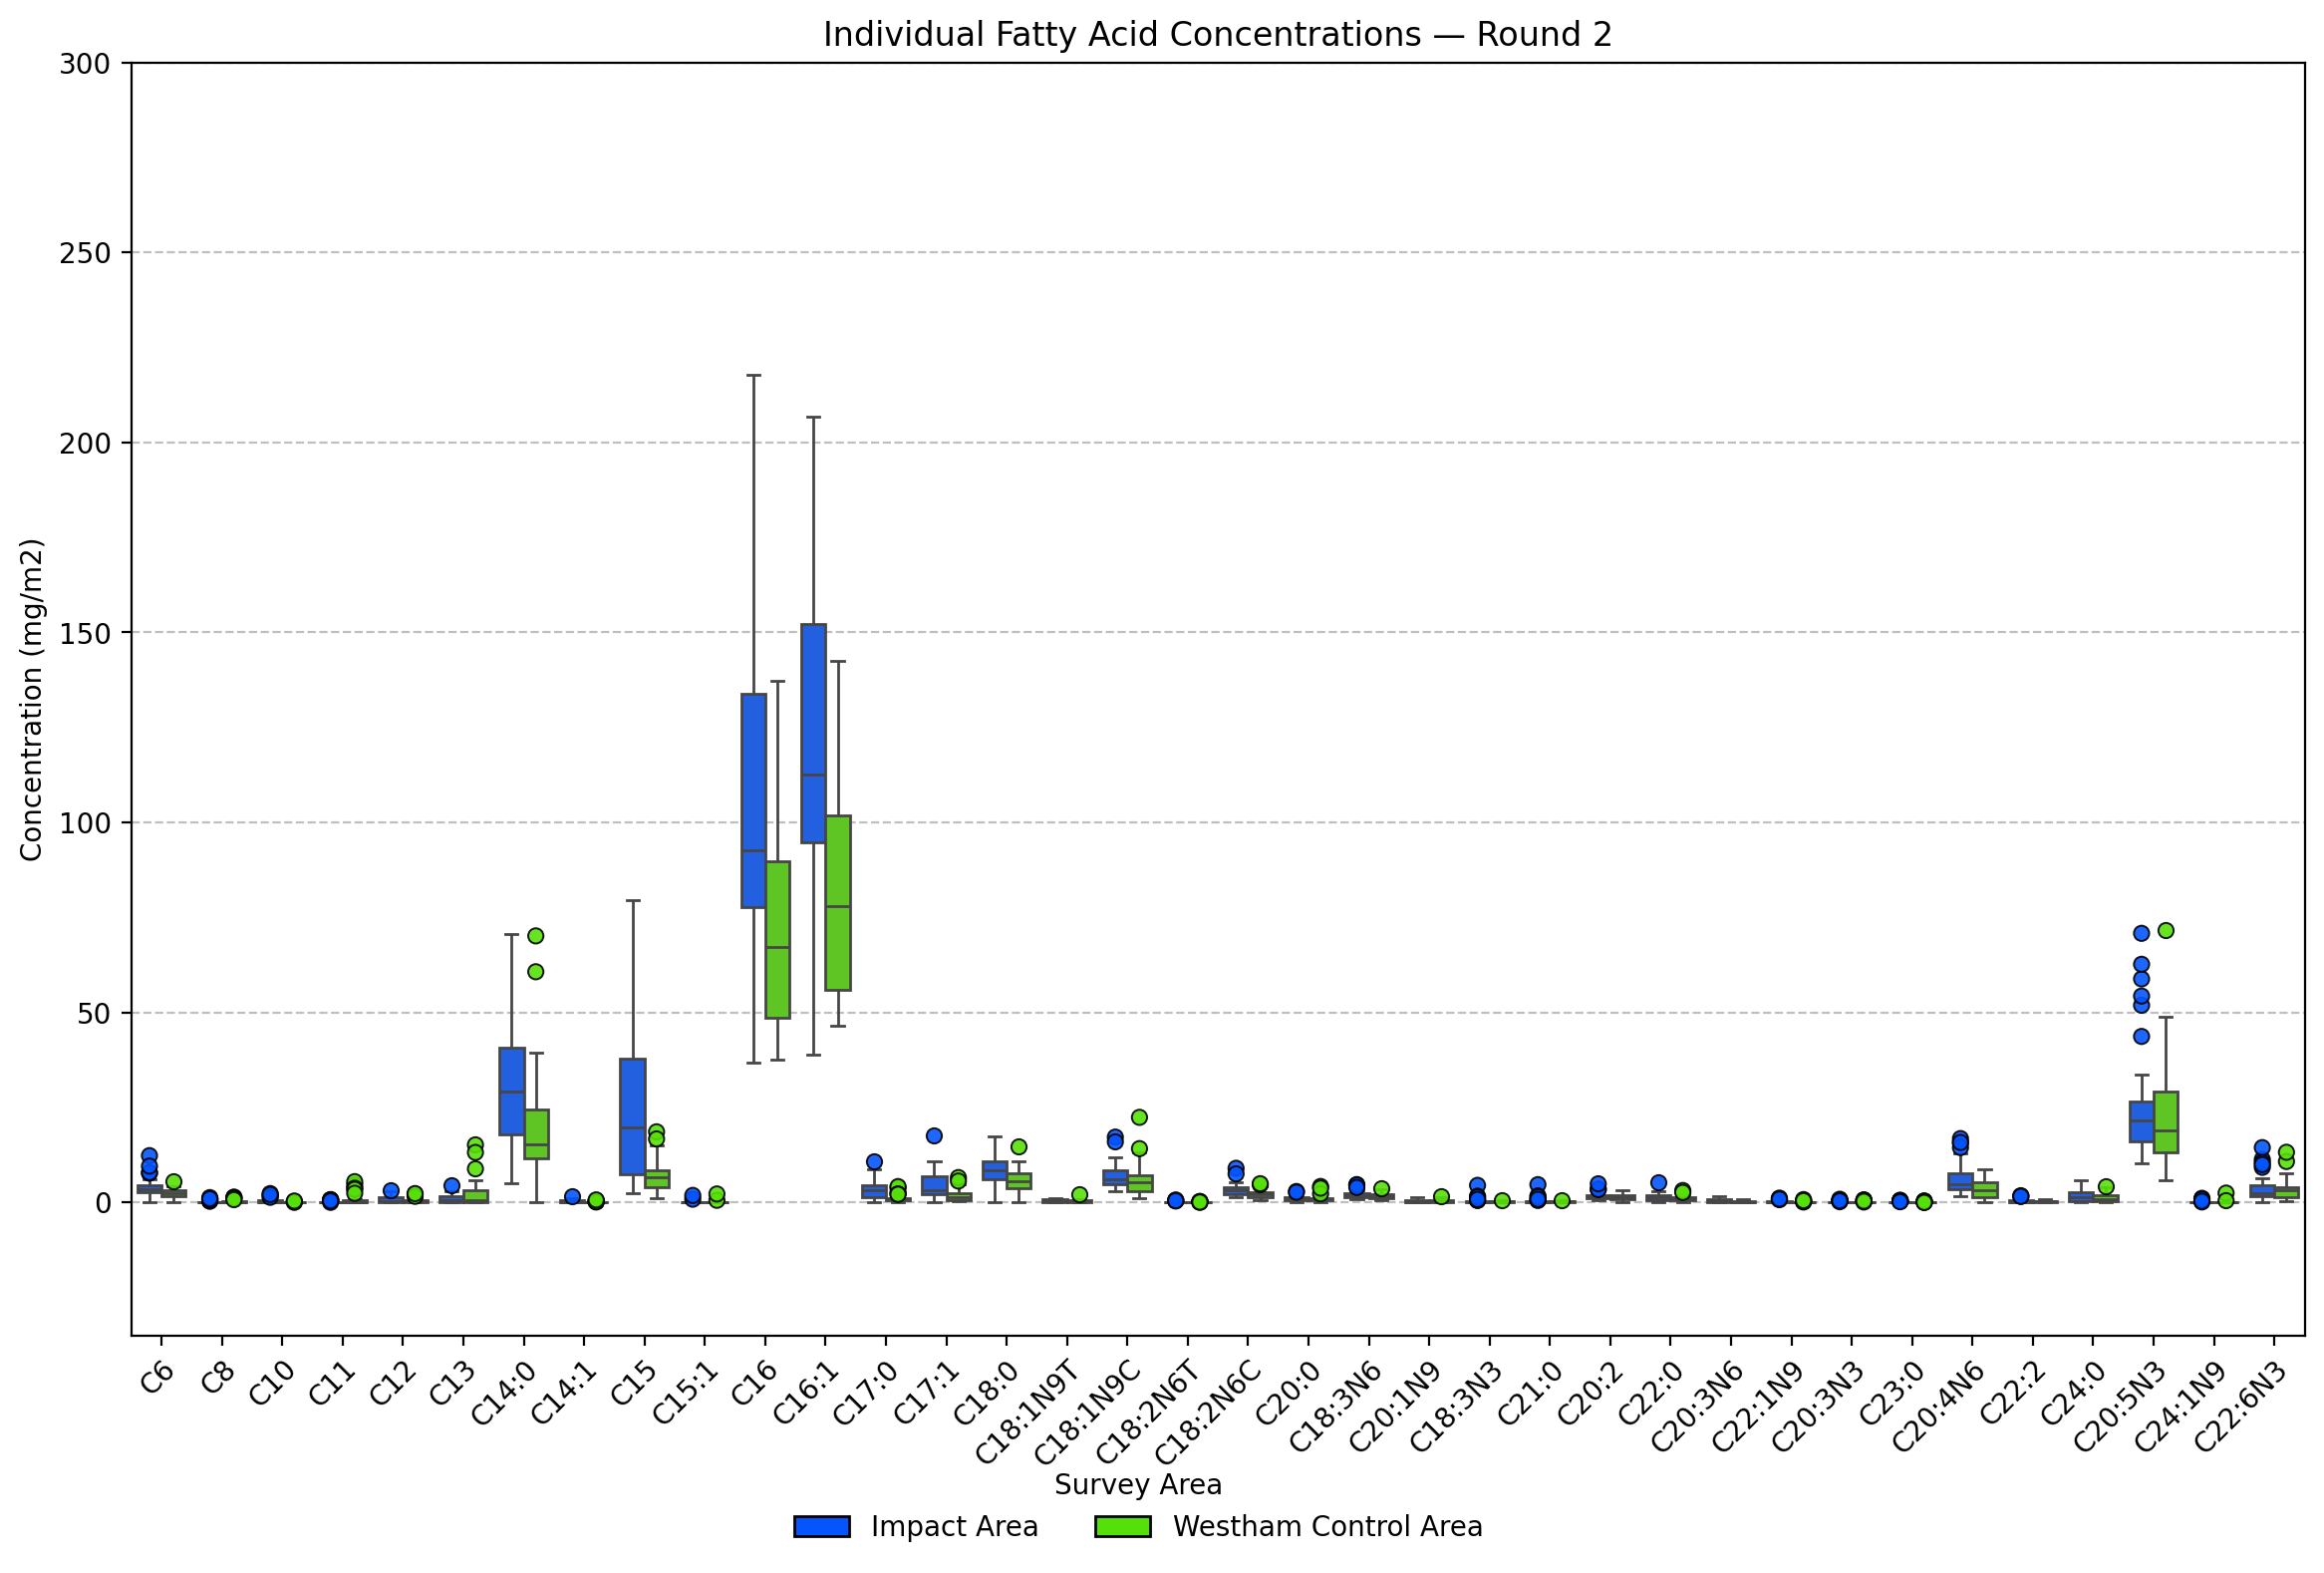

In [39]:
fa_unit = "mg/m2"

fa_columns = [f"{fa} ({fa_unit})" for fa in FA_LIST]

for round_number in [1, 2]:
    fig, ax = draw_boxplots(
        df_lab_r,
        fa_columns,
        round_number=round_number,
        title=f"Individual Fatty Acid Concentrations \u2014 Round {round_number}",
        y_scale="linear",
        annotate_outliers=False,
        # variable_labels=CORE_FA_LABELS,
        y_max=300,
        y_label=f"Concentration ({fa_unit})",
    )
    path = path_output_dir / f"boxplots_ind_fatty_acids_round_{round_number}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")

In [40]:
fa_unit = "mg/m2" # or 'mg/m2'

CORE_FA = [
    'Total FA',
    'Total SFA',
    'Total MUFA',
    'Total PUFA',
    'Total Omega-3 PUFA',
    'Total Omega-6 PUFA',
    'Total LC-PUFA',
    'C20:5N3', # EPA
    'C22:6N3', # DHA
    'C20:4N6', # ARA
]

CORE_FA_LABELS = [
    'Total FA',
    'Total SFA',
    'Total MUFA',
    'Total PUFA',
    'Total Omega-3 PUFA',
    'Total Omega-6 PUFA',
    'Total LC-PUFA',
    'EPA',
    'DHA',
    'ARA',
]

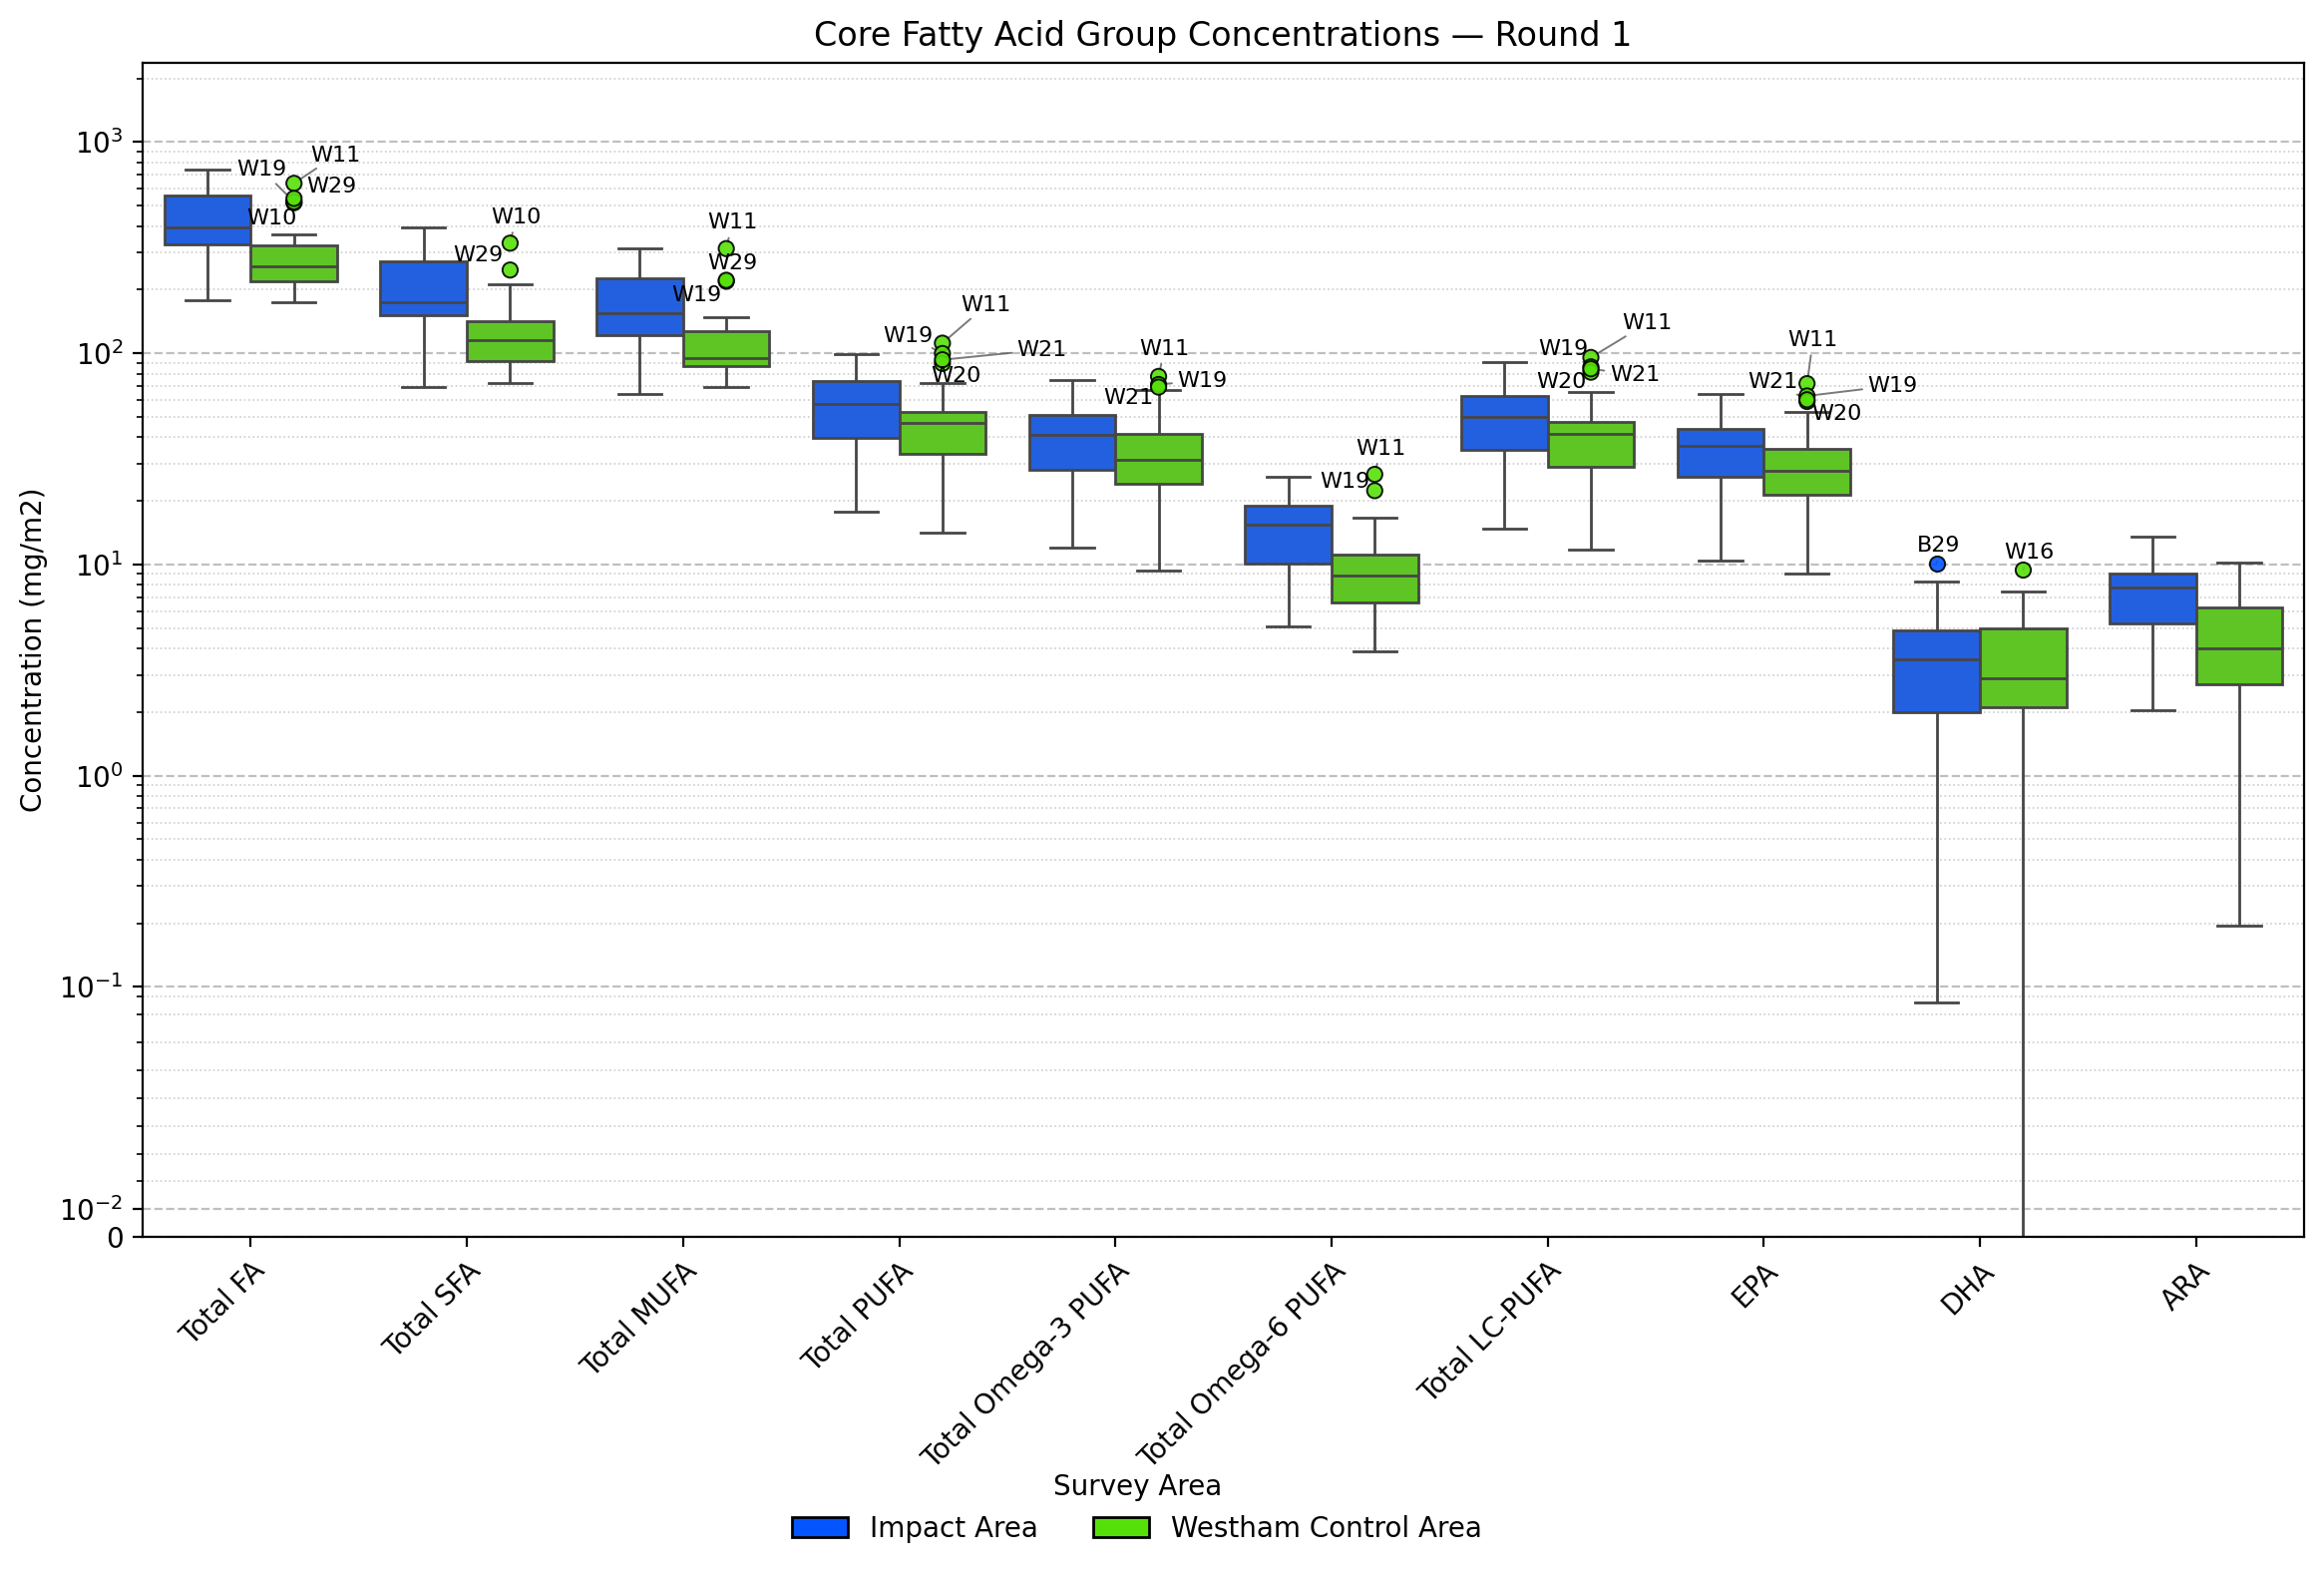

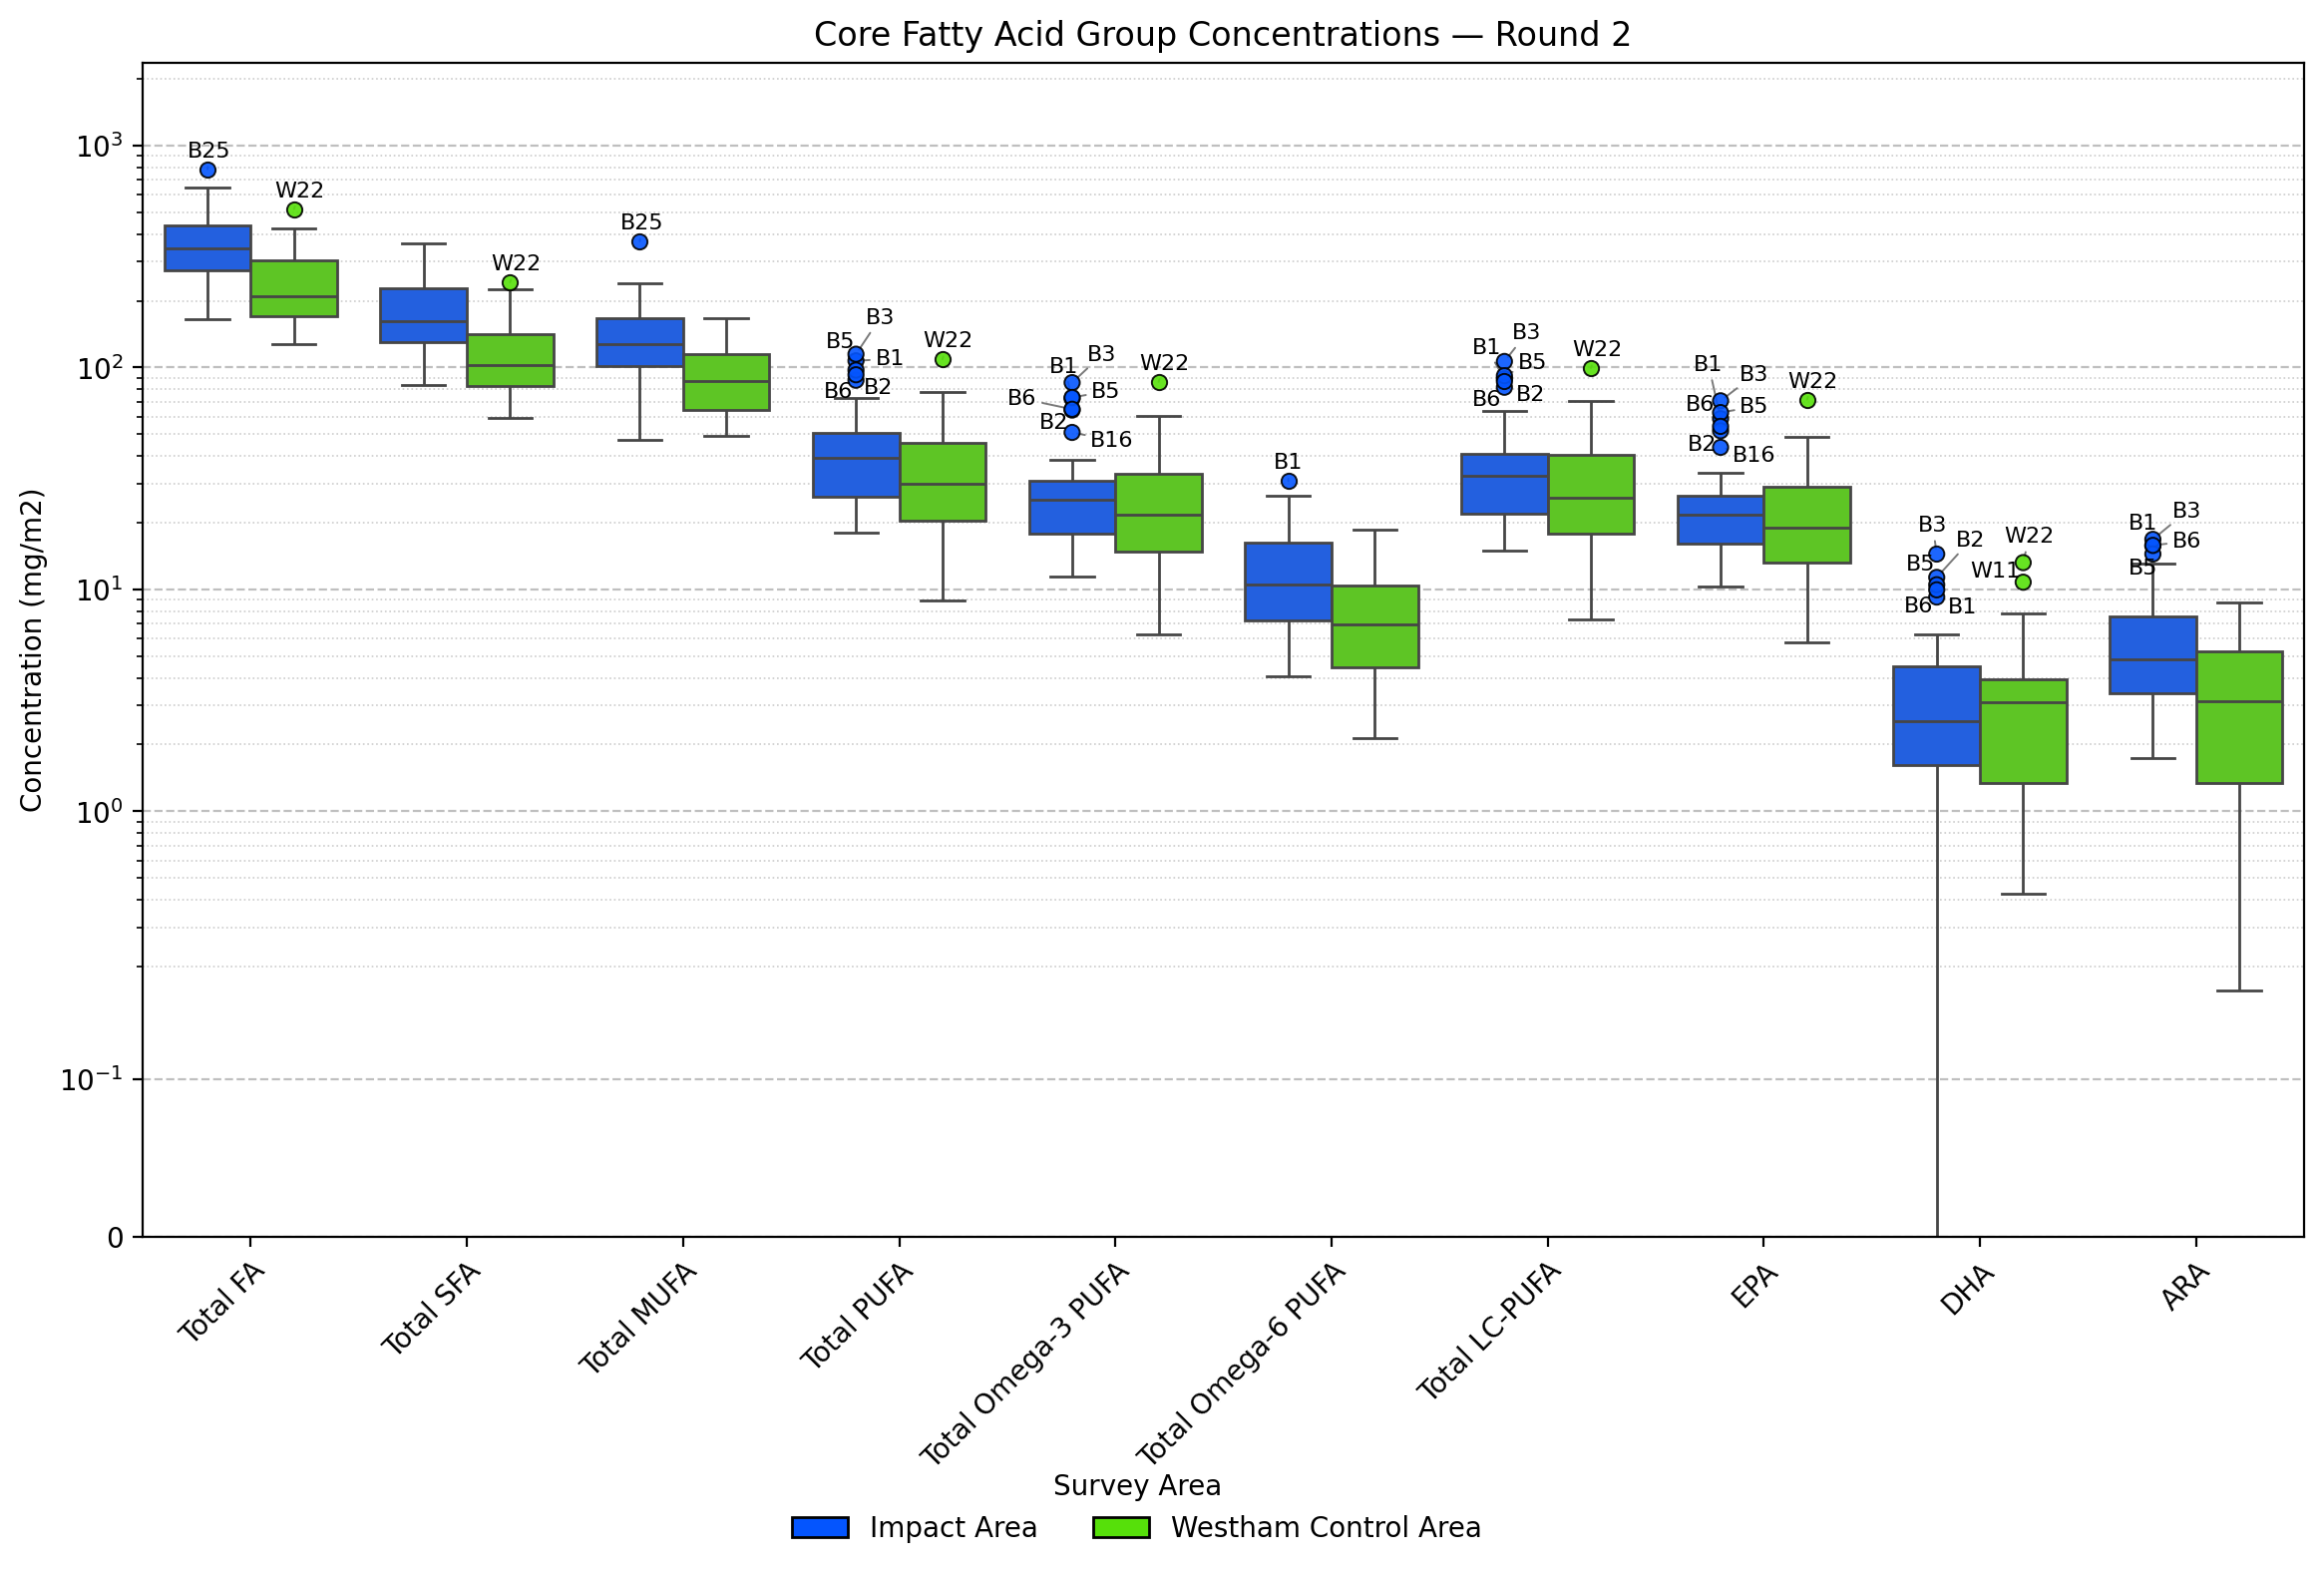

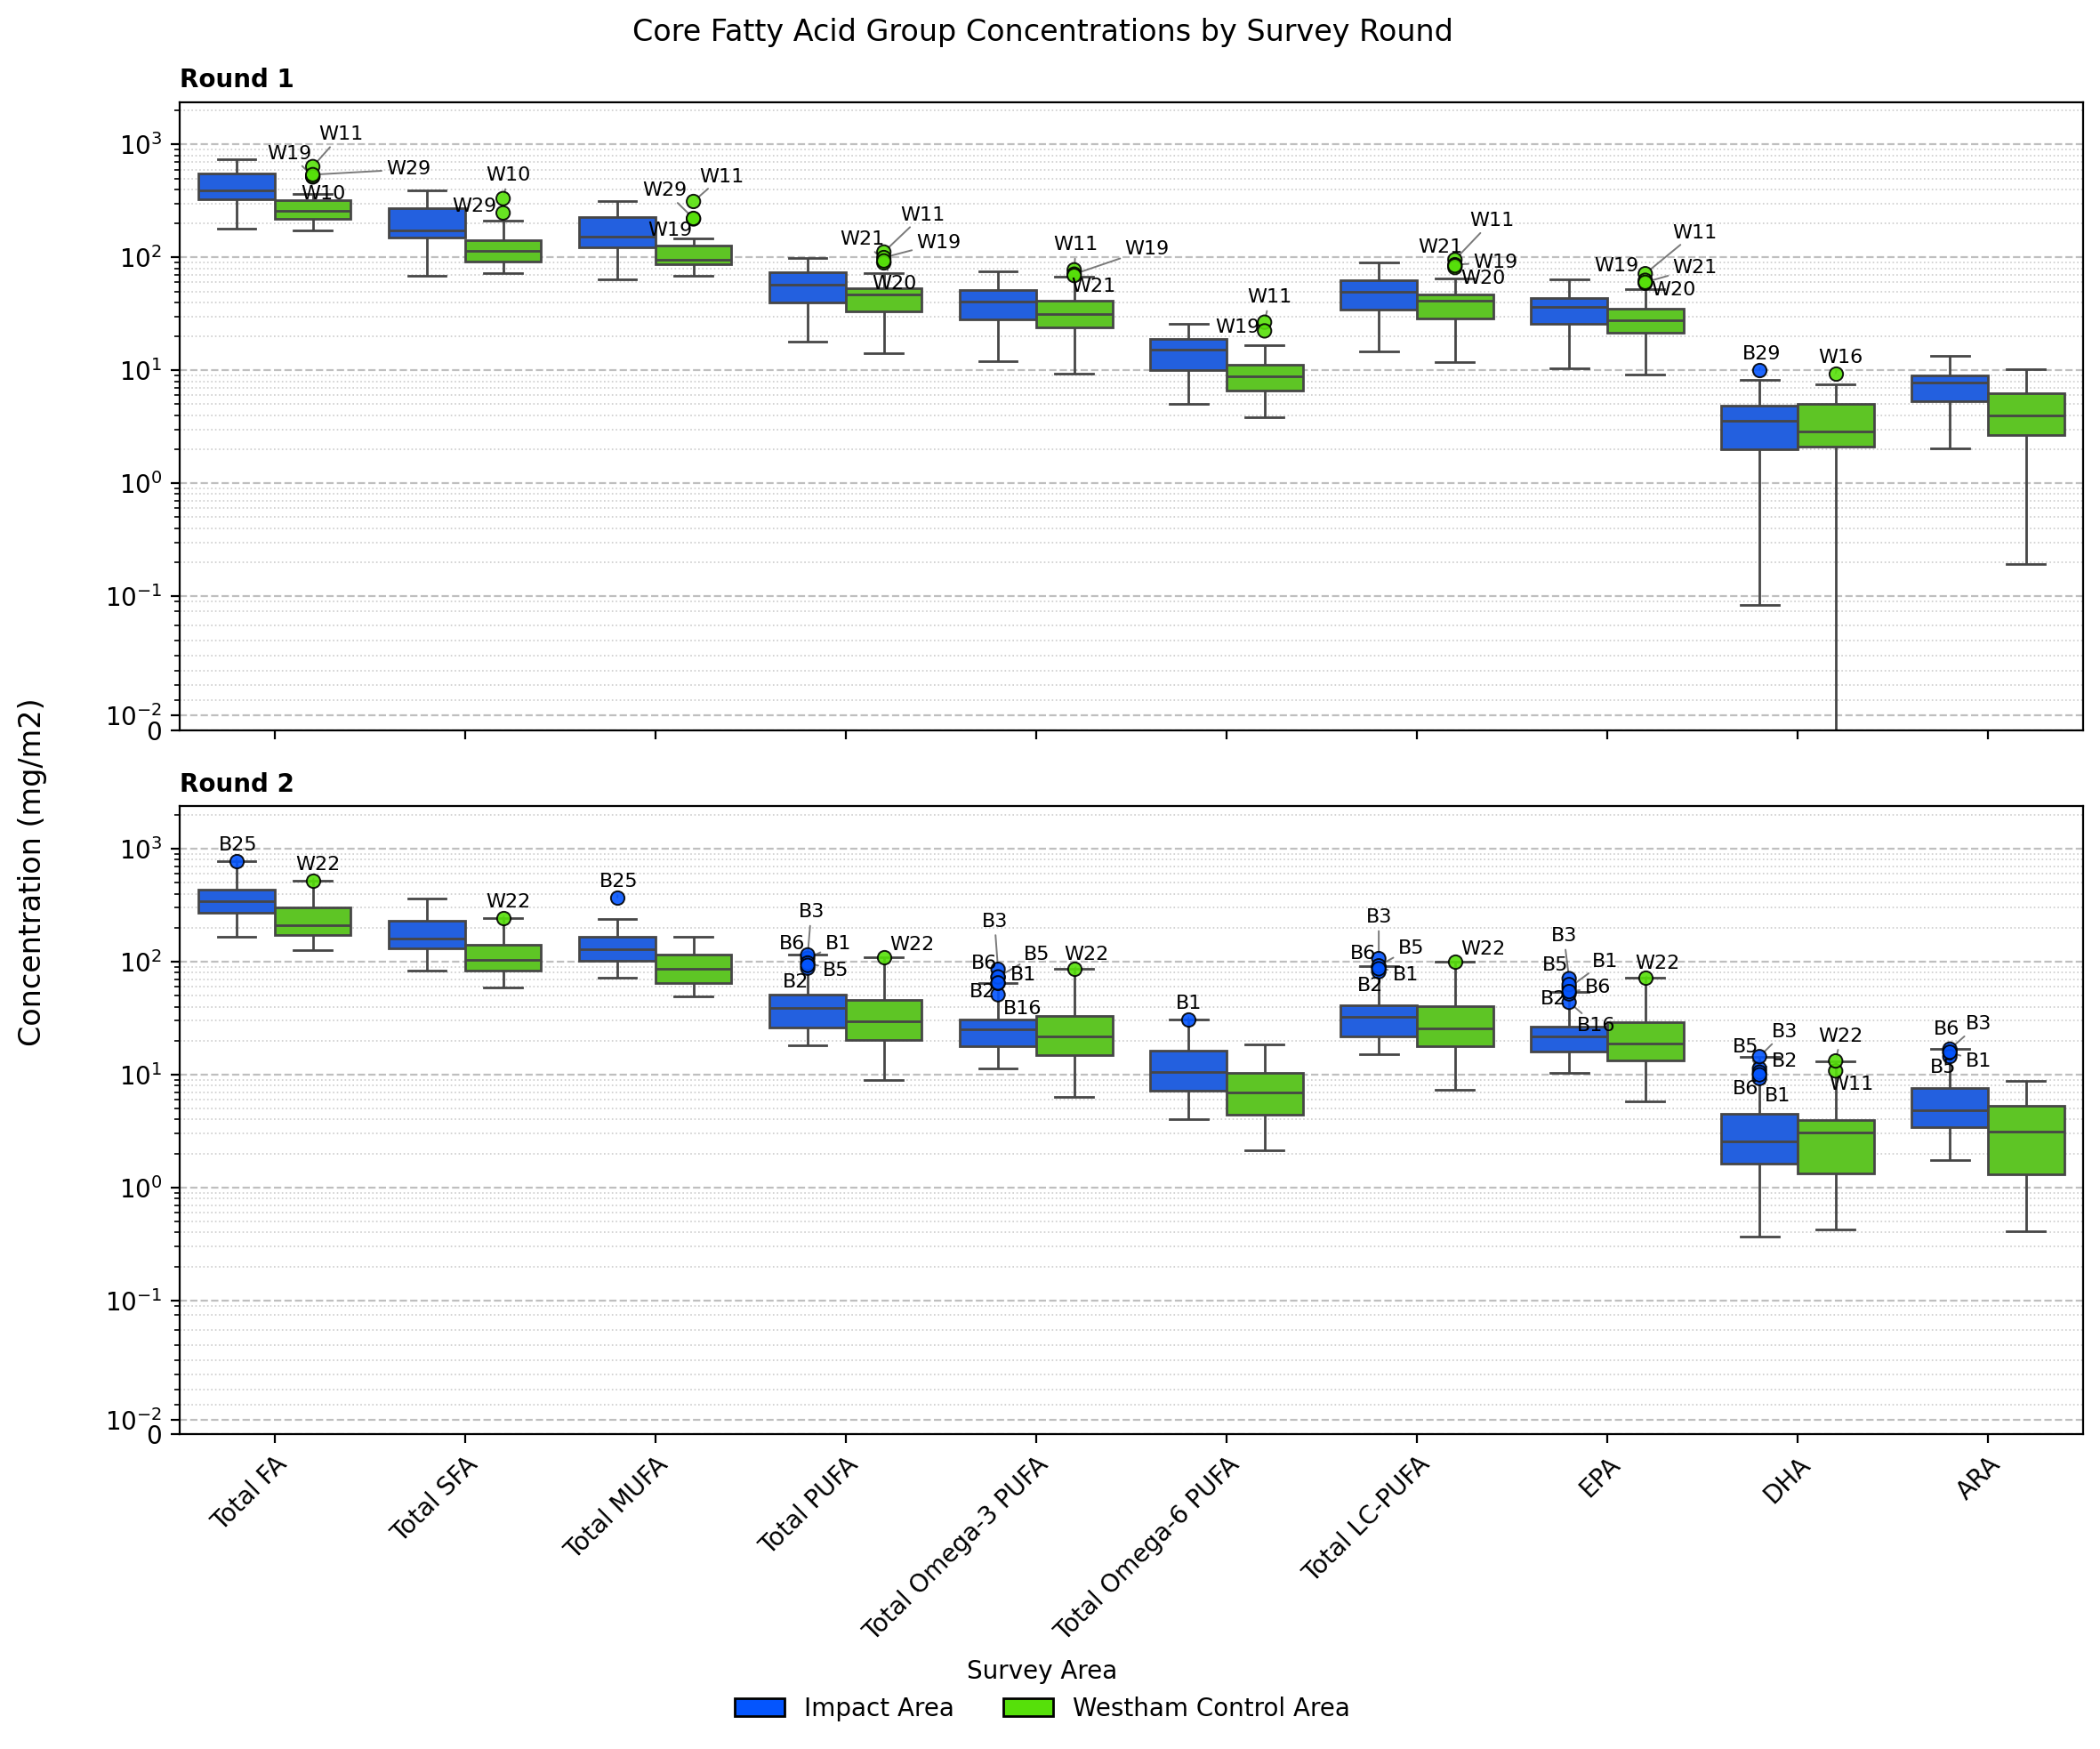

In [41]:
fa_columns = [f"{fa} ({fa_unit})" for fa in CORE_FA]

for round_number in [1, 2]:
    fig, ax = draw_boxplots(
        df_lab_r,
        fa_columns,
        round_number=round_number,
        title=f"Core Fatty Acid Group Concentrations \u2014 Round {round_number}",
        y_scale="symlog",
        annotate_outliers=True,
        variable_labels=CORE_FA_LABELS,
        y_label=f"Concentration ({fa_unit})",
    )
    path = path_output_dir / f"boxplots_core_fatty_acids_round_{round_number}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")

fig, ax = draw_boxplots(
    df_lab_r,
    fa_columns,
    round_number=[1, 2],
    title="Core Fatty Acid Group Concentrations by Survey Round",
    figsize=(12, 10),
    y_scale="symlog",
    y_label=f"Concentration ({fa_unit})",
    variable_labels=CORE_FA_LABELS,
    show_y_grid=True,
    annotate_outliers=True,
)
path = path_output_dir / "boxplots_core_fatty_acids_rounds_1_and_2.png"
fig.savefig(path, dpi=300, bbox_inches="tight")

brunswick 1
Total SFA : Total FA (%)     46.038103
Total MUFA : Total FA (%)    40.360410
Total PUFA : Total FA (%)    13.601487
dtype: float64
westham 1
Total SFA : Total FA (%)     43.577343
Total MUFA : Total FA (%)    39.550724
Total PUFA : Total FA (%)    16.871933
dtype: float64
brunswick 2
Total SFA : Total FA (%)     49.818485
Total MUFA : Total FA (%)    37.104899
Total PUFA : Total FA (%)    13.076616
dtype: float64
westham 2
Total SFA : Total FA (%)     47.867700
Total MUFA : Total FA (%)    38.262135
Total PUFA : Total FA (%)    13.870165
dtype: float64


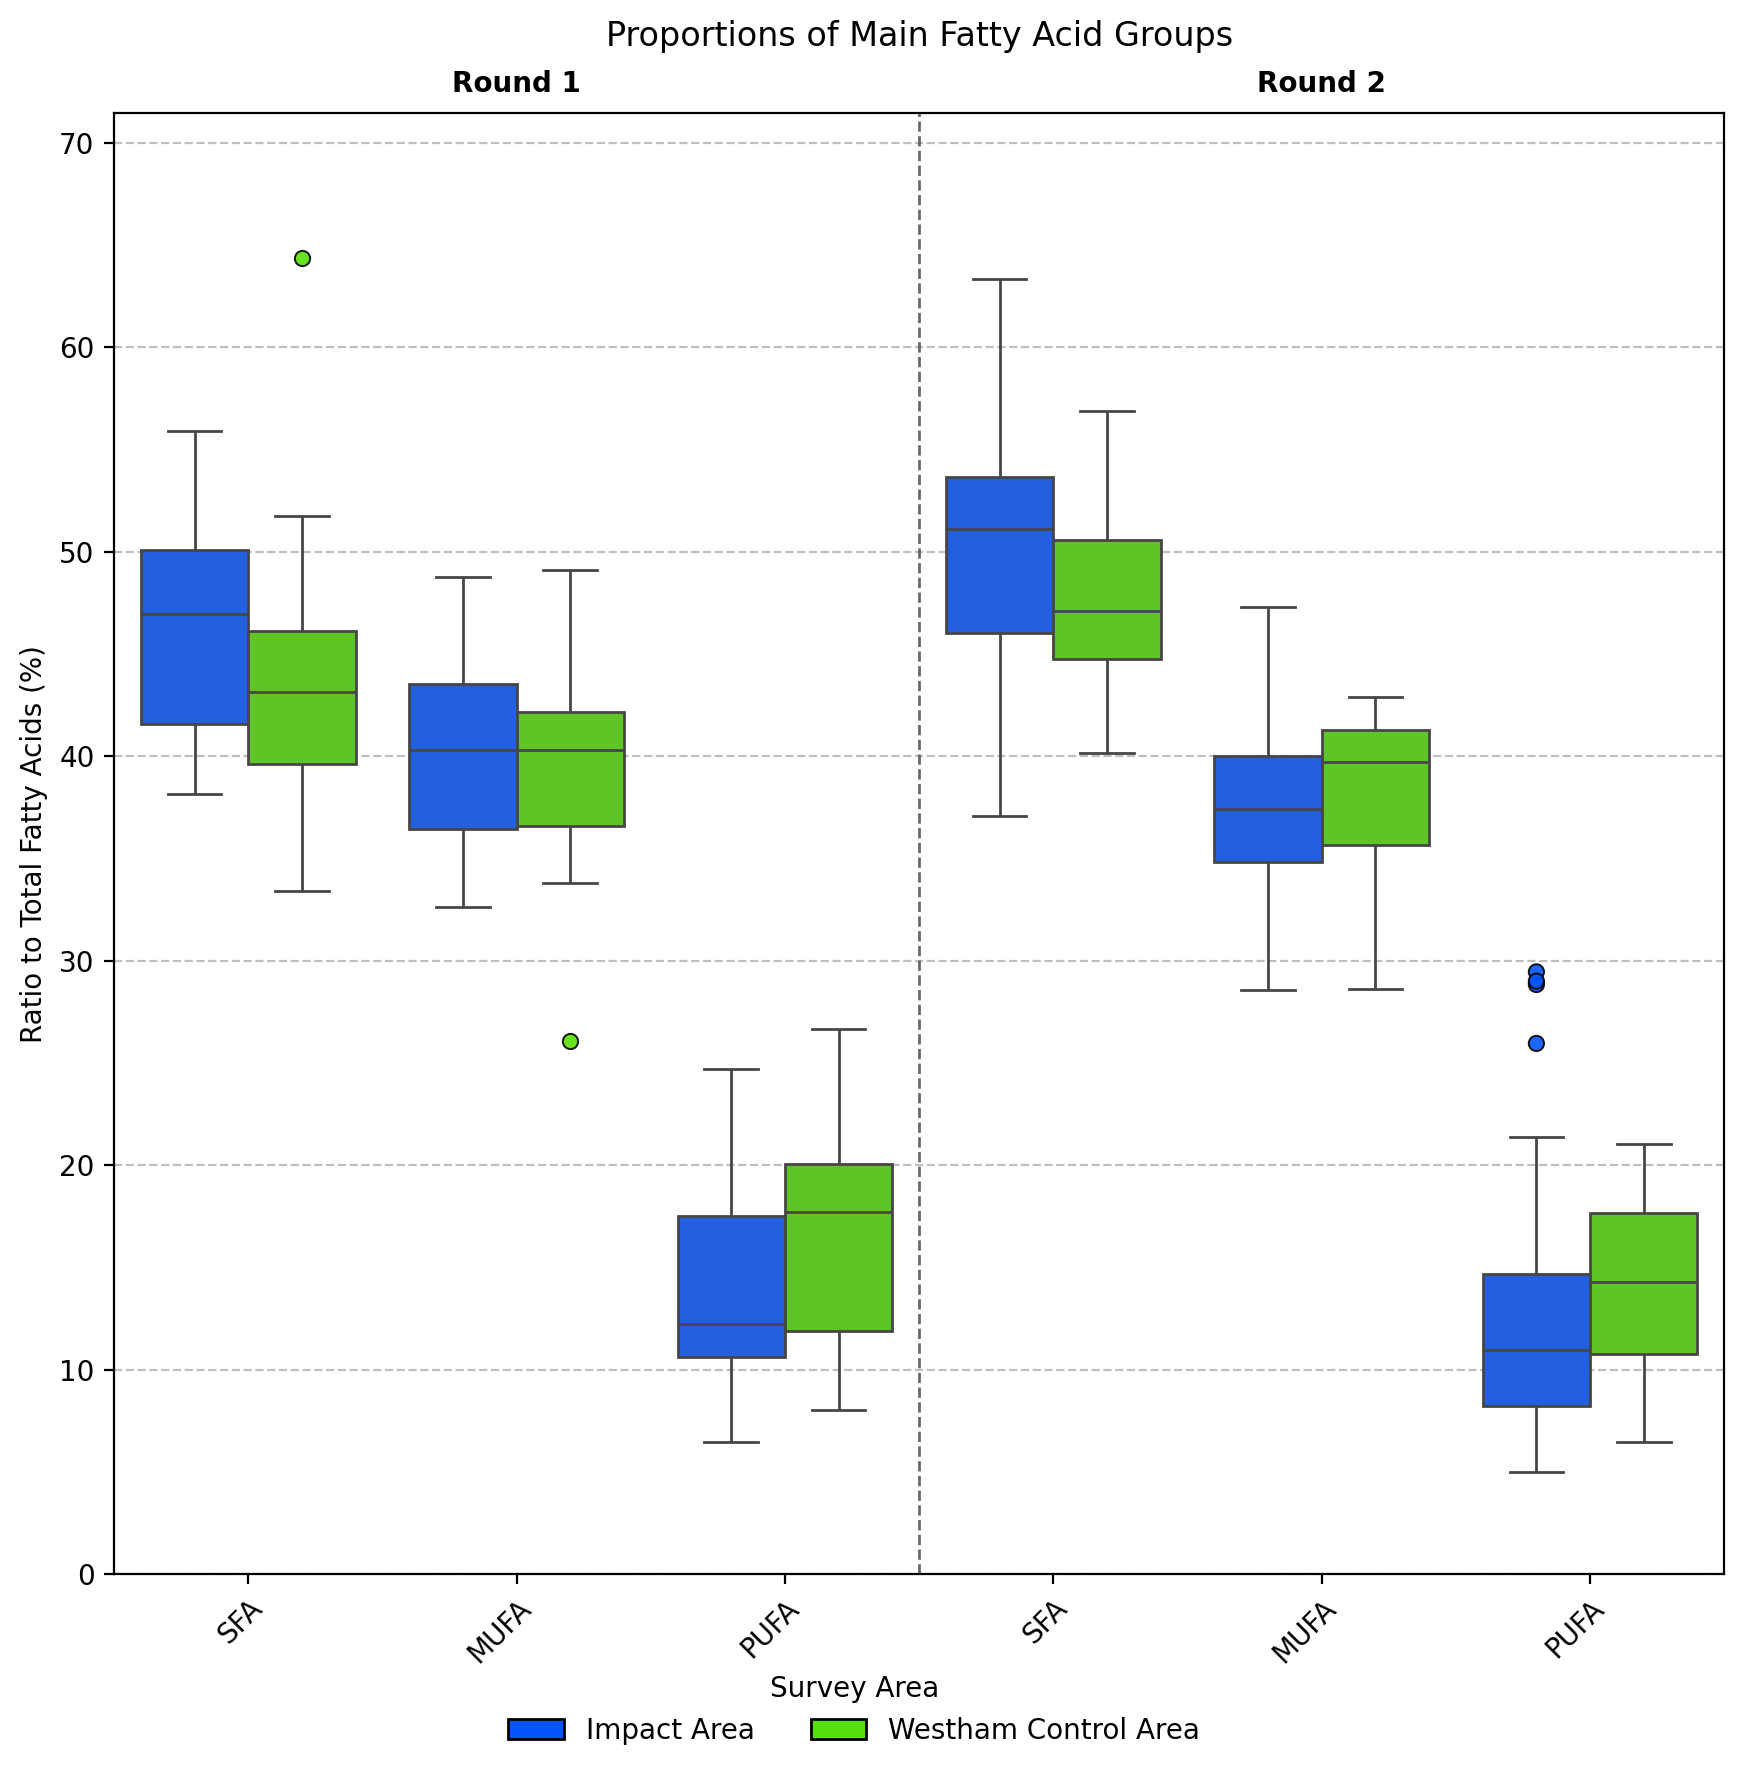

In [42]:
core_fa_ratio_columns = [f"Total {x} : Total FA (%)" for x in ['SFA', 'MUFA', 'PUFA']]
core_fa_ratio_labels = [f"{x}" for x in ['SFA', 'MUFA', 'PUFA']]

for round_number in [1, 2]:
    for site in SITES:
        # Print mean ratios
        # df_core_fa_ratios_sub = df_lab_r.loc[df_lab_r.index.get_level_values('station_id').str.startswith(site[0].upper()) &
        # df_lab_r.index.get_level_values('round') == round_number][core_fa_ratio_columns].replace(0, np.nan)
        df_core_fa_ratios_sub = df_lab_r.xs((site, round_number), level=('site','round'))[core_fa_ratio_columns]

        print(site, round_number)
        print(df_core_fa_ratios_sub.mean(axis=0))


fig, ax = draw_boxplots_2(
    df_lab_r,
    core_fa_ratio_columns,
    round_number=[1, 2],
    round_layout="horizontal",
    round_separator=True,
    title="Proportions of Main Fatty Acid Groups",
    y_scale="linear",
    y_label="Ratio to Total Fatty Acids (%)",
    variable_labels=core_fa_ratio_labels,
    show_y_grid=True,
    annotate_outliers=False,
    show_x_tick_labels=True,
    figsize=(9, 9),
)


In [43]:
# Sort and print mean concentrations for all FA
all_fa_columns = [f"{fa} ({fa_unit})" for fa in sorted(FA_LIST)]
df_all_fa = df_lab_r[all_fa_columns].replace(0, np.nan)

for round_number in [1, 2]:
    for site in SITES:
        df_all_fa_sub = df_all_fa.loc[df_all_fa.index.get_level_values('station_id').str.startswith(site[0].upper()) &
        df_all_fa.index.get_level_values('round') == round_number].copy()
        print(site, round_number, len(df_all_fa_sub))
        df_all_fa_sub_sorted = df_all_fa_sub.mean(axis=0).sort_values(ascending=False)
        df_all_fa_sub_sorted_norm = df_all_fa_sub_sorted/df_all_fa_sub_sorted.sum()
        print(df_all_fa_sub_sorted_norm.head(6))

brunswick 1 30
C16:1 (mg/m2)      0.353123
C16 (mg/m2)        0.298931
C20:5N3 (mg/m2)    0.079097
C15 (mg/m2)        0.061038
C14:0 (mg/m2)      0.036761
C18:0 (mg/m2)      0.024946
dtype: float64
westham 1 30
C16:1 (mg/m2)       0.339314
C16 (mg/m2)         0.268928
C20:5N3 (mg/m2)     0.104768
C18:1N9C (mg/m2)    0.034277
C14:0 (mg/m2)       0.032265
C15 (mg/m2)         0.031647
dtype: float64
brunswick 2 0
C10 (mg/m2)     NaN
C11 (mg/m2)     NaN
C12 (mg/m2)     NaN
C13 (mg/m2)     NaN
C14:0 (mg/m2)   NaN
C14:1 (mg/m2)   NaN
dtype: float64
westham 2 0
C10 (mg/m2)     NaN
C11 (mg/m2)     NaN
C12 (mg/m2)     NaN
C13 (mg/m2)     NaN
C14:0 (mg/m2)   NaN
C14:1 (mg/m2)   NaN
dtype: float64


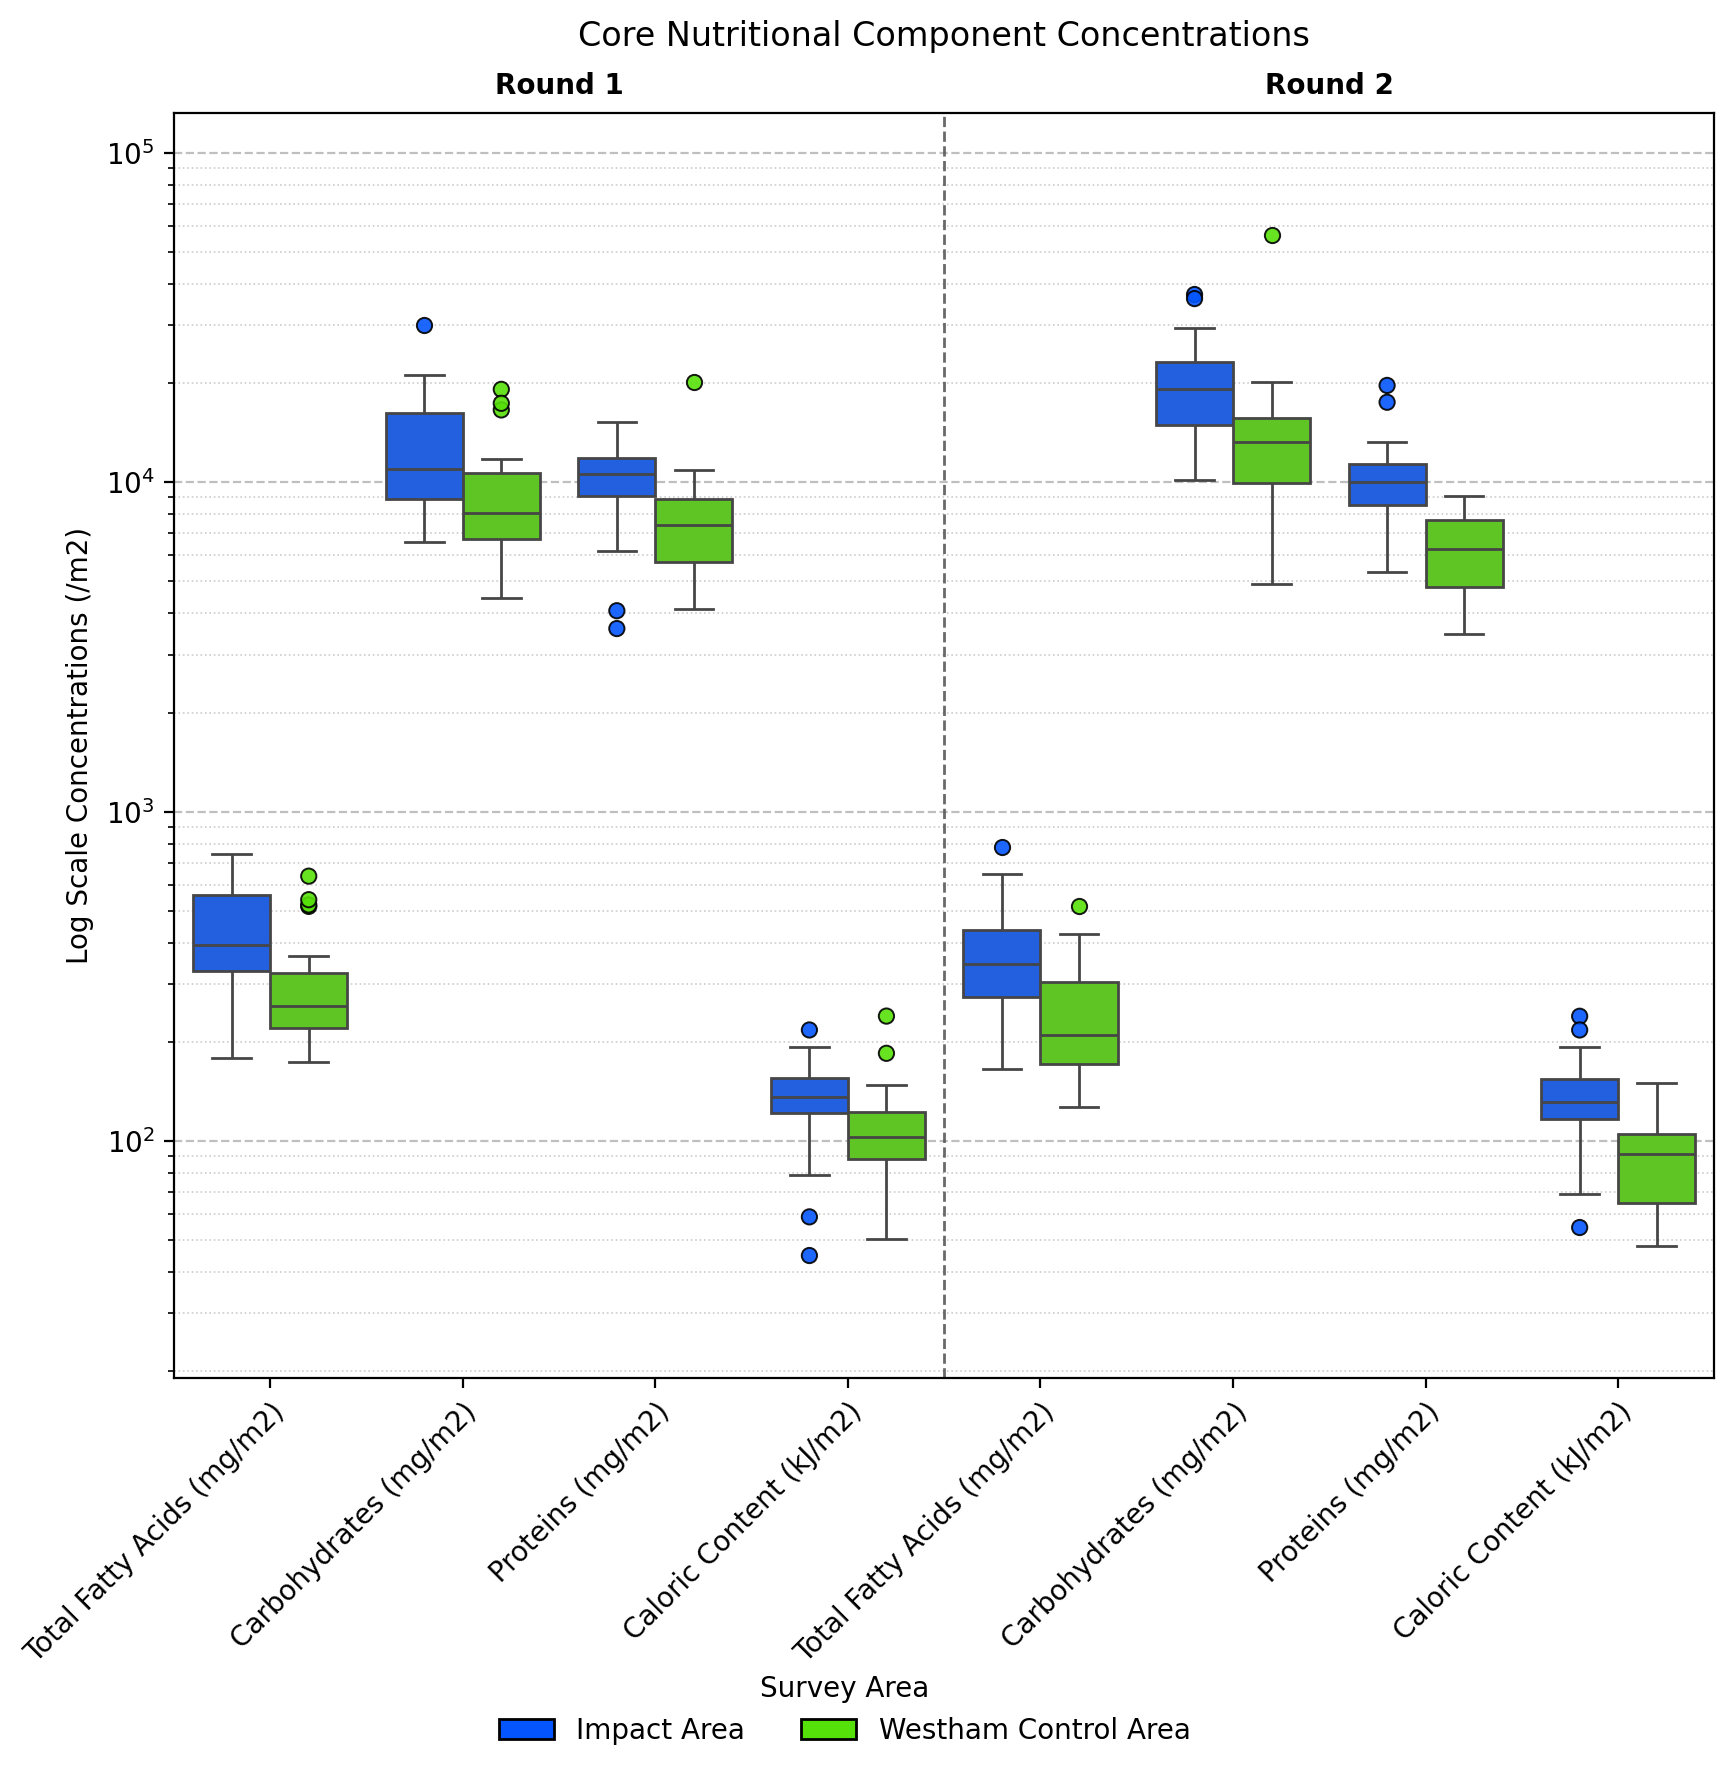

In [45]:
norm_unit = 'm2'
nutritional_unit = f'mg/{norm_unit}'
caloric_unit = f'kJ/{norm_unit}'
core_fa_columns = [
    f'Total FA ({nutritional_unit})',
    # f'Total SFA ({nutritional_unit})',
    # f'Total MUFA ({nutritional_unit})',
    # f'Total PUFA ({nutritional_unit})',
]
core_nutritional_columns = core_fa_columns + [
    f"Total Carbs ({nutritional_unit})",
    f"Proteins ({nutritional_unit})",
    f"Caloric ({caloric_unit})",
]
core_nutritional_labels = [
    f'Total Fatty Acids ({nutritional_unit})',
    # f'Total SFA ({nutritional_unit})',
    # f'Total MUFA ({nutritional_unit})',
    # f'Total PUFA ({nutritional_unit})',
] + [
    f"Carbohydrates ({nutritional_unit})",
    f"Proteins ({nutritional_unit})",
    f"Caloric Content ({caloric_unit})",
]

# for round_number in [1, 2]:
#     fig, ax = draw_boxplots(
#         df_lab_r,
#         core_nutritional_columns,
#         round_number=round_number,
#         title=f"Core Nutritional Concentrations \u2014 Round {round_number}",
#         y_scale="log",
#         y_min=10,
#         y_max=1e5,
#         annotate_outliers=False,
#         variable_labels=core_nutritional_labels,
#         y_label=f"Log Scale Concentration (/{norm_unit})",
#         figsize=(10,8),
#     )
#     path = path_output_dir / f"boxplots_core_nutritional_round_{round_number}.png"
#     fig.savefig(path, dpi=300, bbox_inches="tight")

# fig, ax = draw_boxplots(
#     df_lab_r,
#     core_nutritional_columns,
#     round_number=[1, 2],
#     title="Core Nutritional Concentrations by Survey Round",
#     figsize=(12, 10),
#     y_scale="symlog",
#     y_label=f"Concentration (/{norm_unit})",
#     variable_labels=core_nutritional_labels,
#     show_y_grid=True,
#     annotate_outliers=True,
# )
# path = path_output_dir / "boxplots_core_nutritional_rounds_1_and_2.png"
# fig.savefig(path, dpi=300, bbox_inches="tight")


fig, ax = draw_boxplots_2(
    df_lab_r,
    core_nutritional_columns,
    round_number=[1, 2],
    round_layout="horizontal",
    round_separator=True,
    title="Core Nutritional Component Concentrations",
    y_scale="log",
    y_label=f"Log Scale Concentrations (/{norm_unit})",
    variable_labels=core_nutritional_labels,
    show_y_grid=True,
    annotate_outliers=False,
    show_x_tick_labels=True,
    figsize=(9, 9),
)




### Sediment physical parameters

In [ ]:
SEDIMENT_UNIT = '%'
SEDIMENT_PARAMETERS_WITH_UNITS = [
    'Moisture (%)',
    'Percent Sand (%)',
    'Percent Silt (%)',
    'Percent Clay (%)'
]
SEDIMENT_PARAMETER_LABELS = [
    'Moisture',
    'Sand',
    'Silt',
    'Clay'
]

In [ ]:
for round_number in [1, 2]:
    fig, ax = draw_boxplots(
        df_lab_r,
        SEDIMENT_PARAMETERS_WITH_UNITS,
        round_number=round_number,
        title=f"Sediment Parameters \u2014 Round {round_number}",
        y_scale="symlog",
        annotate_outliers=True,
        variable_labels=SEDIMENT_PARAMETER_LABELS,
        y_label=f"Composition ({SEDIMENT_UNIT})",
    )
    path = path_output_dir / f"boxplots_sediment_parameters_round_{round_number}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")

fig, ax = draw_boxplots(
    df_lab_r,
    SEDIMENT_PARAMETERS_WITH_UNITS,
    round_number=[1, 2],
    title="Sediment Composition by Survey Round",
    figsize=(12, 10),
    y_scale="linear",
    y_label=f"Composition ({SEDIMENT_UNIT})",
    variable_labels=SEDIMENT_PARAMETER_LABELS,
    show_y_grid=True,
    annotate_outliers=True,
)
path = path_output_dir / "boxplots_sediment_parameters_rounds_1_and_2.png"
fig.savefig(path, dpi=300, bbox_inches="tight")


## Summary statistics

In [ ]:
import pandas as pd


def extract_site_round_summary(
    df,
    variables,
    round_number,
    stats=("min", "mean", "median", "std", "max"),
    sites=SITES,
    site_labels=SITE_LABELS,
    round_level="round",
    station_level="station_id",
    include_unknown=False,
    flatten_columns=False,
    variable_labels=None,
    value_format=None,
    variable_formats=None,
    return_styler=False,
    output="summary",
    mean_std_format="{mean:.3g} ± {std:.3g}",
    mean_std_formats=None,
    mean_std_label="Mean ± SD",
    missing_std="—",
):
    """
    Build a per-site summary table for one or multiple survey rounds.

    Parameters
    ----------
    df : pandas.DataFrame
        Input DataFrame with a MultiIndex containing round and station levels.
    variables : sequence of str
        Variable columns to summarize.
    round_number : int or sequence of int
        One round, such as 1, or multiple rounds, such as [1, 2].
    stats : sequence
        Aggregation statistics used when output="summary".
    sites : sequence
        Site names or identifiers used to infer site membership.
    site_labels : dict or sequence
        Display labels for sites.
    round_level : str, default "round"
        Name of the round index level.
    station_level : str, default "station_id"
        Name of the station index level.
    include_unknown : bool, default False
        Whether to retain stations that do not match a known site.
    flatten_columns : bool, default False
        Whether to flatten MultiIndex output columns.
    variable_labels : dict or sequence, optional
        Custom display names for variables.
    value_format : str or callable, optional
        Global numeric format used for a Styler when output="summary".
    variable_formats : dict, optional
        Per-variable numeric formats used when output="summary".
    return_styler : bool, default False
        Whether to return a pandas Styler.
    output : {"summary", "mean_std"}, default "summary"
        Output format:

        - "summary": return the requested numeric statistics.
        - "mean_std": return one formatted mean ± SD column per variable.

    mean_std_format : str or callable
        Format used for mean ± SD values. A string must contain the named
        fields ``mean`` and ``std``.

        Example: ``"{mean:.2f} ± {std:.2f}"``.

        A callable must accept two arguments: mean and standard deviation.
    mean_std_formats : dict, optional
        Per-variable mean ± SD formats. Keys can be original variable names
        or their display labels.
    mean_std_label : str, default "Mean ± SD"
        Label used for the combined statistic.
    missing_std : str, default "—"
        Text displayed when SD is unavailable, such as for a group with only
        one observation.

    Returns
    -------
    pandas.DataFrame or pandas.io.formats.style.Styler
        Index levels are Round and Survey Area.
    """

    # Normalize round_number
    if isinstance(round_number, (list, tuple, set)):
        round_numbers = list(round_number)
    else:
        round_numbers = [round_number]

    if not round_numbers:
        raise ValueError("At least one round number must be provided.")

    if not variables:
        raise ValueError("At least one variable must be provided.")

    valid_outputs = {
        "summary",
        "mean_std",
    }

    if output not in valid_outputs:
        raise ValueError(f"output must be one of {valid_outputs}; received {output!r}.")

    if output == "summary" and not stats:
        raise ValueError("At least one aggregation statistic must be provided.")

    # Create variable display-name mapping
    if variable_labels is None:
        variable_label_map = {variable: variable for variable in variables}

    elif isinstance(variable_labels, dict):
        variable_label_map = {
            variable: variable_labels.get(
                variable,
                variable,
            )
            for variable in variables
        }

    else:
        if len(variable_labels) != len(variables):
            raise ValueError(
                "The length of variable_labels must match the length "
                f"of variables. Received {len(variable_labels)} labels "
                f"for {len(variables)} variables."
            )

        variable_label_map = dict(zip(variables, variable_labels))

    # Create site display-name mapping
    if site_labels is None:
        site_label_map = {site: str(site) for site in sites}

    elif isinstance(site_labels, dict):
        site_label_map = {
            site: site_labels.get(
                site,
                str(site),
            )
            for site in sites
        }

    else:
        if len(site_labels) != len(sites):
            raise ValueError(
                "The length of site_labels must match the length "
                f"of sites. Received {len(site_labels)} labels "
                f"for {len(sites)} sites."
            )

        site_label_map = dict(zip(sites, site_labels))

    # Validate index levels
    required_levels = {
        round_level,
        station_level,
    }

    missing_levels = required_levels - set(df.index.names)

    if missing_levels:
        raise KeyError(
            "The DataFrame index is missing required level(s): "
            f"{sorted(missing_levels)}"
        )

    # Validate variables
    missing_variables = [
        variable for variable in variables if variable not in df.columns
    ]

    if missing_variables:
        raise KeyError(
            "The following variables were not found in the DataFrame: "
            f"{missing_variables}"
        )

    # Filter rounds
    round_mask = df.index.get_level_values(round_level).isin(round_numbers)

    df_filtered = df.loc[
        round_mask,
        list(variables),
    ].copy()

    if df_filtered.empty:
        raise ValueError(f"No rows were found for round(s): {round_numbers}")

    df_filtered = df_filtered.reset_index()

    # Assign survey area from station ID
    def infer_site(station_id):
        station_id = str(station_id)

        matched_site = next(
            (site for site in sites if station_id.startswith(str(site)[0].upper())),
            None,
        )

        if matched_site is None:
            return "Unknown"

        return site_label_map.get(
            matched_site,
            str(matched_site),
        )

    df_filtered["Survey Area"] = df_filtered[station_level].map(infer_site)

    # Standardize the round column name
    df_filtered = df_filtered.rename(
        columns={
            round_level: "Round",
        }
    )

    if not include_unknown:
        df_filtered = df_filtered.loc[df_filtered["Survey Area"] != "Unknown"]

    if df_filtered.empty:
        raise ValueError("No rows remained after site filtering.")

    grouped = df_filtered.groupby(
        [
            "Round",
            "Survey Area",
        ],
        observed=True,
    )[list(variables)]

    # ==================================================================
    # Standard numeric summary
    # ==================================================================
    if output == "summary":
        summary = grouped.agg(list(stats)).sort_index()

        summary = summary.rename(
            columns=variable_label_map,
            level=0,
        )

        summary.columns.names = [
            "Variable",
            "Stat",
        ]

        if flatten_columns:
            flattened_columns = []

            for variable, stat in summary.columns:
                if isinstance(stat, str):
                    stat_name = stat
                else:
                    stat_name = getattr(
                        stat,
                        "__name__",
                        str(stat),
                    )

                flattened_columns.append(f"{variable}__{stat_name}")

            summary.columns = flattened_columns

        if not return_styler:
            return summary

        styled = summary.style

        if value_format is not None:
            styled = styled.format(value_format)

        if variable_formats:
            if flatten_columns:
                for variable, fmt in variable_formats.items():
                    display_variable = variable_label_map.get(
                        variable,
                        variable,
                    )

                    matching_columns = [
                        column
                        for column in summary.columns
                        if (
                            isinstance(column, str)
                            and column.startswith(f"{display_variable}__")
                        )
                    ]

                    if matching_columns:
                        styled = styled.format(
                            fmt,
                            subset=pd.IndexSlice[
                                :,
                                matching_columns,
                            ],
                        )

            else:
                for variable, fmt in variable_formats.items():
                    display_variable = variable_label_map.get(
                        variable,
                        variable,
                    )

                    matching_columns = [
                        column
                        for column in summary.columns
                        if column[0] == display_variable
                    ]

                    if matching_columns:
                        styled = styled.format(
                            fmt,
                            subset=pd.IndexSlice[
                                :,
                                matching_columns,
                            ],
                        )

        return styled

    # ==================================================================
    # Combined mean ± SD output
    # ==================================================================
    numeric_mean_std = grouped.agg(["mean", "std"]).sort_index()

    mean_std_formats = {} if mean_std_formats is None else mean_std_formats

    combined_columns = {}

    for variable in variables:
        display_variable = variable_label_map[variable]

        means = numeric_mean_std[
            (
                variable,
                "mean",
            )
        ]

        standard_deviations = numeric_mean_std[
            (
                variable,
                "std",
            )
        ]

        variable_format = mean_std_formats.get(
            variable,
            mean_std_formats.get(
                display_variable,
                mean_std_format,
            ),
        )

        formatted_values = []

        for mean, std in zip(
            means,
            standard_deviations,
        ):
            if pd.isna(mean):
                formatted_value = "—"

            elif pd.isna(std):
                formatted_value = f"{mean:.3g} ± {missing_std}"

            elif callable(variable_format):
                formatted_value = variable_format(
                    mean,
                    std,
                )

            else:
                formatted_value = variable_format.format(
                    mean=mean,
                    std=std,
                )

            formatted_values.append(formatted_value)

        combined_columns[
            (
                display_variable,
                mean_std_label,
            )
        ] = formatted_values

    summary = pd.DataFrame(
        combined_columns,
        index=numeric_mean_std.index,
    )

    summary.columns = pd.MultiIndex.from_tuples(
        summary.columns,
        names=[
            "Variable",
            "Stat",
        ],
    )

    if flatten_columns:
        summary.columns = [f"{variable}__{stat}" for variable, stat in summary.columns]

    if return_styler:
        return summary.style

    return summary


In [ ]:
summary_custom = extract_site_round_summary(
    df_lab_r,
    variables=core_pigment_columns,
    round_number=[1, 2],
    stats=("mean", "std"),
    flatten_columns=False,
    return_styler=True,
    # variable_formats={"Chla : Phta": "{:.2f}"},
    variable_labels=CORE_PIGMENT_FULL_LABELS.values(),
    value_format="{:.1e}",
)

display(summary_custom)

core_pigment_columns_norm = [
    f"{pigment} : {NORMALIZING_CHLA_COLUMN}"
    for pigment in CORE_PIGMENTS
    if pigment != NORMALIZING_CHLA_COLUMN
]
core_pigment_labels_norm = [
    f"{label} : {NORMALIZING_CHLA_COLUMN}"
    for label in CORE_PIGMENT_FULL_LABELS.values()
    if label != CORE_PIGMENT_FULL_LABELS.get(NORMALIZING_CHLA_COLUMN, '')
]
summary_custom = extract_site_round_summary(
    df_lab_r,
    variables=[f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})"]
    + core_pigment_columns_norm,
    round_number=[1, 2],
    stats=("mean", "median", "std"),
    flatten_columns=False,
    return_styler=True,
    # variable_formats={"Chla : Phta": "{:.2f}"},
    variable_labels=[NORMALIZING_CHLA_COLUMN] + core_pigment_labels_norm,
    value_format="{:.3f}",
    variable_formats={f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})": "{:.1e}"},
)

display(summary_custom)

mean_std = extract_site_round_summary(
    df=df_lab_r,
    variables=[f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})"] + core_pigment_columns_norm,
    round_number=[1, 2],
    # variable_labels=[CORE_PIGMENT_FULL_LABELS["Chla"]] + core_pigment_labels_norm,
    output="mean_std",
    mean_std_format="{mean:.4f} ± {std:.4f}",
    mean_std_formats={
        f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})": "{mean:.3f} ± {std:.3f}",
        # core_pigment_columns_norm[0]: "{mean:.2e} ± {std:.2e}",
    },
)

display(mean_std)

In [ ]:
core_fa_columns_norm = [f"{fa} : {NORMALIZING_CHLA_COLUMN}" for fa in CORE_FA]
core_fa_labels_norm = [f"{label} : {NORMALIZING_CHLA_COLUMN}" for label in CORE_FA_LABELS]

summary_custom = extract_site_round_summary(
    df_lab_r,
    variables=core_fa_columns_norm,
    round_number=[1, 2],
    stats=("mean", "std"),
    flatten_columns=False,
    return_styler=True,
    # variable_formats={"Chla : Phta": "{:.2f}"},
    variable_labels=core_fa_labels_norm,
    value_format="{:.2f}",
)

display(summary_custom)

mean_std = extract_site_round_summary(
    df_lab_r,
    variables=[f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})"] + core_fa_columns_norm,
    round_number=[1, 2],
    output="mean_std",
    mean_std_format="{mean:.2f} ± {std:.2f}",
    mean_std_formats={
        f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})": "{mean:.4f} ± {std:.4f}",
    },
    variable_labels=[NORMALIZING_CHLA_COLUMN + f" ({pigment_unit})"] + core_fa_labels_norm
)
display(mean_std)

# Save to CSV
path = path_output_dir / "summary_fa_concentration_normalized.csv"
mean_std.to_csv(path, index=False)



In [ ]:
summary_custom = extract_site_round_summary(
    df=(df_lab_r.copy()
    .assign(**{"Chla : Phta": df_lab_r["Chla : Phta"].replace([np.inf, -np.inf], np.nan)})
    .dropna(subset=["Chla : Phta"])
    ),
    variables=["Chla : Phta"],
    round_number=[1, 2],
    stats=("mean", "median", "std"),
    flatten_columns=False,
    return_styler=True,
    variable_formats={"Chla : Phta": "{:.2f}"},
)

display(summary_custom)


## Distribution difference?

In [ ]:
from analysis.distribution_analysis import (
    extract_station_round,
    analyze_two_group_two_round,
    analysis_tables,
    markdown_report,
)

VARIABLE = "Chla : Phta"

GROUP_B_PREFIX = "B"
GROUP_B_LABEL = "Impact Area (B)"

GROUP_W_PREFIX = "W"
GROUP_W_LABEL = "Westham Control Area (W)"

b_round_1 = extract_station_round(
    df_lab_r,
    VARIABLE,
    group_prefix=GROUP_B_PREFIX,
    round_value=1,
)

b_round_2 = extract_station_round(
    df_lab_r,
    VARIABLE,
    group_prefix=GROUP_B_PREFIX,
    round_value=2,
)

w_round_1 = extract_station_round(
    df_lab_r,
    VARIABLE,
    group_prefix=GROUP_W_PREFIX,
    round_value=1,
)

w_round_2 = extract_station_round(
    df_lab_r,
    VARIABLE,
    group_prefix=GROUP_W_PREFIX,
    round_value=2,
)

results = analyze_two_group_two_round(
    b_round_1,
    b_round_2,
    w_round_1,
    w_round_2,
    group_a=GROUP_B_LABEL,
    group_b=GROUP_W_LABEL,
    round_1_label="Round 1",
    round_2_label="Round 2",
    variable=VARIABLE,
    alpha=0.05,
    n_permutations=9999,
    seed=123,
    run_energy_tests=True,
)

tables = analysis_tables(results)

display(tables["descriptive"])
display(tables["mean_tests"])
display(tables["distribution_tests"])

report = markdown_report(results)
print(report)


In [ ]:
for variable in [
    "Total SFA (mg/g)",
    "Total MUFA (mg/g)",
    "Total PUFA (mg/g)",
    "Total FA (mg/g)",
]:

    b_round_1 = extract_station_round(
        df_lab_r,
        variable,
        group_prefix=GROUP_B_PREFIX,
        round_value=1,
    )

    b_round_2 = extract_station_round(
        df_lab_r,
        variable,
        group_prefix=GROUP_B_PREFIX,
        round_value=2,
    )

    w_round_1 = extract_station_round(
        df_lab_r,
        variable,
        group_prefix=GROUP_W_PREFIX,
        round_value=1,
    )

    w_round_2 = extract_station_round(
        df_lab_r,
        variable,
        group_prefix=GROUP_W_PREFIX,
        round_value=2,
    )

    results = analyze_two_group_two_round(
        b_round_1,
        b_round_2,
        w_round_1,
        w_round_2,
        group_a=GROUP_B_LABEL,
        group_b=GROUP_W_LABEL,
        round_1_label="Round 1",
        round_2_label="Round 2",
        variable=variable,
        alpha=0.05,
        n_permutations=9999,
        seed=123,
        run_energy_tests=True,
    )

    # tables = analysis_tables(results)
    report = markdown_report(results)
    print(report, '\n\n\n\n')

## Correlation heatmap

In [ ]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr, kendalltau


def draw_correlation_heatmap(
    df,
    variables,
    round_number=None,
    survey_area=None,
    sites=None,
    site_labels=None,
    calculation="independent",
    independent_annotation="range",
    variable_labels=None,
    method="pearson",
    min_periods=3,
    calculate_significance=True,
    p_adjust="fdr_bh",
    significance_levels=(0.05, 0.01, 0.001),
    require_same_direction=True,
    hide_counts_when_single_subgroup=True,
    pooled_pvalue_method="none",
    title=None,
    figsize=None,
    cmap="RdBu_r",
    annot=True,
    fmt=".2f",
    std_fmt=None,
    range_fmt=None,
    mask_upper=True,
    show_diagonal=True,
    show_diagonal_values=False,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_label=None,
    round_level="round",
    station_level="station_id",
    include_unknown=False,
    x_rotation=45,
    bold_significant=True,
    show_significance_legend=True,
    show=True,
):
    """
    Draw a correlation heatmap using pooled observations or stratified
    round-survey-area subgroup results.

    Independent calculation
    -----------------------
    A separate correlation matrix is calculated for each selected
    round-survey-area subgroup. Heatmap colors represent the arithmetic mean
    correlation. Cell annotations can show the subgroup SD, range, or mean
    only.

    Significance is summarized using mutually exclusive adjusted-p categories.
    For example::

        *** [2,1,1]

    means:

    - 2 eligible subgroups have adjusted p < 0.001;
    - 1 has 0.001 <= adjusted p < 0.01;
    - 1 has 0.01 <= adjusted p < 0.05.

    Counts are displayed from the strongest category represented down to the
    weakest category. By default, only subgroup correlations with the same
    direction as the displayed mean are counted.

    Pooled calculation
    ------------------
    All selected rows are correlated together. If
    ``pooled_pvalue_method="analytic"``, one adjusted p-value is calculated
    for each variable pair and displayed using ordinary stars. Because rows
    from repeated stations are not independent, pooled analytic p-values
    should be interpreted cautiously; the default is ``"none"``.

    Parameters
    ----------
    calculation : {"independent", "pooled"}
        Independent summarizes round-survey-area correlation matrices.
        Pooled calculates one correlation matrix from all selected rows.
    independent_annotation : {"std", "range", "none"}
        Additional independent-mode annotation below the mean.
    p_adjust : {"fdr_bh", "holm", "bonferroni", "none"}
        Multiple-testing adjustment across unique variable pairs.
    significance_levels : tuple
        Weak-to-strong thresholds, normally (0.05, 0.01, 0.001).
    hide_counts_when_single_subgroup : bool
        If True, show stars without category counts when only one valid
        subgroup contributes to a variable pair.
    pooled_pvalue_method : {"none", "analytic"}
        Enable or disable conventional pooled p-values.
    """

    # ------------------------------------------------------------------
    # Helpers
    # ------------------------------------------------------------------
    # superscript_translation = str.maketrans(
    #     "0123456789-",
    #     "⁰¹²³⁴⁵⁶⁷⁸⁹⁻",
    # )

    # def superscript_number(value):
    #     return str(int(value)).translate(superscript_translation)

    def pairwise_statistics(data):
        """Return symmetric coefficient, raw-p, and paired-n matrices."""
        count = len(variables)
        coefficients = np.full((count, count), np.nan, dtype=float)
        pvalues = np.full((count, count), np.nan, dtype=float)
        sample_sizes = np.zeros((count, count), dtype=int)

        for i, variable_x in enumerate(variables):
            diagonal_n = int(data[variable_x].notna().sum())
            sample_sizes[i, i] = diagonal_n

            if diagonal_n >= min_periods:
                coefficients[i, i] = 1.0

            for j in range(i):
                variable_y = variables[j]
                pair = data[[variable_x, variable_y]].dropna()
                n = len(pair)

                sample_sizes[i, j] = n
                sample_sizes[j, i] = n

                if n < min_periods:
                    continue

                x = pair[variable_x].to_numpy(dtype=float)
                y = pair[variable_y].to_numpy(dtype=float)

                if np.all(x == x[0]) or np.all(y == y[0]):
                    continue

                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")

                    if method == "pearson":
                        result = pearsonr(x, y)
                    elif method == "spearman":
                        result = spearmanr(x, y)
                    else:
                        result = kendalltau(x, y)

                coefficient = float(result.statistic)
                pvalue = float(result.pvalue)

                coefficients[i, j] = coefficient
                coefficients[j, i] = coefficient
                pvalues[i, j] = pvalue
                pvalues[j, i] = pvalue

        index = columns = variables

        return (
            pd.DataFrame(coefficients, index=index, columns=columns),
            pd.DataFrame(pvalues, index=index, columns=columns),
            pd.DataFrame(sample_sizes, index=index, columns=columns),
        )

    def adjust_pvalue_matrix(raw_matrix):
        """Adjust finite p-values from the unique lower triangle."""
        adjusted = pd.DataFrame(
            np.nan,
            index=raw_matrix.index,
            columns=raw_matrix.columns,
            dtype=float,
        )

        lower_rows, lower_columns = np.tril_indices(
            len(raw_matrix),
            k=-1,
        )

        locations = []
        raw_values = []

        for i, j in zip(lower_rows, lower_columns):
            value = raw_matrix.iat[i, j]

            if pd.notna(value):
                locations.append((i, j))
                raw_values.append(float(value))

        if not raw_values:
            return adjusted

        raw_values = np.asarray(raw_values)
        number_of_tests = len(raw_values)

        if p_adjust == "none":
            adjusted_values = raw_values.copy()

        elif p_adjust == "bonferroni":
            adjusted_values = np.minimum(
                raw_values * number_of_tests,
                1.0,
            )

        else:
            order = np.argsort(raw_values)
            ordered = raw_values[order]

            if p_adjust == "fdr_bh":
                ranks = np.arange(1, number_of_tests + 1)
                ordered_adjusted = ordered * number_of_tests / ranks
                ordered_adjusted = np.minimum.accumulate(ordered_adjusted[::-1])[::-1]

            else:  # Holm
                multipliers = number_of_tests - np.arange(number_of_tests)
                ordered_adjusted = ordered * multipliers
                ordered_adjusted = np.maximum.accumulate(ordered_adjusted)

            ordered_adjusted = np.minimum(ordered_adjusted, 1.0)
            adjusted_values = np.empty_like(ordered_adjusted)
            adjusted_values[order] = ordered_adjusted

        for (i, j), value in zip(locations, adjusted_values):
            adjusted.iat[i, j] = value
            adjusted.iat[j, i] = value

        return adjusted

    def apply_labels(matrix):
        if matrix is None:
            return None

        return matrix.rename(
            index=variable_label_map,
            columns=variable_label_map,
        )

    def strongest_star(adjusted_p):
        if pd.isna(adjusted_p):
            return ""

        for level_index in reversed(range(len(significance_levels))):
            if adjusted_p < significance_levels[level_index]:
                return "*" * (level_index + 1)

        return ""

    # ------------------------------------------------------------------
    # Validation
    # ------------------------------------------------------------------
    if not variables:
        raise ValueError("At least one variable must be provided.")

    variables = list(variables)

    if len(variables) < 2:
        raise ValueError(
            "At least two variables are required for a correlation matrix."
        )

    missing_variables = [
        variable for variable in variables if variable not in df.columns
    ]
    if missing_variables:
        raise KeyError(f"Variables not found in the DataFrame: {missing_variables}")

    method = method.lower()
    if method not in {"pearson", "spearman", "kendall"}:
        raise ValueError("method must be 'pearson', 'spearman', or 'kendall'.")

    calculation = calculation.lower()
    if calculation not in {"independent", "pooled"}:
        raise ValueError("calculation must be 'independent' or 'pooled'.")

    independent_annotation = independent_annotation.lower()
    if independent_annotation not in {"std", "range", "none"}:
        raise ValueError("independent_annotation must be 'std', 'range', or 'none'.")

    p_adjust = p_adjust.lower()
    if p_adjust not in {"fdr_bh", "holm", "bonferroni", "none"}:
        raise ValueError("p_adjust must be 'fdr_bh', 'holm', 'bonferroni', or 'none'.")

    pooled_pvalue_method = pooled_pvalue_method.lower()
    if pooled_pvalue_method not in {"none", "analytic"}:
        raise ValueError("pooled_pvalue_method must be 'none' or 'analytic'.")

    significance_levels = tuple(float(level) for level in significance_levels)

    if (
        not significance_levels
        or any(level <= 0 or level >= 1 for level in significance_levels)
        or any(
            significance_levels[index] <= significance_levels[index + 1]
            for index in range(len(significance_levels) - 1)
        )
    ):
        raise ValueError(
            "significance_levels must be weak-to-strong, for example "
            "(0.05, 0.01, 0.001)."
        )

    if min_periods < 2:
        raise ValueError("min_periods must be at least 2.")

    required_levels = {round_level, station_level}
    missing_levels = required_levels - set(df.index.names)

    if missing_levels:
        raise KeyError(
            "The DataFrame index is missing required level(s): "
            f"{sorted(missing_levels)}"
        )

    if sites is None:
        raise ValueError("'sites' must be provided.")

    sites = list(sites)

    # ------------------------------------------------------------------
    # Labels
    # ------------------------------------------------------------------
    if variable_labels is None:
        variable_label_map = {variable: variable for variable in variables}
    elif isinstance(variable_labels, dict):
        variable_label_map = {
            variable: variable_labels.get(variable, variable) for variable in variables
        }
    else:
        if len(variable_labels) != len(variables):
            raise ValueError("variable_labels must have the same length as variables.")

        variable_label_map = dict(zip(variables, variable_labels))

    if len(set(variable_label_map.values())) != len(variables):
        raise ValueError("Variable display labels must be unique.")

    if site_labels is None:
        survey_area_label_map = {area: str(area) for area in sites}
    elif isinstance(site_labels, dict):
        survey_area_label_map = {
            area: site_labels.get(area, str(area)) for area in sites
        }
    else:
        if len(site_labels) != len(sites):
            raise ValueError("site_labels must have the same length as sites.")

        survey_area_label_map = dict(zip(sites, site_labels))

    survey_area_label_map["Unknown"] = "Unknown"

    # ------------------------------------------------------------------
    # Select rounds
    # ------------------------------------------------------------------
    available_rounds = list(pd.unique(df.index.get_level_values(round_level)))

    if round_number is None:
        selected_rounds = available_rounds
    elif isinstance(round_number, (list, tuple, set)):
        selected_rounds = list(round_number)
    else:
        selected_rounds = [round_number]

    missing_rounds = [
        value for value in selected_rounds if value not in set(available_rounds)
    ]

    if missing_rounds:
        raise KeyError(f"Round(s) not found in the DataFrame: {missing_rounds}")

    # ------------------------------------------------------------------
    # Select survey areas
    # ------------------------------------------------------------------
    label_to_area = {label: area for area, label in survey_area_label_map.items()}

    if survey_area is None:
        selected_area_ids = list(sites)

        if include_unknown:
            selected_area_ids.append("Unknown")
    else:
        requested_areas = (
            list(survey_area)
            if isinstance(survey_area, (list, tuple, set))
            else [survey_area]
        )

        selected_area_ids = []

        for requested in requested_areas:
            if requested in sites or requested == "Unknown":
                selected_area_ids.append(requested)
            elif requested in label_to_area:
                selected_area_ids.append(label_to_area[requested])
            else:
                raise KeyError(f"Unknown survey area: {requested!r}")

    selected_area_ids = list(dict.fromkeys(selected_area_ids))

    if "Unknown" in selected_area_ids and not include_unknown:
        raise ValueError("Set include_unknown=True to include Unknown.")

    # ------------------------------------------------------------------
    # Filter and identify survey areas
    # ------------------------------------------------------------------
    round_mask = df.index.get_level_values(round_level).isin(selected_rounds)

    data = df.loc[round_mask, variables].copy().reset_index()

    if data.empty:
        raise ValueError("No rows remained after round filtering.")

    def infer_survey_area(station_id):
        station_id = str(station_id)

        return next(
            (area for area in sites if station_id.startswith(str(area)[0].upper())),
            "Unknown",
        )

    data["_survey_area_id"] = data[station_level].map(infer_survey_area)

    data = data.loc[data["_survey_area_id"].isin(selected_area_ids)].copy()

    if data.empty:
        raise ValueError("No rows remained after survey-area filtering.")

    nonnumeric = [
        variable
        for variable in variables
        if not pd.api.types.is_numeric_dtype(data[variable])
    ]

    if nonnumeric:
        raise TypeError(f"Correlation variables must be numeric: {nonnumeric}")

    # ------------------------------------------------------------------
    # Calculate pooled or subgroup matrices
    # ------------------------------------------------------------------
    group_correlations = {}
    group_p_values_raw = {}
    group_p_values_adjusted = {}
    group_sample_sizes = {}

    pooled_p_values_raw = None
    pooled_p_values_adjusted = None

    if calculation == "pooled":
        (
            mean_correlation,
            calculated_p_values,
            pooled_sample_sizes,
        ) = pairwise_statistics(data)

        std_correlation = None
        min_correlation = None
        max_correlation = None
        valid_group_counts = mean_correlation.notna().astype(int)

        group_correlations["pooled"] = mean_correlation.copy()
        group_sample_sizes["pooled"] = pooled_sample_sizes

        if calculate_significance and pooled_pvalue_method == "analytic":
            warnings.warn(
                "Pooled analytic p-values treat rows as independent. "
                "Repeated stations across rounds can violate that "
                "assumption; interpret these stars cautiously.",
                UserWarning,
                stacklevel=2,
            )

            pooled_p_values_raw = calculated_p_values
            pooled_p_values_adjusted = adjust_pvalue_matrix(pooled_p_values_raw)
            group_p_values_raw["pooled"] = pooled_p_values_raw.copy()
            group_p_values_adjusted["pooled"] = pooled_p_values_adjusted.copy()

    else:
        for (
            current_round,
            area_id,
        ), subgroup in data.groupby(
            [round_level, "_survey_area_id"],
            observed=True,
            sort=False,
        ):
            (
                correlation_matrix,
                raw_p_matrix,
                sample_size_matrix,
            ) = pairwise_statistics(subgroup)

            group_key = (
                current_round,
                survey_area_label_map.get(
                    area_id,
                    str(area_id),
                ),
            )

            group_correlations[group_key] = correlation_matrix
            group_sample_sizes[group_key] = sample_size_matrix

            if calculate_significance:
                group_p_values_raw[group_key] = raw_p_matrix
                group_p_values_adjusted[group_key] = adjust_pvalue_matrix(raw_p_matrix)

        if not group_correlations:
            raise ValueError("No round-survey-area subgroups were available.")

        coefficient_stack = np.stack(
            [matrix.to_numpy(dtype=float) for matrix in group_correlations.values()],
            axis=0,
        )

        valid = np.isfinite(coefficient_stack)
        valid_counts_array = valid.sum(axis=0)

        coefficient_sum = np.where(
            valid,
            coefficient_stack,
            0.0,
        ).sum(axis=0)

        mean_array = np.divide(
            coefficient_sum,
            valid_counts_array,
            out=np.full_like(
                coefficient_sum,
                np.nan,
                dtype=float,
            ),
            where=valid_counts_array > 0,
        )

        squared_deviations = np.where(
            valid,
            (coefficient_stack - mean_array) ** 2,
            0.0,
        ).sum(axis=0)

        std_array = np.sqrt(
            np.divide(
                squared_deviations,
                valid_counts_array - 1,
                out=np.full_like(
                    squared_deviations,
                    np.nan,
                ),
                where=valid_counts_array > 1,
            )
        )

        min_array = np.where(
            valid,
            coefficient_stack,
            np.inf,
        ).min(axis=0)

        min_array = np.where(
            valid_counts_array > 0,
            min_array,
            np.nan,
        )

        max_array = np.where(
            valid,
            coefficient_stack,
            -np.inf,
        ).max(axis=0)

        max_array = np.where(
            valid_counts_array > 0,
            max_array,
            np.nan,
        )

        mean_correlation = pd.DataFrame(
            mean_array,
            index=variables,
            columns=variables,
        )
        std_correlation = pd.DataFrame(
            std_array,
            index=variables,
            columns=variables,
        )
        min_correlation = pd.DataFrame(
            min_array,
            index=variables,
            columns=variables,
        )
        max_correlation = pd.DataFrame(
            max_array,
            index=variables,
            columns=variables,
        )
        valid_group_counts = pd.DataFrame(
            valid_counts_array,
            index=variables,
            columns=variables,
        )

    # ------------------------------------------------------------------
    # Create significance labels
    # ------------------------------------------------------------------
    significance_labels = pd.DataFrame(
        "",
        index=variables,
        columns=variables,
        dtype=object,
    )

    significance_symbols = pd.DataFrame(
        "",
        index=variables,
        columns=variables,
        dtype=object,
    )

    exclusive_category_count_matrices = {
        "*" * (index + 1): pd.DataFrame(
            0,
            index=variables,
            columns=variables,
            dtype=int,
        )
        for index in range(len(significance_levels))
    }

    nonsignificant_counts = pd.DataFrame(
        0,
        index=variables,
        columns=variables,
        dtype=int,
    )

    opposite_direction_significant_counts = pd.DataFrame(
        0,
        index=variables,
        columns=variables,
        dtype=int,
    )

    valid_subgroup_test_counts = pd.DataFrame(
        0,
        index=variables,
        columns=variables,
        dtype=int,
    )

    if calculate_significance:
        if calculation == "independent":
            group_keys = list(group_correlations)

            for i in range(len(variables)):
                for j in range(i):
                    mean_value = mean_correlation.iat[i, j]
                    category_counts = [0 for _ in significance_levels]
                    nonsignificant_count = 0
                    opposite_count = 0
                    valid_subgroup_count = 0

                    for group_key in group_keys:
                        subgroup_r = group_correlations[group_key].iat[i, j]

                        adjusted_p = group_p_values_adjusted[group_key].iat[i, j]

                        if pd.isna(subgroup_r) or pd.isna(adjusted_p):
                            continue

                        valid_subgroup_count += 1

                        same_direction = not require_same_direction or (
                            pd.notna(mean_value)
                            and mean_value != 0
                            and np.sign(subgroup_r) == np.sign(mean_value)
                        )

                        category_index = None

                        for index in reversed(range(len(significance_levels))):
                            if adjusted_p < significance_levels[index]:
                                category_index = index
                                break

                        if not same_direction:
                            if category_index is not None:
                                opposite_count += 1
                            continue

                        if category_index is None:
                            nonsignificant_count += 1
                        else:
                            category_counts[category_index] += 1

                    valid_subgroup_test_counts.iat[i, j] = valid_subgroup_count
                    valid_subgroup_test_counts.iat[j, i] = valid_subgroup_count

                    for index, count in enumerate(category_counts):
                        symbol = "*" * (index + 1)

                        exclusive_category_count_matrices[symbol].iat[i, j] = count
                        exclusive_category_count_matrices[symbol].iat[j, i] = count

                    nonsignificant_counts.iat[i, j] = nonsignificant_count
                    nonsignificant_counts.iat[j, i] = nonsignificant_count

                    opposite_direction_significant_counts.iat[i, j] = opposite_count
                    opposite_direction_significant_counts.iat[j, i] = opposite_count

                    strongest_index = None

                    for index in reversed(range(len(significance_levels))):
                        if category_counts[index] > 0:
                            strongest_index = index
                            break

                    if strongest_index is not None:
                        symbol = "*" * (strongest_index + 1)
                        displayed_counts = [
                            category_counts[index]
                            for index in range(
                                strongest_index,
                                -1,
                                -1,
                            )
                        ]

                        if (
                            hide_counts_when_single_subgroup
                            and valid_subgroup_count == 1
                        ):
                            label = symbol
                        else:
                            counts_text = ",".join(
                                str(value)
                                for value in displayed_counts
                            )

                            label = rf"{symbol}$^{{{counts_text}}}$"


                        significance_symbols.iat[i, j] = symbol
                        significance_symbols.iat[j, i] = symbol
                        significance_labels.iat[i, j] = label
                        significance_labels.iat[j, i] = label

        elif pooled_p_values_adjusted is not None:
            for i in range(len(variables)):
                for j in range(i):
                    symbol = strongest_star(pooled_p_values_adjusted.iat[i, j])

                    significance_symbols.iat[i, j] = symbol
                    significance_symbols.iat[j, i] = symbol
                    significance_labels.iat[i, j] = symbol
                    significance_labels.iat[j, i] = symbol

    # ------------------------------------------------------------------
    # Apply variable labels
    # ------------------------------------------------------------------
    mean_correlation = apply_labels(mean_correlation)
    std_correlation = apply_labels(std_correlation)
    min_correlation = apply_labels(min_correlation)
    max_correlation = apply_labels(max_correlation)
    valid_group_counts = apply_labels(valid_group_counts)
    significance_labels = apply_labels(significance_labels)
    significance_symbols = apply_labels(significance_symbols)
    nonsignificant_counts = apply_labels(nonsignificant_counts)
    opposite_direction_significant_counts = apply_labels(
        opposite_direction_significant_counts
    )
    valid_subgroup_test_counts = apply_labels(valid_subgroup_test_counts)

    exclusive_category_count_matrices = {
        symbol: apply_labels(matrix)
        for symbol, matrix in (exclusive_category_count_matrices.items())
    }

    labelled_group_correlations = {
        key: apply_labels(matrix) for key, matrix in group_correlations.items()
    }
    labelled_group_p_values_raw = {
        key: apply_labels(matrix) for key, matrix in group_p_values_raw.items()
    }
    labelled_group_p_values_adjusted = {
        key: apply_labels(matrix) for key, matrix in group_p_values_adjusted.items()
    }
    labelled_group_sample_sizes = {
        key: apply_labels(matrix) for key, matrix in group_sample_sizes.items()
    }

    pooled_p_values_raw = apply_labels(pooled_p_values_raw)
    pooled_p_values_adjusted = apply_labels(pooled_p_values_adjusted)

    # ------------------------------------------------------------------
    # Prepare plotted matrices
    # ------------------------------------------------------------------
    plot_mean = mean_correlation.copy()
    plot_std = None if std_correlation is None else std_correlation.copy()
    plot_min = None if min_correlation is None else min_correlation.copy()
    plot_max = None if max_correlation is None else max_correlation.copy()
    plot_significance_labels = significance_labels.copy()
    plot_significance_symbols = significance_symbols.copy()

    heatmap_mask = None
    cropped_diagonal = False

    if mask_upper and not show_diagonal:
        plot_mean = mean_correlation.iloc[1:, :-1]

        if plot_std is not None:
            plot_std = std_correlation.iloc[1:, :-1]
        if plot_min is not None:
            plot_min = min_correlation.iloc[1:, :-1]
        if plot_max is not None:
            plot_max = max_correlation.iloc[1:, :-1]

        plot_significance_labels = significance_labels.iloc[1:, :-1]
        plot_significance_symbols = significance_symbols.iloc[1:, :-1]

        heatmap_mask = np.triu(
            np.ones_like(plot_mean, dtype=bool),
            k=1,
        )
        cropped_diagonal = True

    elif mask_upper:
        heatmap_mask = np.triu(
            np.ones_like(plot_mean, dtype=bool),
            k=1,
        )

    elif not show_diagonal:
        heatmap_mask = np.zeros_like(
            plot_mean,
            dtype=bool,
        )
        np.fill_diagonal(heatmap_mask, True)

    # ------------------------------------------------------------------
    # Build annotations
    # ------------------------------------------------------------------
    if std_fmt is None:
        std_fmt = fmt

    if range_fmt is None:
        range_fmt = fmt

    heatmap_annotations = False

    if annot:
        heatmap_annotations = np.empty(
            plot_mean.shape,
            dtype=object,
        )

        for i in range(plot_mean.shape[0]):
            for j in range(plot_mean.shape[1]):
                mean_value = plot_mean.iat[i, j]

                if pd.isna(mean_value):
                    label = ""
                else:
                    lines = [format(mean_value, fmt)]

                    if calculation == "independent":
                        if independent_annotation == "std":
                            spread = plot_std.iat[i, j]

                            if pd.notna(spread):
                                lines.append(f"({format(spread, std_fmt)})")

                        elif independent_annotation == "range":
                            minimum = plot_min.iat[i, j]
                            maximum = plot_max.iat[i, j]

                            if pd.notna(minimum) and pd.notna(maximum):
                                lines.append(
                                    f"({format(minimum, range_fmt)}"
                                    f",{format(maximum, range_fmt)})"
                                )

                        significance_label = plot_significance_labels.iat[i, j]

                        if significance_label:
                            lines.append(significance_label)

                    else:
                        symbol = plot_significance_symbols.iat[i, j]

                        if symbol:
                            lines[0] = lines[0] + symbol

                    label = "\n".join(lines)

                heatmap_annotations[i, j] = label

        if show_diagonal and not show_diagonal_values and not cropped_diagonal:
            np.fill_diagonal(heatmap_annotations, "")

    # ------------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------------
    if figsize is None:
        extra_height = (
            0.2 if calculation == "independent" and calculate_significance else 0
        )

        figsize = (
            max(6, plot_mean.shape[1] * 1.0),
            max(5, plot_mean.shape[0] * (0.8 + extra_height)),
        )

    fig, ax = plt.subplots(figsize=figsize)

    if cbar_label is None:
        cbar_label = (
            "Mean correlation coefficient"
            if calculation == "independent"
            else "Correlation coefficient"
        )

    sns.heatmap(
        plot_mean,
        mask=heatmap_mask,
        annot=heatmap_annotations,
        fmt="",
        cmap=cmap,
        vmin=-1,
        vmax=1,
        center=0,
        square=square,
        linewidths=linewidths,
        linecolor=linecolor,
        cbar_kws={
            "label": cbar_label,
            "shrink": 0.85,
        },
        ax=ax,
    )

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="both", length=0)

    plt.setp(
        ax.get_xticklabels(),
        rotation=x_rotation,
        ha="right" if x_rotation else "center",
        rotation_mode="anchor",
    )
    plt.setp(ax.get_yticklabels(), rotation=0)

    if bold_significant and annot:
        for text in ax.texts:
            x_position, y_position = text.get_position()
            j = int(round(x_position - 0.5))
            i = int(round(y_position - 0.5))

            if (
                0 <= i < plot_significance_symbols.shape[0]
                and 0 <= j < plot_significance_symbols.shape[1]
                and plot_significance_symbols.iat[i, j]
            ):
                text.set_fontweight("bold")

    # ------------------------------------------------------------------
    # Title
    # ------------------------------------------------------------------
    selected_area_labels = [
        survey_area_label_map.get(area, str(area)) for area in selected_area_ids
    ]
    selected_area_labels = list(dict.fromkeys(selected_area_labels))

    if title is None:
        method_label = method.capitalize()
        round_heading = "Round" if len(selected_rounds) == 1 else "Rounds"
        area_heading = (
            "Survey area" if len(selected_area_labels) == 1 else "Survey areas"
        )

        selection_text = (
            f"{round_heading}: "
            + ", ".join(str(value) for value in selected_rounds)
            + " — "
            + f"{area_heading}: "
            + ", ".join(selected_area_labels)
        )

        if calculation == "pooled":
            title = (
                f"{method_label} Correlations\n{selection_text}\nPooled observations"
            )
        else:
            title = f"{method_label} Correlations\n{selection_text}"

    ax.set_title(title, pad=12)

    # ------------------------------------------------------------------
    # Significance legend
    # ------------------------------------------------------------------
    significance_note = None

    if calculate_significance and show_significance_legend:
        threshold_text = "; ".join(
            f"{'*' * (index + 1)} adjusted p < {level:g}"
            for index, level in enumerate(significance_levels)
        )

        if calculation == "independent":
            significance_note = (
                threshold_text
                + ". Superscript counts are mutually exclusive categories "
                "from the strongest displayed category down to *. "
                "Counts are omitted when only one valid subgroup contributes. "
                "Only correlations matching the mean direction are counted."
            )

        elif pooled_p_values_adjusted is not None:
            significance_note = threshold_text

    if significance_note:
        fig.text(
            0.5,
            0.01,
            significance_note,
            ha="center",
            va="bottom",
            fontsize=8,
            wrap=True,
        )
        fig.tight_layout(rect=(0, 0.065, 1, 1))
    else:
        fig.tight_layout()

    if show:
        plt.show()

    # ------------------------------------------------------------------
    # Return
    # ------------------------------------------------------------------
    results = {
        "calculation": calculation,
        "independent_annotation": independent_annotation,
        "correlation": mean_correlation,
        "std_correlation": std_correlation,
        "min_correlation": min_correlation,
        "max_correlation": max_correlation,
        "group_correlations": labelled_group_correlations,
        "group_p_values_raw": labelled_group_p_values_raw,
        "group_p_values_adjusted": (labelled_group_p_values_adjusted),
        "group_sample_sizes": labelled_group_sample_sizes,
        "pooled_p_values_raw": pooled_p_values_raw,
        "pooled_p_values_adjusted": pooled_p_values_adjusted,
        "valid_group_counts": valid_group_counts,
        "significance_labels": significance_labels,
        "significance_symbols": significance_symbols,
        "exclusive_category_count_matrices": (exclusive_category_count_matrices),
        "nonsignificant_counts": nonsignificant_counts,
        "opposite_direction_significant_counts": (
            opposite_direction_significant_counts
        ),
        "valid_subgroup_test_counts": valid_subgroup_test_counts,
        "p_adjust": p_adjust,
        "significance_levels": significance_levels,
        "selected_rounds": selected_rounds,
        "selected_survey_areas": selected_area_labels,
        "number_of_groups": (
            len(group_correlations) if calculation == "independent" else 1
        ),
    }

    return results, fig, ax


In [ ]:
def _list_to_str(lst, current_str=''):
    if not isinstance(lst, (list, tuple)):
        return '_' + str(lst)
    for item in lst:
        if isinstance(item, (list, tuple)):
            current_str += '_' + _list_to_str(item)
        else:
            current_str += '_' + str(item)
    return current_str

for round_number in [1, 2, [1, 2]]:
    for site in ["brunswick", "westham", ["brunswick", "westham"]]:
        results, fig, ax = draw_correlation_heatmap(
            df=df_lab_r,
            variables=core_pigment_columns,
            round_number=round_number,
            survey_area=site,
            sites=SITES,
            site_labels=SITE_LABELS,
            variable_labels=CORE_PIGMENT_FULL_LABELS.values(),
            calculation="independent",
            independent_annotation="range"
            if isinstance(site, list) or isinstance(round_number, list)
            else "none",
            method="pearson",
            calculate_significance=True,
            p_adjust="fdr_bh",
            significance_levels=(0.05, 0.01, 0.001),
            require_same_direction=True,
            bold_significant=True,
            mask_upper=True,
            show_diagonal=True,
            show_diagonal_values=False,
            figsize=(10, 10),
        )
        path = path_output_dir / f"correlation_heatmap_core_pigments_independent_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
        fig.savefig(path, dpi=300, bbox_inches="tight")

round_number=[1, 2]
site = ["brunswick", "westham"]
results, fig, ax = draw_correlation_heatmap(
    df=df_lab_r,
    variables=core_pigment_columns,
    round_number=round_number,
    survey_area=site,
    sites=SITES,
    site_labels=SITE_LABELS,
    variable_labels=CORE_PIGMENT_FULL_LABELS.values(),
    calculation="pooled",
    method="pearson",
    calculate_significance=True,
    p_adjust="fdr_bh",
    pooled_pvalue_method="analytic",
    significance_levels=(0.05, 0.01, 0.001),
    bold_significant=True,
    mask_upper=True,
    show_diagonal=True,
    show_diagonal_values=False,
    figsize=(10,10),
)
path = path_output_dir / f"correlation_heatmap_core_pigments_pooled_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
fig.savefig(path, dpi=300, bbox_inches="tight")

In [ ]:
# Same for fatty acids and nutritional parameters

core_fa_columns = [f"{fa} ({fa_unit})" for fa in CORE_FA]
core_nutritional_columns = core_fa_columns + [
    f"Total Carbs ({fa_unit})",
    f"Proteins ({fa_unit})",
    f"Caloric (kJ/g)",
]
core_nutritional_labels = CORE_FA_LABELS + [
    "Carbohydrates",
    "Proteins",
    "Caloric Content",
]

for round_number in [1, 2, [1, 2]]:
    for site in ["brunswick", "westham", ["brunswick", "westham"]]:
        results, fig, ax = draw_correlation_heatmap(
            df=df_lab_r,
            variables=core_nutritional_columns,
            round_number=round_number,
            survey_area=site,
            sites=SITES,
            site_labels=SITE_LABELS,
            variable_labels=core_nutritional_labels,
            calculation="independent",
            independent_annotation="range"
            if isinstance(site, list) or isinstance(round_number, list)
            else "none",
            method="pearson",
            calculate_significance=True,
            p_adjust="fdr_bh",
            significance_levels=(0.05, 0.01, 0.001),
            require_same_direction=True,
            bold_significant=True,
            mask_upper=True,
            show_diagonal=True,
            show_diagonal_values=False,
            figsize=(15, 15),
        )
        path = path_output_dir / f"correlation_heatmap_core_nutritional_independent_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
        fig.savefig(path, dpi=300, bbox_inches="tight")

round_number=[1, 2]
site = ["brunswick", "westham"]
results, fig, ax = draw_correlation_heatmap(
    df=df_lab_r,
    variables=core_nutritional_columns,
    round_number=round_number,
    survey_area=site,
    sites=SITES,
    site_labels=SITE_LABELS,
    variable_labels=core_nutritional_labels,
    calculation="pooled",
    method="pearson",
    calculate_significance=True,
    p_adjust="fdr_bh",
    pooled_pvalue_method="analytic",
    significance_levels=(0.05, 0.01, 0.001),
    bold_significant=True,
    mask_upper=True,
    show_diagonal=True,
    show_diagonal_values=False,
    figsize=(15, 15),
)
path = path_output_dir / f"correlation_heatmap_core_nutritional_pooled_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
fig.savefig(path, dpi=300, bbox_inches="tight")


In [ ]:
inter_corr_columns = [
    # Pigments
    f"Chla ({pigment_unit})",
    f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})",
    # FA
    f"Total FA ({fa_unit})",
    f"Total SFA ({fa_unit})",
    f"Total MUFA ({fa_unit})",
    f"Total PUFA ({fa_unit})",
    # Nutritional
    f"Total Carbs ({fa_unit})",
    f"Proteins ({fa_unit})",
    f"Caloric (kJ/g)",
    # Sediment composition
    "Moisture (%)",
    "Percent Silt (%)",
    # "Percent Sand (%)",
    # Contextual
    "Sample Total Dry Mass (g)",
]


for round_number in [1, 2, [1, 2]]:
    for site in ["brunswick", "westham", ["brunswick", "westham"]]:
        results, fig, ax = draw_correlation_heatmap(
            df=df_lab_r,
            variables=inter_corr_columns,
            round_number=round_number,
            survey_area=site,
            sites=SITES,
            site_labels=SITE_LABELS,
            # variable_labels=core_nutritional_labels,
            calculation="independent",
            independent_annotation="range"
            if isinstance(site, list) or isinstance(round_number, list)
            else "none",
            method="pearson",
            calculate_significance=True,
            p_adjust="fdr_bh",
            significance_levels=(0.05, 0.01, 0.001),
            require_same_direction=True,
            bold_significant=True,
            mask_upper=True,
            show_diagonal=True,
            show_diagonal_values=False,
            figsize=(17, 17),
        )
        path = (
            path_output_dir
            / f"correlation_heatmap_core_inter_categories_independent_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
        )
        fig.savefig(path, dpi=300, bbox_inches="tight")

round_number = [1, 2]
site = ["brunswick", "westham"]
results, fig, ax = draw_correlation_heatmap(
    df=df_lab_r,
    variables=inter_corr_columns,
    round_number=round_number,
    survey_area=site,
    sites=SITES,
    site_labels=SITE_LABELS,
    # variable_labels=core_nutritional_labels,
    calculation="pooled",
    method="pearson",
    calculate_significance=True,
    p_adjust="fdr_bh",
    pooled_pvalue_method="analytic",
    significance_levels=(0.05, 0.01, 0.001),
    bold_significant=True,
    mask_upper=True,
    show_diagonal=True,
    show_diagonal_values=False,
    figsize=(12, 12),
)
path = (
    path_output_dir
    / f"correlation_heatmap_core_inter_categories_pooled_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
)
fig.savefig(path, dpi=300, bbox_inches="tight")


In [ ]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr, kendalltau


def draw_grouped_correlation_heatmap(
    df,
    variable_groups,
    round_number=None,
    survey_area=None,
    sites=None,
    site_labels=None,
    comparison_scope="intergroup",
    calculation="independent",
    independent_annotation="range",
    variable_labels=None,
    method="pearson",
    min_periods=3,
    calculate_significance=True,
    p_adjust="fdr_bh",
    significance_levels=(0.05, 0.01, 0.001),
    require_same_direction=True,
    hide_counts_when_single_subgroup=True,
    pooled_pvalue_method="none",
    title=None,
    figsize=None,
    cmap="RdBu_r",
    annot=True,
    fmt=".2f",
    std_fmt=None,
    range_fmt=None,
    mask_upper=True,
    show_diagonal=True,
    show_diagonal_values=False,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_label=None,
    round_level="round",
    station_level="station_id",
    include_unknown=False,
    x_rotation=45,
    bold_significant=True,
    show_significance_legend=True,
    show_group_boundaries=True,
    show_group_labels=True,
    group_linecolor="black",
    group_linewidth=1.2,
    show=True,
):
    """
    Draw a correlation heatmap from a dictionary of variable groups.

    Parameters
    ----------
    variable_groups : dict
        Ordered mapping of group labels to variable lists, for example::

            {
                "Pigments": ["Chla", "Phaeo"],
                "Fatty Acids": ["Total FA", "Total PUFA"],
                "Contextual": ["Dry Mass"],
            }

        Dictionary insertion order controls variable and group order.
    comparison_scope : {"intergroup", "all"}, default "intergroup"
        ``"intergroup"`` masks correlations between variables in the same
        group and adjusts p-values only across between-group comparisons.
        ``"all"`` includes every variable pair.
    calculation : {"independent", "pooled"}
        ``"independent"`` calculates each round-survey-area matrix first,
        then displays the arithmetic mean with optional range or SD.
        ``"pooled"`` combines all selected rows into one matrix.
    independent_annotation : {"std", "range", "none"}
        Additional independent-mode annotation below the mean.
    pooled_pvalue_method : {"none", "analytic"}
        Enables conventional pooled p-values. Because stations repeat across
        rounds, ``"none"`` is the safer default.
    """

    # ------------------------------------------------------------------
    # Validate and flatten variable groups
    # ------------------------------------------------------------------
    if not isinstance(variable_groups, dict) or not variable_groups:
        raise TypeError(
            "variable_groups must be a non-empty dictionary mapping "
            "group labels to variable lists."
        )

    group_names = list(variable_groups)
    variables = []
    variable_to_group = {}
    group_positions = {}

    start_position = 0

    for group_name, group_variables in variable_groups.items():
        if not isinstance(group_variables, (list, tuple)) or not group_variables:
            raise ValueError(
                f"Group {group_name!r} must contain at least one variable."
            )

        group_variables = list(group_variables)
        end_position = start_position + len(group_variables)

        group_positions[group_name] = (
            start_position,
            end_position,
        )

        for variable in group_variables:
            if variable in variable_to_group:
                raise ValueError(
                    f"Variable {variable!r} appears in more than one group."
                )

            variables.append(variable)
            variable_to_group[variable] = group_name

        start_position = end_position

    if len(variables) < 2:
        raise ValueError(
            "At least two variables are required for a correlation matrix."
        )

    comparison_scope = comparison_scope.lower()

    if comparison_scope not in {"intergroup", "all"}:
        raise ValueError("comparison_scope must be 'intergroup' or 'all'.")

    if comparison_scope == "intergroup" and len(group_names) < 2:
        raise ValueError(
            "Intergroup correlations require at least two variable groups."
        )

    missing_variables = [
        variable for variable in variables if variable not in df.columns
    ]

    if missing_variables:
        raise KeyError(f"Variables not found in the DataFrame: {missing_variables}")

    # True means the pair belongs to the selected comparison family.
    eligible_array = np.zeros(
        (len(variables), len(variables)),
        dtype=bool,
    )

    for i, variable_x in enumerate(variables):
        for j, variable_y in enumerate(variables):
            if i == j:
                eligible_array[i, j] = comparison_scope == "all"
            elif comparison_scope == "all":
                eligible_array[i, j] = True
            else:
                eligible_array[i, j] = (
                    variable_to_group[variable_x] != variable_to_group[variable_y]
                )

    comparison_mask_original = pd.DataFrame(
        eligible_array,
        index=variables,
        columns=variables,
    )

    # ------------------------------------------------------------------
    # Helpers
    # ------------------------------------------------------------------
    def pairwise_statistics(data):
        """Return coefficient, raw-p, and paired-n matrices."""
        count = len(variables)
        coefficients = np.full((count, count), np.nan, dtype=float)
        pvalues = np.full((count, count), np.nan, dtype=float)
        sample_sizes = np.zeros((count, count), dtype=int)

        for i, variable_x in enumerate(variables):
            diagonal_n = int(data[variable_x].notna().sum())
            sample_sizes[i, i] = diagonal_n

            if diagonal_n >= min_periods:
                coefficients[i, i] = 1.0

            for j in range(i):
                variable_y = variables[j]
                pair = data[[variable_x, variable_y]].dropna()
                n = len(pair)

                sample_sizes[i, j] = n
                sample_sizes[j, i] = n

                if n < min_periods:
                    continue

                x = pair[variable_x].to_numpy(dtype=float)
                y = pair[variable_y].to_numpy(dtype=float)

                if np.all(x == x[0]) or np.all(y == y[0]):
                    continue

                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")

                    if method == "pearson":
                        result = pearsonr(x, y)
                    elif method == "spearman":
                        result = spearmanr(x, y)
                    else:
                        result = kendalltau(x, y)

                coefficient = float(result.statistic)
                pvalue = float(result.pvalue)

                coefficients[i, j] = coefficient
                coefficients[j, i] = coefficient
                pvalues[i, j] = pvalue
                pvalues[j, i] = pvalue

        return (
            pd.DataFrame(
                coefficients,
                index=variables,
                columns=variables,
            ),
            pd.DataFrame(
                pvalues,
                index=variables,
                columns=variables,
            ),
            pd.DataFrame(
                sample_sizes,
                index=variables,
                columns=variables,
            ),
        )

    def adjust_pvalue_matrix(raw_matrix):
        """
        Adjust p-values only across the selected comparison family.
        """
        adjusted = pd.DataFrame(
            np.nan,
            index=raw_matrix.index,
            columns=raw_matrix.columns,
            dtype=float,
        )

        locations = []
        raw_values = []

        for i in range(len(variables)):
            for j in range(i):
                if not eligible_array[i, j]:
                    continue

                value = raw_matrix.iat[i, j]

                if pd.notna(value):
                    locations.append((i, j))
                    raw_values.append(float(value))

        if not raw_values:
            return adjusted

        raw_values = np.asarray(raw_values, dtype=float)
        number_of_tests = len(raw_values)

        if p_adjust == "none":
            adjusted_values = raw_values.copy()

        elif p_adjust == "bonferroni":
            adjusted_values = np.minimum(
                raw_values * number_of_tests,
                1.0,
            )

        else:
            order = np.argsort(raw_values)
            ordered = raw_values[order]

            if p_adjust == "fdr_bh":
                ranks = np.arange(1, number_of_tests + 1)
                ordered_adjusted = ordered * number_of_tests / ranks
                ordered_adjusted = np.minimum.accumulate(ordered_adjusted[::-1])[::-1]

            else:  # Holm
                multipliers = number_of_tests - np.arange(number_of_tests)
                ordered_adjusted = ordered * multipliers
                ordered_adjusted = np.maximum.accumulate(ordered_adjusted)

            ordered_adjusted = np.minimum(
                ordered_adjusted,
                1.0,
            )

            adjusted_values = np.empty_like(ordered_adjusted)
            adjusted_values[order] = ordered_adjusted

        for (i, j), value in zip(
            locations,
            adjusted_values,
        ):
            adjusted.iat[i, j] = value
            adjusted.iat[j, i] = value

        return adjusted

    def apply_labels(matrix):
        if matrix is None:
            return None

        return matrix.rename(
            index=variable_label_map,
            columns=variable_label_map,
        )

    def strongest_star(adjusted_p):
        if pd.isna(adjusted_p):
            return ""

        for level_index in reversed(range(len(significance_levels))):
            if adjusted_p < significance_levels[level_index]:
                return "*" * (level_index + 1)

        return ""

    # ------------------------------------------------------------------
    # Validate general options
    # ------------------------------------------------------------------
    method = method.lower()

    if method not in {
        "pearson",
        "spearman",
        "kendall",
    }:
        raise ValueError("method must be 'pearson', 'spearman', or 'kendall'.")

    calculation = calculation.lower()

    if calculation not in {
        "independent",
        "pooled",
    }:
        raise ValueError("calculation must be 'independent' or 'pooled'.")

    independent_annotation = independent_annotation.lower()

    if independent_annotation not in {
        "std",
        "range",
        "none",
    }:
        raise ValueError("independent_annotation must be 'std', 'range', or 'none'.")

    p_adjust = p_adjust.lower()

    if p_adjust not in {
        "fdr_bh",
        "holm",
        "bonferroni",
        "none",
    }:
        raise ValueError("p_adjust must be 'fdr_bh', 'holm', 'bonferroni', or 'none'.")

    pooled_pvalue_method = pooled_pvalue_method.lower()

    if pooled_pvalue_method not in {
        "none",
        "analytic",
    }:
        raise ValueError("pooled_pvalue_method must be 'none' or 'analytic'.")

    significance_levels = tuple(float(level) for level in significance_levels)

    if (
        not significance_levels
        or any(level <= 0 or level >= 1 for level in significance_levels)
        or any(
            significance_levels[index] <= significance_levels[index + 1]
            for index in range(len(significance_levels) - 1)
        )
    ):
        raise ValueError(
            "significance_levels must be weak-to-strong, "
            "for example (0.05, 0.01, 0.001)."
        )

    if min_periods < 2:
        raise ValueError("min_periods must be at least 2.")

    required_levels = {
        round_level,
        station_level,
    }

    missing_levels = required_levels - set(df.index.names)

    if missing_levels:
        raise KeyError(
            "The DataFrame index is missing required level(s): "
            f"{sorted(missing_levels)}"
        )

    if sites is None:
        raise ValueError("'sites' must be provided.")

    sites = list(sites)

    # ------------------------------------------------------------------
    # Variable and survey-area labels
    # ------------------------------------------------------------------
    if variable_labels is None:
        variable_label_map = {variable: variable for variable in variables}

    elif isinstance(variable_labels, dict):
        variable_label_map = {
            variable: variable_labels.get(
                variable,
                variable,
            )
            for variable in variables
        }

    else:
        if len(variable_labels) != len(variables):
            raise ValueError(
                "variable_labels must have the same length "
                "as all variables in variable_groups."
            )

        variable_label_map = dict(zip(variables, variable_labels))

    if len(set(variable_label_map.values())) != len(variables):
        raise ValueError("Variable display labels must be unique.")

    if site_labels is None:
        survey_area_label_map = {area: str(area) for area in sites}

    elif isinstance(site_labels, dict):
        survey_area_label_map = {
            area: site_labels.get(
                area,
                str(area),
            )
            for area in sites
        }

    else:
        if len(site_labels) != len(sites):
            raise ValueError("site_labels must have the same length as sites.")

        survey_area_label_map = dict(zip(sites, site_labels))

    survey_area_label_map["Unknown"] = "Unknown"

    # ------------------------------------------------------------------
    # Select rounds
    # ------------------------------------------------------------------
    available_rounds = list(pd.unique(df.index.get_level_values(round_level)))

    if round_number is None:
        selected_rounds = available_rounds

    elif isinstance(
        round_number,
        (list, tuple, set),
    ):
        selected_rounds = list(round_number)

    else:
        selected_rounds = [round_number]

    missing_rounds = [
        value for value in selected_rounds if value not in set(available_rounds)
    ]

    if missing_rounds:
        raise KeyError(f"Round(s) not found in the DataFrame: {missing_rounds}")

    # ------------------------------------------------------------------
    # Select survey areas
    # ------------------------------------------------------------------
    label_to_area = {label: area for area, label in survey_area_label_map.items()}

    if survey_area is None:
        selected_area_ids = list(sites)

        if include_unknown:
            selected_area_ids.append("Unknown")

    else:
        requested_areas = (
            list(survey_area)
            if isinstance(
                survey_area,
                (list, tuple, set),
            )
            else [survey_area]
        )

        selected_area_ids = []

        for requested in requested_areas:
            if requested in sites or requested == "Unknown":
                selected_area_ids.append(requested)

            elif requested in label_to_area:
                selected_area_ids.append(label_to_area[requested])

            else:
                raise KeyError(f"Unknown survey area: {requested!r}")

    selected_area_ids = list(dict.fromkeys(selected_area_ids))

    if "Unknown" in selected_area_ids and not include_unknown:
        raise ValueError("Set include_unknown=True to include Unknown.")

    # ------------------------------------------------------------------
    # Filter data
    # ------------------------------------------------------------------
    round_mask = df.index.get_level_values(round_level).isin(selected_rounds)

    data = df.loc[round_mask, variables].copy().reset_index()

    if data.empty:
        raise ValueError("No rows remained after round filtering.")

    def infer_survey_area(station_id):
        station_id = str(station_id)

        return next(
            (area for area in sites if station_id.startswith(str(area)[0].upper())),
            "Unknown",
        )

    data["_survey_area_id"] = data[station_level].map(infer_survey_area)

    data = data.loc[data["_survey_area_id"].isin(selected_area_ids)].copy()

    if data.empty:
        raise ValueError("No rows remained after survey-area filtering.")

    nonnumeric = [
        variable
        for variable in variables
        if not pd.api.types.is_numeric_dtype(data[variable])
    ]

    if nonnumeric:
        raise TypeError(f"Correlation variables must be numeric: {nonnumeric}")

    # ------------------------------------------------------------------
    # Calculate matrices
    # ------------------------------------------------------------------
    group_correlations = {}
    group_p_values_raw = {}
    group_p_values_adjusted = {}
    group_sample_sizes = {}

    pooled_p_values_raw = None
    pooled_p_values_adjusted = None

    if calculation == "pooled":
        (
            mean_correlation,
            calculated_p_values,
            pooled_sample_sizes,
        ) = pairwise_statistics(data)

        std_correlation = None
        min_correlation = None
        max_correlation = None

        valid_group_counts = mean_correlation.notna().astype(int)

        group_correlations["pooled"] = mean_correlation.copy()
        group_sample_sizes["pooled"] = pooled_sample_sizes

        if calculate_significance and pooled_pvalue_method == "analytic":
            warnings.warn(
                "Pooled analytic p-values treat rows as "
                "independent. Repeated stations across rounds "
                "can violate that assumption; interpret these "
                "stars cautiously.",
                UserWarning,
                stacklevel=2,
            )

            pooled_p_values_raw = calculated_p_values
            pooled_p_values_adjusted = adjust_pvalue_matrix(pooled_p_values_raw)

            group_p_values_raw["pooled"] = pooled_p_values_raw.copy()
            group_p_values_adjusted["pooled"] = pooled_p_values_adjusted.copy()

    else:
        for (
            current_round,
            area_id,
        ), subgroup in data.groupby(
            [
                round_level,
                "_survey_area_id",
            ],
            observed=True,
            sort=False,
        ):
            (
                correlation_matrix,
                raw_p_matrix,
                sample_size_matrix,
            ) = pairwise_statistics(subgroup)

            group_key = (
                current_round,
                survey_area_label_map.get(
                    area_id,
                    str(area_id),
                ),
            )

            group_correlations[group_key] = correlation_matrix
            group_sample_sizes[group_key] = sample_size_matrix

            if calculate_significance:
                group_p_values_raw[group_key] = raw_p_matrix
                group_p_values_adjusted[group_key] = adjust_pvalue_matrix(raw_p_matrix)

        if not group_correlations:
            raise ValueError("No round-survey-area subgroups were available.")

        coefficient_stack = np.stack(
            [matrix.to_numpy(dtype=float) for matrix in group_correlations.values()],
            axis=0,
        )

        valid = np.isfinite(coefficient_stack)
        valid_counts_array = valid.sum(axis=0)

        coefficient_sum = np.where(
            valid,
            coefficient_stack,
            0.0,
        ).sum(axis=0)

        mean_array = np.divide(
            coefficient_sum,
            valid_counts_array,
            out=np.full_like(
                coefficient_sum,
                np.nan,
                dtype=float,
            ),
            where=valid_counts_array > 0,
        )

        squared_deviations = np.where(
            valid,
            (coefficient_stack - mean_array) ** 2,
            0.0,
        ).sum(axis=0)

        std_array = np.sqrt(
            np.divide(
                squared_deviations,
                valid_counts_array - 1,
                out=np.full_like(
                    squared_deviations,
                    np.nan,
                ),
                where=valid_counts_array > 1,
            )
        )

        min_array = np.where(
            valid,
            coefficient_stack,
            np.inf,
        ).min(axis=0)

        min_array = np.where(
            valid_counts_array > 0,
            min_array,
            np.nan,
        )

        max_array = np.where(
            valid,
            coefficient_stack,
            -np.inf,
        ).max(axis=0)

        max_array = np.where(
            valid_counts_array > 0,
            max_array,
            np.nan,
        )

        mean_correlation = pd.DataFrame(
            mean_array,
            index=variables,
            columns=variables,
        )
        std_correlation = pd.DataFrame(
            std_array,
            index=variables,
            columns=variables,
        )
        min_correlation = pd.DataFrame(
            min_array,
            index=variables,
            columns=variables,
        )
        max_correlation = pd.DataFrame(
            max_array,
            index=variables,
            columns=variables,
        )
        valid_group_counts = pd.DataFrame(
            valid_counts_array,
            index=variables,
            columns=variables,
        )

    # ------------------------------------------------------------------
    # Significance labels
    # ------------------------------------------------------------------
    significance_labels = pd.DataFrame(
        "",
        index=variables,
        columns=variables,
        dtype=object,
    )

    significance_symbols = pd.DataFrame(
        "",
        index=variables,
        columns=variables,
        dtype=object,
    )

    exclusive_category_count_matrices = {
        "*" * (index + 1): pd.DataFrame(
            0,
            index=variables,
            columns=variables,
            dtype=int,
        )
        for index in range(len(significance_levels))
    }

    nonsignificant_counts = pd.DataFrame(
        0,
        index=variables,
        columns=variables,
        dtype=int,
    )

    opposite_direction_significant_counts = pd.DataFrame(
        0,
        index=variables,
        columns=variables,
        dtype=int,
    )

    valid_subgroup_test_counts = pd.DataFrame(
        0,
        index=variables,
        columns=variables,
        dtype=int,
    )

    if calculate_significance:
        if calculation == "independent":
            group_keys = list(group_correlations)

            for i in range(len(variables)):
                for j in range(i):
                    if not eligible_array[i, j]:
                        continue

                    mean_value = mean_correlation.iat[i, j]

                    category_counts = [0 for _ in significance_levels]

                    nonsignificant_count = 0
                    opposite_count = 0
                    valid_subgroup_count = 0

                    for group_key in group_keys:
                        subgroup_r = group_correlations[group_key].iat[i, j]

                        adjusted_p = group_p_values_adjusted[group_key].iat[i, j]

                        if pd.isna(subgroup_r) or pd.isna(adjusted_p):
                            continue

                        valid_subgroup_count += 1

                        same_direction = not require_same_direction or (
                            pd.notna(mean_value)
                            and mean_value != 0
                            and np.sign(subgroup_r) == np.sign(mean_value)
                        )

                        category_index = None

                        for index in reversed(range(len(significance_levels))):
                            if adjusted_p < significance_levels[index]:
                                category_index = index
                                break

                        if not same_direction:
                            if category_index is not None:
                                opposite_count += 1
                            continue

                        if category_index is None:
                            nonsignificant_count += 1
                        else:
                            category_counts[category_index] += 1

                    valid_subgroup_test_counts.iat[i, j] = valid_subgroup_count
                    valid_subgroup_test_counts.iat[j, i] = valid_subgroup_count

                    for index, count in enumerate(category_counts):
                        symbol = "*" * (index + 1)

                        exclusive_category_count_matrices[symbol].iat[i, j] = count

                        exclusive_category_count_matrices[symbol].iat[j, i] = count

                    nonsignificant_counts.iat[i, j] = nonsignificant_count
                    nonsignificant_counts.iat[j, i] = nonsignificant_count

                    opposite_direction_significant_counts.iat[i, j] = opposite_count
                    opposite_direction_significant_counts.iat[j, i] = opposite_count

                    strongest_index = None

                    for index in reversed(range(len(significance_levels))):
                        if category_counts[index] > 0:
                            strongest_index = index
                            break

                    if strongest_index is not None:
                        symbol = "*" * (strongest_index + 1)

                        displayed_counts = [
                            category_counts[index]
                            for index in range(
                                strongest_index,
                                -1,
                                -1,
                            )
                        ]

                        if (
                            hide_counts_when_single_subgroup
                            and valid_subgroup_count == 1
                        ):
                            label = symbol
                        else:
                            counts_text = ",".join(
                                str(value) for value in displayed_counts
                            )

                            # MathText superscripts the complete
                            # sequence, including commas.
                            label = (
                                rf"{symbol}"
                                rf"$^{{{counts_text}}}$"
                            )

                        significance_symbols.iat[i, j] = symbol
                        significance_symbols.iat[j, i] = symbol

                        significance_labels.iat[i, j] = label
                        significance_labels.iat[j, i] = label

        elif pooled_p_values_adjusted is not None:
            for i in range(len(variables)):
                for j in range(i):
                    if not eligible_array[i, j]:
                        continue

                    symbol = strongest_star(pooled_p_values_adjusted.iat[i, j])

                    significance_symbols.iat[i, j] = symbol
                    significance_symbols.iat[j, i] = symbol

                    significance_labels.iat[i, j] = symbol
                    significance_labels.iat[j, i] = symbol

    # ------------------------------------------------------------------
    # Apply display labels
    # ------------------------------------------------------------------
    mean_correlation = apply_labels(mean_correlation)
    std_correlation = apply_labels(std_correlation)
    min_correlation = apply_labels(min_correlation)
    max_correlation = apply_labels(max_correlation)
    valid_group_counts = apply_labels(valid_group_counts)
    significance_labels = apply_labels(significance_labels)
    significance_symbols = apply_labels(significance_symbols)
    nonsignificant_counts = apply_labels(nonsignificant_counts)
    opposite_direction_significant_counts = apply_labels(
        opposite_direction_significant_counts
    )
    valid_subgroup_test_counts = apply_labels(valid_subgroup_test_counts)

    comparison_mask = comparison_mask_original.rename(
        index=variable_label_map,
        columns=variable_label_map,
    )

    exclusive_category_count_matrices = {
        symbol: apply_labels(matrix)
        for symbol, matrix in exclusive_category_count_matrices.items()
    }

    labelled_group_correlations = {
        key: apply_labels(matrix) for key, matrix in group_correlations.items()
    }

    labelled_group_p_values_raw = {
        key: apply_labels(matrix) for key, matrix in group_p_values_raw.items()
    }

    labelled_group_p_values_adjusted = {
        key: apply_labels(matrix) for key, matrix in group_p_values_adjusted.items()
    }

    labelled_group_sample_sizes = {
        key: apply_labels(matrix) for key, matrix in group_sample_sizes.items()
    }

    pooled_p_values_raw = apply_labels(pooled_p_values_raw)
    pooled_p_values_adjusted = apply_labels(pooled_p_values_adjusted)

    # ------------------------------------------------------------------
    # Plot matrix and mask
    # ------------------------------------------------------------------
    plot_mean = mean_correlation.copy()
    plot_std = None if std_correlation is None else std_correlation.copy()
    plot_min = None if min_correlation is None else min_correlation.copy()
    plot_max = None if max_correlation is None else max_correlation.copy()
    plot_significance_labels = significance_labels.copy()
    plot_significance_symbols = significance_symbols.copy()

    heatmap_mask = ~comparison_mask.to_numpy(dtype=bool)

    if mask_upper:
        heatmap_mask |= np.triu(
            np.ones_like(
                heatmap_mask,
                dtype=bool,
            ),
            k=1,
        )

    if not show_diagonal:
        np.fill_diagonal(
            heatmap_mask,
            True,
        )

    if comparison_scope == "intergroup":
        np.fill_diagonal(
            heatmap_mask,
            True,
        )

    # ------------------------------------------------------------------
    # Build annotations
    # ------------------------------------------------------------------
    if std_fmt is None:
        std_fmt = fmt

    if range_fmt is None:
        range_fmt = fmt

    heatmap_annotations = False

    if annot:
        heatmap_annotations = np.empty(
            plot_mean.shape,
            dtype=object,
        )

        for i in range(plot_mean.shape[0]):
            for j in range(plot_mean.shape[1]):
                if heatmap_mask[i, j]:
                    heatmap_annotations[i, j] = ""
                    continue

                mean_value = plot_mean.iat[i, j]

                if pd.isna(mean_value):
                    label = ""

                else:
                    lines = [format(mean_value, fmt)]

                    if calculation == "independent":
                        if independent_annotation == "std":
                            spread = plot_std.iat[i, j]

                            if pd.notna(spread):
                                lines.append(f"({format(spread, std_fmt)})")

                        elif independent_annotation == "range":
                            minimum = plot_min.iat[i, j]
                            maximum = plot_max.iat[i, j]

                            if pd.notna(minimum) and pd.notna(maximum):
                                lines.append(
                                    f"("
                                    f"{format(minimum, range_fmt)}"
                                    f"–"
                                    f"{format(maximum, range_fmt)}"
                                    f")"
                                )

                        significance_label = plot_significance_labels.iat[i, j]

                        if significance_label:
                            lines.append(significance_label)

                    else:
                        symbol = plot_significance_symbols.iat[i, j]

                        if symbol:
                            lines[0] = lines[0] + symbol

                    label = "\n".join(lines)

                heatmap_annotations[i, j] = label

        if show_diagonal and not show_diagonal_values:
            np.fill_diagonal(
                heatmap_annotations,
                "",
            )

    # ------------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------------
    if figsize is None:
        extra_height = (
            0.2 if (calculation == "independent" and calculate_significance) else 0
        )

        figsize = (
            max(
                7,
                len(variables) * 0.9,
            ),
            max(
                6,
                len(variables) * (0.75 + extra_height),
            ),
        )

    fig, ax = plt.subplots(figsize=figsize)

    if cbar_label is None:
        cbar_label = (
            "Mean correlation coefficient"
            if calculation == "independent"
            else "Correlation coefficient"
        )

    sns.heatmap(
        plot_mean,
        mask=heatmap_mask,
        annot=heatmap_annotations,
        fmt="",
        cmap=cmap,
        vmin=-1,
        vmax=1,
        center=0,
        square=square,
        linewidths=linewidths,
        linecolor=linecolor,
        cbar_kws={
            "label": cbar_label,
            "shrink": 0.85,
        },
        ax=ax,
    )

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(
        axis="both",
        length=0,
    )

    plt.setp(
        ax.get_xticklabels(),
        rotation=x_rotation,
        ha=("right" if x_rotation else "center"),
        rotation_mode="anchor",
    )

    plt.setp(
        ax.get_yticklabels(),
        rotation=0,
    )

    # Group separators.
    if show_group_boundaries:
        boundaries = [
            end_position for _, end_position in list(group_positions.values())[:-1]
        ]

        for boundary in boundaries:
            ax.axhline(
                boundary,
                color=group_linecolor,
                linewidth=group_linewidth,
            )
            ax.axvline(
                boundary,
                color=group_linecolor,
                linewidth=group_linewidth,
            )

    # Group labels above the x axis.
    if show_group_labels:
        for group_name, (
            start_position,
            end_position,
        ) in group_positions.items():
            group_center = (start_position + end_position) / 2

            ax.text(
                group_center,
                -0.55,
                str(group_name),
                ha="center",
                va="bottom",
                fontweight="bold",
                fontsize=9,
                clip_on=False,
            )

    if bold_significant and annot:
        for text in ax.texts:
            x_position, y_position = text.get_position()

            j = int(round(x_position - 0.5))
            i = int(round(y_position - 0.5))

            if (
                0 <= i < plot_significance_symbols.shape[0]
                and 0 <= j < plot_significance_symbols.shape[1]
                and plot_significance_symbols.iat[i, j]
            ):
                text.set_fontweight("bold")

    # ------------------------------------------------------------------
    # Title
    # ------------------------------------------------------------------
    selected_area_labels = [
        survey_area_label_map.get(
            area,
            str(area),
        )
        for area in selected_area_ids
    ]

    selected_area_labels = list(dict.fromkeys(selected_area_labels))

    if title is None:
        method_label = method.capitalize()

        round_heading = "Round" if len(selected_rounds) == 1 else "Rounds"

        area_heading = (
            "Survey area" if len(selected_area_labels) == 1 else "Survey areas"
        )

        selection_text = (
            f"{round_heading}: "
            + ", ".join(str(value) for value in selected_rounds)
            + " — "
            + f"{area_heading}: "
            + ", ".join(selected_area_labels)
        )

        scope_text = (
            "Inter-group correlations"
            if comparison_scope == "intergroup"
            else "All correlations"
        )

        if calculation == "pooled":
            title = (
                f"{method_label} {scope_text}\n{selection_text}\nPooled observations"
            )
        else:
            title = f"{method_label} {scope_text}\n{selection_text}"

    ax.set_title(
        title,
        pad=(30 if show_group_labels else 12),
    )

    # ------------------------------------------------------------------
    # Significance legend
    # ------------------------------------------------------------------
    significance_note = None

    if calculate_significance and show_significance_legend:
        threshold_text = "; ".join(
            f"{'*' * (index + 1)} adjusted p < {level:g}"
            for index, level in enumerate(significance_levels)
        )

        if calculation == "independent":
            significance_note = (
                threshold_text + ". Superscripts are mutually exclusive "
                "category counts from the strongest displayed "
                "category down to *. Counts are omitted when "
                "only one valid subgroup contributes. Only "
                "correlations matching the mean direction "
                "are counted."
            )

        elif pooled_p_values_adjusted is not None:
            significance_note = threshold_text

    if significance_note:
        fig.text(
            0.5,
            0.01,
            significance_note,
            ha="center",
            va="bottom",
            fontsize=8,
            wrap=True,
        )

        fig.tight_layout(rect=(0, 0.07, 1, 1))

    else:
        fig.tight_layout()

    if show:
        plt.show()

    # ------------------------------------------------------------------
    # Return
    # ------------------------------------------------------------------
    results = {
        "calculation": calculation,
        "comparison_scope": comparison_scope,
        "variable_groups": variable_groups,
        "variable_to_group": variable_to_group,
        "comparison_mask": comparison_mask,
        "correlation": mean_correlation,
        "std_correlation": std_correlation,
        "min_correlation": min_correlation,
        "max_correlation": max_correlation,
        "group_correlations": (labelled_group_correlations),
        "group_p_values_raw": (labelled_group_p_values_raw),
        "group_p_values_adjusted": (labelled_group_p_values_adjusted),
        "group_sample_sizes": (labelled_group_sample_sizes),
        "pooled_p_values_raw": (pooled_p_values_raw),
        "pooled_p_values_adjusted": (pooled_p_values_adjusted),
        "valid_group_counts": (valid_group_counts),
        "significance_labels": (significance_labels),
        "significance_symbols": (significance_symbols),
        "exclusive_category_count_matrices": (exclusive_category_count_matrices),
        "nonsignificant_counts": (nonsignificant_counts),
        "opposite_direction_significant_counts": (
            opposite_direction_significant_counts
        ),
        "valid_subgroup_test_counts": (valid_subgroup_test_counts),
        "p_adjust": p_adjust,
        "significance_levels": (significance_levels),
        "selected_rounds": (selected_rounds),
        "selected_survey_areas": (selected_area_labels),
        "number_of_groups": (
            len(group_correlations) if calculation == "independent" else 1
        ),
    }

    return results, fig, ax


In [ ]:
inter_corr_groups_columns = {
    "Pigments": [
        f"Chla ({pigment_unit})",
        f"{NORMALIZING_CHLA_COLUMN} ({pigment_unit})",
    ],
    "Fatty Acids": [
        f"Total FA ({fa_unit})",
        f"Total SFA ({fa_unit})",
        f"Total MUFA ({fa_unit})",
        f"Total PUFA ({fa_unit})",
    ],
    "Nutritional": [
        f"Total Carbs ({fa_unit})",
        f"Proteins ({fa_unit})",
        f"Caloric (kJ/g)",
    ],
    "Sediment Composition": [
        "Moisture (%)",
        "Percent Sand (%)",
    ],
    "Contextual": [
        "Sample Total Dry Mass (g)",
    ],
}

round_number = [1, 2]
site = ["brunswick", "westham"]

results, fig, ax = draw_grouped_correlation_heatmap(
    df=df_lab_r,
    variable_groups=inter_corr_groups_columns,
    round_number=round_number,
    survey_area=None,
    sites=SITES,
    site_labels=SITE_LABELS,
    calculation="independent",
    comparison_scope="intergroup",
    independent_annotation="range",
    method="pearson",
    calculate_significance=True,
    p_adjust="fdr_bh",
    mask_upper=True,
    show_diagonal=False,
)
path = (
    path_output_dir
    / f"correlation_heatmap_core_inter_categories_independent_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
)
fig.savefig(path, dpi=300, bbox_inches="tight")

results, fig, ax = draw_grouped_correlation_heatmap(
    df=df_lab_r,
    variable_groups=inter_corr_groups_columns,
    round_number=round_number,
    survey_area=None,
    sites=SITES,
    site_labels=SITE_LABELS,
    calculation="pooled",
    comparison_scope="intergroup",
    method="pearson",
    calculate_significance=True,
    pooled_pvalue_method="analytic",
    p_adjust="fdr_bh",
    mask_upper=True,
    show_diagonal=False,
)
path = (
    path_output_dir
    / f"correlation_heatmap_core_inter_categories_pooled_round{_list_to_str(round_number)}_site{_list_to_str(site)}.png"
)
fig.savefig(path, dpi=300, bbox_inches="tight")


# END